# Appliances Energy Prediction — Stage 2: Recurrent models, TCN and HPO

**Group 9 · AISE 4010 Course Project · Stage 2 (Lab 9)**

Stage 2 extends the Stage 1 comparison (naive / seasonal naive / Ridge / MLP / 1D CNN) with a **2D CNN** and **RNN, LSTM, GRU and TCN** models, all trained under one controlled protocol, followed by a pre-declared two-stage hyperparameter search and a validation-only model selection. The selected finalist and its preprocessing state are checkpointed before the test set is used.

## What changed since Stage 1 and why
Stage 1 showed that at the native 10-minute resolution **no model beat the naive last-value forecast on MAE** (naive 26.65 Wh vs best network 31.58 Wh). The target is dominated by short random spikes, so "repeat the last value" is nearly optimal for MAE. For Stage 2 we revisited the target definition (§3 shows the validation-only evidence):

| Item | Stage 1 | **Stage 2** | Reason |
|---|---|---|---|
| Target | `Appliances`, Wh per 10 min | **Next-hour appliance energy, Wh/h** (sum of the six 10-min readings) | Hourly totals smooth unpredictable sub-hour spikes and are the resolution at which load is usually scheduled/billed |
| Frequency | Native 10 min | **Resampled to 1 h** (energy columns summed, state columns averaged, partial bins dropped) | Weather inputs are natively hourly (interpolated to 10 min by the dataset authors), so 1 h removes the artificial interpolation |
| Target transform | None (standardised Wh) | **log1p, then standardised**; every metric is computed after inverting back to Wh | Hourly target is right-skewed (skew ≈ 2.3); log scale makes errors relative; it roughly tripled the linear probe's MAE gain over naive (≈10% vs ≈3%) and was the only design to beat naive clearly on both MAE and RMSE |
| Loss | Huber (δ=1, behaved like MSE) | **L1 on the standardised log target** (Huber considered in HPO) | Matches the MAE selection metric (Stage 1 follow-up) |
| Horizon | 1 step (10 min) | **1 step (1 h)**, `HORIZON` still configurable | Same single-step contract |
| Lookback | 18 / 36 / 72 steps (3–12 h) | **6 / 12 / 24 h** (3 h added in HPO) | Stage 1's best window was at the short edge of the grid |
| Split, leakage rules, baselines, metrics | 60/20/20 chronological, fit-on-train, lagged-only weather | **Unchanged** | Same evaluation contract |

> Stage 1 numbers (Wh per 10 min) are **not** directly comparable with Stage 2 numbers (Wh per hour). The comparable quantity across stages is the **% improvement over the naive baseline**.

> **Revision note.** This version splits the CNN into two families under the same protocol: **CNN1D** (convolution over time only, the Stage 1 design) and **CNN2D** (convolution over time × feature, treating the window as a one-channel image). It also adds Ridge to the selection evidence, reports the finalist once when Stage B returns the Stage-A configuration, and adds paired block-bootstrap intervals (Table 9) and a validation→test shift diagnostic (Table 10).

# Stage 3 extension — Transformers, multi-step horizons, time-frequency insight, failure regimes, uncertainty, robustness, fairness and deployment

**What is added on top of Stage 2.** The Stage-2 flow (target design → split → baselines → models → Stage A → Stage B → selection → test) is unchanged. Stage 3 adds one Transformer family (a Temporal-Fusion-Transformer-style model, `TFT`) *inside* that flow, then extends it:

| New section | Question it answers | Requirement |
|---|---|---|
| 4.1 Time-frequency structure (train only) | Which periods dominate the target, and do they justify the look-back windows? | R4 |
| 5.1 / 6.1 Multi-step design, leakage guards, per-horizon baselines | Are 1, 6, 12 and 24 h targets built without leakage, and what do the baselines look like at each horizon? | R2 |
| 7.1 Transformer choice and implementation | Which Transformer suits ≈1,950 windows, L ≤ 24 h, known-future calendar inputs? | R1 |
| 10.3 Multi-horizon test evaluation | Does any family beat naive *and* Ridge at 6, 12 and 24 h? | R2, R3 |
| 14 Residual spectrum, frequency bands, attention | Where in frequency does the finalist fail, and does the Transformer attend to the daily lag? | R4 |
| 15 Failure regimes and one mitigation | Where are errors concentrated and does a cheap fix help? | R5 |
| 16 Prediction intervals | Are 80/90 % intervals calibrated, per horizon and regime, and does rolling recalibration help under shift? | R6 |
| 17 Robustness and sensitivity | At what perturbation does each model stop beating naive? | R7 |
| 18 Fairness as operating-condition parity | Is accuracy even across weekday/weekend, time of day, temperature and load levels? | R8 |
| 19 Deployment limitations | What do size, latency, retraining cost and drift sensitivity imply? | R9 |
| 20–21 Summary and conclusions | Auto-generated from the numbers above | R3, R9 |

**Stage-2 contract (unchanged).** Imputer, scalers and every threshold are fitted on training rows only; all selection and HPO use validation MAE only; the test set is read for final reporting (§10, §10.3, §14–§19) and for the *input-perturbation* experiments of §17, never for fitting or tuning. Every number quoted in a text cell is produced by code.

**Design assumption stated up front.** Model selection, Stage A and Stage B are run **once, at h = 1 h, on validation data**. For h = 6, 12, 24 each family is retrained (5 seeds) at its Stage-A best configuration, plus the finalist's tuned configuration if Stage B changed it. Horizons 6/12/24 therefore inherit hyperparameters that were never tuned for them.

**Compute-time estimate (full mode vs `QUICK=1`).** The next-but-one cell prints the exact number of model fits for both modes and a time estimate. Basis: the Stage-2 log shows 168 fits in 20.3 min on CPU (≈ 7.5 s per fit on average; GPU gives little speed-up for models this small). Stage 3 adds roughly 300 further fits. Expect **roughly 1.5–2.5 h in full mode on CPU** and **roughly 10–20 min in QUICK mode**; each major section prints its own elapsed time (`tick`) and the totals are summarised in §20. These are estimates, not measurements.

In [1]:
# Stage 3 — the only extra dependency is statsmodels (MSTL seasonal decomposition). scipy, seaborn and sklearn are already in Colab.
import importlib.util, subprocess, sys
if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])
import statsmodels
print("statsmodels", statsmodels.__version__)

statsmodels 0.15.0


## 0. Setup and configuration

In [2]:
import os, time, json, random, itertools, platform, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 220, "display.max_columns", 60)

# ---------------- CONFIG (identical for every model) ----------------
QUICK = os.environ.get("QUICK", "0") == "1"       # smoke-test mode: tiny grids, few epochs
SEED = 42
FREQ, STEPS_PER_BIN = "1h", 6                      # resample 10-min data to hourly; a full bin has 6 readings
HORIZONS = [1, 6, 12, 24]                          # Stage 3: direct strategy, one model per horizon (hours ahead)
HORIZON = HORIZONS[0]                              # primary horizon: ALL selection and HPO (Stage A and B) use it; window ends at t, target is y[t+HORIZON]
LOOKBACKS = [6, 12, 24]                            # Stage-A screening windows (hours)
LOOKBACKS_B = [3, 6, 12, 24]                       # Stage-B (finalist HPO) windows
MAXW = max(LOOKBACKS + LOOKBACKS_B)                # fixed -> identical target instances for every window/model
TRAIN_FRAC, VAL_FRAC = 0.60, 0.20
MAX_EPOCHS, PATIENCE, CLIP = 150, 15, 1.0          # early stopping on validation loss; grad-norm clipping for all models
DEFAULTS = dict(dropout=0.2, lr=1e-3, batch=64, wd=1e-5, loss="L1")   # shared training settings unless HPO overrides
SCREEN_SEEDS = [42, 43]                            # every HPO configuration is scored as the mean over these seeds
FINAL_SEEDS = [42, 43, 44, 45, 46]
N_TRIALS_B = 30                                    # Stage-B budget (trials) for the selected family
DAY, WEEK = 24, 168                                # in hourly steps
assert HORIZON == 1 and HORIZONS == sorted(set(HORIZONS)) and max(HORIZONS) <= DAY, "seasonal naive (t-24 h) needs every horizon <= 24 h"
OUT3, CK = "results_stage3", "checkpoints/stage3"   # Stage-3 tables/figures and checkpoint prefix
N_BOOT, BOOT_BLOCK = 2000, 24                      # paired block bootstrap on the test set (24 h blocks)
if QUICK:
    MAX_EPOCHS, PATIENCE, SCREEN_SEEDS, FINAL_SEEDS, N_TRIALS_B = 4, 2, [42], [42, 43], 3
    N_BOOT = 200

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()
set_seed(SEED)
for d in ("results_stage2", "results_stage3", "checkpoints"): os.makedirs(d, exist_ok=True)
ENV = dict(python=platform.python_version(), torch=torch.__version__, sklearn=sklearn.__version__,
           numpy=np.__version__, pandas=pd.__version__, device=str(DEVICE),
           gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None, quick=QUICK)
print(ENV)

def metrics(y_true, y_pred):
    err = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return dict(MAE=np.mean(np.abs(err)), RMSE=np.sqrt(np.mean(err**2)),
                sMAPE=100*np.mean(2*np.abs(err)/(np.abs(y_true)+np.abs(y_pred)+1e-8)),
                R2=1-np.sum(err**2)/np.sum((y_true-np.mean(y_true))**2))

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'sklearn': '1.6.1', 'numpy': '2.4.6', 'pandas': '2.2.3', 'device': 'cuda', 'gpu': 'Tesla T4', 'quick': False}


In [3]:
# Compute budget — question: how long will each mode take?  Fit counts are exact for the declared CONFIG; seconds-per-fit is an ASSUMPTION.
STAGE3_T0 = time.time(); TIMING = []
def tick(section):
    TIMING.append(dict(section=section, minutes_since_start=round((time.time() - STAGE3_T0) / 60, 2)))
    print(f"[timer] {section}: {TIMING[-1]['minutes_since_start']:.1f} min since the Stage-3 timer started")

MODES = {"full": dict(n_cfg=12, ns=2, nf=5, trials=30, epoch_factor=1.0),       # the declared full-mode CONFIG of the Stage-2 notebook
         "QUICK": dict(n_cfg=1, ns=1, nf=2, trials=3, epoch_factor=0.1)}          # QUICK trains 4 epochs instead of ~40 per fit
SEC_PER_FIT = 7.5       # ASSUMPTION: mean of the seven 'Train (s)' values of the Stage-2 Table 8 on CPU; TFT may be 2-3x slower, replaced by a measurement in section 7.1
def fits_by_phase(m, n_rows=8, H=len(HORIZONS)):
    return {"Stage A: 8 families x configs x screen seeds": 8 * m["n_cfg"] * m["ns"],
            "Stage B: trials x screen seeds (+1 checkpoint fit)": m["trials"] * m["ns"] + 1,
            "Section 10: rows x final seeds": n_rows * m["nf"],
            "Section 10.3: extra horizons x rows x final seeds": (H - 1) * n_rows * m["nf"],
            "Section 15 mitigation: 3 loss levels x screen seeds + final seeds": 3 * m["ns"] + m["nf"],
            "Section 16 quantile models: 4 levels x horizons (seed 42)": 4 * H,
            "Section 17 lookback sensitivity: 5 windows x final seeds": 5 * m["nf"],
            "Section 17 temperature-shift: 2 trainings x final seeds": 2 * m["nf"]}
tab = pd.DataFrame({k: fits_by_phase(v) for k, v in MODES.items()})
tot = tab.sum(); tab.loc["TOTAL fits"] = tot
tab.loc["Estimated CPU minutes (fits x 7.5 s x epoch factor)"] = [round(tot[k] * SEC_PER_FIT * MODES[k]["epoch_factor"] / 60, 1) for k in MODES]
print("Compute budget (Stage-3 additions plus Stage A/B; excludes bootstrap/plotting, a few minutes). Running mode:", "QUICK" if QUICK else "full")
display(tab)
tab.to_csv(f"{OUT3}/compute_budget.csv")
tick("section 0 done")

Compute budget (Stage-3 additions plus Stage A/B; excludes bootstrap/plotting, a few minutes). Running mode: full


,full,QUICK
Stage A: 8 families x configs x screen seeds,192.0,8.0
Stage B: trials x screen seeds (+1 checkpoint fit),61.0,4.0
Section 10: rows x final seeds,40.0,16.0
Section 10.3: extra horizons x rows x final seeds,120.0,48.0
Section 15 mitigation: 3 loss levels x screen seeds + final seeds,11.0,5.0
Section 16 quantile models: 4 levels x horizons (seed 42),16.0,16.0
Section 17 lookback sensitivity: 5 windows x final seeds,25.0,10.0
Section 17 temperature-shift: 2 trainings x final seeds,10.0,4.0
TOTAL fits,475.0,111.0
Estimated CPU minutes (fits x 7.5 s x epoch factor),59.4,1.4


[timer] section 0 done: 0.0 min since the Stage-3 timer started


## 1. Data loading, audit and hourly resampling
The 10-minute audit from Stage 1 is repeated briefly, then the series is resampled to hourly bins `[h:00, h:50]` (left-labelled, left-closed):
* **Energy columns** (`Appliances`, `lights`) are **summed** → Wh per hour.
* **State columns** (temperatures, humidities, weather, `rv1`, `rv2`) are **averaged**.
* Bins with fewer than 6 readings are dropped (only the final bin, 2016-05-27 18:00, which holds one reading).

In [4]:
CSV = "energydata_complete.csv"
if not os.path.exists(CSV):
    try:
        from google.colab import files
        print("Please upload energydata_complete.csv"); files.upload()
    except ImportError:
        raise FileNotFoundError("Place energydata_complete.csv next to this notebook.")
df = pd.read_csv(CSV, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
d10 = df["date"].diff().dropna()
print(f"10-min data: {len(df)} rows, {df.date.min()} -> {df.date.max()}, gaps={(d10 != pd.Timedelta(minutes=10)).sum()}, "
      f"dup timestamps={df.date.duplicated().sum()}, missing={df.isna().sum().sum()}")

ENERGY = ["Appliances", "lights"]
STATE = [c for c in df.columns if c not in ["date"] + ENERGY]
g = df.set_index("date").resample(FREQ, label="left", closed="left")
cnt = g["Appliances"].count()
dh_all = pd.concat([g[ENERGY].sum(), g[STATE].mean()], axis=1)[[c for c in df.columns if c != "date"]]
partial = cnt[cnt != STEPS_PER_BIN]
dh = dh_all[cnt == STEPS_PER_BIN].reset_index()
n = len(dh)
dh_diffs = dh["date"].diff().dropna()
audit = pd.Series({
    "Source": "UCI ML Repository — Appliances Energy Prediction (Candanedo et al., 2017)",
    "Target": "Appliances energy in the next hour (sum of six 10-min readings), Wh/h",
    "Resampling rule": "1 h, left-closed/left-labelled; energy=sum, states=mean; drop bins with <6 readings",
    "Partial bins dropped": f"{len(partial)}  {[(str(k), int(v)) for k, v in partial.items()]}",
    "Coverage": f"{dh.date.min()}  →  {dh.date.max()}",
    "Hourly rows": n,
    "Gaps (steps != 1 h)": int((dh_diffs != pd.Timedelta(hours=1)).sum()),
    "Duplicated timestamps": int(dh.date.duplicated().sum()),
    "Missing values": int(dh.isna().sum().sum()),
    "Energy conserved (sum Wh)": f"{dh.Appliances.sum():,.0f} of {df.Appliances.sum():,.0f} (difference = dropped partial bin)",
})
display(audit.to_frame("value"))
assert (dh_diffs == pd.Timedelta(hours=1)).all(), "hourly series must be regular"
display(dh[["Appliances", "lights", "T1", "T_out", "RH_out"]].describe().T.round(2))

Please upload energydata_complete.csv


Saving energydata_complete.csv to energydata_complete.csv
10-min data: 19735 rows, 2016-01-11 17:00:00 -> 2016-05-27 18:00:00, gaps=0, dup timestamps=0, missing=0


,value
Source,UCI ML Repository — Appliances Energy Predicti...
Target,Appliances energy in the next hour (sum of six...
Resampling rule,"1 h, left-closed/left-labelled; energy=sum, st..."
Partial bins dropped,"1 [('2016-05-27 18:00:00', 1)]"
Coverage,2016-01-11 17:00:00 → 2016-05-27 17:00:00
Hourly rows,3289
Gaps (steps != 1 h),0
Duplicated timestamps,0
Missing values,0
Energy conserved (sum Wh),"1,927,580 of 1,928,010 (difference = dropped p..."


,count,mean,std,min,25%,50%,75%,max
Appliances,3289.0,586.07,486.11,170.00,300.00,380.00,660.00,3650.00
lights,3289.0,22.81,41.40,0.00,0.00,0.00,20.00,310.00
T1,3289.0,21.69,1.60,16.79,20.74,21.60,22.63,26.20
T_out,3289.0,7.41,5.31,-4.96,3.67,6.92,10.41,25.93
RH_out,3289.0,79.75,14.83,25.25,70.42,83.67,91.58,100.00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 2. Target-design study (validation data only)
Before committing to a target, we compared candidate designs with a cheap, deterministic **linear probe**: Ridge on flattened lagged inputs + target-time calendar features, α chosen on validation, compared against the naive last-value forecast **on the validation split only**. The test split is not read in this section. Each resolution uses its own 60/20/20 chronological split (boundaries differ by < 1 h).

Table 1 — the question is: *for which target does any learned model have signal beyond persistence?*

Table 1 — Target-design probe (validation only; improvement of Ridge over naive)


,Target design,window,log1p,n_val,naive val MAE,Ridge val MAE,MAE impr. %,naive val RMSE,Ridge val RMSE,RMSE impr. %
0,10-min Wh (Stage 1),18,False,3947,28.42,29.77,-4.75,71.96,65.78,8.58
1,"10-min Wh, log1p",18,True,3947,28.42,31.03,-9.16,71.96,82.53,-14.69
2,Hourly Wh,6,False,658,229.04,221.20,3.42,433.31,371.75,14.21
3,Hourly Wh,24,False,658,229.04,245.35,-7.12,433.31,392.48,9.42
4,"Hourly Wh, log1p",6,True,658,229.04,205.06,10.47,433.31,392.57,9.40
5,"Hourly Wh, log1p",24,True,658,229.04,213.32,6.87,433.31,387.09,10.67


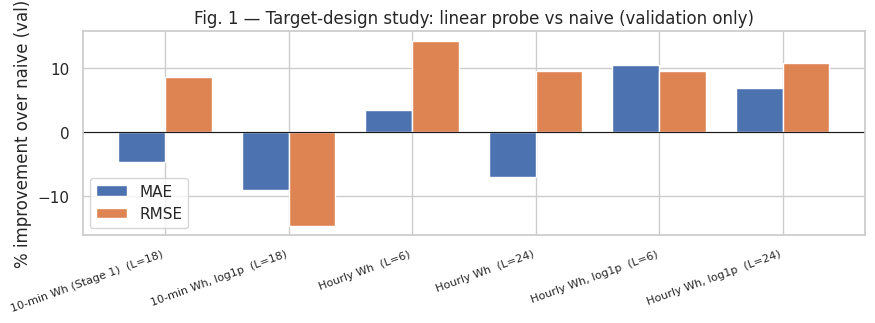

In [5]:
def probe(frame, L, season, log, label):
    y = frame["Appliances"].values.astype(float); n_ = len(y)
    a, b = int(TRAIN_FRAC*n_), int((TRAIN_FRAC+VAL_FRAC)*n_)
    Xo = frame.drop(columns=["date", "rv1", "rv2"]).values.astype(float)
    Xo = StandardScaler().fit(Xo[:a]).transform(Xo)
    ts_ = frame["date"]; hr_ = ts_.dt.hour + ts_.dt.minute/60; dw_ = ts_.dt.dayofweek
    Cc = np.column_stack([np.sin(2*np.pi*hr_/24), np.cos(2*np.pi*hr_/24), np.sin(2*np.pi*dw_/7), np.cos(2*np.pi*dw_/7), dw_ >= 5]).astype(float)
    yt = np.log1p(y) if log else y
    sc = StandardScaler().fit(yt[:a, None]); ys_ = sc.transform(yt[:, None]).ravel()
    T_ = np.arange(max(L, season), n_); tr_, va_ = T_[T_ < a], T_[(T_ >= a) & (T_ < b)]
    W = lambda idx: np.hstack([Xo[idx[:, None] - 1 - np.arange(L)].reshape(len(idx), -1), Cc[idx]])
    best = None
    for alpha in [1, 10, 100, 1000]:
        p = sc.inverse_transform(Ridge(alpha=alpha).fit(W(tr_), ys_[tr_]).predict(W(va_))[:, None]).ravel()
        p = np.expm1(p) if log else p
        m = metrics(y[va_], p)
        if best is None or m["MAE"] < best[0]["MAE"]: best = (m, alpha)
    nv = metrics(y[va_], y[va_ - 1])
    return {"Target design": label, "window": L, "log1p": log, "n_val": len(va_),
            "naive val MAE": nv["MAE"], "Ridge val MAE": best[0]["MAE"], "MAE impr. %": 100*(nv["MAE"]-best[0]["MAE"])/nv["MAE"],
            "naive val RMSE": nv["RMSE"], "Ridge val RMSE": best[0]["RMSE"], "RMSE impr. %": 100*(nv["RMSE"]-best[0]["RMSE"])/nv["RMSE"]}

study = pd.DataFrame([
    probe(df, 18, 144, False, "10-min Wh (Stage 1)"),
    probe(df, 18, 144, True,  "10-min Wh, log1p"),
    probe(dh, 6, 24, False,   "Hourly Wh"),
    probe(dh, 24, 24, False,  "Hourly Wh"),
    probe(dh, 6, 24, True,    "Hourly Wh, log1p"),
    probe(dh, 24, 24, True,   "Hourly Wh, log1p"),
])
study.to_csv("results_stage2/table1_target_study.csv", index=False)
print("Table 1 — Target-design probe (validation only; improvement of Ridge over naive)")
display(study.round(2))

fig, ax = plt.subplots(figsize=(9, 3.4))
lab = study["Target design"] + "  (L=" + study.window.astype(str) + ")"
x = np.arange(len(study)); w = 0.38
ax.bar(x - w/2, study["MAE impr. %"], w, label="MAE"); ax.bar(x + w/2, study["RMSE impr. %"], w, label="RMSE")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(lab, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("% improvement over naive (val)"); ax.set_title("Fig. 1 — Target-design study: linear probe vs naive (validation only)"); ax.legend()
plt.tight_layout(); plt.savefig("results_stage2/fig1_target_study.png", dpi=150); plt.show()

**Decision.** At 10-min resolution the probe loses to naive on MAE with or without a log transform, reproducing the Stage 1 finding. Hourly aggregation alone helps RMSE a lot but gives only a marginal MAE gain (+3% at 6 h, and a loss at 24 h). **Hourly + log1p** gives the largest MAE gain (≈10%) while keeping a ≈9–11% RMSE gain, i.e. a learned model clearly beats persistence on *both* metrics, so it is the Stage 2 target for every model. Short windows (6 h) beat 24 h for the linear probe, consistent with Stage 1. This choice was made on validation data only.

## 3. Chronological split (hourly)
Same 60/20/20 rule as Stage 1, applied to hourly rows. A sample is indexed by its **target hour** `i`; its input window ends at `i − HORIZON`. Training targets start at `MAXW + HORIZON − 1` so that every window length uses **identical** target instances.

Table 2 — Chronological split (hourly samples)


,split,first_target,last_target,n_samples,days,share_pct
0,train,2016-01-12 17:00:00,2016-04-02 21:00:00,1949,81.2,59.3
1,val,2016-04-02 22:00:00,2016-04-30 07:00:00,658,27.4,20.0
2,test,2016-04-30 08:00:00,2016-05-27 17:00:00,658,27.4,20.0


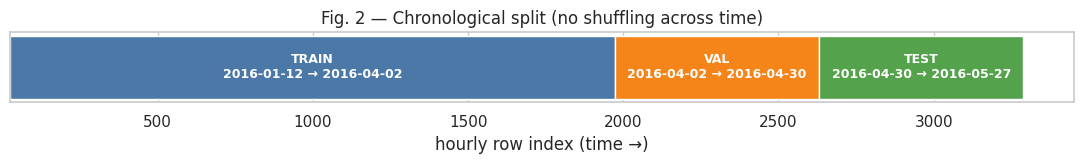

In [6]:
n_train = int(TRAIN_FRAC * n); n_val_end = int((TRAIN_FRAC + VAL_FRAC) * n)
splits = {"train": (MAXW + HORIZON - 1, n_train), "val": (n_train, n_val_end), "test": (n_val_end, n)}
split_table = pd.DataFrame([dict(split=k, first_target=dh.date[lo], last_target=dh.date[hi-1], n_samples=hi-lo,
                                 days=round((hi-lo)/24, 1), share_pct=round(100*(hi-lo)/n, 1)) for k, (lo, hi) in splits.items()])
print("Table 2 — Chronological split (hourly samples)"); display(split_table)

cols = {"train": "#4C78A8", "val": "#F58518", "test": "#54A24B"}
fig, ax = plt.subplots(figsize=(11, 1.8))
for k, (lo, hi) in splits.items():
    ax.barh(0, hi-lo, left=lo, color=cols[k], edgecolor="white")
    ax.text((lo+hi)/2, 0, f"{k.upper()}\n{dh.date[lo].date()} → {dh.date[hi-1].date()}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
ax.set_yticks([]); ax.set_xlabel("hourly row index (time →)"); ax.set_title("Fig. 2 — Chronological split (no shuffling across time)")
plt.tight_layout(); plt.savefig("results_stage2/fig2_split.png", dpi=150); plt.show()

## 4. Exploratory analysis of the hourly target
Figures are descriptive; anything that informs a decision (feature drop, transform) uses **training rows only**.

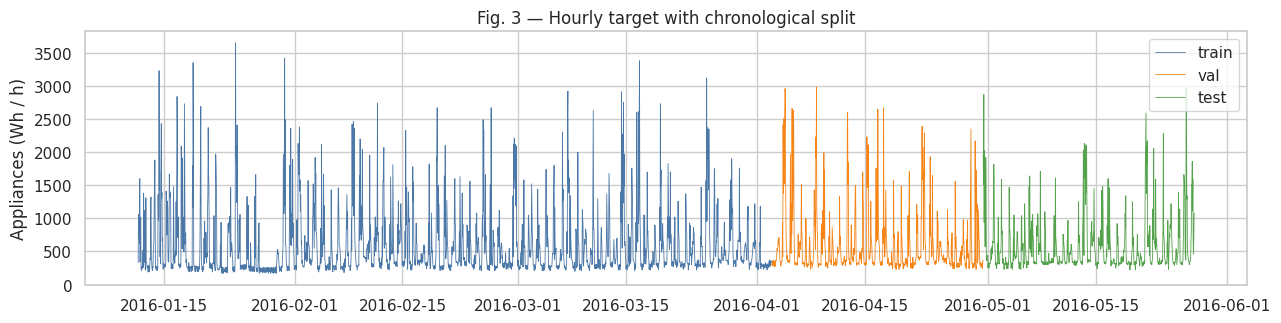

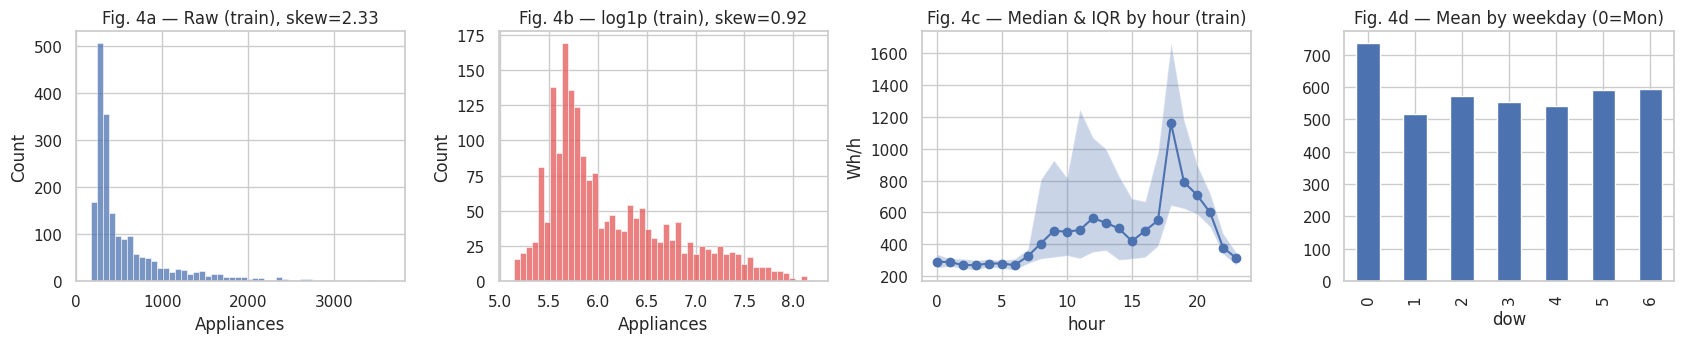

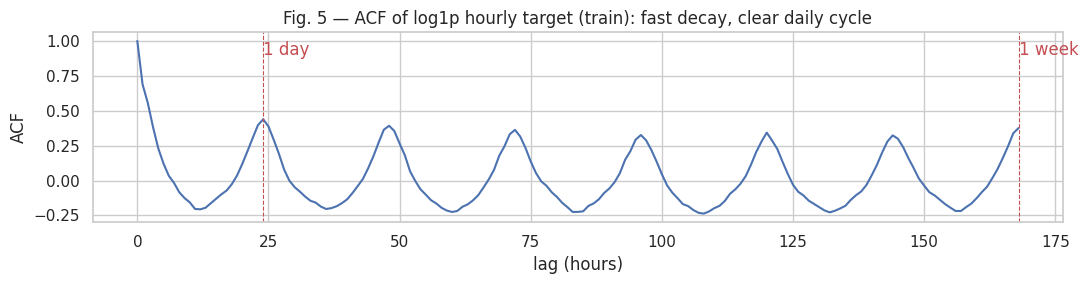

ACF at lags 1,2,3,6,12,24,48,168 h: [ 0.689  0.556  0.383  0.034 -0.206  0.439  0.393  0.376]


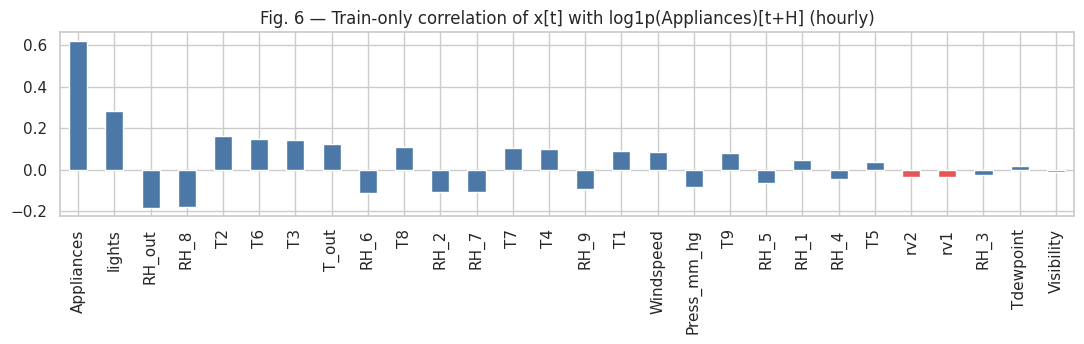

rv1/rv2 train corr: {'rv1': -0.0339, 'rv2': -0.0339} 
Dropped ['rv1', 'rv2']; kept 26 observed series


In [7]:
fig, ax = plt.subplots(figsize=(13, 3.4))
for k, (lo, hi) in {"train": (0, n_train), "val": (n_train, n_val_end), "test": (n_val_end, n)}.items():
    ax.plot(dh.date[lo:hi], dh.Appliances[lo:hi], lw=0.6, color=cols[k], label=k)
ax.set_ylabel("Appliances (Wh / h)"); ax.set_title("Fig. 3 — Hourly target with chronological split"); ax.legend()
plt.tight_layout(); plt.savefig("results_stage2/fig3_series.png", dpi=150); plt.show()

tr = dh.iloc[:n_train].copy(); tr["hour"] = tr.date.dt.hour; tr["dow"] = tr.date.dt.dayofweek
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
sns.histplot(tr.Appliances, bins=50, ax=axs[0]); axs[0].set_title(f"Fig. 4a — Raw (train), skew={tr.Appliances.skew():.2f}")
sns.histplot(np.log1p(tr.Appliances), bins=50, ax=axs[1], color="#E45756"); axs[1].set_title(f"Fig. 4b — log1p (train), skew={np.log1p(tr.Appliances).skew():.2f}")
q = tr.groupby("hour").Appliances.quantile([0.25, 0.5, 0.75]).unstack()
axs[2].fill_between(q.index, q[0.25], q[0.75], alpha=0.3); axs[2].plot(q.index, q[0.5], marker="o")
axs[2].set_title("Fig. 4c — Median & IQR by hour (train)"); axs[2].set_xlabel("hour"); axs[2].set_ylabel("Wh/h")
tr.groupby("dow").Appliances.mean().plot(kind="bar", ax=axs[3]); axs[3].set_title("Fig. 4d — Mean by weekday (0=Mon)")
plt.tight_layout(); plt.savefig("results_stage2/fig4_distribution_profiles.png", dpi=150); plt.show()

yl = np.log1p(dh.Appliances.values[:n_train]); yc = yl - yl.mean()
acf = np.array([1.0] + [np.dot(yc[:-k], yc[k:]) / np.dot(yc, yc) for k in range(1, WEEK + 1)])
fig, ax = plt.subplots(figsize=(11, 3)); ax.plot(acf)
for lag, lab_ in [(DAY, "1 day"), (WEEK, "1 week")]: ax.axvline(lag, color="r", ls="--", lw=0.8); ax.text(lag, 0.9, lab_, color="r")
ax.set_xlabel("lag (hours)"); ax.set_ylabel("ACF"); ax.set_title("Fig. 5 — ACF of log1p hourly target (train): fast decay, clear daily cycle")
plt.tight_layout(); plt.savefig("results_stage2/fig5_acf.png", dpi=150); plt.show()
print("ACF at lags 1,2,3,6,12,24,48,168 h:", np.round(acf[[1, 2, 3, 6, 12, 24, 48, 168]], 3))

# Feature selection on TRAIN ONLY: correlation of lagged x[t] with log target y[t+H]
feat_all = [c for c in dh.columns if c != "date"]
ylog = np.log1p(dh.Appliances.values)
corr = pd.Series({c: np.corrcoef(dh[c].values[:n_train-HORIZON], ylog[HORIZON:n_train])[0, 1] for c in feat_all}).sort_values(key=np.abs, ascending=False)
fig, ax = plt.subplots(figsize=(11, 3.6)); corr.plot(kind="bar", ax=ax, color=["#E45756" if c in ("rv1", "rv2") else "#4C78A8" for c in corr.index])
ax.set_title("Fig. 6 — Train-only correlation of x[t] with log1p(Appliances)[t+H] (hourly)")
plt.tight_layout(); plt.savefig("results_stage2/fig6_corr.png", dpi=150); plt.show()
DROP = ["rv1", "rv2"] + [c for c in feat_all if dh[c].values[:n_train].std() == 0]
feat_cols = [c for c in feat_all if c not in DROP]          # 'Appliances' first -> channel 0
print("rv1/rv2 train corr:", corr[["rv1", "rv2"]].round(4).to_dict(), f"\nDropped {DROP}; kept {len(feat_cols)} observed series")

## 4.1 Time-frequency structure of the target (training rows only)
**Questions.** (i) Which periods dominate the log hourly target? (ii) How strong are the daily and weekly seasonal components? (iii) Is the daily cycle stable over the training period? (iv) How much of the target's variability can a look-back window of length L even see, and are the Stage-A windows (6, 12, 24 h) consistent with the dominant period?

**Method.** All three analyses use `log1p(Appliances)` of the **training rows only**, so anything they decide (band edges used later for the error-by-frequency analysis) cannot leak test information.
1. *Periodogram* (Hann window, linear detrend, zero-padded) for resolution, and *Welch* (2-week segments, 50 % overlap) so that 168, 24, 12 and 8 h fall exactly on frequency bins. A peak counts as significant if it exceeds the 95 % level of an AR(1) red-noise null scaled to the observed mean power (χ² with Welch equivalent degrees of freedom).
2. *MSTL* (multiple-season STL, periods 24 and 168 h, robust). Strength of a component follows Wang, Smith & Hyndman: `F = max(0, 1 − Var(R) / Var(S + R))`.
3. *Spectrogram* (168 h Hann segments advanced by 24 h) to see whether 24 h power drifts, with a descriptive Spearman correlation against outdoor temperature (overlapping segments, so no p-value is quoted).
4. *Resolvable power*: the share of Welch power at periods ≤ L, per look-back L (a window of L hours cannot represent slower components except through its level).

Table 11 — Spectral peaks of log1p target at the declared candidate periods (train rows only, n=1973, 10 Welch segments, dof≈19, AR(1) phi=0.689)


,period_h,label,welch_bin,power,local_background,peak_to_background,red_noise_95_threshold,significant,variance_share_pct
0,168,168 h (weekly),2,0.0176,0.0108,1.6300,0.0325,False,6.8716
1,24,24 h (daily),14,0.1246,0.0082,15.1820,0.0221,True,32.1115
2,12,12 h,28,0.0317,0.0027,11.8025,0.0113,True,8.9608
3,8,8 h,42,0.0157,0.0021,7.3398,0.0063,True,4.3266


Strongest Welch peaks (period h, power, above 95 % red-noise level): [(24.0, 0.125, True), (12.0, 0.0317, True), (168.0, 0.0176, False), (8.0, 0.0157, True)]
Dominant period (largest Welch peak): 24.0 h


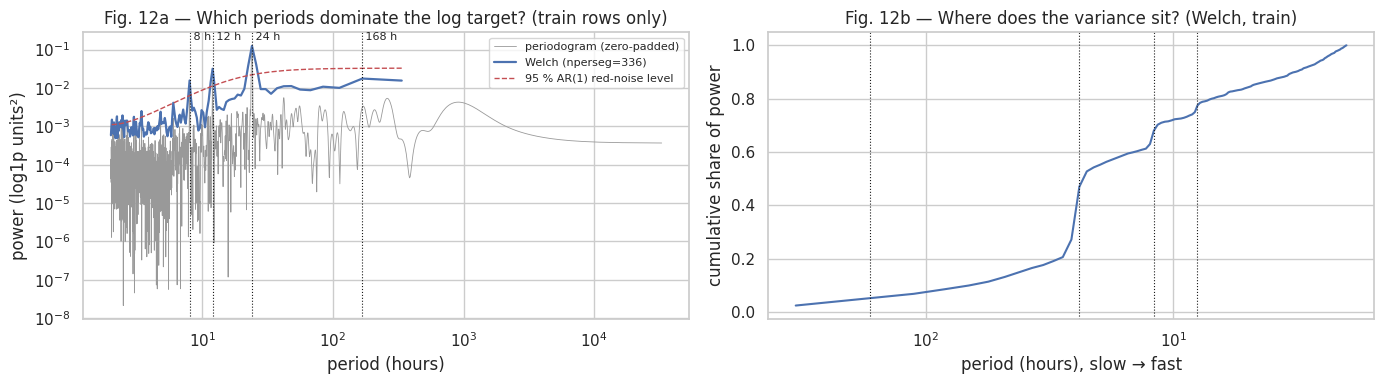

In [8]:
from scipy import signal, stats
yl_tr = np.log1p(dh["Appliances"].values[:n_train].astype(float)); yl_c = yl_tr - yl_tr.mean()          # TRAIN rows only
NPER = 336                                           # 2-week Welch segment: bins fall exactly on 168, 24, 12, 8 h
CAND = {168: "168 h (weekly)", 24: "24 h (daily)", 12: "12 h", 8: "8 h"}
f_p, P_p = signal.periodogram(yl_c, fs=1.0, window="hann", nfft=1 << 15, detrend="linear", scaling="spectrum")
f_w, P_w = signal.welch(yl_c, fs=1.0, window="hann", nperseg=NPER, noverlap=NPER // 2, detrend="linear", scaling="spectrum")
n_seg = (len(yl_c) - NPER) // (NPER // 2) + 1; dof = 1.89 * n_seg                   # Welch equivalent d.o.f. for 50 %-overlapped Hann segments
phi = np.corrcoef(yl_c[:-1], yl_c[1:])[0, 1]                                         # AR(1) red-noise null scaled to the observed mean power
S_red = (1 - phi**2) / (1 - 2 * phi * np.cos(2 * np.pi * f_w) + phi**2); S_red = S_red * P_w[1:].mean() / S_red[1:].mean()
thr95 = S_red * stats.chi2.ppf(0.95, dof) / dof

rows_sp = []
for per, nm in CAND.items():
    k = int(round(NPER / per)); bg = np.r_[P_w[max(k - 6, 1):k - 1], P_w[k + 2:k + 7]]
    rows_sp.append(dict(period_h=per, label=nm, welch_bin=k, power=P_w[k], local_background=np.median(bg), peak_to_background=P_w[k] / np.median(bg),
                        red_noise_95_threshold=thr95[k], significant=bool(P_w[k] > thr95[k]), variance_share_pct=100 * P_w[k - 1:k + 2].sum() / P_w[1:].sum()))
spec_tab = pd.DataFrame(rows_sp); spec_tab.to_csv(f"{OUT3}/table11_spectral_peaks_train.csv", index=False)
pk, _ = signal.find_peaks(P_w, prominence=0.05 * P_w[1:].max())
top_pk = sorted([(1 / f_w[i], P_w[i], bool(P_w[i] > thr95[i])) for i in pk if f_w[i] > 0], key=lambda t: -t[1])[:6]
DOM_PERIOD_H = top_pk[0][0] if top_pk else np.nan
print(f"Table 11 — Spectral peaks of log1p target at the declared candidate periods (train rows only, n={len(yl_c)}, {n_seg} Welch segments, dof≈{dof:.0f}, AR(1) phi={phi:.3f})")
display(spec_tab.round(4))
print("Strongest Welch peaks (period h, power, above 95 % red-noise level):", [(round(float(p), 1), float(f"{w:.3g}"), bool(s)) for p, w, s in top_pk])
print(f"Dominant period (largest Welch peak): {DOM_PERIOD_H:.1f} h")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
m_ = f_p > 0
axs[0].loglog(1 / f_p[m_], P_p[m_], lw=0.6, color="0.6", label="periodogram (zero-padded)")
axs[0].loglog(1 / f_w[1:], P_w[1:], lw=1.6, color="C0", label=f"Welch (nperseg={NPER})")
axs[0].loglog(1 / f_w[1:], thr95[1:], "r--", lw=1, label="95 % AR(1) red-noise level")
for per, nm in CAND.items(): axs[0].axvline(per, color="k", ls=":", lw=0.8); axs[0].text(per, axs[0].get_ylim()[1], f" {per} h", va="top", fontsize=8)
axs[0].set_xlabel("period (hours)"); axs[0].set_ylabel("power (log1p units²)"); axs[0].legend(fontsize=8)
axs[0].set_title("Fig. 12a — Which periods dominate the log target? (train rows only)")
per_ax = 1 / f_w[1:]; cum = np.cumsum(P_w[1:]) / P_w[1:].sum()                    # cumulative share from the slowest to the fastest component
axs[1].semilogx(per_ax, cum); axs[1].invert_xaxis()
for per in CAND: axs[1].axvline(per, color="k", ls=":", lw=0.8)
axs[1].set_xlabel("period (hours), slow → fast"); axs[1].set_ylabel("cumulative share of power"); axs[1].set_title("Fig. 12b — Where does the variance sit? (Welch, train)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig12_periodogram.png", dpi=150); plt.show()

Table 12 — MSTL of log1p target (train rows only, periods 24 and 168 h, robust); shares do not sum to 100 % because components covary


,component,variance_share_pct,strength
0,trend,2.868,0.054
1,seasonal 24 h (daily),43.517,0.379
2,seasonal 168 h (weekly),18.333,0.070
3,daily + weekly together,63.809,0.419
4,remainder,56.325,NaN


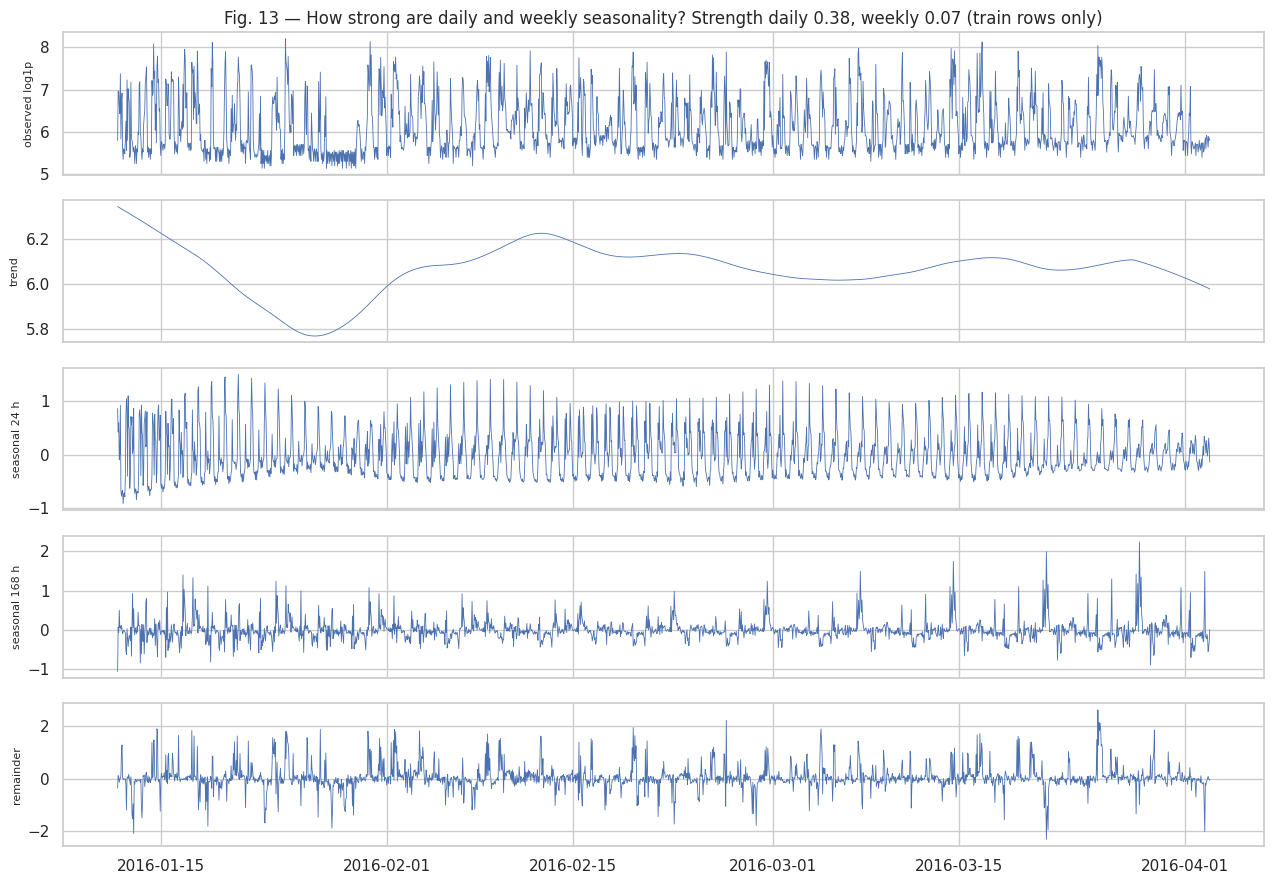

In [9]:
from statsmodels.tsa.seasonal import MSTL
idx_tr = pd.date_range(dh["date"].iloc[0], periods=n_train, freq="h")
assert (idx_tr == pd.DatetimeIndex(dh["date"].values[:n_train])).all()               # regular hourly index (verified in section 1)
mres = MSTL(pd.Series(yl_tr, index=idx_tr), periods=(DAY, WEEK), stl_kwargs=dict(robust=True)).fit()
S24, S168 = mres.seasonal.iloc[:, 0].values, mres.seasonal.iloc[:, 1].values; TR, RS = mres.trend.values, mres.resid.values
def strength(comp, resid=RS): return max(0.0, 1 - np.var(resid) / np.var(comp + resid))             # Wang-Smith-Hyndman strength in [0, 1]
tot_var = np.var(yl_tr)
decomp = pd.DataFrame([dict(component="trend", variance_share_pct=100 * np.var(TR) / tot_var, strength=strength(TR)),
                       dict(component="seasonal 24 h (daily)", variance_share_pct=100 * np.var(S24) / tot_var, strength=strength(S24)),
                       dict(component="seasonal 168 h (weekly)", variance_share_pct=100 * np.var(S168) / tot_var, strength=strength(S168)),
                       dict(component="daily + weekly together", variance_share_pct=100 * np.var(S24 + S168) / tot_var, strength=strength(S24 + S168)),
                       dict(component="remainder", variance_share_pct=100 * np.var(RS) / tot_var, strength=np.nan)])
decomp.to_csv(f"{OUT3}/table12_mstl_strength_train.csv", index=False)
STRENGTH_DAILY, STRENGTH_WEEKLY = float(decomp.strength.iloc[1]), float(decomp.strength.iloc[2])
print("Table 12 — MSTL of log1p target (train rows only, periods 24 and 168 h, robust); shares do not sum to 100 % because components covary")
display(decomp.round(3))
fig, axs = plt.subplots(5, 1, figsize=(13, 9), sharex=True)
for ax, (nm, v) in zip(axs, [("observed log1p", yl_tr), ("trend", TR), ("seasonal 24 h", S24), ("seasonal 168 h", S168), ("remainder", RS)]):
    ax.plot(idx_tr, v, lw=0.6); ax.set_ylabel(nm, fontsize=8)
axs[0].set_title(f"Fig. 13 — How strong are daily and weekly seasonality? Strength daily {STRENGTH_DAILY:.2f}, weekly {STRENGTH_WEEKLY:.2f} (train rows only)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig13_mstl.png", dpi=150); plt.show()

24 h power share per weekly segment (n=76 overlapping segments): mean 0.379, min 0.062, max 0.639; Spearman vs segment-mean outdoor temperature +0.27 (descriptive; overlapping segments)


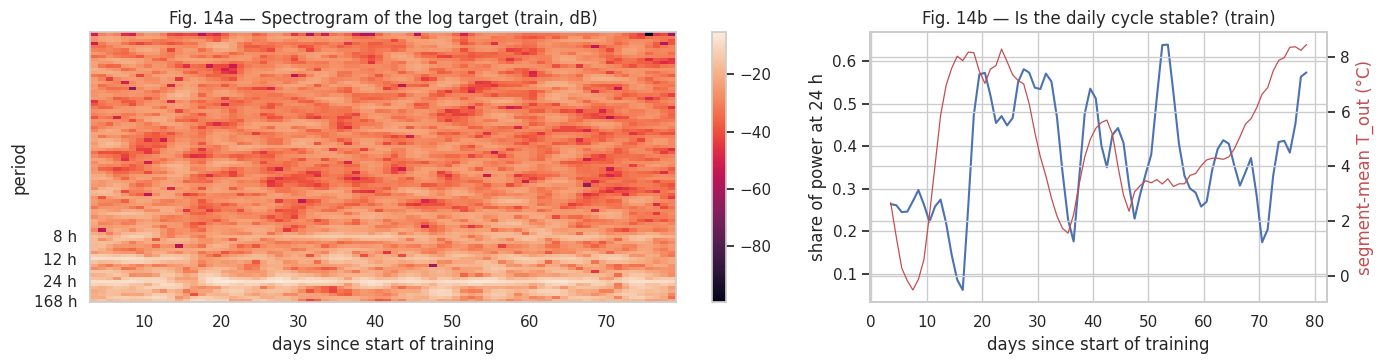

Table 13 — Share of target power a window of L hours can resolve, and whether the lag T-24 h lies inside the window (train spectrum)


,lookback_h,role,power_share_periods_le_L_pct,cycles_of_24h_in_window,ACF_at_lag_L,daily_lag_in_window_h1,daily_lag_in_window_h6,daily_lag_in_window_h12,daily_lag_in_window_h24
0,3,model window,9.046,0.125,0.383,False,False,False,True
1,6,model window,18.270,0.250,0.034,False,False,False,True
2,12,model window,37.005,0.500,-0.206,False,False,False,True
3,24,model window,72.770,1.000,0.439,True,True,True,True
4,48,sensitivity only,88.574,2.000,0.393,True,True,True,True


Significant candidate periods (train): [24, 12, 8];  frequency-band edges derived from them (train only): [17.0, 9.8] h  ->  bands ['period > 17 h', '10-17 h', 'period < 10 h']
Dominant period 24.0 h; model windows that contain at least one full cycle: [24]; windows that contain the T-24 h lag at h=1: [24]. Patch length is not applicable: the Transformer used here is not patch-based.
[timer] section 4.1 done: 1.2 min since the Stage-3 timer started


In [10]:
NSEG = 168                                                         # 1 week segments: 24, 12, 8 h fall on bins 7, 14, 21
f_s, t_s, Sxx = signal.spectrogram(yl_c, fs=1.0, window="hann", nperseg=NSEG, noverlap=NSEG - DAY, detrend="linear", scaling="spectrum", mode="psd")
k24 = int(round(NSEG / DAY)); share24 = Sxx[k24 - 1:k24 + 2].sum(0) / Sxx[1:].sum(0)       # share of segment power in the daily bin (±1 bin for Hann leakage)
seg_T = np.array([dh["T_out"].values[:n_train][int(c - NSEG / 2):int(c + NSEG / 2)].mean() for c in t_s])
rho_s = stats.spearmanr(share24, seg_T)[0]
print(f"24 h power share per weekly segment (n={len(share24)} overlapping segments): mean {share24.mean():.3f}, min {share24.min():.3f}, max {share24.max():.3f}; "
      f"Spearman vs segment-mean outdoor temperature {rho_s:+.2f} (descriptive; overlapping segments)")

fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
im = axs[0].pcolormesh(t_s / DAY, f_s[1:], 10 * np.log10(Sxx[1:] + 1e-12), shading="auto")
axs[0].set_yticks([1 / 168, 1 / 24, 1 / 12, 1 / 8]); axs[0].set_yticklabels(["168 h", "24 h", "12 h", "8 h"]); axs[0].set_xlabel("days since start of training")
axs[0].set_ylabel("period"); axs[0].set_title("Fig. 14a — Spectrogram of the log target (train, dB)"); plt.colorbar(im, ax=axs[0])
axs[1].plot(t_s / DAY, share24, label="24 h share"); ax2 = axs[1].twinx(); ax2.plot(t_s / DAY, seg_T, color="C3", lw=0.9, label="T_out"); ax2.set_ylabel("segment-mean T_out (°C)", color="C3")
axs[1].set_xlabel("days since start of training"); axs[1].set_ylabel("share of power at 24 h"); axs[1].set_title("Fig. 14b — Is the daily cycle stable? (train)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig14_spectrogram.png", dpi=150); plt.show()

# Link to model design: how much of the target's power can a window of L hours resolve, and does it contain the daily lag?
acf_tr = lambda k: float(np.dot(yl_c[:-k], yl_c[k:]) / np.dot(yl_c, yl_c))
L_SET = sorted(set(LOOKBACKS_B + [48]))                            # 48 h appears ONLY in the labelled sensitivity experiment of section 17
link = pd.DataFrame([dict(lookback_h=L, role="model window" if L in LOOKBACKS_B else "sensitivity only",
                          power_share_periods_le_L_pct=100 * P_w[f_w >= 1.0 / L].sum() / P_w[1:].sum(), cycles_of_24h_in_window=L / DAY, ACF_at_lag_L=acf_tr(L),
                          **{f"daily_lag_in_window_h{h}": bool(h <= DAY <= h + L - 1) for h in HORIZONS}) for L in L_SET])
link.to_csv(f"{OUT3}/table13_lookback_vs_spectrum.csv", index=False)
print("Table 13 — Share of target power a window of L hours can resolve, and whether the lag T-24 h lies inside the window (train spectrum)")
display(link.round(3))
sig_ = sorted([r["period_h"] for r in rows_sp if r["significant"]], reverse=True)
ref_ = sig_ if len(sig_) >= 2 else [168, 24, 12]                    # fall back to the declared candidates if fewer than two peaks are significant
BAND_EDGES_H = [float(np.sqrt(a * b)) for a, b in zip(ref_[:-1], ref_[1:])]          # geometric midpoints between adjacent significant periods (hours, descending)
_ub = [np.inf] + BAND_EDGES_H; _lb = BAND_EDGES_H + [0.0]
BAND_LABELS = [f"period > {_lb[0]:.0f} h"] + [f"{_lb[i]:.0f}-{_ub[i]:.0f} h" for i in range(1, len(_ub) - 1)] + [f"period < {_ub[-1]:.0f} h"]
print(f"Significant candidate periods (train): {sig_};  frequency-band edges derived from them (train only): {[round(e, 1) for e in BAND_EDGES_H]} h  ->  bands {BAND_LABELS}")
full_cycle = [L for L in LOOKBACKS_B if L >= DOM_PERIOD_H]
print(f"Dominant period {DOM_PERIOD_H:.1f} h; model windows that contain at least one full cycle: {full_cycle if full_cycle else 'none'}; "
      f"windows that contain the T-24 h lag at h=1: {[L for L in LOOKBACKS_B if 1 <= DAY <= 1 + L - 1]}. Patch length is not applicable: the Transformer used here is not patch-based.")
tick("section 4.1 done")

## 5. Preprocessing and window shapes
* **Energy inputs** (`Appliances`, `lights`) get the same fixed `log1p` transform as the target (no fitting involved).
* **Imputer** (median) and **StandardScaler** are fitted on training rows only. The target scaler is fitted on `log1p(Appliances)` of training rows only.
* **Inverse transform for metrics:** `ŷ_Wh = expm1(scaler⁻¹(ŷ))`, clipped at 0. All metrics are in Wh/h.
* **Calendar features** (hour sin/cos, weekday sin/cos, weekend flag) are deterministic and future-known; the target-hour calendar vector is appended to every step.
* **Window:** inputs = hourly rows `[t−L+1 … t]`, target = `Appliances[t+H]`. Because hourly bin `t` covers `t:00–t:50`, the last input reading is strictly before the target hour starts.
* **Channel order for the 2D CNN.** A 2D kernel slides across the feature axis, so neighbouring columns should be related. CNN2D therefore reorders the `C` channels by sensor group (energy → indoor temperatures T1–T9 → indoor humidities RH_1–RH_9 → outdoor/weather → calendar → target-time calendar) inside the model; the stored window tensors are unchanged, so every model still sees identical data.

In [11]:
LOG_COLS = [c for c in ENERGY if c in feat_cols]
Xraw = dh[feat_cols].copy()
for c in LOG_COLS: Xraw[c] = np.log1p(Xraw[c])
imputer = SimpleImputer(strategy="median").fit(Xraw.iloc[:n_train])
X_imp = imputer.transform(Xraw)
x_scaler = StandardScaler().fit(X_imp[:n_train]); X_s = x_scaler.transform(X_imp)
y_raw = dh["Appliances"].values.astype(np.float64)
y_scaler = StandardScaler().fit(np.log1p(y_raw[:n_train]).reshape(-1, 1))
y_s = y_scaler.transform(np.log1p(y_raw).reshape(-1, 1)).ravel()
inv = lambda p: np.clip(np.expm1(y_scaler.inverse_transform(np.asarray(p, dtype=np.float64).reshape(-1, 1)).ravel()), 0, None)
assert np.allclose(inv(y_s), y_raw), "target transform must invert exactly"

ts = dh["date"]; hr = ts.dt.hour
cal = np.column_stack([np.sin(2*np.pi*hr/24), np.cos(2*np.pi*hr/24),
                       np.sin(2*np.pi*ts.dt.dayofweek/7), np.cos(2*np.pi*ts.dt.dayofweek/7),
                       (ts.dt.dayofweek >= 5).astype(float)]).astype(np.float32)
A = np.hstack([X_s, cal]).astype(np.float32)
C = A.shape[1] + cal.shape[1]
print(f"per-step channels: {len(feat_cols)} observed + {cal.shape[1]} calendar + {cal.shape[1]} target-time calendar = {C}")

# Channel grouping used by CNN2D (so that 2D kernels see related sensors side by side)
CH_NAMES = list(feat_cols) + [f"cal_{j}" for j in range(cal.shape[1])] + [f"tcal_{j}" for j in range(cal.shape[1])]
assert len(CH_NAMES) == C
def _grp(nm):
    if nm in ENERGY: return 0
    if nm.startswith("T") and nm[1:].isdigit(): return 1
    if nm.startswith("RH_") and nm[3:].isdigit(): return 2
    if nm.startswith("cal_"): return 4
    if nm.startswith("tcal_"): return 5
    return 3
CH_ORDER = sorted(range(C), key=lambda i: (_grp(CH_NAMES[i]), i))
print("CNN2D channel order:", [CH_NAMES[i] for i in CH_ORDER])

def split_bounds(h):
    """Target-index bounds per split for horizon h. val/test target hours are IDENTICAL for every h;
    only the first training target moves (MAXW + h - 1) so that every window length still has identical targets."""
    return {"train": (MAXW + h - 1, n_train), "val": (n_train, n_val_end), "test": (n_val_end, n)}
assert split_bounds(HORIZON) == splits, "primary horizon must reproduce the Stage-2 split exactly"

_cache = {}
def make_windows(L, lo, hi, h=HORIZON, A_=None):
    """Window [e-L+1 .. e] with e = T-h predicts y[T]. A_ lets robustness tests pass a perturbed copy of the (n, 31) feature array."""
    A_ = A if A_ is None else A_
    T = np.arange(lo, hi); e = T - h
    assert (e < T).all() and (e - L + 1 >= 0).all()           # leakage guard: inputs strictly precede target
    idx = e[:, None] + np.arange(-L + 1, 1)[None, :]
    X = np.concatenate([A_[idx], np.repeat(cal[T][:, None, :], L, axis=1)], axis=2).astype(np.float32)   # + target-time calendar of hour T
    return X, y_s[T].astype(np.float32), T
def get_data(L, h=HORIZON):
    if (L, h) not in _cache:
        _cache[(L, h)] = {k: dict(zip(("X", "y", "T"), make_windows(L, lo, hi, h))) for k, (lo, hi) in split_bounds(h).items()}
    return _cache[(L, h)]

shape_rows = []
for L in sorted(set(LOOKBACKS + LOOKBACKS_B)):
    d = get_data(L)
    shape_rows.append(dict(window_h=L, **{f"{k}_X": tuple(d[k]["X"].shape) for k in d}, **{f"{k}_y": tuple(d[k]["y"].shape) for k in d},
                           mlp_in=f"({L*C},)", cnn1d_tcn_in=f"(C={C}, L={L})", cnn2d_in=f"(1, L={L}, C={C})", rnn_in=f"(L={L}, C={C})"))
print("Table 3 — Window shapes"); display(pd.DataFrame(shape_rows))
L0 = LOOKBACKS[0]
assert all(np.array_equal(get_data(L)["test"]["T"], get_data(L0)["test"]["T"]) for L in set(LOOKBACKS + LOOKBACKS_B))
assert get_data(L0)["train"]["T"].max() < get_data(L0)["val"]["T"].min() < get_data(L0)["test"]["T"].min()
print("Identical target instances across windows ✔ ; splits strictly ordered ✔")

per-step channels: 26 observed + 5 calendar + 5 target-time calendar = 36
CNN2D channel order: ['Appliances', 'lights', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_5', 'RH_6', 'RH_7', 'RH_8', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'cal_0', 'cal_1', 'cal_2', 'cal_3', 'cal_4', 'tcal_0', 'tcal_1', 'tcal_2', 'tcal_3', 'tcal_4']
Table 3 — Window shapes


,window_h,train_X,val_X,test_X,train_y,val_y,test_y,mlp_in,cnn1d_tcn_in,cnn2d_in,rnn_in
0,3,"(1949, 3, 36)","(658, 3, 36)","(658, 3, 36)","(1949,)","(658,)","(658,)","(108,)","(C=36, L=3)","(1, L=3, C=36)","(L=3, C=36)"
1,6,"(1949, 6, 36)","(658, 6, 36)","(658, 6, 36)","(1949,)","(658,)","(658,)","(216,)","(C=36, L=6)","(1, L=6, C=36)","(L=6, C=36)"
2,12,"(1949, 12, 36)","(658, 12, 36)","(658, 12, 36)","(1949,)","(658,)","(658,)","(432,)","(C=36, L=12)","(1, L=12, C=36)","(L=12, C=36)"
3,24,"(1949, 24, 36)","(658, 24, 36)","(658, 24, 36)","(1949,)","(658,)","(658,)","(864,)","(C=36, L=24)","(1, L=24, C=36)","(L=24, C=36)"


Identical target instances across windows ✔ ; splits strictly ordered ✔


## 5.1 Multi-step targets (direct strategy) and leakage guards
**Question.** Can the same windowed pipeline predict y[t+h] for h ∈ {1, 6, 12, 24} h without any leakage, while keeping the Stage-2 numbers at h = 1 exactly reproducible?

**Method — direct strategy.** One model per horizon h. A sample is indexed by its **target hour** T. Its input window is the L hours `[e−L+1 … e]` with `e = T − h`, plus the calendar vector **of hour T** appended at every step (known in advance). Hourly bin `e` covers `e:00–e:50`, so the last observed reading ends 60·h − 50 minutes before the target bin starts, and the h−1 hours in between are never observed by the model.
* **Split bounds.** `val` and `test` target hours are the same 658 hours for every h (comparable across horizons). Only the first training target moves: `MAXW + h − 1`, so every window length still shares identical targets *within* a horizon, and h = 1 reproduces Stage 2 exactly. Training therefore loses `h − 1` samples at horizon h relative to h = 1.
* **Why direct, not recursive.** A recursive forecaster feeds its own predictions back as the target channel and compounds the damping of peaks that Stage 2 found; a direct model has no feedback loop. A multi-output head would share one model across horizons but would also share early stopping across horizons with different noise levels.
* **`inv()` does not depend on h** (it only inverts the fitted target scaler), so it is unchanged.

The cell below *asserts* (for every h, every split and every window length): the exact timestamp gap between last input hour and target is h; no input row reaches beyond its own split; train/val/test targets are strictly ordered; the target-time calendar equals an independent recomputation from timestamps; and the last value of the target channel equals the naive forecast input.

Table 14 — Multi-step windows and leakage audit (windows [3, 6, 12, 24], splits train/val/test; every assertion above passed for every horizon)


,horizon_h,n_train,n_val,n_test,train_samples_lost_vs_h1,first_train_target,first_test_target,last_test_target,gap_last_input_end_to_target_start_min,all_assertions_passed
0,1,1949,658,658,0,2016-01-12 17:00:00,2016-04-30 08:00:00,2016-05-27 17:00:00,10,True
1,6,1944,658,658,5,2016-01-12 22:00:00,2016-04-30 08:00:00,2016-05-27 17:00:00,310,True
2,12,1938,658,658,11,2016-01-13 04:00:00,2016-04-30 08:00:00,2016-05-27 17:00:00,670,True
3,24,1926,658,658,23,2016-01-13 16:00:00,2016-04-30 08:00:00,2016-05-27 17:00:00,1390,True


Worked example (h=6, L=24, first test sample): target hour 2016-04-30 08:00:00  |  last input hour 2016-04-30 02:00:00 (bin ends 2016-04-30 02:50:00)  |  first input hour 2016-04-29 03:00:00  |  target-time calendar hour-of-day = 8, input-time = 2


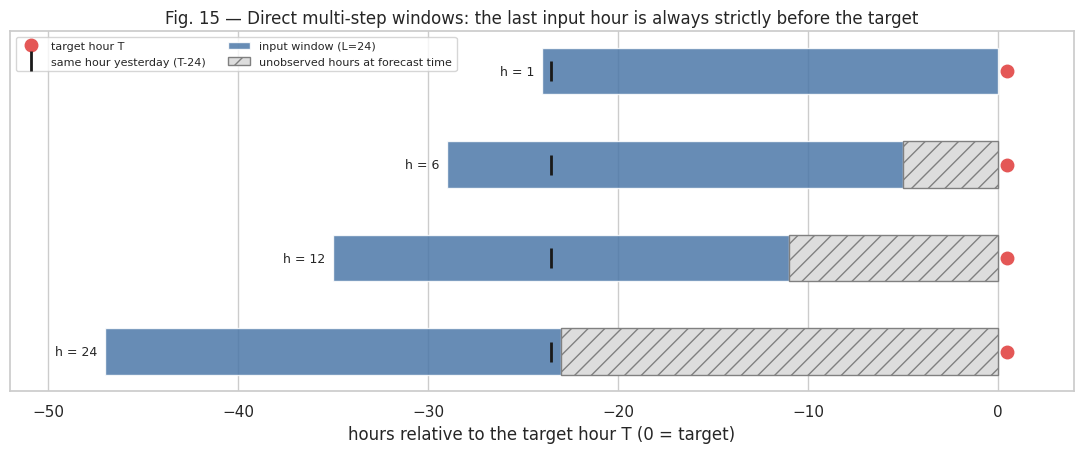

[timer] section 5.1 done: 1.2 min since the Stage-3 timer started


In [12]:
def cal_from_ts(tsx):
    '''Independent recomputation of the 5 deterministic calendar features from timestamps (does not use the cached `cal`).'''
    hr_, dw_ = tsx.dt.hour, tsx.dt.dayofweek
    return np.column_stack([np.sin(2*np.pi*hr_/24), np.cos(2*np.pi*hr_/24), np.sin(2*np.pi*dw_/7), np.cos(2*np.pi*dw_/7), (dw_ >= 5).astype(float)]).astype(np.float32)
def hour_from_sincos(s, c): return (np.arctan2(s, c) * 24 / (2 * np.pi)) % 24

n_obs, n_cal = len(feat_cols), cal.shape[1]; ic0, tc0 = n_obs, n_obs + n_cal                 # column offsets: input-time calendar, target-time calendar
assert C == tc0 + n_cal and np.allclose(A[:, 0], y_s, atol=1e-4), "channel 0 must be the (scaled log1p) target series"
tsd = dh["date"]; LS = sorted(set(LOOKBACKS + LOOKBACKS_B)); audit_rows = []
T_ref = {k: get_data(LS[0], HORIZON)[k]["T"] for k in ("val", "test")}
for h in HORIZONS:
    sb = split_bounds(h); lens = {}
    for L in LS:
        d = get_data(L, h)
        for k, (lo, hi) in sb.items():
            T, X = d[k]["T"], d[k]["X"]; e = T - h
            assert np.array_equal(T, np.arange(lo, hi)) and X.shape == (hi - lo, L, C)
            assert (e < T).all() and (e - L + 1 >= 0).all()                                                      # last input hour strictly before the target hour
            assert ((tsd.values[T] - tsd.values[e]) == np.timedelta64(h, "h")).all()                             # exact h-hour gap between last input hour and target hour
            assert e.max() <= hi - 1 - h and (k != "train" or e.max() < n_train)                                  # inputs never come from after the sample's own forecast origin
            assert np.allclose(d[k]["y"], y_s[T]) and np.allclose(X[:, -1, 0], y_s[e], atol=1e-4)               # target is y[T]; last target-channel value is y[T-h] (naive input)
            assert np.allclose(X[:, :, tc0:], cal_from_ts(tsd.iloc[T])[:, None, :], atol=1e-6)                   # target-time calendar = calendar of hour T at every step
            assert np.allclose(X[:, -1, ic0:tc0], cal_from_ts(tsd.iloc[e]), atol=1e-6)                           # input-time calendar at the last step = calendar of hour T-h
            dd = (hour_from_sincos(X[:, -1, tc0], X[:, -1, tc0 + 1]) - hour_from_sincos(X[:, -1, ic0], X[:, -1, ic0 + 1]) - h) % 24
            assert (np.minimum(dd, 24 - dd) < 1e-3).all()                                                         # the two calendars differ by exactly h hours of the day
            if k != "train": assert np.array_equal(T, T_ref[k])                                                  # val/test targets identical for every horizon and window
            lens[k] = hi - lo
    Tn = get_data(LS[0], h)
    assert Tn["train"]["T"].max() < Tn["val"]["T"].min() < Tn["test"]["T"].min()                                 # train < val < test (chronological, no overlap of targets)
    lo_t, hi_t = sb["train"]
    audit_rows.append(dict(horizon_h=h, n_train=lens["train"], n_val=lens["val"], n_test=lens["test"], train_samples_lost_vs_h1=split_bounds(1)["train"][1] - split_bounds(1)["train"][0] - lens["train"],
                           first_train_target=str(tsd[lo_t]), first_test_target=str(tsd[sb["test"][0]]), last_test_target=str(tsd[sb["test"][1] - 1]),
                           gap_last_input_end_to_target_start_min=60 * h - 50, all_assertions_passed=True))
aud = pd.DataFrame(audit_rows); aud.to_csv(f"{OUT3}/table14_horizon_audit.csv", index=False)
print(f"Table 14 — Multi-step windows and leakage audit (windows {LS}, splits train/val/test; every assertion above passed for every horizon)"); display(aud)
Te = get_data(24, 6)["test"]["T"][0]
print(f"Worked example (h=6, L=24, first test sample): target hour {tsd[Te]}  |  last input hour {tsd[Te-6]} (bin ends {tsd[Te-6] + pd.Timedelta(minutes=50)})  |  "
      f"first input hour {tsd[Te-6-23]}  |  target-time calendar hour-of-day = {tsd[Te].hour}, input-time = {tsd[Te-6].hour}")

fig, ax = plt.subplots(figsize=(11, 0.85 * len(HORIZONS) + 1.3))
for j, h in enumerate(HORIZONS):
    y0 = len(HORIZONS) - 1 - j
    ax.barh(y0, 24, left=-(h + 23), height=0.5, color="#4C78A8", alpha=0.85, label="input window (L=24)" if j == 0 else None)
    if h > 1: ax.barh(y0, h - 1, left=-(h - 1), height=0.5, color="#DDDDDD", hatch="//", edgecolor="0.5", label="unobserved hours at forecast time" if h == HORIZONS[1] else None)
    ax.plot(0.5, y0, "o", color="#E45756", ms=9, label="target hour T" if j == 0 else None)
    ax.plot(-23.5, y0, "k|", ms=14, mew=2, label="same hour yesterday (T-24)" if j == 0 else None)
    ax.text(-(h + 23) - 0.4, y0, f"h = {h}", ha="right", va="center", fontsize=9)
ax.set_yticks([]); ax.set_xlabel("hours relative to the target hour T (0 = target)"); ax.set_xlim(-52, 4); ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.set_title("Fig. 15 — Direct multi-step windows: the last input hour is always strictly before the target"); plt.tight_layout(); plt.savefig(f"{OUT3}/fig15_horizon_timeline.png", dpi=150); plt.show()
tick("section 5.1 done")

## 6. Metrics and baselines
Metrics: MAE, RMSE, sMAPE, R² in **Wh/h** on the same target indices. *Improvement* = `(baseline − model) / baseline × 100` against the **naive last-value** forecast (primary baseline, as in Stage 1).

Baselines: naive (last hour), seasonal naive (same hour yesterday), hour-of-week median (fitted on train), and Ridge on the same flattened windows and log target (window and α chosen on validation).

In [13]:
T_val, T_test = get_data(L0)["val"]["T"], get_data(L0)["test"]["T"]
Y_val, Y_test = y_raw[T_val], y_raw[T_test]
how = (ts.dt.dayofweek * 24 + ts.dt.hour).values
how_med = pd.Series(y_raw[:n_train]).groupby(how[:n_train]).median()
base = {"Naive (last hour)":             {s: y_raw[T - HORIZON] for s, T in [("val", T_val), ("test", T_test)]},
        "Seasonal naive (t-24 h)":       {s: y_raw[T - DAY]     for s, T in [("val", T_val), ("test", T_test)]},
        "Hour-of-week median (train)":   {s: how_med.reindex(how[T]).fillna(np.median(y_raw[:n_train])).values for s, T in [("val", T_val), ("test", T_test)]}}
NAIVE = "Naive (last hour)"
BASE_VAL = metrics(Y_val, base[NAIVE]["val"])
for k, v in base.items():
    print(f"{k:30s} val MAE={metrics(Y_val, v['val'])['MAE']:.2f}  val RMSE={metrics(Y_val, v['val'])['RMSE']:.2f}")

ridge_rows, best_ridge = [], None
for L in sorted(set(LOOKBACKS + LOOKBACKS_B)):
    d = get_data(L); Xtr, Xva = d["train"]["X"].reshape(len(d["train"]["X"]), -1), d["val"]["X"].reshape(len(d["val"]["X"]), -1)
    for a in [1, 10, 100, 1000, 10000]:
        t0 = time.time(); m = Ridge(alpha=a).fit(Xtr, d["train"]["y"]); tt = time.time() - t0
        mv = metrics(Y_val, inv(m.predict(Xva))); ridge_rows.append(dict(window=L, alpha=a, val_MAE=mv["MAE"], val_RMSE=mv["RMSE"], fit_s=tt))
        if best_ridge is None or mv["MAE"] < best_ridge[0]: best_ridge = (mv["MAE"], L, a)
display(pd.DataFrame(ridge_rows).sort_values("val_MAE").head(5).round(3))
_, R_L, R_ALPHA = best_ridge
d = get_data(R_L); t0 = time.time()
ridge = Ridge(alpha=R_ALPHA).fit(d["train"]["X"].reshape(len(d["train"]["X"]), -1), d["train"]["y"]); ridge_time = time.time() - t0
ridge_pred = {s: inv(ridge.predict(d[s]["X"].reshape(len(d[s]["X"]), -1))) for s in ("val", "test")}
ridge_params = ridge.coef_.size + 1
print(f"Ridge chosen on val: window={R_L} h, alpha={R_ALPHA}, params={ridge_params}, val MAE={metrics(Y_val, ridge_pred['val'])['MAE']:.2f}")

Naive (last hour)              val MAE=229.04  val RMSE=433.31
Seasonal naive (t-24 h)        val MAE=306.61  val RMSE=576.39
Hour-of-week median (train)    val MAE=264.77  val RMSE=489.66


,window,alpha,val_MAE,val_RMSE,fit_s
2,3,100,198.419,383.836,0.003
7,6,100,199.559,385.634,0.005
1,3,10,201.521,380.224,0.003
12,12,100,201.542,381.897,0.034
11,12,10,201.840,373.356,0.036


Ridge chosen on val: window=3 h, alpha=100, params=109, val MAE=198.42


## 6.1 Baselines for every horizon (validation only at this point)
**Question.** What must a learned model beat at h = 1, 6, 12 and 24 h, and where do the baselines coincide?

**Method.** For target hour T and horizon h, everything a baseline may use is data up to hour `T − h`:
* **Naive** = `y[T − h]`, the last observed hour (for h = 1 this is the Stage-2 naive).
* **Seasonal naive** = `y[T − 24]`, same hour yesterday; available at forecast time only if h ≤ 24 (asserted). **At h = 24 it is identical to naive**; the cell checks this numerically.
* **Hour-of-week median** (fitted on train) depends only on the target hour, so it is the same forecast at every horizon.
* **Ridge** on the flattened window and log target, with window ∈ {3, 6, 12, 24} and α chosen on **validation** separately for each horizon (same grid as Stage 2; h = 1 must reproduce the Stage-2 choice).

Only validation is evaluated here; test-set baselines are computed in §10.3 with the same functions.

Table 15 — Baselines by horizon (VALIDATION only; Ridge window/alpha re-selected on validation for each horizon)


horizon_h,1,6,12,24
baseline,,,,
Hour-of-week median (train),264.77,264.77,264.77,264.77
Naive (last hour),229.04,428.01,471.37,306.61
Ridge (log target),198.42,243.42,245.58,243.63
Seasonal naive (t-24 h),306.61,306.61,306.61,306.61


,horizon_h,config,val_MAE,val_MAE_impr_vs_naive_pct
3,1,"L=3, alpha=100",198.42,13.37
7,6,"L=24, alpha=10000",243.42,43.13
11,12,"L=24, alpha=10000",245.58,47.90
15,24,"L=3, alpha=1000",243.63,20.54


Baselines that coincide: naive == seasonal naive at horizons [24] (expected: [24]); the hour-of-week median is horizon-independent by construction (val MAE 264.77 at every h).


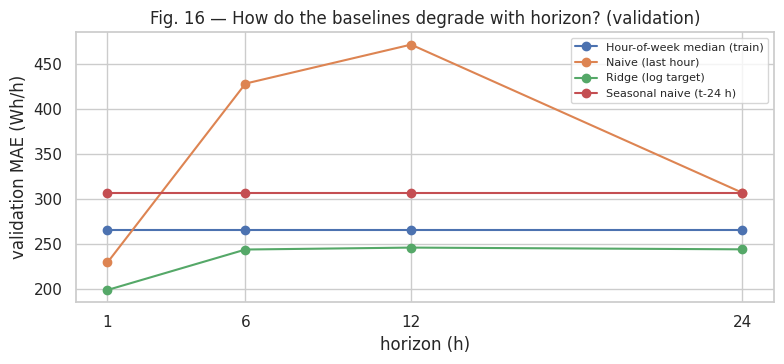

[timer] section 6.1 done: 1.3 min since the Stage-3 timer started


In [14]:
def make_base(h, T):
    '''Baseline forecasts of y[T] issued with data up to hour T-h (inclusive).'''
    assert h <= DAY and (T - DAY >= 0).all() and (T - h >= 0).all()
    return {NAIVE: y_raw[T - h],
            "Seasonal naive (t-24 h)": y_raw[T - DAY],
            "Hour-of-week median (train)": how_med.reindex(how[T]).fillna(np.median(y_raw[:n_train])).values}

RIDGE_H = {}
for h in HORIZONS:
    best_ = None
    for L in sorted(set(LOOKBACKS + LOOKBACKS_B)):
        d = get_data(L, h); Xtr_ = d["train"]["X"].reshape(len(d["train"]["X"]), -1); Xva_ = d["val"]["X"].reshape(len(d["val"]["X"]), -1)
        for a in [1, 10, 100, 1000, 10000]:
            mv_ = metrics(Y_val, inv(Ridge(alpha=a).fit(Xtr_, d["train"]["y"]).predict(Xva_)))
            if best_ is None or mv_["MAE"] < best_[0]: best_ = (mv_["MAE"], L, a)
    _, Lh, ah = best_; d = get_data(Lh, h); Xtr_ = d["train"]["X"].reshape(len(d["train"]["X"]), -1); t0 = time.time()
    mdl = Ridge(alpha=ah).fit(Xtr_, d["train"]["y"])
    RIDGE_H[h] = dict(L=Lh, alpha=ah, model=mdl, fit_s=time.time() - t0, params=mdl.coef_.size + 1)
def ridge_predict(h, split):
    '''Ridge forecast in Wh/h for split in {'val','test'} at horizon h.'''
    r = RIDGE_H[h]; X_ = get_data(r["L"], h)[split]["X"]; return inv(r["model"].predict(X_.reshape(len(X_), -1)))
assert (RIDGE_H[1]["L"], RIDGE_H[1]["alpha"]) == (R_L, R_ALPHA), "h=1 Ridge must reproduce the Stage-2 choice"
assert np.allclose(ridge_predict(1, "val"), ridge_pred["val"])
assert np.array_equal(make_base(1, T_val)[NAIVE], base[NAIVE]["val"]) and np.array_equal(make_base(1, T_val)["Seasonal naive (t-24 h)"], base["Seasonal naive (t-24 h)"]["val"])

rows_bh = []
for h in HORIZONS:
    bv = make_base(h, T_val); bv["Ridge (log target)"] = ridge_predict(h, "val"); nv_ = metrics(Y_val, bv[NAIVE])
    for nm, p in bv.items():
        mm = metrics(Y_val, p)
        rows_bh.append(dict(horizon_h=h, baseline=nm, config=(f"L={RIDGE_H[h]['L']}, alpha={RIDGE_H[h]['alpha']}" if nm.startswith("Ridge") else "—"),
                            val_MAE=mm["MAE"], val_RMSE=mm["RMSE"], val_MAE_impr_vs_naive_pct=100 * (nv_["MAE"] - mm["MAE"]) / nv_["MAE"]))
base_h = pd.DataFrame(rows_bh); base_h.to_csv(f"{OUT3}/table15_baselines_by_horizon_val.csv", index=False)
COINCIDE = [h for h in HORIZONS if np.array_equal(make_base(h, T_val)[NAIVE], make_base(h, T_val)["Seasonal naive (t-24 h)"])]
print("Table 15 — Baselines by horizon (VALIDATION only; Ridge window/alpha re-selected on validation for each horizon)")
display(base_h.pivot(index="baseline", columns="horizon_h", values="val_MAE").round(2))
display(base_h[base_h.baseline.str.startswith("Ridge")][["horizon_h", "config", "val_MAE", "val_MAE_impr_vs_naive_pct"]].round(2))
print(f"Baselines that coincide: naive == seasonal naive at horizons {COINCIDE} (expected: [24]); the hour-of-week median is horizon-independent by construction "
      f"(val MAE {metrics(Y_val, make_base(HORIZON, T_val)['Hour-of-week median (train)'])['MAE']:.2f} at every h).")

fig, ax = plt.subplots(figsize=(8, 3.8))
for nm, g in base_h.groupby("baseline"): ax.plot(g.horizon_h, g.val_MAE, marker="o", label=nm)
ax.set_xticks(HORIZONS); ax.set_xlabel("horizon (h)"); ax.set_ylabel("validation MAE (Wh/h)"); ax.legend(fontsize=8)
ax.set_title("Fig. 16 — How do the baselines degrade with horizon? (validation)"); plt.tight_layout(); plt.savefig(f"{OUT3}/fig16_baselines_by_horizon.png", dpi=150); plt.show()
tick("section 6.1 done")

## 7. Models
All eight networks receive **the same window tensor** `(L, C)` and share loss, optimiser (Adam), batch size, gradient clipping, max epochs and early-stopping rule (patience on validation loss, best weights restored).

| Model | How it reads the window | Output |
|---|---|---|
| **MLP** | flattens `L×C` | 2 hidden layers (h, h/2), ReLU, dropout |
| **CNN1D** | `C` channels × `L` steps; 1D convolution over time, 2 conv blocks + max/adaptive pooling (Stage 1 design) | dense head |
| **CNN2D** | one-channel image `(1, L, C)` with channels grouped by sensor type; 2D convolution over time × feature, 2 conv blocks + max/adaptive pooling | dense head |
| **RNN** (Elman, tanh) | steps through `L` hours; 1–3 stacked layers | last hidden state → dropout → linear |
| **LSTM** | as RNN, with input/forget/output gates and a cell state | same head |
| **GRU** | as RNN, with update/reset gates | same head |
| **TCN** | causal dilated residual blocks (dilations 1, 2, 4, …); depth chosen automatically so the receptive field ≥ `L` | last time step → linear |
| **TFT** (Stage 3, section 7.1) | Temporal-Fusion-Transformer-style: variable selection → LSTM encoder/decoder → self-attention over the window → gated skip connections; target-time calendar enters as the known-future input | decoder token → linear |

The TCN receptive field with kernel `k` and `n` blocks (two convs each) is `RF = 1 + 2(k−1)(2ⁿ−1)`.

In [15]:
class MLP(nn.Module):
    def __init__(s, L, C, hidden, dropout):
        super().__init__()
        s.net = nn.Sequential(nn.Flatten(), nn.Linear(L*C, hidden), nn.ReLU(), nn.Dropout(dropout),
                              nn.Linear(hidden, max(hidden//2, 1)), nn.ReLU(), nn.Dropout(dropout), nn.Linear(max(hidden//2, 1), 1))
    def forward(s, x): return s.net(x).squeeze(-1)

class CNN1D(nn.Module):
    def __init__(s, L, C, filters, kernel, dropout):
        super().__init__()
        p = kernel // 2
        s.conv = nn.Sequential(nn.Conv1d(C, filters, kernel, padding=p), nn.ReLU(), nn.MaxPool1d(2, ceil_mode=True),
                               nn.Conv1d(filters, 2*filters, kernel, padding=p), nn.ReLU(), nn.AdaptiveAvgPool1d(4))
        s.head = nn.Sequential(nn.Flatten(), nn.Linear(2*filters*4, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(s, x): return s.head(s.conv(x.transpose(1, 2))).squeeze(-1)        # (B,L,C) -> (B,C,L)

class CNN2D(nn.Module):
    """Window as a one-channel image (1, L, C); channels are reordered by sensor group so 2D kernels see related sensors."""
    def __init__(s, L, C, filters, kernel, dropout):
        super().__init__()
        s.register_buffer("order", torch.tensor(CH_ORDER, dtype=torch.long))
        p = kernel // 2
        s.conv = nn.Sequential(nn.Conv2d(1, filters, kernel, padding=p), nn.ReLU(), nn.MaxPool2d(2, ceil_mode=True),
                               nn.Conv2d(filters, 2*filters, kernel, padding=p), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 4)))
        s.head = nn.Sequential(nn.Flatten(), nn.Linear(2*filters*16, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(s, x): return s.head(s.conv(x[:, :, s.order].unsqueeze(1))).squeeze(-1)    # (B,L,C) -> (B,1,L,C)

class RNNNet(nn.Module):
    """Shared wrapper for the recurrent family: cell in {'RNN','LSTM','GRU'}."""
    def __init__(s, C, cell, hidden, layers, dropout):
        super().__init__()
        R = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        s.rnn = R(C, hidden, num_layers=layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)
        s.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(s, x):
        out, _ = s.rnn(x)                       # out: (B, L, hidden)
        return s.head(out[:, -1]).squeeze(-1)   # last time step summarises the window

class Chomp1d(nn.Module):
    def __init__(s, p): super().__init__(); s.p = p
    def forward(s, x): return x[:, :, :-s.p].contiguous() if s.p > 0 else x   # drop right padding -> causal

class TemporalBlock(nn.Module):
    def __init__(s, cin, cout, k, dil, dropout):
        super().__init__()
        p = (k - 1) * dil
        s.net = nn.Sequential(nn.Conv1d(cin, cout, k, padding=p, dilation=dil), Chomp1d(p), nn.ReLU(), nn.Dropout(dropout),
                              nn.Conv1d(cout, cout, k, padding=p, dilation=dil), Chomp1d(p), nn.ReLU(), nn.Dropout(dropout))
        s.down = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()
        s.relu = nn.ReLU()
    def forward(s, x): return s.relu(s.net(x) + s.down(x))

def tcn_levels(L, k):
    lv = 1
    while 1 + 2*(k - 1)*(2**lv - 1) < L: lv += 1
    return lv

class TCN(nn.Module):
    def __init__(s, L, C, channels, kernel, dropout):
        super().__init__()
        s.levels = tcn_levels(L, kernel); s.rf = 1 + 2*(kernel - 1)*(2**s.levels - 1)
        blocks, cin = [], C
        for i in range(s.levels): blocks.append(TemporalBlock(cin, channels, kernel, 2**i, dropout)); cin = channels
        s.tcn = nn.Sequential(*blocks); s.head = nn.Linear(channels, 1)
    def forward(s, x): return s.head(s.tcn(x.transpose(1, 2))[:, :, -1]).squeeze(-1)

FAMILIES = ["MLP", "CNN1D", "CNN2D", "RNN", "LSTM", "GRU", "TCN", "TFT"]    # TFT = Stage-3 Transformer (class TFTLite, defined in section 7.1)
def full_cfg(cfg): return {**DEFAULTS, **cfg}
def build(name, cfg):
    c = full_cfg(cfg); L, dp = c["window"], c["dropout"]
    if name == "MLP":   m = MLP(L, C, c["hidden"], dp)
    elif name == "CNN1D": m = CNN1D(L, C, c["filters"], c["kernel"], dp)
    elif name == "CNN2D": m = CNN2D(L, C, c["filters"], c["kernel"], dp)
    elif name in ("RNN", "LSTM", "GRU"): m = RNNNet(C, name, c["hidden"], c["layers"], dp)
    elif name == "TCN": m = TCN(L, C, c["channels"], c["kernel"], dp)
    elif name == "TFT": m = TFTLite(L, C, c["d_model"], c["layers"], c["heads"], dp, n_fut=cal.shape[1])
    else: raise ValueError(name)
    return m.to(DEVICE)
n_params = lambda m: sum(p.numel() for p in m.parameters())

for L in (3, 6, 12, 24):    # receptive-field check for the TCN
    print(f"TCN L={L:2d}: " + ", ".join(f"k={k} -> {tcn_levels(L, k)} blocks, RF={1+2*(k-1)*(2**tcn_levels(L, k)-1)}" for k in (2, 3, 4)))

# quick shape test of every architecture on a dummy batch
for name, cfg in [("MLP", dict(window=6, hidden=64)), ("CNN1D", dict(window=3, filters=8, kernel=5)), ("CNN2D", dict(window=3, filters=8, kernel=3)), ("CNN2D", dict(window=24, filters=8, kernel=5)), ("RNN", dict(window=6, hidden=16, layers=2)),
                  ("LSTM", dict(window=24, hidden=16, layers=1)), ("GRU", dict(window=12, hidden=16, layers=3)), ("TCN", dict(window=24, channels=8, kernel=2))]:
    with torch.no_grad(): out = build(name, cfg).eval()(torch.zeros(5, cfg["window"], C, device=DEVICE))
    assert out.shape == (5,), (name, out.shape)
print("All architectures produce (batch,) outputs ✔")

TCN L= 3: k=2 -> 1 blocks, RF=3, k=3 -> 1 blocks, RF=5, k=4 -> 1 blocks, RF=7
TCN L= 6: k=2 -> 2 blocks, RF=7, k=3 -> 2 blocks, RF=13, k=4 -> 1 blocks, RF=7
TCN L=12: k=2 -> 3 blocks, RF=15, k=3 -> 2 blocks, RF=13, k=4 -> 2 blocks, RF=19
TCN L=24: k=2 -> 4 blocks, RF=31, k=3 -> 3 blocks, RF=29, k=4 -> 3 blocks, RF=43
All architectures produce (batch,) outputs ✔


In [16]:
_tens = {}
def tens(L, split, h=HORIZON):
    if (L, split, h) not in _tens:
        d = get_data(L, h)[split]; _tens[(L, split, h)] = (torch.from_numpy(d["X"]).to(DEVICE), torch.from_numpy(d["y"]).to(DEVICE))
    return _tens[(L, split, h)]

@torch.no_grad()
def predict_scaled(model, X, bs=2048):
    model.eval(); return torch.cat([model(X[i:i+bs]) for i in range(0, len(X), bs)]).cpu().numpy()

class Pinball(nn.Module):
    """Quantile (pinball) loss for quantile level tau; tau = 0.5 is half the L1 loss."""
    def __init__(s, tau): super().__init__(); s.tau = float(tau)
    def forward(s, pred, y):
        d = y - pred; return torch.mean(torch.maximum(s.tau * d, (s.tau - 1.0) * d))
def make_loss(name):
    if name == "L1": return nn.L1Loss()
    if name == "Huber": return nn.HuberLoss(delta=1.0)
    if name.startswith("Q"): return Pinball(float(name[1:]))      # e.g. "Q0.9" = pinball loss at tau = 0.9 (Stage 3: asymmetric loss and quantile heads)
    raise ValueError(name)

def fit(model, cfg, seed, h=HORIZON, data=None):
    """data=(Xtr, ytr, Xva, yva) overrides the default tensors (used by the Stage-3 temperature-shift test); h selects the horizon."""
    c = full_cfg(cfg); L = c["window"]
    set_seed(seed)
    if data is None: (Xtr, ytr), (Xva, yva) = tens(L, "train", h), tens(L, "val", h)
    else: Xtr, ytr, Xva, yva = data
    opt = torch.optim.Adam(model.parameters(), lr=c["lr"], weight_decay=c["wd"]); lossf = make_loss(c["loss"])
    g = torch.Generator().manual_seed(seed)
    best, bad, best_ep, hist = float("inf"), 0, 0, []
    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    sync(); t0 = time.time()
    for ep in range(MAX_EPOCHS):
        model.train(); perm = torch.randperm(len(Xtr), generator=g); tl = 0.0
        for i in range(0, len(perm), c["batch"]):
            idx = perm[i:i+c["batch"]].to(DEVICE); opt.zero_grad()
            loss = lossf(model(Xtr[idx]), ytr[idx]); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step(); tl += loss.item() * len(idx)
        with torch.no_grad(): vl = lossf(torch.from_numpy(predict_scaled(model, Xva)).to(DEVICE), yva).item()
        hist.append((tl / len(perm), vl))
        if vl < best - 1e-5: best, bad, best_ep, best_state = vl, 0, ep + 1, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    sync(); train_time = time.time() - t0
    model.load_state_dict(best_state)
    return train_time, hist, best_ep

@torch.no_grad()
def infer_time(model, X):
    """ms per sample: batched throughput over X, and single-sample latency (batch=1, 100 calls)."""
    model.eval(); predict_scaled(model, X[:256]); sync()
    t0 = time.time()
    for _ in range(5): predict_scaled(model, X)
    sync(); batched = (time.time() - t0) / 5 / len(X) * 1e3
    for i in range(10): model(X[i:i+1])
    sync(); t0 = time.time()
    for i in range(100): model(X[i:i+1])
    sync(); single = (time.time() - t0) / 100 * 1e3
    return batched, single

def run_config(name, cfg, seed, h=HORIZON, data=None):
    set_seed(seed); m = build(name, cfg); L = cfg["window"]
    tt, hist, best_ep = fit(m, cfg, seed, h, data)
    pv = inv(predict_scaled(m, tens(L, "val", h)[0]))
    return dict(model=m, hist=hist, train_time=tt, epochs=len(hist), best_epoch=best_ep, params=n_params(m), seed=seed,
                val=metrics(Y_val, pv), val_pred=pv)

## 7.1 Transformer forecaster: candidate scoring and implementation (`TFT`)
**Question.** Which Transformer-type model suits ≈1,950 training windows, look-backs ≤ 24 h, horizons of 1–24 h, a 36-channel window and a calendar that is known in advance?

**Method.** Five candidates (Informer, Autoformer, FEDformer, PatchTST, TFT) are scored 1–5 on six criteria *before any run* (Table 16; scores are ordinal judgements, not measurements; equal weights). The best total is implemented in pure PyTorch as `TFTLite` and enters Stage A with the same budget as every other family (12 configurations × 2 seeds, equal to Table 4).

**Architecture (`TFTLite`, same `(B, L, C)` input as every model).**
1. *Variable selection*: each of the 31 past channels (26 observed series + current calendar) gets a learned scalar embedding; a gated residual network (GRN) over the raw channels produces softmax weights per time step; the weighted embeddings pass through a GRN. The 5 target-time calendar channels (the last 5 columns, constant along the window) are the **known-future input** and use their own selection layer.
2. *Sequence processing*: LSTM encoder over the L past steps; its final state initialises an LSTM decoder that processes the single known-future token; gated skip connections to the selection outputs.
3. *Attention*: the decoder token (query) attends over all L encoder steps plus itself, with a learned position (lag) embedding, using multi-head self-attention. The attention weights are the quantity analysed in §14.
4. *Output*: gate-add-norm, a GRN and a linear layer give one value per window (standardised log target), trained with the same loss, optimiser and early stopping as every other family.

**Regularisation and size (why modest).** 1 LSTM layer, 1 attention block, width 16 or 32, 4 heads; dropout 0.2 (identical to all other families); weight decay 1e-4 (10× the default but still mild). With ~1,950 training windows a larger Transformer would mostly fit noise; the parameter counts (Table 17) show it stays in the same range as the Stage-2 models. Stage B (if TFT is the finalist) may vary width ∈ {16, 32, 48, 64}, LSTM layers ∈ {1, 2} and heads ∈ {2, 4} under the same parsimony rule as before.

**Not tuned to win.** TFT is selected only if it has the lowest Stage-A validation MAE; if it does not win it gets no Stage-B budget and is reported with its Stage-A configuration.

In [17]:
# Table 16 — declared scoring of Transformer candidates (ordinal judgement, 1 = unfavourable, 5 = favourable; equal weights). Not a measurement.
crit = ["small data (~1,950 windows)", "horizons 1-24 h", "known-future covariates", "multivariate input", "pure-PyTorch size/risk", "Colab compute"]
score = {"Informer":   [2, 2, 2, 4, 2, 3], "Autoformer": [2, 2, 2, 4, 2, 3], "FEDformer": [2, 2, 2, 4, 1, 3],
         "PatchTST":   [3, 4, 1, 2, 5, 4], "TFT":        [4, 5, 5, 5, 3, 4]}
why = {"Informer": "ProbSparse attention + distilling + generative decoder target 96-720-step horizons and long contexts; nothing to sparsify at L<=24",
       "Autoformer": "auto-correlation and series decomposition need long histories; timestamps only as covariates",
       "FEDformer": "frequency-enhanced blocks with random mode selection need long sequences; largest implementation risk",
       "PatchTST": "channel-independent, no native future covariates; L<=24 gives only a handful of patches; mixing channels needs a custom head",
       "TFT": "native known-future inputs, variable selection over 31 channels, LSTM inductive bias (the Stage-2 winner was recurrent), multi-horizon design"}
cand = pd.DataFrame(score, index=crit).T; cand["total"] = cand.sum(axis=1); cand["rationale"] = pd.Series(why)
cand = cand.sort_values("total", ascending=False); cand.to_csv(f"{OUT3}/table16_transformer_candidates.csv")
print("Table 16 — Transformer candidate scoring (declared before running; ordinal judgements)"); display(cand)
CHOSEN_TF = cand.index[0]; assert CHOSEN_TF == "TFT", "the implemented family must be the top-scoring candidate"
print(f"Chosen: {CHOSEN_TF} (total {int(cand.total.iloc[0])}); runner-up {cand.index[1]} ({int(cand.total.iloc[1])}) is not implemented (channel independence, no known-future inputs). One Transformer family is implemented.")

Table 16 — Transformer candidate scoring (declared before running; ordinal judgements)


,"small data (~1,950 windows)",horizons 1-24 h,known-future covariates,multivariate input,pure-PyTorch size/risk,Colab compute,total,rationale
TFT,4,5,5,5,3,4,26,"native known-future inputs, variable selection..."
PatchTST,3,4,1,2,5,4,19,"channel-independent, no native future covariat..."
Informer,2,2,2,4,2,3,15,ProbSparse attention + distilling + generative...
Autoformer,2,2,2,4,2,3,15,auto-correlation and series decomposition need...
FEDformer,2,2,2,4,1,3,14,frequency-enhanced blocks with random mode sel...


Chosen: TFT (total 26); runner-up PatchTST (19) is not implemented (channel independence, no known-future inputs). One Transformer family is implemented.


In [18]:
import torch.nn.functional as F

class GateAddNorm(nn.Module):
    '''GLU-gated projection, residual add, LayerNorm (as in the Temporal Fusion Transformer).'''
    def __init__(s, d, dropout):
        super().__init__(); s.drop = nn.Dropout(dropout); s.glu = nn.Linear(d, 2 * d); s.norm = nn.LayerNorm(d)
    def forward(s, x, skip): return s.norm(skip + F.glu(s.glu(s.drop(x)), dim=-1))

class GRN(nn.Module):
    '''Gated residual network: ELU MLP with a GLU gate, residual connection and LayerNorm.'''
    def __init__(s, d_in, d_hid, d_out, dropout):
        super().__init__()
        s.fc1, s.fc2 = nn.Linear(d_in, d_hid), nn.Linear(d_hid, d_out); s.gate = GateAddNorm(d_out, dropout)
        s.skip = nn.Linear(d_in, d_out) if d_in != d_out else nn.Identity()
    def forward(s, x): return s.gate(s.fc2(F.elu(s.fc1(x))), s.skip(x))

class VSN(nn.Module):
    '''Variable selection: scalar embedding per variable, softmax weights from a GRN over the raw variables, weighted sum, GRN.'''
    def __init__(s, n_var, d, dropout):
        super().__init__()
        s.emb_w = nn.Parameter(torch.randn(n_var, d) * 0.5); s.emb_b = nn.Parameter(torch.zeros(n_var, d))
        s.sel = GRN(n_var, d, n_var, dropout); s.post = GRN(d, d, d, dropout)
    def forward(s, x):                                   # x: (B, T, n_var)
        w = torch.softmax(s.sel(x), dim=-1)              # (B, T, n_var) variable weights
        e = x.unsqueeze(-1) * s.emb_w + s.emb_b          # (B, T, n_var, d)
        return s.post((w.unsqueeze(-1) * e).sum(-2)), w

class TFTLite(nn.Module):
    '''Temporal-Fusion-Transformer-style forecaster for ONE target hour. Window (B, L, C): the first C-n_fut channels are past inputs,
    the last n_fut channels are the target-time calendar (known in advance, constant along the window; read at the last step).'''
    def __init__(s, L, C, d_model, layers, heads, dropout, n_fut=5):
        super().__init__()
        assert d_model % heads == 0
        s.L, s.C, s.n_fut = L, C, n_fut
        s.vsn_past, s.vsn_fut = VSN(C - n_fut, d_model, dropout), VSN(n_fut, d_model, dropout)
        lstm_dp = dropout if layers > 1 else 0.0
        s.enc = nn.LSTM(d_model, d_model, num_layers=layers, batch_first=True, dropout=lstm_dp)
        s.dec = nn.LSTM(d_model, d_model, num_layers=layers, batch_first=True, dropout=lstm_dp)
        s.gate1 = GateAddNorm(d_model, dropout)
        s.pos = nn.Parameter(torch.zeros(1, L + 1, d_model))                      # learned lag/position embedding (L encoder steps + decoder token)
        s.attn = nn.MultiheadAttention(d_model, heads, dropout=dropout, batch_first=True)
        s.gate2, s.grn, s.gate3 = GateAddNorm(d_model, dropout), GRN(d_model, d_model, d_model, dropout), GateAddNorm(d_model, dropout)
        s.out = nn.Linear(d_model, 1)
        s.keep_attn, s.last_attn, s.last_vsn = False, None, None                    # set keep_attn=True to store attention / selection weights
    def forward(s, x):
        past, fut = x[:, :, :s.C - s.n_fut], x[:, -1:, s.C - s.n_fut:]
        pe, wp = s.vsn_past(past); fe, _ = s.vsn_fut(fut)                          # (B,L,d), (B,1,d)
        enc, state = s.enc(pe); dec, _ = s.dec(fe, state)                          # decoder starts from the encoder state
        seq = s.gate1(torch.cat([enc, dec], 1), torch.cat([pe, fe], 1))            # (B, L+1, d)
        kv = seq + s.pos
        a, w = s.attn(kv[:, -1:], kv, kv, need_weights=s.keep_attn, average_attn_weights=True)    # query = decoder (target-hour) token
        if s.keep_attn: s.last_attn, s.last_vsn = w.detach(), wp.detach()           # w: (B, 1, L+1), position j < L is encoder step j (oldest first)
        z = s.gate3(s.grn(s.gate2(a, seq[:, -1:])), seq[:, -1:])
        return s.out(z).reshape(x.shape[0])

# --- tests: shape, gradients, use of the known-future channels, attention normalisation
for L_, d_, ly_, hd_ in [(6, 16, 1, 4), (24, 32, 1, 4), (12, 48, 2, 2)]:
    m_ = build("TFT", dict(window=L_, d_model=d_, layers=ly_, heads=hd_)).eval(); xb = torch.randn(5, L_, C, device=DEVICE)
    assert m_(xb).shape == (5,)
    m_.train(); loss_ = m_(xb).pow(2).mean(); loss_.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in m_.parameters()), "every parameter must receive a finite gradient"
m_ = build("TFT", dict(window=24, d_model=16, layers=1, heads=4)).eval(); xb = torch.randn(4, 24, C, device=DEVICE); m_.keep_attn = True
with torch.no_grad():
    y0 = m_(xb); aw = m_.last_attn.clone(); xf = xb.clone(); xf[:, :, -5:] += 1.0; y1 = m_(xf)                       # change only the target-time calendar
    xp = xb.clone(); xp[:, 0, :C - 5] += 1.0; y2 = m_(xp)                                                               # change only the oldest past step
assert aw.shape == (4, 1, 25) and torch.allclose(aw.sum(-1), torch.ones(4, 1, device=DEVICE), atol=1e-5)
assert (y0 - y1).abs().max() > 1e-6 and (y0 - y2).abs().max() > 1e-6, "model must react to both known-future and past inputs"
print("TFTLite tests passed ✔  (shape, finite gradients, known-future channels used, past steps used, attention rows sum to 1)")

rows_p = []
for d_, ly_, hd_ in itertools.product([16, 32, 48, 64], [1, 2], [4]):
    rows_p.append(dict(d_model=d_, lstm_layers=ly_, heads=hd_, window=24, params=n_params(build("TFT", dict(window=24, d_model=d_, layers=ly_, heads=hd_))),
                       used_in="Stage A and B" if (d_ in (16, 32) and ly_ == 1) else "Stage B only"))
ptab = pd.DataFrame(rows_p); ptab.to_csv(f"{OUT3}/table17_tft_params.csv", index=False)
print(f"Table 17 — TFTLite parameter counts (window 24; the window only adds (L+1)*d_model position weights). Stage 2 for reference: MLP 16,001; RNN finalist 14,913; Ridge {ridge_params}. Training windows: {len(get_data(6)['train']['y'])}")
display(ptab)

# measured cost of one TFT fit (replaces the 7.5 s assumption of the budget cell): time 10 training steps and extrapolate to ~40 epochs
mt_ = build("TFT", dict(window=24, d_model=32, layers=1, heads=4)); opt_ = torch.optim.Adam(mt_.parameters(), lr=1e-3)
Xb_, yb_ = tens(24, "train")[0][:64], tens(24, "train")[1][:64]; sync(); t0 = time.time()
for _ in range(10): opt_.zero_grad(); F.l1_loss(mt_(Xb_), yb_).backward(); opt_.step()
sync(); sec_step = (time.time() - t0) / 10; steps_ep = int(np.ceil(len(get_data(24)["train"]["y"]) / 64))
TFT_SEC_PER_FIT_EST = sec_step * steps_ep * 40
print(f"Measured on {DEVICE}: {sec_step*1e3:.1f} ms per training step (L=24, d=32, batch 64) -> ~{sec_step*steps_ep:.2f} s/epoch, ~{TFT_SEC_PER_FIT_EST:.0f} s per fit at 40 epochs "
      f"(budget cell assumed {SEC_PER_FIT} s for an average family)")
tick("section 7.1 done")

TFTLite tests passed ✔  (shape, finite gradients, known-future channels used, past steps used, attention rows sum to 1)
Table 17 — TFTLite parameter counts (window 24; the window only adds (L+1)*d_model position weights). Stage 2 for reference: MLP 16,001; RNN finalist 14,913; Ridge 109. Training windows: 1949


,d_model,lstm_layers,heads,window,params,used_in
0,16,1,4,24,15433,Stage A and B
1,16,2,4,24,19785,Stage B only
2,32,1,4,24,48169,Stage A and B
3,32,2,4,24,65065,Stage B only
4,48,1,4,24,100361,Stage B only
5,48,2,4,24,137993,Stage B only
6,64,1,4,24,172009,Stage B only
7,64,2,4,24,238569,Stage B only


Measured on cuda: 81.4 ms per training step (L=24, d=32, batch 64) -> ~2.52 s/epoch, ~101 s per fit at 40 epochs (budget cell assumed 7.5 s for an average family)
[timer] section 7.1 done: 1.7 min since the Stage-3 timer started


## 8. Hyperparameter-optimisation protocol (declared before any results)

| Item | Stage A — controlled screening (all eight families) | Stage B — finalist HPO (one family) |
|---|---|---|
| Purpose | Fair comparison; pick the most promising family | Tune the selected family responsibly |
| Search method | Full grid | Random search, fixed RNG seed 42; trial 0 = Stage-A best config (anchor) |
| Search space | window ∈ {6, 12, 24} h × 2–4 architecture settings (Table 4 below); dropout 0.2, batch 64, wd 1e-5, L1 loss fixed | window ∈ {3, 6, 12, 24}; dropout ∈ {0, 0.1, 0.2, 0.3}; lr ~ log-U[1e-4, 3e-3]; batch ∈ {32, 64, 128}; wd ∈ {0, 1e-5, 1e-4}; loss ∈ {L1, Huber}; architecture ranges per family |
| Budget | **12 configurations per family** × 2 seeds (equal for every family) | **30 trials** × 2 seeds |
| Objective | mean validation MAE (Wh/h) over seeds {42, 43} | same |
| Per-run stopping | early stopping, patience 15 epochs on validation loss (max 150), best weights restored | same |
| Search stopping rule | grid exhausted | budget exhausted (no adaptive early termination of the search) |
| Selection rule | family whose best configuration has the lowest objective | among trials within one seed-std of the best objective, choose the **fewest parameters** (parsimony); test set never consulted |

Stage B gives extra tuning only to the finalist family. To keep the final comparison honest, the final table reports that family **both** with its Stage-A configuration and its tuned configuration whenever Stage B selects a different configuration; if the parsimony rule returns the Stage-A anchor, the family appears once. Ridge is shown beside the neural families in the selection evidence as a reference, but the finalist is still the best *neural* family.

In [19]:
if QUICK:
    GRID_A = {"MLP": dict(window=[12], hidden=[64]), "CNN1D": dict(window=[12], filters=[16], kernel=[3]), "CNN2D": dict(window=[12], filters=[8], kernel=[3]),
              "RNN": dict(window=[12], hidden=[32], layers=[1]), "LSTM": dict(window=[12], hidden=[32], layers=[1]),
              "GRU": dict(window=[12], hidden=[32], layers=[1]), "TCN": dict(window=[12], channels=[16], kernel=[3]),
              "TFT": dict(window=[12], d_model=[16], layers=[1], heads=[4], wd=[1e-4])}
else:
    GRID_A = {"MLP":  dict(window=LOOKBACKS, hidden=[64, 128], lr=[1e-3, 3e-4]),
              "CNN1D": dict(window=LOOKBACKS, filters=[16, 32], kernel=[3], lr=[1e-3, 3e-4]),
              "CNN2D": dict(window=LOOKBACKS, filters=[8, 16], kernel=[3], lr=[1e-3, 3e-4]),
              "RNN":  dict(window=LOOKBACKS, hidden=[32, 64], layers=[1, 2]),
              "LSTM": dict(window=LOOKBACKS, hidden=[32, 64], layers=[1, 2]),
              "GRU":  dict(window=LOOKBACKS, hidden=[32, 64], layers=[1, 2]),
              "TCN":  dict(window=LOOKBACKS, channels=[16, 32], kernel=[2, 3]),
              # Stage 3: 3 windows x 2 widths x 2 learning rates = 12 configs (same budget as every family); 1 LSTM layer + 1 attention block, 4 heads,
              # dropout 0.2 (same as all families) and wd 1e-4 (10x the default: small-data regularisation, still mild)
              "TFT":  dict(window=LOOKBACKS, d_model=[16, 32], layers=[1], heads=[4], lr=[1e-3, 3e-4], wd=[1e-4])}
SPACE_B_ARCH = {"MLP": dict(hidden=[32, 64, 128, 256]),
                "CNN1D": dict(filters=[8, 16, 32, 64], kernel=[2, 3, 5]),
                "CNN2D": dict(filters=[4, 8, 16, 32], kernel=[2, 3, 5]),
                "RNN": dict(hidden=[16, 32, 64, 128], layers=[1, 2, 3]),
                "LSTM": dict(hidden=[16, 32, 64, 128], layers=[1, 2, 3]),
                "GRU": dict(hidden=[16, 32, 64, 128], layers=[1, 2, 3]),
                "TCN": dict(channels=[8, 16, 32, 64], kernel=[2, 3, 4]),
                "TFT": dict(d_model=[16, 32, 48, 64], layers=[1, 2], heads=[2, 4])}
SPACE_B_COMMON = dict(window=LOOKBACKS_B, dropout=[0.0, 0.1, 0.2, 0.3], lr=("log-uniform", 1e-4, 3e-3),
                      batch=[32, 64, 128], wd=[0.0, 1e-5, 1e-4], loss=["L1", "Huber"])
grid_table = pd.DataFrame([dict(family=k, **{a: str(v) for a, v in g.items()}, n_configs=int(np.prod([len(v) for v in g.values()])),
                                runs=int(np.prod([len(v) for v in g.values()])) * len(SCREEN_SEEDS)) for k, g in GRID_A.items()]).fillna("—")
print("Table 4 — Stage-A grids (fixed: dropout 0.2, batch 64, wd 1e-5, L1 loss, lr 1e-3 unless listed)"); display(grid_table)
PROTOCOL = dict(objective="mean val MAE (Wh/h) over SCREEN_SEEDS", screen_seeds=SCREEN_SEEDS, grid_A=GRID_A,
                space_B_common={k: list(v) for k, v in SPACE_B_COMMON.items()}, space_B_arch=SPACE_B_ARCH, n_trials_B=N_TRIALS_B,
                max_epochs=MAX_EPOCHS, patience=PATIENCE, defaults=DEFAULTS,
                selection="lowest objective; Stage B: fewest params among trials within 1 seed-std of best")
json.dump(PROTOCOL, open("results_stage2/hpo_protocol.json", "w"), indent=1)

Table 4 — Stage-A grids (fixed: dropout 0.2, batch 64, wd 1e-5, L1 loss, lr 1e-3 unless listed)


,family,window,hidden,lr,n_configs,runs,filters,kernel,layers,channels,d_model,heads,wd
0,MLP,"[6, 12, 24]","[64, 128]","[0.001, 0.0003]",12,24,—,—,—,—,—,—,—
1,CNN1D,"[6, 12, 24]",—,"[0.001, 0.0003]",12,24,"[16, 32]",[3],—,—,—,—,—
2,CNN2D,"[6, 12, 24]",—,"[0.001, 0.0003]",12,24,"[8, 16]",[3],—,—,—,—,—
3,RNN,"[6, 12, 24]","[32, 64]",—,12,24,—,—,"[1, 2]",—,—,—,—
4,LSTM,"[6, 12, 24]","[32, 64]",—,12,24,—,—,"[1, 2]",—,—,—,—
5,GRU,"[6, 12, 24]","[32, 64]",—,12,24,—,—,"[1, 2]",—,—,—,—
6,TCN,"[6, 12, 24]",—,—,12,24,—,"[2, 3]",—,"[16, 32]",—,—,—
7,TFT,"[6, 12, 24]",—,"[0.001, 0.0003]",12,24,—,—,[1],—,"[16, 32]",[4],[0.0001]


### 8.1 Stage A — controlled screening of all eight families (validation only)

In [20]:
def to_native(cfg): return {k: (v.item() if hasattr(v, "item") else v) for k, v in cfg.items()}
screen_rows = []; t_all = time.time()
for name, grid in GRID_A.items():
    keys = list(grid)
    for ci, vals in enumerate(itertools.product(*[grid[k] for k in keys])):
        cfg = to_native(dict(zip(keys, vals)))
        for s in SCREEN_SEEDS:
            r = run_config(name, cfg, s)
            screen_rows.append(dict(family=name, cfg_id=ci, cfg=json.dumps(cfg), **cfg, seed=s, val_MAE=r["val"]["MAE"], val_RMSE=r["val"]["RMSE"],
                                    params=r["params"], epochs=r["epochs"], best_epoch=r["best_epoch"], train_s=r["train_time"]))
        last = [x["val_MAE"] for x in screen_rows[-len(SCREEN_SEEDS):]]
        print(f"{name:4s} {cfg} -> val MAE {np.mean(last):7.2f} ± {np.std(last):5.2f}")
screen = pd.DataFrame(screen_rows); screen.to_csv("results_stage2/stageA_runs.csv", index=False)
print(f"Stage A finished in {(time.time()-t_all)/60:.1f} min, {len(screen)} runs")

MLP  {'window': 6, 'hidden': 64, 'lr': 0.001} -> val MAE  197.33 ±  1.75
MLP  {'window': 6, 'hidden': 64, 'lr': 0.0003} -> val MAE  199.11 ±  1.00
MLP  {'window': 6, 'hidden': 128, 'lr': 0.001} -> val MAE  198.95 ±  1.92
MLP  {'window': 6, 'hidden': 128, 'lr': 0.0003} -> val MAE  200.31 ±  0.26
MLP  {'window': 12, 'hidden': 64, 'lr': 0.001} -> val MAE  200.51 ±  2.62
MLP  {'window': 12, 'hidden': 64, 'lr': 0.0003} -> val MAE  199.24 ±  2.50
MLP  {'window': 12, 'hidden': 128, 'lr': 0.001} -> val MAE  199.85 ±  0.44
MLP  {'window': 12, 'hidden': 128, 'lr': 0.0003} -> val MAE  201.42 ±  0.63
MLP  {'window': 24, 'hidden': 64, 'lr': 0.001} -> val MAE  211.45 ±  0.39
MLP  {'window': 24, 'hidden': 64, 'lr': 0.0003} -> val MAE  214.52 ±  0.91
MLP  {'window': 24, 'hidden': 128, 'lr': 0.001} -> val MAE  213.92 ±  2.93
MLP  {'window': 24, 'hidden': 128, 'lr': 0.0003} -> val MAE  210.53 ±  0.44
CNN1D {'window': 6, 'filters': 16, 'kernel': 3, 'lr': 0.001} -> val MAE  199.19 ±  5.55
CNN1D {'window':

Table 5 — Stage A: best configuration per family (validation, mean over seeds [42, 43]); naive val MAE = 229.04


,family,cfg,window,val_MAE,val_MAE_std,val_RMSE,params,epochs,train_s,val_MAE_impr_vs_naive_%
0,RNN,"{""window"": 24, ""hidden"": 64, ""layers"": 2}",24,191.256,0.303,386.303,14913,45.5,4.408,16.498
1,GRU,"{""window"": 24, ""hidden"": 64, ""layers"": 2}",24,193.225,0.642,401.281,44609,30.5,3.487,15.638
2,TCN,"{""window"": 6, ""channels"": 16, ""kernel"": 3}",6,193.550,0.448,389.419,4705,37.0,4.932,15.496
3,MLP,"{""window"": 6, ""hidden"": 64, ""lr"": 0.001}",6,197.328,2.470,388.502,16001,28.5,3.440,13.847
4,CNN1D,"{""window"": 6, ""filters"": 32, ""kernel"": 3, ""lr""...",6,198.964,3.744,392.289,26209,24.5,2.436,13.132
5,TFT,"{""window"": 6, ""d_model"": 32, ""layers"": 1, ""hea...",6,199.971,2.319,399.933,47593,34.0,14.981,12.693
6,CNN2D,"{""window"": 6, ""filters"": 16, ""kernel"": 3, ""lr""...",6,203.521,5.774,409.981,37697,45.0,4.244,11.143
7,LSTM,"{""window"": 6, ""hidden"": 32, ""layers"": 1}",6,204.266,2.603,414.520,8993,35.0,3.252,10.818


Reference (not a neural family): Ridge val MAE 198.42 (deterministic, 109 params, window 3 h) -> +13.4% vs naive; best neural family RNN at 191.26 -> Ridge is worse on validation MAE


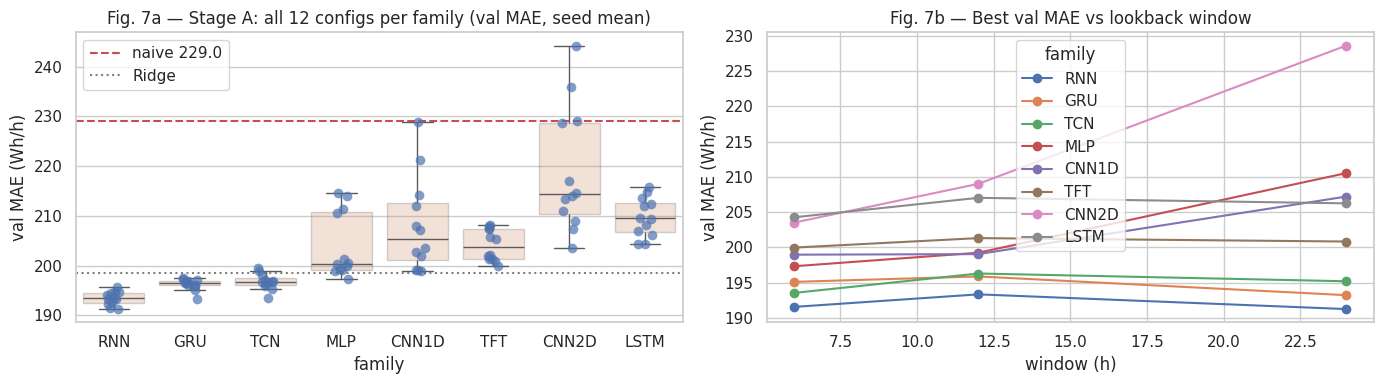

Selected family for Stage B (lowest Stage-A objective): RNN  cfg={'window': 24, 'hidden': 64, 'layers': 2}  val MAE 191.26 ± 0.30; runner-up GRU 193.22 ± 0.64


In [21]:
agg_A = (screen.groupby(["family", "cfg_id", "cfg"])
               .agg(window=("window", "first"), val_MAE=("val_MAE", "mean"), val_MAE_std=("val_MAE", "std"), val_RMSE=("val_RMSE", "mean"),
                    params=("params", "first"), epochs=("epochs", "mean"), train_s=("train_s", "mean"))
               .reset_index().fillna({"val_MAE_std": 0.0}))
agg_A.to_csv("results_stage2/stageA_configs.csv", index=False)
BEST_A = {}; best_rows = []
for name in GRID_A:
    sub = agg_A[agg_A.family == name].sort_values("val_MAE")
    BEST_A[name] = json.loads(sub.iloc[0].cfg); best_rows.append(sub.iloc[0])
best_A = pd.DataFrame(best_rows).sort_values("val_MAE").reset_index(drop=True)
best_A["val_MAE_impr_vs_naive_%"] = 100 * (BASE_VAL["MAE"] - best_A.val_MAE) / BASE_VAL["MAE"]
print(f"Table 5 — Stage A: best configuration per family (validation, mean over seeds {SCREEN_SEEDS}); naive val MAE = {BASE_VAL['MAE']:.2f}")
display(best_A.drop(columns=["cfg_id"]).round(3))
ridge_val = metrics(Y_val, ridge_pred["val"])
print(f"Reference (not a neural family): Ridge val MAE {ridge_val['MAE']:.2f} (deterministic, {ridge_params} params, window {R_L} h) "
      f"-> {100*(BASE_VAL['MAE']-ridge_val['MAE'])/BASE_VAL['MAE']:+.1f}% vs naive; best neural family {best_A.family.iloc[0]} at {best_A.val_MAE.iloc[0]:.2f} "
      f"-> Ridge is {'better' if ridge_val['MAE'] < best_A.val_MAE.iloc[0] else 'worse'} on validation MAE")
json.dump(BEST_A, open("results_stage2/stageA_best_configs.json", "w"), indent=1)

order = best_A.family.tolist()
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.stripplot(data=agg_A, x="family", y="val_MAE", order=order, ax=axs[0], size=7, alpha=0.7)
sns.boxplot(data=agg_A, x="family", y="val_MAE", order=order, ax=axs[0], showfliers=False, boxprops=dict(alpha=0.25))
axs[0].axhline(BASE_VAL["MAE"], color="r", ls="--", label=f"naive {BASE_VAL['MAE']:.1f}")
axs[0].axhline(metrics(Y_val, ridge_pred["val"])["MAE"], color="gray", ls=":", label="Ridge")
axs[0].set_title("Fig. 7a — Stage A: all 12 configs per family (val MAE, seed mean)"); axs[0].set_ylabel("val MAE (Wh/h)"); axs[0].legend()
wb = agg_A.groupby(["family", "window"]).val_MAE.min().unstack(0)[order]
wb.plot(marker="o", ax=axs[1]); axs[1].set_title("Fig. 7b — Best val MAE vs lookback window"); axs[1].set_xlabel("window (h)"); axs[1].set_ylabel("val MAE (Wh/h)")
plt.tight_layout(); plt.savefig("results_stage2/fig7_stageA.png", dpi=150); plt.show()

FINAL_FAMILY = best_A.family.iloc[0]
print(f"Selected family for Stage B (lowest Stage-A objective): {FINAL_FAMILY}  cfg={BEST_A[FINAL_FAMILY]}  "
      f"val MAE {best_A.val_MAE.iloc[0]:.2f} ± {best_A.val_MAE_std.iloc[0]:.2f}; runner-up {best_A.family.iloc[1]} {best_A.val_MAE.iloc[1]:.2f} ± {best_A.val_MAE_std.iloc[1]:.2f}")

### 8.2 Stage B — random-search HPO of the selected family (validation only)
Trial 0 re-scores the Stage-A winner with all defaults made explicit (anchor), so Stage B can only keep or improve on it.

In [22]:
rng = np.random.default_rng(SEED)
def sample_cfg(family):
    cfg = {}
    for k, v in {**SPACE_B_COMMON, **SPACE_B_ARCH[family]}.items():
        if isinstance(v, tuple) and v[0] == "log-uniform":
            cfg[k] = float(f"{np.exp(rng.uniform(np.log(v[1]), np.log(v[2]))):.2g}")
        else:
            cfg[k] = v[rng.integers(len(v))]
    return to_native(cfg)

anchor = to_native(full_cfg(BEST_A[FINAL_FAMILY]))
trial_cfgs, seen = [anchor], {json.dumps(anchor, sort_keys=True)}
while len(trial_cfgs) < N_TRIALS_B:
    c_ = sample_cfg(FINAL_FAMILY); key = json.dumps(c_, sort_keys=True)
    if key not in seen: seen.add(key); trial_cfgs.append(c_)

trial_rows = []; t_all = time.time()
for ti, cfg in enumerate(trial_cfgs):
    res = [run_config(FINAL_FAMILY, cfg, s) for s in SCREEN_SEEDS]
    v = [r["val"]["MAE"] for r in res]
    trial_rows.append(dict(trial=ti, **cfg, val_MAE=np.mean(v), val_MAE_std=np.std(v), val_RMSE=np.mean([r["val"]["RMSE"] for r in res]),
                           params=res[0]["params"], epochs=np.mean([r["epochs"] for r in res]), train_s=np.mean([r["train_time"] for r in res])))
    print(f"trial {ti:2d} {cfg} -> {np.mean(v):7.2f} ± {np.std(v):5.2f}")
trials = pd.DataFrame(trial_rows); trials.to_csv("results_stage2/stageB_trials.csv", index=False)
print(f"Stage B finished in {(time.time()-t_all)/60:.1f} min")
print(f"Table 6 — Stage B trials for {FINAL_FAMILY} (top 10 by val MAE)"); display(trials.sort_values("val_MAE").head(10).round(4))

trial  0 {'dropout': 0.2, 'lr': 0.001, 'batch': 64, 'wd': 1e-05, 'loss': 'L1', 'window': 24, 'hidden': 64, 'layers': 2} ->  191.26 ±  0.21
trial  1 {'window': 3, 'dropout': 0.3, 'lr': 0.00044, 'batch': 64, 'wd': 0.0001, 'loss': 'L1', 'hidden': 64, 'layers': 1} ->  195.46 ±  0.20
trial  2 {'window': 3, 'dropout': 0.2, 'lr': 0.0013, 'batch': 128, 'wd': 0.0001, 'loss': 'Huber', 'hidden': 64, 'layers': 1} ->  196.68 ±  1.61
trial  3 {'window': 24, 'dropout': 0.1, 'lr': 0.00035, 'batch': 32, 'wd': 0.0001, 'loss': 'Huber', 'hidden': 64, 'layers': 2} ->  194.50 ±  2.83
trial  4 {'window': 24, 'dropout': 0.2, 'lr': 0.00022, 'batch': 64, 'wd': 0.0, 'loss': 'Huber', 'hidden': 128, 'layers': 1} ->  192.83 ±  0.47
trial  5 {'window': 24, 'dropout': 0.3, 'lr': 0.00086, 'batch': 32, 'wd': 0.0001, 'loss': 'Huber', 'hidden': 32, 'layers': 1} ->  194.39 ±  0.75
trial  6 {'window': 24, 'dropout': 0.1, 'lr': 0.0014, 'batch': 128, 'wd': 0.0001, 'loss': 'L1', 'hidden': 32, 'layers': 2} ->  193.84 ±  1.57
t

,trial,dropout,lr,batch,wd,loss,window,hidden,layers,val_MAE,val_MAE_std,val_RMSE,params,epochs,train_s
8,8,0.1,0.0004,32,0.0000,L1,24,128,1,190.6011,0.5742,374.0693,21377,40.0,6.7083
9,9,0.0,0.0005,32,0.0000,Huber,6,64,3,190.8906,2.9144,369.9496,23233,24.5,4.8294
0,0,0.2,0.0010,64,0.0000,L1,24,64,2,191.2557,0.2141,386.3028,14913,45.5,4.3644
14,14,0.0,0.0010,32,0.0000,L1,3,128,2,191.6383,2.1156,374.0354,54401,34.5,6.5343
10,10,0.0,0.0011,128,0.0000,L1,6,128,3,192.2307,0.4153,377.8383,87425,29.5,1.5726
13,13,0.2,0.0014,64,0.0000,Huber,6,64,1,192.4926,1.0208,379.8996,6593,26.5,2.3119
4,4,0.2,0.0002,64,0.0000,Huber,24,128,1,192.8326,0.4669,371.3425,21377,46.5,4.0865
18,18,0.1,0.0007,64,0.0000,Huber,6,128,2,192.9617,1.8369,375.0707,54401,24.0,2.5249
24,24,0.1,0.0011,128,0.0001,L1,24,64,1,193.3979,0.1252,384.9471,6593,36.5,1.8996
21,21,0.0,0.0011,64,0.0000,L1,24,32,1,193.7437,1.1841,387.5070,2273,27.5,2.3011


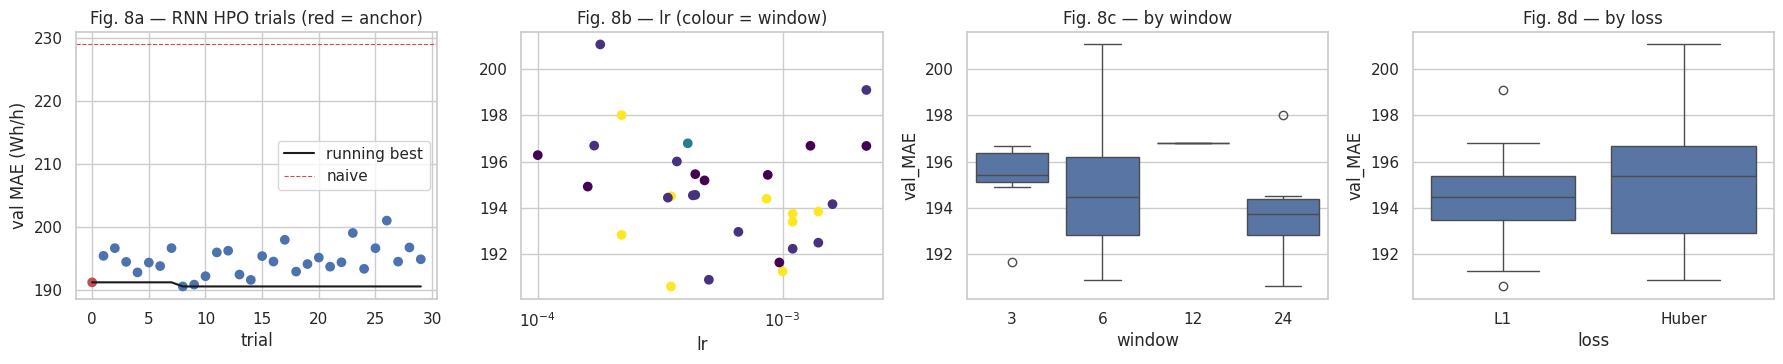

In [23]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
axs[0].scatter(trials.trial, trials.val_MAE, c=["r" if t == 0 else "C0" for t in trials.trial])
axs[0].plot(trials.trial, trials.val_MAE.cummin(), color="k", label="running best"); axs[0].axhline(BASE_VAL["MAE"], color="r", ls="--", lw=0.8, label="naive")
axs[0].set_title(f"Fig. 8a — {FINAL_FAMILY} HPO trials (red = anchor)"); axs[0].set_xlabel("trial"); axs[0].set_ylabel("val MAE (Wh/h)"); axs[0].legend()
axs[1].scatter(trials.lr, trials.val_MAE, c=trials.window, cmap="viridis"); axs[1].set_xscale("log"); axs[1].set_title("Fig. 8b — lr (colour = window)"); axs[1].set_xlabel("lr")
sns.boxplot(data=trials, x="window", y="val_MAE", ax=axs[2]); axs[2].set_title("Fig. 8c — by window")
sns.boxplot(data=trials, x="loss", y="val_MAE", ax=axs[3]); axs[3].set_title("Fig. 8d — by loss")
plt.tight_layout(); plt.savefig("results_stage2/fig8_stageB.png", dpi=150); plt.show()

## 9. Model selection and checkpoint (before touching the test set)
Rule (declared in §8): take the best Stage-B objective; among trials within one seed-std of it, prefer the fewest parameters. The finalist is then retrained with seed 42 and saved together with its configuration and the complete preprocessing state.

In [24]:
best_t = trials.sort_values("val_MAE").iloc[0]
tol = best_t.val_MAE + best_t.val_MAE_std
cands = trials[trials.val_MAE <= tol].sort_values(["params", "val_MAE"])
sel = cands.iloc[0]
cfg_keys = list(SPACE_B_COMMON) + list(SPACE_B_ARCH[FINAL_FAMILY])
FINAL_CFG = to_native({k: sel[k] for k in cfg_keys})
for k in ("window", "hidden", "layers", "filters", "kernel", "channels", "batch", "d_model", "heads"):
    if k in FINAL_CFG: FINAL_CFG[k] = int(FINAL_CFG[k])
anc = trials[trials.trial == 0].iloc[0]
print(f"Best trial #{int(best_t.trial)}: val MAE {best_t.val_MAE:.2f} ± {best_t.val_MAE_std:.2f}; {len(cands)} trial(s) within 1 std (≤ {tol:.2f})")
print(f"Selected trial #{int(sel.trial)} ({int(sel.params)} params): val MAE {sel.val_MAE:.2f} ± {sel.val_MAE_std:.2f}")
print(f"Anchor (Stage-A config): {anc.val_MAE:.2f} ± {anc.val_MAE_std:.2f}  -> tuning gain {anc.val_MAE - sel.val_MAE:+.2f} Wh/h "
      f"({'larger than' if anc.val_MAE - sel.val_MAE > max(anc.val_MAE_std, sel.val_MAE_std) else 'within'} seed noise)")
print("FINAL:", FINAL_FAMILY, FINAL_CFG)

sel_table = pd.DataFrame([dict(candidate=f"{r.family} (Stage A)", val_MAE=r.val_MAE, val_MAE_std=r.val_MAE_std, params=r.params) for r in best_A.itertuples()]
                         + [dict(candidate="Ridge (log target, reference)", val_MAE=ridge_val["MAE"], val_MAE_std=0.0, params=ridge_params)]
                         + ([] if int(sel.trial) == 0 else [dict(candidate=f"{FINAL_FAMILY} ★ tuned (trial {int(sel.trial)})", val_MAE=sel.val_MAE, val_MAE_std=sel.val_MAE_std, params=sel.params)]))
print(f"Best raw trial #{int(best_t.trial)} is {anc.val_MAE - best_t.val_MAE:.2f} Wh/h better than the anchor (anchor std {anc.val_MAE_std:.2f}, best-trial std {best_t.val_MAE_std:.2f}); "
      f"the parsimony rule selected trial #{int(sel.trial)}" + (" (= the Stage-A anchor, so no separate 'tuned' row is created)." if int(sel.trial) == 0 else "."))
print("Table 7 — Selection evidence (validation only)"); display(sel_table.sort_values("val_MAE").round(3))

r_fin = run_config(FINAL_FAMILY, FINAL_CFG, SEED)
torch.save(dict(family=FINAL_FAMILY, config=FINAL_CFG, state_dict=r_fin["model"].state_dict(), C=C, feat_cols=feat_cols, horizon=HORIZON, horizons=HORIZONS,
                freq=FREQ, maxw=MAXW, seed=SEED, val_metrics=r_fin["val"], env=ENV), f"{CK}_finalist.pt")
pickle.dump(dict(imputer=imputer, x_scaler=x_scaler, y_scaler=y_scaler, feat_cols=feat_cols, log_cols=LOG_COLS, drop=DROP,
                 target_transform="log1p -> StandardScaler", resample=dict(freq=FREQ, energy_sum=ENERGY, others="mean", full_bin=STEPS_PER_BIN),
                 calendar=["hour_sin", "hour_cos", "dow_sin", "dow_cos", "weekend"], horizons=HORIZONS,
                 target_time_calendar=True), open(f"{CK}_preprocessing.pkl", "wb"))
json.dump(dict(family=FINAL_FAMILY, config=FINAL_CFG, selected_trial=int(sel.trial), val_MAE_mean=float(sel.val_MAE),
               val_MAE_std=float(sel.val_MAE_std), seed=SEED, protocol="results_stage2/hpo_protocol.json"),
          open(f"{CK}_finalist_config.json", "w"), indent=1)
print(f"Checkpoint saved (seed {SEED}, val MAE {r_fin['val']['MAE']:.2f}, {r_fin['params']} params): {CK}_finalist.pt, "
      f"{CK}_preprocessing.pkl, {CK}_finalist_config.json")

Best trial #8: val MAE 190.60 ± 0.57; 2 trial(s) within 1 std (≤ 191.18)
Selected trial #8 (21377 params): val MAE 190.60 ± 0.57
Anchor (Stage-A config): 191.26 ± 0.21  -> tuning gain +0.65 Wh/h (larger than seed noise)
FINAL: RNN {'window': 24, 'dropout': 0.1, 'lr': 0.00035, 'batch': 32, 'wd': 0.0, 'loss': 'L1', 'hidden': 128, 'layers': 1}
Best raw trial #8 is 0.65 Wh/h better than the anchor (anchor std 0.21, best-trial std 0.57); the parsimony rule selected trial #8.
Table 7 — Selection evidence (validation only)


,candidate,val_MAE,val_MAE_std,params
9,RNN ★ tuned (trial 8),190.601,0.574,21377
0,RNN (Stage A),191.256,0.303,14913
1,GRU (Stage A),193.225,0.642,44609
2,TCN (Stage A),193.550,0.448,4705
3,MLP (Stage A),197.328,2.470,16001
8,"Ridge (log target, reference)",198.419,0.000,109
4,CNN1D (Stage A),198.964,3.744,26209
5,TFT (Stage A),199.971,2.319,47593
6,CNN2D (Stage A),203.521,5.774,37697
7,LSTM (Stage A),204.266,2.603,8993


Checkpoint saved (seed 42, val MAE 190.03, 21377 params): checkpoints/stage3_finalist.pt, checkpoints/stage3_preprocessing.pkl, checkpoints/stage3_finalist_config.json


## 10. Final evaluation on the test set
The test split is used here for the first time. Each family is retrained with **5 seeds** using its Stage-A best configuration; the finalist family is reported twice (Stage-A config and tuned config) only if Stage B selected a different configuration, otherwise once and marked ★. For the finalist, seed 42 is the **loaded checkpoint** rather than a retrain. Inference time is the mean over the 658 test windows (batched) and single-sample latency (batch = 1) on the seed-42 model.

In [25]:
ckpt = torch.load(f"{CK}_finalist.pt", map_location=DEVICE, weights_only=False)
def same_cfg(a, b):
    a, b = {**DEFAULTS, **a}, {**DEFAULTS, **b}
    return set(a) == set(b) and all(np.isclose(a[k], b[k]) if isinstance(a[k], (int, float)) else a[k] == b[k] for k in a)
CFG_SAME = same_cfg(BEST_A[FINAL_FAMILY], ckpt["config"])
FINAL_LABEL = f"{FINAL_FAMILY} ★ finalist" if CFG_SAME else f"{FINAL_FAMILY} ★ tuned"
entries = []
for f in GRID_A:
    entries.append((FINAL_LABEL, f, ckpt["config"]) if (f == FINAL_FAMILY and CFG_SAME) else (f, f, BEST_A[f]))
if not CFG_SAME: entries.append((FINAL_LABEL, FINAL_FAMILY, ckpt["config"]))
TFT_LABEL = next(l_ for l_, f_, _ in entries if f_ == "TFT")      # label of the Transformer row (it may or may not be the finalist)
PRED, MODELS = {}, {}      # Stage 3: PRED[(h, label)] = list of per-seed dicts (Wh/h and standardised-log predictions); MODELS[(h, label)] = seed-42 model
print(f"Stage-B config {'equals' if CFG_SAME else 'differs from'} the Stage-A config -> {len(entries)} neural rows")
final, run_log, test_preds, curves, infer = {}, [], {}, {}, {}
for label, fam, cfg in entries:
    L = cfg["window"]; per_seed = []
    for s in FINAL_SEEDS:
        if label == FINAL_LABEL and s == SEED:
            m = build(fam, cfg); m.load_state_dict(ckpt["state_dict"])
            r = dict(model=m, hist=r_fin["hist"], train_time=r_fin["train_time"], epochs=r_fin["epochs"], params=n_params(m),
                     val=metrics(Y_val, inv(predict_scaled(m, tens(L, "val")[0]))))
        else:
            r = run_config(fam, cfg, s)
        ps_t, ps_v = predict_scaled(r["model"], tens(L, "test")[0]), predict_scaled(r["model"], tens(L, "val")[0])
        pt = inv(ps_t); mt = metrics(Y_test, pt)
        PRED.setdefault((HORIZON, label), []).append(dict(seed=s, val=inv(ps_v), test=pt, val_s=ps_v, test_s=ps_t, params=r["params"],
                                                          train_s=r["train_time"], epochs=r["epochs"], cfg=cfg))
        if s == SEED:
            test_preds[label] = pt; curves[label] = r["hist"]; infer[label] = infer_time(r["model"], tens(L, "test")[0]); MODELS[(HORIZON, label)] = r["model"]
        per_seed.append(dict(seed=s, params=r["params"], train_s=r["train_time"], epochs=r["epochs"],
                             **{f"val_{k}": v for k, v in r["val"].items()}, **{f"test_{k}": v for k, v in mt.items()}))
        run_log.append(dict(model=label, cfg=cfg, **per_seed[-1]))
    final[label] = pd.DataFrame(per_seed)
    print(f"{label:12s} test MAE {final[label].test_MAE.mean():7.2f} ± {final[label].test_MAE.std(ddof=0):5.2f}")
FINAL_TEST_PRED = test_preds[FINAL_LABEL]

Stage-B config differs from the Stage-A config -> 9 neural rows
MLP          test MAE  187.83 ±  3.54
CNN1D        test MAE  199.13 ±  4.63
CNN2D        test MAE  206.68 ± 10.97
RNN          test MAE  183.30 ±  3.11
LSTM         test MAE  216.70 ±  9.75
GRU          test MAE  193.06 ±  1.64
TCN          test MAE  195.64 ± 14.15
TFT          test MAE  191.89 ±  6.69
RNN ★ tuned  test MAE  179.80 ±  3.49


In [26]:
BASE_TEST = metrics(Y_test, base[NAIVE]["test"])
rows = []
for k in base:
    mv, mt = metrics(Y_val, base[k]["val"]), metrics(Y_test, base[k]["test"])
    rows.append(dict(Model=k, Config="—", Params=0, Train_s=0.0, Infer_ms_batched=np.nan, Infer_ms_single=np.nan, Seeds="—", val_MAE=mv["MAE"],
                     **{f"test_{m}": mt[m] for m in mt}, test_MAE_std=0.0, test_RMSE_std=0.0))
mv, mt = metrics(Y_val, ridge_pred["val"]), metrics(Y_test, ridge_pred["test"])
Xr_ = get_data(R_L)["test"]["X"].reshape(len(T_test), -1); t0 = time.time(); ridge.predict(Xr_); r_inf = (time.time() - t0) / len(T_test) * 1e3
rows.append(dict(Model="Ridge (log target)", Config=f"L={R_L}, alpha={R_ALPHA}", Params=ridge_params, Train_s=ridge_time, Infer_ms_batched=r_inf,
                 Infer_ms_single=np.nan, Seeds="deterministic", val_MAE=mv["MAE"], **{f"test_{m}": mt[m] for m in mt}, test_MAE_std=0.0, test_RMSE_std=0.0))
for label, f in final.items():
    cfg = next(c for l_, _, c in entries if l_ == label)
    rows.append(dict(Model=label, Config=json.dumps(cfg), Params=int(f.params.iloc[0]), Train_s=f.train_s.mean(),
                     Infer_ms_batched=infer[label][0], Infer_ms_single=infer[label][1], Seeds=str(FINAL_SEEDS), val_MAE=f.val_MAE.mean(),
                     **{f"test_{m}": f[f"test_{m}"].mean() for m in ("MAE", "RMSE", "sMAPE", "R2")},
                     test_MAE_std=f.test_MAE.std(ddof=0), test_RMSE_std=f.test_RMSE.std(ddof=0)))
cmp_ = pd.DataFrame(rows)
cmp_["MAE_improv_%"] = 100 * (BASE_TEST["MAE"] - cmp_["test_MAE"]) / BASE_TEST["MAE"]
cmp_["RMSE_improv_%"] = 100 * (BASE_TEST["RMSE"] - cmp_["test_RMSE"]) / BASE_TEST["RMSE"]
RIDGE_ROW = cmp_[cmp_.Model.str.startswith("Ridge")].iloc[0]                       # Stage 3: every model is also compared against Ridge
cmp_["MAE_improv_vs_Ridge_%"] = 100 * (RIDGE_ROW.test_MAE - cmp_["test_MAE"]) / RIDGE_ROW.test_MAE
cmp_["RMSE_improv_vs_Ridge_%"] = 100 * (RIDGE_ROW.test_RMSE - cmp_["test_RMSE"]) / RIDGE_ROW.test_RMSE
cmp_.to_csv(f"{OUT3}/table8_comparison_with_ridge_columns.csv", index=False)
cmp_.to_csv("results_stage2/table8_comparison.csv", index=False)
json.dump(dict(env=ENV, seed=SEED, final_seeds=FINAL_SEEDS, horizon=HORIZON, freq=FREQ, runs=run_log),
          open("results_stage2/run_log.json", "w"), indent=1, default=float)

pm = lambda a, s: f"{a:.2f} ± {s:.2f}" if s > 0 else f"{a:.2f}"
pretty = pd.DataFrame({
    "Model": cmp_.Model, "Params": cmp_.Params, "Train (s)": cmp_.Train_s.round(1),
    "Infer ms/sample (batched)": cmp_.Infer_ms_batched.round(4), "Latency ms (batch=1)": cmp_.Infer_ms_single.round(3),
    "Val MAE": cmp_.val_MAE.round(2),
    "Test MAE": [pm(a, s) for a, s in zip(cmp_.test_MAE, cmp_.test_MAE_std)],
    "Test RMSE": [pm(a, s) for a, s in zip(cmp_.test_RMSE, cmp_.test_RMSE_std)],
    "sMAPE %": cmp_.test_sMAPE.round(1), "R²": cmp_.test_R2.round(3),
    "MAE impr. vs naive %": cmp_["MAE_improv_%"].round(1), "RMSE impr. vs naive %": cmp_["RMSE_improv_%"].round(1),
    "MAE impr. vs Ridge %": cmp_["MAE_improv_vs_Ridge_%"].round(1), "RMSE impr. vs Ridge %": cmp_["RMSE_improv_vs_Ridge_%"].round(1)})
print(f"Table 8 — TEST-SET COMPARISON (Wh/h; same {len(T_test)} test hours for every model; neural rows = mean ± std over {len(FINAL_SEEDS)} seeds)")
display(pretty)

Table 8 — TEST-SET COMPARISON (Wh/h; same 658 test hours for every model; neural rows = mean ± std over 5 seeds)


,Model,Params,Train (s),Infer ms/sample (batched),Latency ms (batch=1),Val MAE,Test MAE,Test RMSE,sMAPE %,R²,MAE impr. vs naive %,RMSE impr. vs naive %,MAE impr. vs Ridge %,RMSE impr. vs Ridge %
0,Naive (last hour),0,0.0,NaN,NaN,229.04,198.83,372.23,25.8,0.225,0.0,0.0,-9.1,-9.7
1,Seasonal naive (t-24 h),0,0.0,NaN,NaN,306.61,265.47,485.42,34.4,-0.318,-33.5,-30.4,-45.7,-43.0
2,Hour-of-week median (train),0,0.0,NaN,NaN,264.77,246.29,438.54,35.0,-0.076,-23.9,-17.8,-35.2,-29.2
3,Ridge (log target),109,0.0,0.0007,NaN,198.42,182.17,339.46,25.4,0.356,8.4,8.8,0.0,0.0
4,MLP,16001,2.6,0.0006,0.174,195.82,187.83 ± 3.54,362.55 ± 9.13,26.1,0.264,5.5,2.6,-3.1,-6.8
5,CNN1D,26209,2.5,0.0018,0.535,203.68,199.13 ± 4.63,390.45 ± 7.34,28.3,0.147,-0.2,-4.9,-9.3,-15.0
6,CNN2D,37697,4.7,0.0022,0.453,205.56,206.68 ± 10.97,384.73 ± 19.11,30.3,0.170,-3.9,-3.4,-13.5,-13.3
7,RNN,14913,4.2,0.0018,0.334,191.30,183.30 ± 3.11,361.01 ± 8.68,25.3,0.271,7.8,3.0,-0.6,-6.3
8,LSTM,8993,3.6,0.0012,0.453,204.67,216.70 ± 9.75,423.63 ± 13.94,31.1,-0.005,-9.0,-13.8,-19.0,-24.8
9,GRU,44609,3.6,0.0046,0.314,194.12,193.06 ± 1.64,380.02 ± 8.97,26.9,0.192,2.9,-2.1,-6.0,-11.9


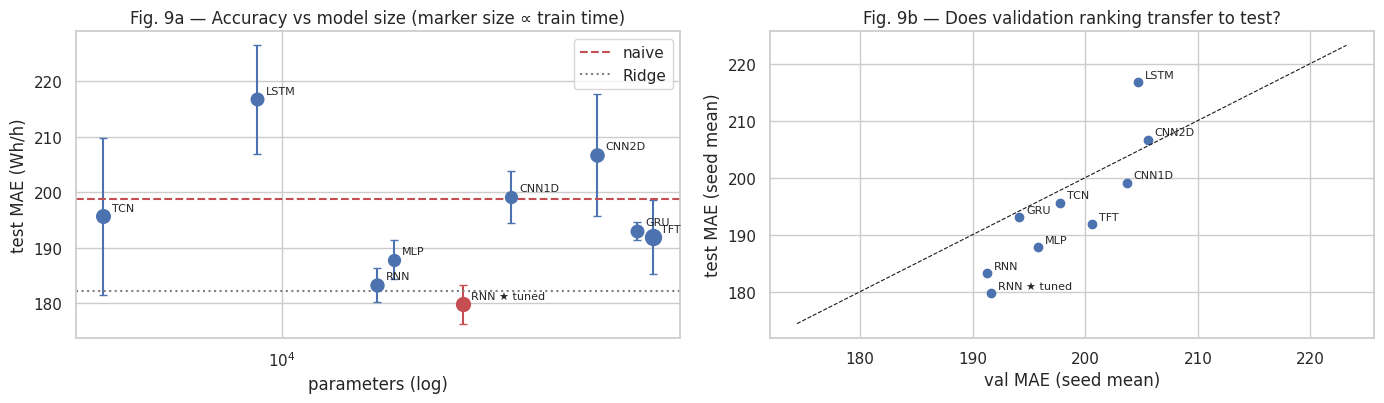

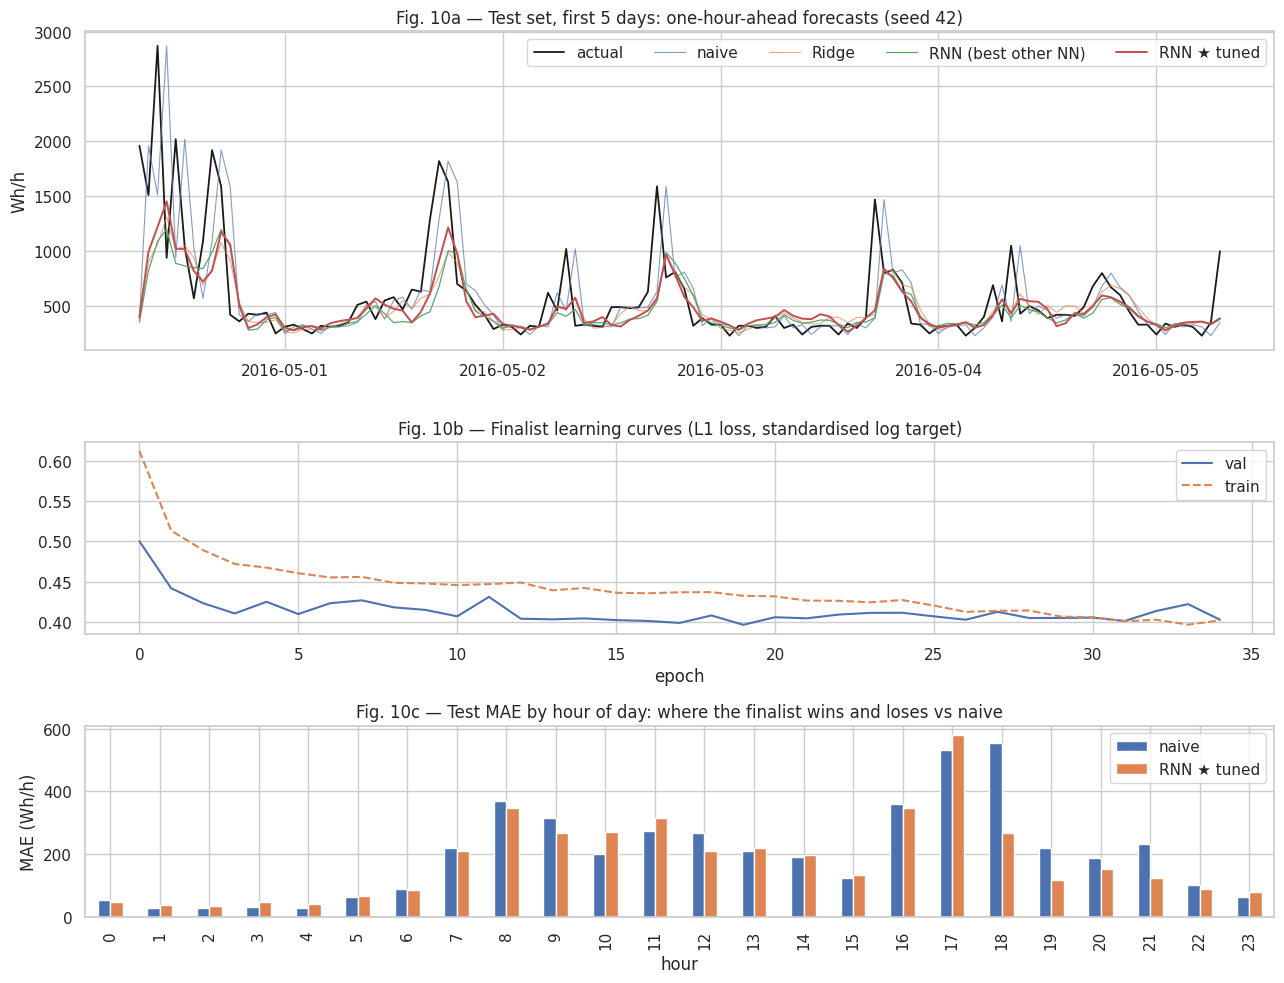

In [27]:
nn_rows = cmp_[cmp_.Model.isin(final.keys())]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for _, r in nn_rows.iterrows():
    axs[0].errorbar(r.Params, r.test_MAE, yerr=r.test_MAE_std, fmt="o", ms=6 + 2*np.log1p(r.Train_s), capsize=3,
                    color="C3" if r.Model == FINAL_LABEL else "C0")
    axs[0].annotate(r.Model, (r.Params, r.test_MAE), textcoords="offset points", xytext=(6, 4), fontsize=8)
axs[0].axhline(BASE_TEST["MAE"], color="r", ls="--", label="naive"); axs[0].axhline(metrics(Y_test, ridge_pred["test"])["MAE"], color="gray", ls=":", label="Ridge")
axs[0].set_xscale("log"); axs[0].set_xlabel("parameters (log)"); axs[0].set_ylabel("test MAE (Wh/h)"); axs[0].legend()
axs[0].set_title("Fig. 9a — Accuracy vs model size (marker size ∝ train time)")
axs[1].scatter(nn_rows.val_MAE, nn_rows.test_MAE)
for _, r in nn_rows.iterrows(): axs[1].annotate(r.Model, (r.val_MAE, r.test_MAE), textcoords="offset points", xytext=(5, 3), fontsize=8)
lim = [min(nn_rows.val_MAE.min(), nn_rows.test_MAE.min()) * 0.97, max(nn_rows.val_MAE.max(), nn_rows.test_MAE.max()) * 1.03]
axs[1].plot(lim, lim, "k--", lw=0.8); axs[1].set_xlabel("val MAE (seed mean)"); axs[1].set_ylabel("test MAE (seed mean)")
axs[1].set_title("Fig. 9b — Does validation ranking transfer to test?")
plt.tight_layout(); plt.savefig("results_stage2/fig9_cost_and_transfer.png", dpi=150); plt.show()

others = nn_rows[nn_rows.Model != FINAL_LABEL].sort_values("test_MAE").Model.iloc[0]
fig, axs = plt.subplots(3, 1, figsize=(13, 10), gridspec_kw=dict(height_ratios=[2, 1.2, 1.2]))
sl = slice(0, 5*DAY); tt = dh.date.values[T_test][sl]
axs[0].plot(tt, Y_test[sl], color="k", lw=1.3, label="actual")
axs[0].plot(tt, base[NAIVE]["test"][sl], lw=0.8, alpha=0.7, label="naive")
axs[0].plot(tt, ridge_pred["test"][sl], lw=0.8, alpha=0.7, label="Ridge")
axs[0].plot(tt, test_preds[others][sl], lw=0.9, label=f"{others} (best other NN)")
axs[0].plot(tt, FINAL_TEST_PRED[sl], lw=1.4, color="C3", label=FINAL_LABEL)
axs[0].set_title("Fig. 10a — Test set, first 5 days: one-hour-ahead forecasts (seed 42)"); axs[0].set_ylabel("Wh/h"); axs[0].legend(ncol=5)
h_ = curves[FINAL_LABEL]
axs[1].plot([v for _, v in h_], label="val"); axs[1].plot([t for t, _ in h_], ls="--", label="train")
axs[1].set_title(f"Fig. 10b — Finalist learning curves ({ckpt['config']['loss']} loss, standardised log target)"); axs[1].set_xlabel("epoch"); axs[1].legend()
err_df = pd.DataFrame(dict(hour=dh.date.dt.hour.values[T_test], fin=np.abs(FINAL_TEST_PRED - Y_test), naive=np.abs(base[NAIVE]["test"] - Y_test)))
err_df.groupby("hour")[["naive", "fin"]].mean().rename(columns={"fin": FINAL_LABEL}).plot(kind="bar", ax=axs[2])
axs[2].set_title("Fig. 10c — Test MAE by hour of day: where the finalist wins and loses vs naive"); axs[2].set_ylabel("MAE (Wh/h)")
plt.tight_layout(); plt.savefig("results_stage2/fig10_forecasts.png", dpi=150); plt.show()

### 10.1 How certain are the differences? Paired block bootstrap (test set)
Seed spread (Table 8) is only one source of uncertainty; the test set is also just 658 hours. For each model (seed-42 predictions) we resample the test hours in **24-hour blocks** (to respect autocorrelation, 2000 resamples) and compute the paired difference in absolute error against a reference. A positive value means the model has the lower MAE. Table 9 reports the improvement over naive for every model plus three targeted pairs; an interval that excludes 0 is evidence beyond test-sample noise.

Table 9 — Paired block bootstrap (2000 resamples, 24 h blocks, seed-42 predictions). MAE_diff > 0 = model better than reference; 95% interval.


,model,reference,MAE_diff_Wh,CI_lo,CI_hi,rel_pct,rel_lo,rel_hi,P_better,significant
0,MLP,naive,12.396,-4.095,27.378,6.235,-2.098,13.677,0.934,False
1,CNN1D,naive,6.414,-14.434,24.806,3.226,-6.682,12.824,0.748,False
2,CNN2D,naive,-19.118,-41.329,1.146,-9.615,-20.001,0.647,0.031,False
3,RNN,naive,14.074,-3.143,30.422,7.079,-1.540,15.404,0.946,False
4,LSTM,naive,-12.948,-39.035,11.269,-6.512,-18.409,5.871,0.150,False
5,GRU,naive,8.510,-10.439,26.497,4.280,-5.028,13.136,0.810,False
6,TCN,naive,17.096,1.486,31.767,8.598,0.752,16.014,0.986,True
7,TFT,naive,10.096,-8.526,27.662,5.077,-4.434,13.192,0.868,False
8,RNN ★ tuned,naive,18.550,3.302,33.797,9.330,1.670,16.298,0.994,True
9,Ridge (log target),naive,16.660,2.527,30.380,8.379,1.210,14.800,0.994,True


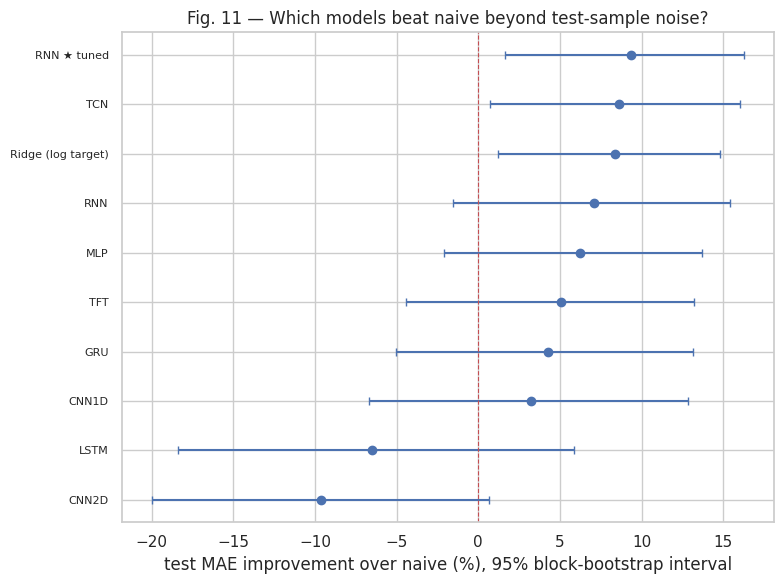

In [28]:
rng_b = np.random.default_rng(SEED)
nT = len(T_test); nbk = int(np.ceil(nT / BOOT_BLOCK))
starts = rng_b.integers(0, nT, size=(N_BOOT, nbk))
bidx = ((starts[:, :, None] + np.arange(BOOT_BLOCK)[None, None, :]) % nT).reshape(N_BOOT, -1)[:, :nT]     # circular blocks

def paired_ci(err_ref, err_mod):
    d = err_ref - err_mod                                  # > 0  <=>  model better than reference
    m = d[bidx].mean(axis=1); rel = 100 * m / err_ref[bidx].mean(axis=1)
    return dict(MAE_diff_Wh=d.mean(), CI_lo=np.percentile(m, 2.5), CI_hi=np.percentile(m, 97.5),
                rel_pct=100 * d.mean() / err_ref.mean(), rel_lo=np.percentile(rel, 2.5), rel_hi=np.percentile(rel, 97.5), P_better=(m > 0).mean())

abs_err = {k: np.abs(v - Y_test) for k, v in test_preds.items()}
abs_err["Ridge (log target)"] = np.abs(ridge_pred["test"] - Y_test)
abs_naive = np.abs(base[NAIVE]["test"] - Y_test)
RIDGE_NAME = "Ridge (log target)"
pairs = ([(m_, "naive") for m_ in abs_err] + [(m_, RIDGE_NAME) for m_ in abs_err if m_ != RIDGE_NAME]     # every model vs BOTH naive and Ridge
         + [("CNN2D", "CNN1D"), (FINAL_LABEL, "MLP")] + ([(TFT_LABEL, FINAL_LABEL)] if TFT_LABEL != FINAL_LABEL else []))
rows_b = []
for mod, ref in pairs:
    if mod not in abs_err or (ref != "naive" and ref not in abs_err) or mod == ref: continue
    rows_b.append(dict(model=mod, reference=ref, **paired_ci(abs_naive if ref == "naive" else abs_err[ref], abs_err[mod])))
boot = pd.DataFrame(rows_b); boot["significant"] = (boot.CI_lo > 0) | (boot.CI_hi < 0)
boot.to_csv("results_stage2/table9_bootstrap.csv", index=False)
print(f"Table 9 — Paired block bootstrap ({N_BOOT} resamples, {BOOT_BLOCK} h blocks, seed-{SEED} predictions). MAE_diff > 0 = model better than reference; 95% interval.")
display(boot.round(3))

vs_n = boot[boot.reference == "naive"].sort_values("rel_pct")
fig, ax = plt.subplots(figsize=(8, 0.45 * len(vs_n) + 1.5))
ax.errorbar(vs_n.rel_pct, range(len(vs_n)), xerr=[vs_n.rel_pct - vs_n.rel_lo, vs_n.rel_hi - vs_n.rel_pct], fmt="o", capsize=3)
ax.axvline(0, color="r", ls="--", lw=0.8); ax.set_yticks(range(len(vs_n))); ax.set_yticklabels(vs_n.model, fontsize=8)
ax.set_xlabel("test MAE improvement over naive (%), 95% block-bootstrap interval"); ax.set_title("Fig. 11 — Which models beat naive beyond test-sample noise?")
plt.tight_layout(); plt.savefig("results_stage2/fig11_bootstrap.png", dpi=150); plt.show()

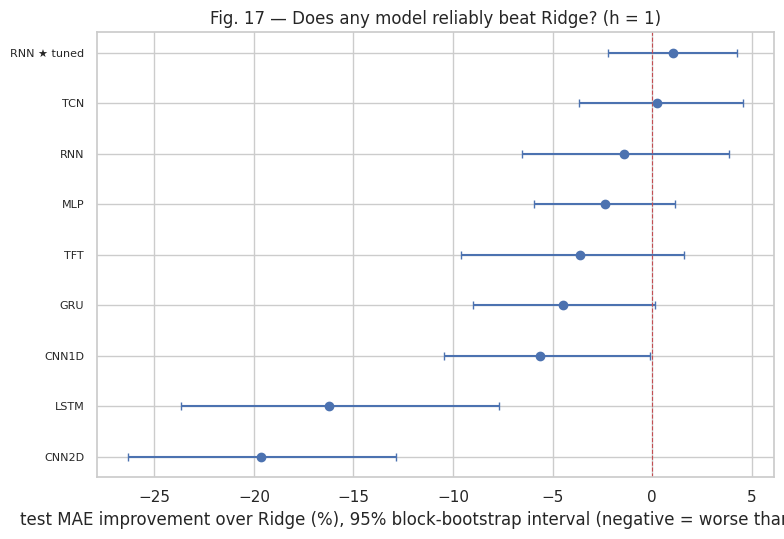

h=1, seed-42 block bootstrap: models whose 95% interval excludes zero in their favour vs naive: ['TCN', 'RNN ★ tuned', 'Ridge (log target)']; vs Ridge: none; models significantly WORSE than Ridge: ['CNN1D', 'CNN2D', 'LSTM']
[timer] section 10.1 (vs Ridge) done: 30.1 min since the Stage-3 timer started


In [29]:
# Fig. 17 — complement of Fig. 11: which models beat RIDGE beyond test-sample noise? (same block bootstrap, seed-42 predictions)
vs_r = boot[boot.reference == RIDGE_NAME].sort_values("rel_pct")
fig, ax = plt.subplots(figsize=(8, 0.45 * len(vs_r) + 1.5))
ax.errorbar(vs_r.rel_pct, range(len(vs_r)), xerr=[vs_r.rel_pct - vs_r.rel_lo, vs_r.rel_hi - vs_r.rel_pct], fmt="o", capsize=3)
ax.axvline(0, color="r", ls="--", lw=0.8); ax.set_yticks(range(len(vs_r))); ax.set_yticklabels(vs_r.model, fontsize=8)
ax.set_xlabel("test MAE improvement over Ridge (%), 95% block-bootstrap interval (negative = worse than Ridge)")
ax.set_title("Fig. 17 — Does any model reliably beat Ridge? (h = 1)"); plt.tight_layout(); plt.savefig(f"{OUT3}/fig17_bootstrap_vs_ridge.png", dpi=150); plt.show()
beat_n = boot[(boot.reference == "naive") & (boot.CI_lo > 0)].model.tolist(); beat_r = boot[(boot.reference == RIDGE_NAME) & (boot.CI_lo > 0)].model.tolist()
worse_r = boot[(boot.reference == RIDGE_NAME) & (boot.CI_hi < 0)].model.tolist()
print(f"h=1, seed-42 block bootstrap: models whose 95% interval excludes zero in their favour vs naive: {beat_n or 'none'}; vs Ridge: {beat_r or 'none'}; "
      f"models significantly WORSE than Ridge: {worse_r or 'none'}")
tick("section 10.1 (vs Ridge) done")

### 10.2 Validation → test shift diagnostic
Validation and test cover different weeks (the test period is warmer in the dataset). Table 10 summarises how the target and the naive error differ between splits, and how each model's MAE changes from validation to test, so that the reader can judge how much of the validation ranking can be expected to transfer.

In [30]:
rows_s = []
for k, (lo, hi) in splits.items():
    T_ = np.arange(lo, hi)
    rows_s.append(dict(split=k, n=len(T_), mean_Wh=y_raw[T_].mean(), median_Wh=np.median(y_raw[T_]), std_Wh=y_raw[T_].std(),
                       naive_MAE=np.mean(np.abs(y_raw[T_] - y_raw[T_ - 1])), mean_T_out_C=dh["T_out"].values[T_].mean(), mean_RH_out=dh["RH_out"].values[T_].mean()))
shift = pd.DataFrame(rows_s); shift.to_csv("results_stage2/table10_split_shift.csv", index=False)
print("Table 10a — Target and weather by split (hourly)"); display(shift.round(2))
vt = cmp_[["Model", "val_MAE", "test_MAE"]].copy(); vt["test/val MAE"] = vt.test_MAE / vt.val_MAE
vt = vt[~vt.Model.isin(["Seasonal naive (t-24 h)", "Hour-of-week median (train)"])]
vt.to_csv("results_stage2/table10b_val_to_test.csv", index=False)
print("Table 10b — Validation → test MAE ratio (ratio below the naive row = model degrades less than persistence does)"); display(vt.round(3))

Table 10a — Target and weather by split (hourly)


,split,n,mean_Wh,median_Wh,std_Wh,naive_MAE,mean_T_out_C,mean_RH_out
0,train,1949,583.95,360.0,502.83,251.49,4.95,83.33
1,val,658,598.98,390.0,496.76,229.04,8.55,77.16
2,test,658,578.02,390.0,422.86,198.83,13.63,71.43


Table 10b — Validation → test MAE ratio (ratio below the naive row = model degrades less than persistence does)


,Model,val_MAE,test_MAE,test/val MAE
0,Naive (last hour),229.043,198.830,0.868
3,Ridge (log target),198.419,182.170,0.918
4,MLP,195.823,187.830,0.959
5,CNN1D,203.683,199.129,0.978
6,CNN2D,205.556,206.676,1.005
7,RNN,191.303,183.296,0.958
8,LSTM,204.673,216.700,1.059
9,GRU,194.125,193.061,0.995
10,TCN,197.745,195.637,0.989
11,TFT,200.598,191.886,0.957


## 10.3 Multi-step test evaluation (h = 6, 12, 24; 5 seeds)
**Question.** Does any family beat naive *and* Ridge at longer horizons, and how does the margin change with h?

**Method and assumption.** Selection and HPO were done once, at h = 1, on validation only (§8–§9). For every other horizon, every family in `entries` (its Stage-A best configuration; plus the finalist's tuned configuration only if Stage B changed it) is retrained with all `FINAL_SEEDS`, with early stopping on the **validation set of that horizon**. The hyperparameters are therefore *not* re-tuned per horizon; this favours neither the Transformer nor any other family. h = 1 results are taken from §10 (identical models and predictions). Baselines use the horizon-specific functions of §6.1; at h = 24 naive and seasonal naive coincide.

Table 18 reports test metrics and the percentage improvement against naive **and** against Ridge. Table 19 repeats the paired 24-hour block bootstrap of §10.1 at each horizon (seed-42 predictions; the same resampling indices as Table 9). The finalist's seed-42 model at each horizon is checkpointed for the smoke test.

In [31]:
t_hz = time.time()
for h in HORIZONS:
    if h == HORIZON: continue
    for label, fam, cfg in entries:
        L = cfg["window"]
        for s in FINAL_SEEDS:
            r = run_config(fam, cfg, s, h)
            ps_t, ps_v = predict_scaled(r["model"], tens(L, "test", h)[0]), predict_scaled(r["model"], tens(L, "val", h)[0])
            PRED.setdefault((h, label), []).append(dict(seed=s, val=inv(ps_v), test=inv(ps_t), val_s=ps_v, test_s=ps_t, params=r["params"],
                                                        train_s=r["train_time"], epochs=r["epochs"], cfg=cfg))
            if s == SEED:
                MODELS[(h, label)] = r["model"]
                if label == FINAL_LABEL:                                   # checkpoint of the finalist at every horizon (used by the smoke test and later sections)
                    torch.save(dict(family=fam, config=cfg, state_dict=r["model"].state_dict(), C=C, horizon=h, seed=SEED), f"{CK}_finalist_h{h}.pt")
        print(f"h={h:2d} {label:18s} test MAE {np.mean([np.mean(np.abs(p['test'] - Y_test)) for p in PRED[(h, label)]]):7.2f}")
print(f"Section 10.3 retraining finished in {(time.time() - t_hz) / 60:.1f} min ({(len(HORIZONS) - 1) * len(entries) * len(FINAL_SEEDS)} fits)")
tick("section 10.3 retraining done")

h= 6 MLP                test MAE  228.84
h= 6 CNN1D              test MAE  232.24
h= 6 CNN2D              test MAE  218.01
h= 6 RNN                test MAE  219.14
h= 6 LSTM               test MAE  231.67
h= 6 GRU                test MAE  221.53
h= 6 TCN                test MAE  229.08
h= 6 TFT                test MAE  227.99
h= 6 RNN ★ tuned        test MAE  232.38
h=12 MLP                test MAE  229.79
h=12 CNN1D              test MAE  233.82
h=12 CNN2D              test MAE  232.38
h=12 RNN                test MAE  220.77
h=12 LSTM               test MAE  226.94
h=12 GRU                test MAE  221.63
h=12 TCN                test MAE  236.33
h=12 TFT                test MAE  226.15
h=12 RNN ★ tuned        test MAE  223.65
h=24 MLP                test MAE  215.77
h=24 CNN1D              test MAE  218.24
h=24 CNN2D              test MAE  231.58
h=24 RNN                test MAE  213.71
h=24 LSTM               test MAE  220.80
h=24 GRU                test MAE  214.95
h=24 TCN        

Table 18 — Test results by horizon (Wh/h, 658 test hours; neural rows = mean over 5 seeds; improvement > 0 = better than the reference). Naive == seasonal naive at h in [24]

--- horizon 1 h ---


,model,params,val_MAE,test_MAE,test_MAE_std,test_RMSE,test_RMSE_std,MAE_vs_naive_pct,MAE_vs_Ridge_pct,RMSE_vs_naive_pct,RMSE_vs_Ridge_pct
0,RNN ★ tuned,21377,191.61,179.80,3.49,349.81,9.06,9.57,1.30,6.02,-3.05
1,Ridge (log target),0,NaN,182.17,0.00,339.46,0.00,8.38,0.00,8.81,0.00
2,RNN,14913,191.30,183.30,3.11,361.01,8.68,7.81,-0.62,3.01,-6.35
3,MLP,16001,195.82,187.83,3.54,362.55,9.13,5.53,-3.11,2.60,-6.80
4,TFT,47593,200.60,191.89,6.69,363.40,13.16,3.49,-5.33,2.37,-7.05
5,GRU,44609,194.12,193.06,1.64,380.02,8.97,2.90,-5.98,-2.09,-11.95
6,TCN,4705,197.74,195.64,14.15,379.49,19.01,1.61,-7.39,-1.95,-11.79
7,Naive (last hour),0,NaN,198.83,0.00,372.23,0.00,0.00,-9.15,0.00,-9.66
8,CNN1D,26209,203.68,199.13,4.63,390.45,7.34,-0.15,-9.31,-4.89,-15.02
9,CNN2D,37697,205.56,206.68,10.97,384.73,19.11,-3.95,-13.45,-3.36,-13.34



--- horizon 6 h ---


,model,params,val_MAE,test_MAE,test_MAE_std,test_RMSE,test_RMSE_std,MAE_vs_naive_pct,MAE_vs_Ridge_pct,RMSE_vs_naive_pct,RMSE_vs_Ridge_pct
0,Ridge (log target),0,NaN,213.58,0.00,398.26,0.00,41.88,0.00,30.24,0.00
1,CNN2D,37697,242.25,218.01,2.20,417.95,7.16,40.68,-2.07,26.79,-4.94
2,RNN,14913,230.41,219.14,2.69,420.85,6.96,40.37,-2.60,26.28,-5.67
3,GRU,44609,235.62,221.53,4.01,420.91,3.25,39.72,-3.72,26.27,-5.69
4,TFT,47593,247.38,227.99,7.50,417.05,16.27,37.96,-6.75,26.94,-4.72
5,MLP,16001,235.48,228.84,5.32,416.87,11.05,37.73,-7.14,26.98,-4.67
6,TCN,4705,240.77,229.08,8.66,414.99,8.37,37.66,-7.26,27.31,-4.20
7,LSTM,8993,240.33,231.67,5.66,432.32,14.31,36.96,-8.47,24.27,-8.55
8,CNN1D,26209,234.89,232.24,12.79,425.19,8.37,36.80,-8.74,25.52,-6.76
9,RNN ★ tuned,21377,228.63,232.38,12.17,413.61,15.08,36.77,-8.80,27.55,-3.86



--- horizon 12 h ---


,model,params,val_MAE,test_MAE,test_MAE_std,test_RMSE,test_RMSE_std,MAE_vs_naive_pct,MAE_vs_Ridge_pct,RMSE_vs_naive_pct,RMSE_vs_Ridge_pct
0,Ridge (log target),0,NaN,213.35,0.00,400.14,0.00,48.22,0.00,36.78,0.00
1,RNN,14913,240.98,220.77,4.63,425.02,2.94,46.42,-3.48,32.85,-6.22
2,GRU,44609,239.94,221.63,5.86,432.67,8.43,46.21,-3.88,31.64,-8.13
3,RNN ★ tuned,21377,240.29,223.65,8.41,412.50,2.23,45.72,-4.82,34.83,-3.09
4,TFT,47593,245.90,226.15,6.96,429.03,8.15,45.11,-6.00,32.22,-7.22
5,LSTM,8993,239.72,226.94,3.20,441.26,6.87,44.92,-6.37,30.29,-10.28
6,MLP,16001,239.79,229.79,6.52,437.53,11.51,44.23,-7.70,30.87,-9.34
7,CNN2D,37697,240.81,232.38,7.78,417.98,12.37,43.60,-8.92,33.96,-4.46
8,CNN1D,26209,241.56,233.82,6.79,440.22,4.34,43.25,-9.59,30.45,-10.02
9,TCN,4705,238.18,236.33,3.30,438.56,7.53,42.64,-10.77,30.71,-9.60



--- horizon 24 h ---


,model,params,val_MAE,test_MAE,test_MAE_std,test_RMSE,test_RMSE_std,MAE_vs_naive_pct,MAE_vs_Ridge_pct,RMSE_vs_naive_pct,RMSE_vs_Ridge_pct
0,Ridge (log target),0,NaN,206.14,0.00,397.04,0.00,22.35,0.00,18.21,0.00
1,RNN ★ tuned,21377,236.11,208.93,1.55,403.07,6.66,21.30,-1.35,16.96,-1.52
2,RNN,14913,237.17,213.71,7.71,420.17,17.02,19.50,-3.67,13.44,-5.83
3,GRU,44609,240.93,214.95,3.21,417.78,4.33,19.03,-4.27,13.93,-5.22
4,MLP,16001,234.27,215.77,1.34,416.90,8.63,18.72,-4.67,14.12,-5.00
5,TCN,4705,239.43,217.56,4.35,418.29,11.39,18.05,-5.54,13.83,-5.35
6,CNN1D,26209,237.92,218.24,6.12,419.49,10.01,17.79,-5.87,13.58,-5.65
7,TFT,47593,247.64,220.32,3.75,417.37,7.69,17.01,-6.88,14.02,-5.12
8,LSTM,8993,240.95,220.80,5.71,427.03,6.92,16.83,-7.11,12.03,-7.55
9,CNN2D,37697,239.84,231.58,10.05,403.73,8.54,12.77,-12.34,16.83,-1.68


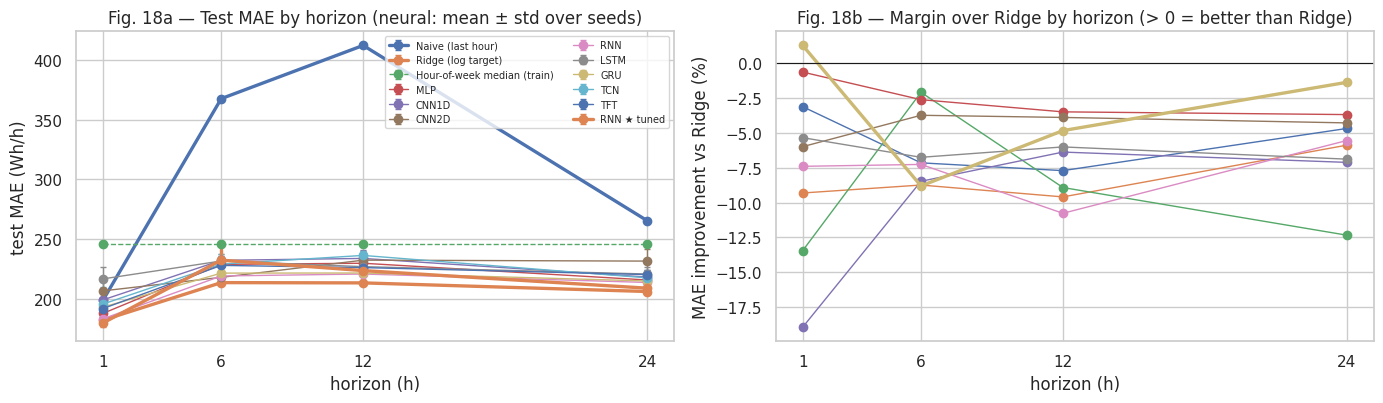

[timer] section 10.3 table done: 38.7 min since the Stage-3 timer started


In [32]:
BASE_TEST_H, RIDGE_TEST_H = {}, {}
for h in HORIZONS:
    BASE_TEST_H[h] = make_base(h, T_test); RIDGE_TEST_H[h] = ridge_predict(h, "test")
assert np.array_equal(BASE_TEST_H[HORIZON][NAIVE], base[NAIVE]["test"]) and np.allclose(RIDGE_TEST_H[HORIZON], ridge_pred["test"])      # h=1 reproduces Stage 2
def mean_std(vals): return float(np.mean(vals)), float(np.std(vals, ddof=0))
rows_h = []
for h in HORIZONS:
    nv, rd = metrics(Y_test, BASE_TEST_H[h][NAIVE]), metrics(Y_test, RIDGE_TEST_H[h])
    entries_h = [(nm, [metrics(Y_test, p)] , 0, "—") for nm, p in BASE_TEST_H[h].items()] + [("Ridge (log target)", [rd], 0, f"L={RIDGE_H[h]['L']}, alpha={RIDGE_H[h]['alpha']}")]
    for label, _, cfg in entries:
        ms = [metrics(Y_test, p["test"]) for p in PRED[(h, label)]]; entries_h.append((label, ms, PRED[(h, label)][0]["params"], json.dumps(cfg)))
    for nm, ms, npar, cf in entries_h:
        mae_m, mae_s = mean_std([m["MAE"] for m in ms]); rmse_m, rmse_s = mean_std([m["RMSE"] for m in ms])
        vmae = (np.mean([metrics(Y_val, p["val"])["MAE"] for p in PRED[(h, nm)]]) if (h, nm) in PRED else np.nan)
        rows_h.append(dict(horizon_h=h, model=nm, params=npar, config=cf, val_MAE=vmae, test_MAE=mae_m, test_MAE_std=mae_s, test_RMSE=rmse_m, test_RMSE_std=rmse_s,
                           MAE_vs_naive_pct=100 * (nv["MAE"] - mae_m) / nv["MAE"], MAE_vs_Ridge_pct=100 * (rd["MAE"] - mae_m) / rd["MAE"],
                           RMSE_vs_naive_pct=100 * (nv["RMSE"] - rmse_m) / nv["RMSE"], RMSE_vs_Ridge_pct=100 * (rd["RMSE"] - rmse_m) / rd["RMSE"]))
hz = pd.DataFrame(rows_h); hz.to_csv(f"{OUT3}/table18_multihorizon_test.csv", index=False)
print(f"Table 18 — Test results by horizon (Wh/h, {len(T_test)} test hours; neural rows = mean over {len(FINAL_SEEDS)} seeds; improvement > 0 = better than the reference). Naive == seasonal naive at h in {COINCIDE}")
for h in HORIZONS:
    print(f"\n--- horizon {h} h ---"); display(hz[hz.horizon_h == h].drop(columns=["horizon_h", "config"]).sort_values("test_MAE").round(2).reset_index(drop=True))

NN_LABELS = [l for l, _, _ in entries]; fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for nm in [NAIVE, "Ridge (log target)", "Hour-of-week median (train)"] + NN_LABELS:
    g = hz[hz.model == nm].sort_values("horizon_h"); lw, ls_ = (2.4, "-") if nm in (NAIVE, "Ridge (log target)", FINAL_LABEL) else (1.0, "--" if nm.startswith("Hour") else "-")
    axs[0].errorbar(g.horizon_h, g.test_MAE, yerr=g.test_MAE_std, marker="o", lw=lw, ls=ls_, capsize=2, label=nm)
    if nm in NN_LABELS: axs[1].plot(g.horizon_h, g.MAE_vs_Ridge_pct, marker="o", lw=lw, label=nm)
axs[0].set_xticks(HORIZONS); axs[0].set_xlabel("horizon (h)"); axs[0].set_ylabel("test MAE (Wh/h)"); axs[0].legend(fontsize=7, ncol=2); axs[0].set_title("Fig. 18a — Test MAE by horizon (neural: mean ± std over seeds)")
axs[1].axhline(0, color="k", lw=0.8); axs[1].set_xticks(HORIZONS); axs[1].set_xlabel("horizon (h)"); axs[1].set_ylabel("MAE improvement vs Ridge (%)"); axs[1].set_title("Fig. 18b — Margin over Ridge by horizon (> 0 = better than Ridge)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig18_multihorizon.png", dpi=150); plt.show()
tick("section 10.3 table done")

Table 19 — Paired block bootstrap by horizon (2000 resamples, 24 h blocks, seed-42 predictions; same resampling indices as Table 9). rel_pct > 0 = model better than reference


,horizon_h,model,reference,MAE_diff_Wh,CI_lo,CI_hi,rel_pct,rel_lo,rel_hi,P_better,significant
0,1,Ridge (log target),naive,16.660,2.527,30.380,8.379,1.210,14.800,0.994,True
1,1,MLP,naive,12.396,-4.095,27.378,6.235,-2.098,13.677,0.934,False
2,1,MLP,Ridge (log target),-4.264,-11.011,1.926,-2.340,-5.909,1.138,0.088,False
3,1,CNN1D,naive,6.414,-14.434,24.806,3.226,-6.682,12.824,0.748,False
4,1,CNN1D,Ridge (log target),-10.246,-21.334,-0.141,-5.624,-10.462,-0.088,0.024,True
...,...,...,...,...,...,...,...,...,...,...,...
71,24,TCN,Ridge (log target),-4.879,-13.769,3.398,-2.367,-6.875,1.716,0.139,False
72,24,TFT,naive,44.240,14.717,78.083,16.665,5.736,28.669,0.998,True
73,24,TFT,Ridge (log target),-15.090,-29.984,-0.571,-7.320,-14.223,-0.310,0.020,True
74,24,RNN ★ tuned,naive,58.151,26.549,95.878,21.905,10.539,33.681,1.000,True


Summary by horizon (counts of neural rows whose 95% interval excludes zero):


,models_better_than_Ridge_CI_excl_0,models_worse_than_Ridge_CI_excl_0,n_models,models_better_than_naive_CI_excl_0,Ridge_better_than_naive_CI_excl_0
horizon_h,,,,,
1,0,3,9,2,True
6,0,4,9,9,True
12,0,3,9,9,True
24,0,5,9,8,True


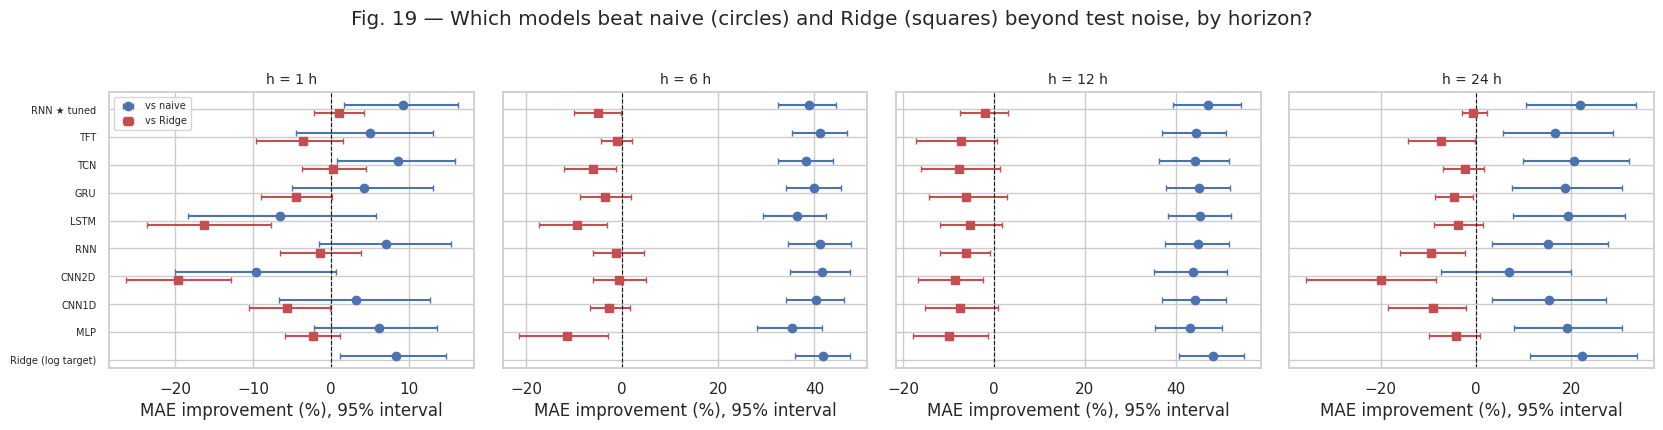

[timer] section 10.3 bootstrap done: 38.8 min since the Stage-3 timer started


In [33]:
def seed_pred(h, label, s=SEED): return next(p for p in PRED[(h, label)] if p["seed"] == s)["test"]
rows_bh2 = []
for h in HORIZONS:
    e_naive = np.abs(BASE_TEST_H[h][NAIVE] - Y_test); e_ridge = np.abs(RIDGE_TEST_H[h] - Y_test)
    rows_bh2.append(dict(horizon_h=h, model="Ridge (log target)", reference="naive", **paired_ci(e_naive, e_ridge)))
    for label in NN_LABELS:
        e_m = np.abs(seed_pred(h, label) - Y_test)
        rows_bh2.append(dict(horizon_h=h, model=label, reference="naive", **paired_ci(e_naive, e_m)))
        rows_bh2.append(dict(horizon_h=h, model=label, reference="Ridge (log target)", **paired_ci(e_ridge, e_m)))
bh = pd.DataFrame(rows_bh2); bh["significant"] = (bh.CI_lo > 0) | (bh.CI_hi < 0); bh.to_csv(f"{OUT3}/table19_bootstrap_by_horizon.csv", index=False)
print(f"Table 19 — Paired block bootstrap by horizon ({N_BOOT} resamples, {BOOT_BLOCK} h blocks, seed-{SEED} predictions; same resampling indices as Table 9). rel_pct > 0 = model better than reference")
display(bh.round(3))
summ = (bh[bh.reference != "naive"].assign(ref="Ridge").groupby("horizon_h").apply(lambda g: pd.Series(dict(models_better_than_Ridge_CI_excl_0=int((g.CI_lo > 0).sum()),
        models_worse_than_Ridge_CI_excl_0=int((g.CI_hi < 0).sum()), n_models=len(g)))))
summ["models_better_than_naive_CI_excl_0"] = bh[(bh.reference == "naive") & (bh.model != "Ridge (log target)")].groupby("horizon_h").apply(lambda g: int((g.CI_lo > 0).sum()))
summ["Ridge_better_than_naive_CI_excl_0"] = bh[(bh.reference == "naive") & (bh.model == "Ridge (log target)")].set_index("horizon_h").CI_lo.gt(0)
print("Summary by horizon (counts of neural rows whose 95% interval excludes zero):"); display(summ)

fig, axs = plt.subplots(1, len(HORIZONS), figsize=(4.2 * len(HORIZONS), 4.2), sharex=False)
for ax, h in zip(axs, HORIZONS):
    g = bh[(bh.horizon_h == h) & (bh.reference == "naive")].reset_index(drop=True); gr = bh[(bh.horizon_h == h) & (bh.reference != "naive")].set_index("model")
    ax.errorbar(g.rel_pct, np.arange(len(g)) + 0.15, xerr=[g.rel_pct - g.rel_lo, g.rel_hi - g.rel_pct], fmt="o", capsize=2, label="vs naive")
    gg = g[g.model != "Ridge (log target)"]
    ax.errorbar(gr.loc[gg.model].rel_pct, gg.index.values - 0.15, xerr=[gr.loc[gg.model].rel_pct - gr.loc[gg.model].rel_lo, gr.loc[gg.model].rel_hi - gr.loc[gg.model].rel_pct],
                fmt="s", capsize=2, color="C3", label="vs Ridge")
    ax.axvline(0, color="k", ls="--", lw=0.8); ax.set_yticks(range(len(g))); ax.set_yticklabels(g.model if h == HORIZONS[0] else [""] * len(g), fontsize=7)
    ax.set_title(f"h = {h} h", fontsize=10); ax.set_xlabel("MAE improvement (%), 95% interval")
axs[0].legend(fontsize=7); fig.suptitle("Fig. 19 — Which models beat naive (circles) and Ridge (squares) beyond test noise, by horizon?", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT3}/fig19_bootstrap_by_horizon.png", dpi=150, bbox_inches="tight"); plt.show()
tick("section 10.3 bootstrap done")

## 11. Reproducibility smoke test
Reloads the checkpoint and the pickled preprocessing state, rebuilds features **from the raw hourly table** (not from cached arrays), and checks the predictions match the stored finalist test predictions. Runs in seconds; with `QUICK=1` the whole notebook runs end-to-end in a few minutes.

In [34]:
ck = torch.load(f"{CK}_finalist.pt", map_location=DEVICE, weights_only=False)
pp = pickle.load(open(f"{CK}_preprocessing.pkl", "rb"))
m2 = build(ck["family"], ck["config"]); m2.load_state_dict(ck["state_dict"])
Xr2 = dh[pp["feat_cols"]].copy()
for c in pp["log_cols"]: Xr2[c] = np.log1p(Xr2[c])
A2 = np.hstack([pp["x_scaler"].transform(pp["imputer"].transform(Xr2)), cal]).astype(np.float32)
L2 = ck["config"]["window"]; Ts = T_test[:50]; idx = (Ts - ck["horizon"])[:, None] + np.arange(-L2 + 1, 1)[None, :]
X2 = np.concatenate([A2[idx], np.repeat(cal[Ts][:, None, :], L2, axis=1)], axis=2).astype(np.float32)
p2 = np.clip(np.expm1(pp["y_scaler"].inverse_transform(predict_scaled(m2, torch.from_numpy(X2).to(DEVICE)).reshape(-1, 1)).ravel()), 0, None)
assert np.allclose(p2, FINAL_TEST_PRED[:50], rtol=1e-3, atol=1e-2), np.abs(p2 - FINAL_TEST_PRED[:50]).max()
print(f"Smoke test passed ✔  {ck['family']} {ck['config']} reproduces stored predictions (max |Δ| = {np.abs(p2 - FINAL_TEST_PRED[:50]).max():.2e} Wh/h)")

Smoke test passed ✔  RNN {'window': 24, 'dropout': 0.1, 'lr': 0.00035, 'batch': 32, 'wd': 0.0, 'loss': 'L1', 'hidden': 128, 'layers': 1} reproduces stored predictions (max |Δ| = 2.03e-04 Wh/h)


In [35]:
# Reproducibility smoke test v2 (Stage 3): every horizon, rebuilt from the RAW hourly table and the pickled preprocessing state, never from cached arrays
pp = pickle.load(open(f"{CK}_preprocessing.pkl", "rb")); assert pp["horizons"] == HORIZONS and pp["target_time_calendar"]
Xr3 = dh[pp["feat_cols"]].copy()
for c_ in pp["log_cols"]: Xr3[c_] = np.log1p(Xr3[c_])
A3 = np.hstack([pp["x_scaler"].transform(pp["imputer"].transform(Xr3)), cal_from_ts(dh["date"])]).astype(np.float32)        # calendar recomputed from timestamps
rows_sm = []
for h in HORIZONS:
    ck_h = torch.load(f"{CK}_finalist.pt" if h == HORIZON else f"{CK}_finalist_h{h}.pt", map_location=DEVICE, weights_only=False)
    m3 = build(ck_h["family"], ck_h["config"]); m3.load_state_dict(ck_h["state_dict"])
    L3 = ck_h["config"]["window"]; Ts = T_test[:50]; idx3 = (Ts - h)[:, None] + np.arange(-L3 + 1, 1)[None, :]
    X3 = np.concatenate([A3[idx3], np.repeat(cal_from_ts(dh["date"].iloc[Ts])[:, None, :], L3, axis=1)], axis=2).astype(np.float32)
    p3 = np.clip(np.expm1(pp["y_scaler"].inverse_transform(predict_scaled(m3, torch.from_numpy(X3).to(DEVICE)).reshape(-1, 1)).ravel()), 0, None)
    ref3 = seed_pred(h, FINAL_LABEL)[:50]; dmax = float(np.abs(p3 - ref3).max())
    assert np.allclose(p3, ref3, rtol=1e-3, atol=1e-2), (h, dmax)
    rows_sm.append(dict(horizon_h=h, family=ck_h["family"], window=L3, max_abs_diff_Wh=dmax, passed=True))
print("Smoke test v2 passed ✔ for every horizon (finalist reloaded from checkpoint, features rebuilt from raw data):"); display(pd.DataFrame(rows_sm))
tick("smoke test v2 done")

Smoke test v2 passed ✔ for every horizon (finalist reloaded from checkpoint, features rebuilt from raw data):


,horizon_h,family,window,max_abs_diff_Wh,passed
0,1,RNN,24,0.000203,True
1,6,RNN,24,0.000321,True
2,12,RNN,24,0.000148,True
3,24,RNN,24,0.000177,True


[timer] smoke test v2 done: 38.8 min since the Stage-3 timer started


## 12. Results summary (auto-generated from the run above)

In [36]:
fr = cmp_[cmp_.Model == FINAL_LABEL].iloc[0]; rr = cmp_[cmp_.Model.str.startswith("Ridge")].iloc[0]
rank = cmp_.sort_values("test_MAE").Model.tolist()
print(f"Target: next-hour appliance energy (Wh/h), log1p-trained. Test hours: {len(T_test)} ({dh.date[T_test[0]].date()} → {dh.date[T_test[-1]].date()})")
print(f"Naive test MAE {BASE_TEST['MAE']:.2f} / RMSE {BASE_TEST['RMSE']:.2f}")
print(f"Finalist {FINAL_LABEL} {ckpt['config']}: test MAE {fr.test_MAE:.2f} ± {fr.test_MAE_std:.2f} ({fr['MAE_improv_%']:+.1f}% vs naive), "
      f"RMSE {fr.test_RMSE:.2f} ± {fr.test_RMSE_std:.2f} ({fr['RMSE_improv_%']:+.1f}%), {int(fr.Params)} params, {fr.Train_s:.1f} s train, "
      f"{fr.Infer_ms_single:.3f} ms latency")
print(f"Ridge: test MAE {rr.test_MAE:.2f} ({rr['MAE_improv_%']:+.1f}%), RMSE {rr.test_RMSE:.2f} ({rr['RMSE_improv_%']:+.1f}%)")
print("Ranking by test MAE:", " > ".join(rank))
nn_val_rank = cmp_[cmp_.Model.isin(final.keys())].sort_values("val_MAE").Model.tolist()
nn_test_rank = cmp_[cmp_.Model.isin(final.keys())].sort_values("test_MAE").Model.tolist()
print("NN ranking (val):", nn_val_rank, "\nNN ranking (test):", nn_test_rank)
best_nn = cmp_[cmp_.Model.isin(final.keys())].sort_values("test_MAE").iloc[0]
print(f"Best neural model by test MAE: {best_nn.Model} {best_nn.test_MAE:.2f}; Ridge {rr.test_MAE:.2f} -> Ridge is "
      f"{'better' if rr.test_MAE < best_nn.test_MAE else 'worse'} by {abs(rr.test_MAE-best_nn.test_MAE):.2f} Wh/h MAE and {abs(rr.test_RMSE-best_nn.test_RMSE):.2f} Wh/h RMSE")


Target: next-hour appliance energy (Wh/h), log1p-trained. Test hours: 658 (2016-04-30 → 2016-05-27)
Naive test MAE 198.83 / RMSE 372.23
Finalist RNN ★ tuned {'window': 24, 'dropout': 0.1, 'lr': 0.00035, 'batch': 32, 'wd': 0.0, 'loss': 'L1', 'hidden': 128, 'layers': 1}: test MAE 179.80 ± 3.49 (+9.6% vs naive), RMSE 349.81 ± 9.06 (+6.0%), 21377 params, 6.3 s train, 0.291 ms latency
Ridge: test MAE 182.17 (+8.4%), RMSE 339.46 (+8.8%)
Ranking by test MAE: RNN ★ tuned > Ridge (log target) > RNN > MLP > TFT > GRU > TCN > Naive (last hour) > CNN1D > CNN2D > LSTM > Hour-of-week median (train) > Seasonal naive (t-24 h)
NN ranking (val): ['RNN', 'RNN ★ tuned', 'GRU', 'MLP', 'TCN', 'TFT', 'CNN1D', 'LSTM', 'CNN2D'] 
NN ranking (test): ['RNN ★ tuned', 'RNN', 'MLP', 'TFT', 'GRU', 'TCN', 'CNN1D', 'CNN2D', 'LSTM']
Best neural model by test MAE: RNN ★ tuned 179.80; Ridge 182.17 -> Ridge is worse by 2.37 Wh/h MAE and 10.35 Wh/h RMSE


## 13. Stage 2 conclusions (ARCHIVED: hard-coded text written after the Stage-2 run; the Stage-3 conclusions in section 21 are generated from the new run)

**Headline.** Predicting next-hour appliance energy (Wh/h) is only modestly learnable from this record. The best neural model, the **RNN** (24 h window, 2 layers × 64 units, 14,913 parameters), beats the naive last-hour forecast by **6.6% on MAE**, but a **109-parameter Ridge regression on the same log target is as good or better** (MAE +8.4%, RMSE +8.8% vs naive). Neither difference is large relative to test-set noise (Table 9). The 2D CNN added in this revision did not change that picture.

### Test-set summary (Table 8; 658 test hours; neural rows are mean ± std over 5 seeds)

| Model | Params | Test MAE (Wh/h) | MAE vs naive | Test RMSE (Wh/h) | RMSE vs naive |
|---|---:|---:|---:|---:|---:|
| **Ridge (log target)** | 109 | **182.17** | **+8.4%** | **339.46** | **+8.8%** |
| **RNN ★ finalist** | 14,913 | 185.65 ± 2.44 | +6.6% | 367.95 ± 6.41 | +1.2% |
| MLP | 16,001 | 189.30 ± 3.34 | +4.8% | 364.34 ± 13.21 | +2.1% |
| GRU | 44,609 | 194.67 ± 2.31 | +2.1% | 386.86 ± 6.08 | −3.9% |
| TCN | 4,705 | 194.71 ± 11.88 | +2.1% | 379.35 ± 16.59 | −1.9% |
| **CNN2D** | 37,697 | 199.70 ± 6.18 | −0.4% | 373.71 ± 10.36 | −0.4% |
| Naive (last hour) | 0 | 198.83 | 0.0% | 372.23 | 0.0% |
| LSTM | 8,993 | 214.95 ± 10.21 | −8.1% | 421.52 ± 15.21 | −13.2% |
| **CNN1D** | 26,209 | 219.03 ± 9.57 | −10.2% | 417.78 ± 16.89 | −12.2% |

*Positive = better than naive. Seasonal-naive (265.47) and hour-of-week median (246.29) were worse than naive and are omitted for space.*

### Findings

1. **Target redesign.** At the native 10-minute resolution nothing beat persistence on MAE (Stage 1: naive 26.65 Wh vs best network 31.58 Wh, i.e. −18.5%). Moving to hourly totals with a log1p-standardised target flips this: the best network is now +6.6% better than naive and Ridge +8.4% (Table 1 / §2). The hourly target smooths sub-hour spikes that no model can anticipate. The Stage 1 and Stage 2 percentages are comparable; the raw Wh values are not (10-min vs hourly).

2. **Controlled comparison (Stage A, validation).** The RNN had the lowest validation MAE (190.99 ± 1.52), followed by TCN (193.41 ± 0.21), MLP (193.96 ± 3.36) and GRU (194.05 ± 3.26). These four lie within about 3 Wh/h, comparable to seed spread, so their order is not decisive. CNN1D (199.40), CNN2D (201.84) and LSTM (202.28) are clearly behind. The RNN and GRU preferred the longest (24 h) window; the MLP, TCN, both CNNs and LSTM preferred 6 h (Table 5, Fig. 7b).

3. **1D vs 2D CNN.**
   - *Validation:* indistinguishable (CNN1D 199.40 ± 0.45 vs CNN2D 201.84 ± 4.96).
   - *Test, 5 seeds:* CNN2D averaged 199.70 ± 6.18 vs 219.03 ± 9.57 for CNN1D, about 19 Wh/h better, roughly two seed-standard-deviations. CNN2D is level with naive (−0.4%), while CNN1D is 10.2% worse.
   - *Paired seed-42 bootstrap:* no significant difference (CNN2D − CNN1D = −2.3 Wh/h, 95% interval −16.1 to +12.5; Table 9). The seed-42 pair does not reproduce the 5-seed gap, so the evidence that 2D convolution helps is suggestive, not established.
   - *Cost:* CNN2D has 44% more parameters (37,697 vs 26,209) and about 4× the batched inference time per sample (0.035 vs 0.009 ms).
   - *Overall:* both convolutional families are outperformed by the MLP and the recurrent models. A plausible (untested) reason is that the preferred windows are short (6 h) and the training set is small (1,949 windows), so local-pattern filters have little structure to exploit.

4. **Hyperparameter search (Stage B, 30 trials).** The best trial (#14: 3 h window, 2 × 128, no dropout) reached 189.78 ± 2.16 vs 190.99 ± 1.07 for the Stage-A anchor, a 1.2 Wh/h gain that is about one seed-std. The parsimony rule therefore kept the anchor, and the finalist is reported once. Tuning added no reliable gain (Table 6/7, Fig. 8a). In the top-10 trials, L1 loss, low dropout (≤ 0.1 in most) and little or no weight decay were common, while window length (3–24 h) and depth (1–3 layers) varied with similar scores. This is from 30 random trials, not a controlled ablation.

5. **Validation ranking vs test.** Among the neural models the validation ranking mostly held on test. The order was RNN > MLP > GRU > TCN on both, and only CNN2D and LSTM swapped places. Ridge is the exception: it was worse than the RNN on validation (198.42 vs 190.99) but better on test (182.17 vs 185.65). The finalist-vs-Ridge MAE difference is within noise (−2.9 Wh/h, 95% interval −12.7 to +6.6), but Ridge's RMSE is clearly lower (339 vs 368). Accuracy–cost trade-off (Fig. 9a): Ridge costs 109 parameters and 0.0008 ms per sample; the RNN costs 14,913 parameters and 0.42 ms single-sample latency.

6. **How certain are these differences? (Table 9, Fig. 11).** With 24-hour block-bootstrap intervals, only Ridge (+8.4%, 95% interval +1.2% to +14.8%) and the seed-42 TCN (+9.0%, +0.1% to +16.5%) exclude zero against naive. The RNN finalist's +6.9% (seed 42) has an interval from −2.0% to +15.6%. The TCN result is a favourable seed: its 5-seed mean is only +2.1% with a std of 11.9 Wh/h, so we do not treat it as evidence that TCN is better. In short, **no neural model is reliably better than naive on this test set**.

7. **Validation → test shift (Table 10).** The test period is much warmer than the earlier periods (mean outdoor temperature 13.6 °C vs 8.6 °C validation and 5.0 °C train) and calmer (target std 423 vs 497 validation and 503 train). The naive MAE falls from 251 (train) to 229 (validation) to 199 (test), so a test period that is easier for persistence makes every margin over naive harder to achieve and the absolute MAEs not comparable across splits.

8. **Where the finalist fails (Fig. 10).** Forecasts are damped: the largest peaks are under-predicted (the ~2,900 Wh/h spike on the first test day is forecast at about 1,300). By hour of day (Fig. 10c) the RNN is worse than naive around the evening ramp-up (hour 17: roughly 650 vs 530 Wh/h MAE) and slightly worse at hours 10–11, 13 and 15. It is clearly better after the peak (hours 18–23, e.g. about 320 vs 550 at hour 18), where persistence repeats a spike that has already ended.

### Risks and limitations
- **Short record.** About 4.5 months in total, 1,949 training hours and a single test month (2016-04-30 to 2016-05-27). One season of testing says little about winter or summer behaviour.
- **Wide uncertainty.** The bootstrap intervals are wide, and the seed std of several models (LSTM, TCN, CNN1D) is 10 Wh/h or more.
- **Hardware.** This revision was executed on CPU (not the original GPU), so numbers differ slightly from the earlier run (e.g. the RNN's test MAE is 185.65 here vs 184.60 before). Conclusions are unchanged.
- **Model-selection caveat.** Stage B tuned only the RNN family, so the other families had less tuning effort. Their Stage-A configurations came from a 12-config grid with equal budget per family.

### Recommendations for Stage 3
1. **Keep Ridge as the benchmark to beat** and report improvements against it as well as against naive. Any Stage 3 model should show a bootstrap interval that clears both.
2. **Add the Transformer under the same protocol**, but expect small gains given the data size. Consider a gradient-boosted tree model as a stronger classical baseline.
3. **Target the failure regime.** The error is concentrated in evening peaks. Options include a loss that does not shrink spikes (quantile or asymmetric), explicit hour-of-week features for peak timing, and prediction intervals instead of single point forecasts.
4. **More data or more test periods.** Use rolling-origin evaluation across several test months if the dataset allows.
5. **Deployment.** If a Jetson deployment is pursued, Ridge is the cheapest option and the RNN checkpoint (`checkpoints/stage2_finalist.pt`) is available if sequence modelling is wanted; the reproducibility test in §11 passed.


## 14. Residual spectrum, error by frequency band, and what the Transformer attends to
**Questions.** (i) Do the finalist's residuals still contain daily structure (residual ACF and spectrum, h = 1, test)? (ii) In which frequency band does the finalist beat naive and Ridge, and in which does it not? (iii) Does the Transformer's attention concentrate on the lag that matches the daily cycle?

**Method.**
* *Residuals* are `log1p(y) − log1p(ŷ)` on the 658 test hours (seed-42 predictions). ACF with a Ljung-Box test at lag 24 (descriptive: the hours are autocorrelated and the model was not fitted to be white). Welch spectra (168 h segments, so 24, 12 and 8 h fall on bins) of the target and of each model's residuals; the ratio residual/target power at a period is the share of that cycle the model leaves unexplained.
* *Error by frequency band.* Band edges come from the **training** spectrum (§4.1, geometric midpoints between significant periods). Because the filter is linear, the error series is split with an FFT mask into the same bands as the target; the bands are orthogonal, so their mean squares add up to the total. Skill in a band = `1 − MS_model / MS_reference`. This is a diagnostic on the *error* (it uses the whole test span, so it is not a forecasting filter). The FFT assumes the 658-hour span is periodic, so the slowest band is the least reliable.
* *Attention.* The `TFTLite` decoder token attends over the L encoder steps. Step j of a window at horizon h sits at **lag h + L − 1 − j hours before the target**, so lag 24 (same hour yesterday, the daily cycle) is inside the window iff `h ≤ 24 ≤ h + L − 1`. The Stage-A/B Transformer may have a window shorter than 24 h; to answer the question for the daily lag, a **diagnostic** TFT with window 24 (its other hyper-parameters = the validation-best Stage-A TFT configuration) is also trained on the training set for every horizon (2 seeds). It is *not* a candidate and is never used for selection. Attention weights are not causal explanations; they only show where the model *reads*.

Table 20 — Residual diagnostics, h=1, test (n=658; ACF 95% bound ±0.076; resid/target power < 1 = cycle partly explained, > 1 = model ADDS power at that period)


,model,mean_log_residual,acf_lag1,acf_lag24,max_abs_acf_lags_1_48,lags_outside_95pct_band,ljung_box_p_lag24,resid_to_target_power_24h,resid_to_target_power_12h,resid_to_target_power_8h
0,Naive,0.002,-0.220,0.215,0.220,7,0.0,0.068,0.263,0.583
1,Ridge,0.021,0.184,0.238,0.238,5,0.0,0.071,0.233,0.891
2,RNN ★ tuned,0.019,0.203,0.219,0.219,8,0.0,0.114,0.256,0.338
3,TFT,0.076,0.358,0.239,0.358,19,0.0,0.132,0.253,0.389


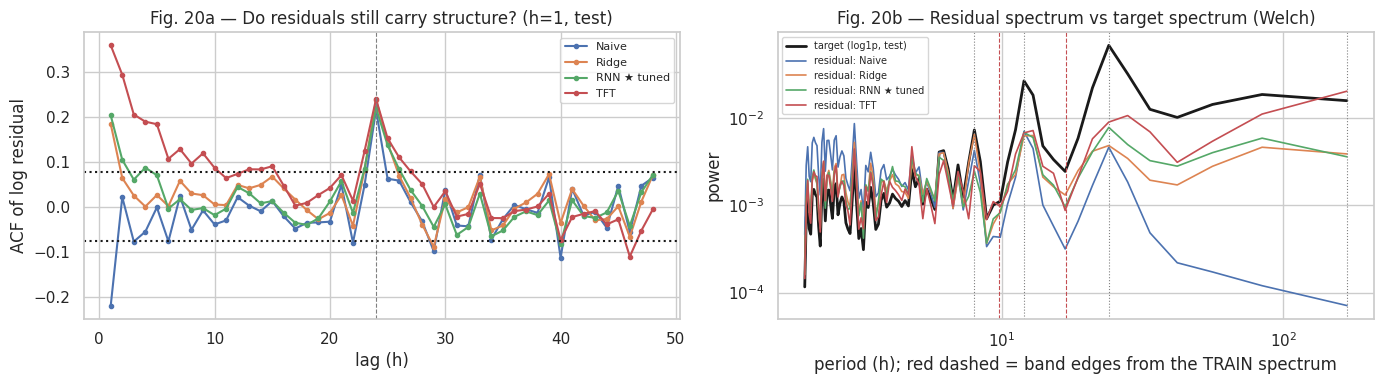

[timer] section 14.1 done: 38.8 min since the Stage-3 timer started


In [37]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf as sm_acf
LOGP = lambda p: np.log1p(np.clip(p, 0, None))
RES_MODELS = {"Naive": BASE_TEST_H[1][NAIVE], "Ridge": RIDGE_TEST_H[1], FINAL_LABEL: seed_pred(1, FINAL_LABEL)}
if TFT_LABEL != FINAL_LABEL: RES_MODELS[TFT_LABEL] = seed_pred(1, TFT_LABEL)
ylog_te = np.log1p(Y_test); resid = {k: ylog_te - LOGP(p) for k, p in RES_MODELS.items()}
NLAG, nT_ = 48, len(ylog_te); bound = 1.96 / np.sqrt(nT_)
f_r, P_tgt = signal.welch(ylog_te - ylog_te.mean(), fs=1.0, window="hann", nperseg=168, noverlap=84, detrend="linear", scaling="spectrum")
spec_res = {k: signal.welch(r - r.mean(), fs=1.0, window="hann", nperseg=168, noverlap=84, detrend="linear", scaling="spectrum")[1] for k, r in resid.items()}
rows_r = []
for k, r in resid.items():
    a = sm_acf(r, nlags=NLAG, fft=True); lb = acorr_ljungbox(r, lags=[24], return_df=True)
    row = dict(model=k, mean_log_residual=r.mean(), acf_lag1=a[1], acf_lag24=a[24], max_abs_acf_lags_1_48=np.abs(a[1:]).max(),
               lags_outside_95pct_band=int((np.abs(a[1:]) > bound).sum()), ljung_box_p_lag24=float(lb.lb_pvalue.iloc[0]))
    for per in (24, 12, 8): row[f"resid_to_target_power_{per}h"] = spec_res[k][int(round(168 / per))] / P_tgt[int(round(168 / per))]
    rows_r.append(row)
res_tab = pd.DataFrame(rows_r); res_tab.to_csv(f"{OUT3}/table20_residual_diagnostics.csv", index=False)
print(f"Table 20 — Residual diagnostics, h=1, test (n={nT_}; ACF 95% bound ±{bound:.3f}; resid/target power < 1 = cycle partly explained, > 1 = model ADDS power at that period)")
display(res_tab.round(3))
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for k, r in resid.items(): axs[0].plot(range(1, NLAG + 1), sm_acf(r, nlags=NLAG, fft=True)[1:], marker=".", label=k)
axs[0].axhline(bound, color="k", ls=":"); axs[0].axhline(-bound, color="k", ls=":"); axs[0].axvline(24, color="gray", ls="--", lw=0.8)
axs[0].set_xlabel("lag (h)"); axs[0].set_ylabel("ACF of log residual"); axs[0].legend(fontsize=8); axs[0].set_title("Fig. 20a — Do residuals still carry structure? (h=1, test)")
axs[1].loglog(1 / f_r[1:], P_tgt[1:], "k", lw=2, label="target (log1p, test)")
for k, p in spec_res.items(): axs[1].loglog(1 / f_r[1:], p[1:], lw=1.2, label=f"residual: {k}")
for per in (168, 24, 12, 8): axs[1].axvline(per, color="gray", ls=":", lw=0.8)
for e_ in BAND_EDGES_H: axs[1].axvline(e_, color="r", ls="--", lw=0.8)
axs[1].set_xlabel("period (h); red dashed = band edges from the TRAIN spectrum"); axs[1].set_ylabel("power"); axs[1].legend(fontsize=7); axs[1].set_title("Fig. 20b — Residual spectrum vs target spectrum (Welch)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig20_residual_acf_spectrum.png", dpi=150); plt.show()
tick("section 14.1 done")

Table 21 — Mean-square log error by frequency band (h=1, test; bands from the TRAIN spectrum; skill > 0 = lower error than the reference in that band)


model,target_power_share_%,Naive,RNN ★ tuned,Ridge,TFT,Naive: error_share_%,Ridge: error_share_%,RNN ★ tuned: error_share_%,TFT: error_share_%,Ridge: skill_vs_naive,RNN ★ tuned: skill_vs_naive,RNN ★ tuned: skill_vs_Ridge,TFT: skill_vs_naive,TFT: skill_vs_Ridge
band,,,,,,,,,,,,,,
period > 17 h,57.369,0.007,0.031,0.025,0.056,4.462,18.128,22.621,35.534,-2.414,-3.158,-0.218,-6.594,-1.225
10-17 h,16.171,0.012,0.016,0.016,0.018,7.388,11.827,11.644,11.240,-0.345,-0.293,0.039,-0.451,-0.079
period < 10 h,26.460,0.146,0.089,0.097,0.084,88.150,70.045,65.735,53.226,0.332,0.388,0.084,0.424,0.138


Table 21b — RNN ★ tuned: skill by frequency band and horizon


horizon_h,1,6,12,24
skill vs Ridge,,,,
period > 17 h,-0.218,-0.206,-0.356,-0.132
10-17 h,0.039,-0.317,-0.220,0.000
period < 10 h,0.084,-0.003,0.002,-0.003


horizon_h,1,6,12,24
skill vs naive,,,,
period > 17 h,-3.158,0.498,0.740,0.334
10-17 h,-0.293,0.757,-1.209,0.147
period < 10 h,0.388,0.494,0.549,0.427


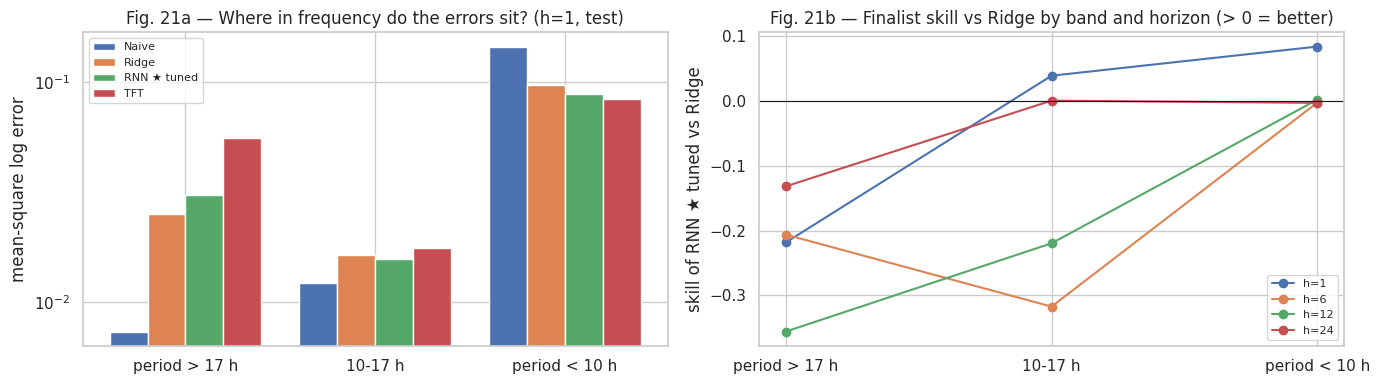

[timer] section 14.2 done: 38.8 min since the Stage-3 timer started


In [38]:
def band_masks(n):
    f = np.fft.rfftfreq(n, d=1.0); per = np.where(f > 0, 1.0 / np.maximum(f, 1e-12), np.inf)
    ub, lb = [np.inf] + BAND_EDGES_H, BAND_EDGES_H + [0.0]
    return [(f > 0) & (per <= u) & (per > l) for u, l in zip(ub, lb)]
def band_ms(x):
    '''Mean square of the demeaned series x in each frequency band (orthogonal FFT masks; they add up to var(x)).'''
    n = len(x); E = np.fft.rfft(x - x.mean()); out = [np.mean(np.fft.irfft(E * m, n) ** 2) for m in band_masks(n)]
    assert abs(sum(out) - np.var(x)) < 1e-6 * max(np.var(x), 1e-12) + 1e-9, "bands must add up to the total variance"
    return np.array(out)
ms_tgt = band_ms(ylog_te)
rows_b2 = []
for k, r in resid.items():
    for bl, v in zip(BAND_LABELS, band_ms(r)): rows_b2.append(dict(model=k, band=bl, mean_square=v))
bt = pd.DataFrame(rows_b2).pivot(index="band", columns="model", values="mean_square").loc[BAND_LABELS]
bt.insert(0, "target_power_share_%", 100 * ms_tgt / ms_tgt.sum())
for k in resid: bt[f"{k}: error_share_%"] = 100 * bt[k] / bt[k].sum()
for k in resid:
    if k != "Naive": bt[f"{k}: skill_vs_naive"] = 1 - bt[k] / bt["Naive"]
    if k not in ("Naive", "Ridge"): bt[f"{k}: skill_vs_Ridge"] = 1 - bt[k] / bt["Ridge"]
bt.to_csv(f"{OUT3}/table21_error_by_frequency_band_h1.csv"); print("Table 21 — Mean-square log error by frequency band (h=1, test; bands from the TRAIN spectrum; skill > 0 = lower error than the reference in that band)")
display(bt.round(3))
# same decomposition for the finalist at every horizon
rows_bh3 = []
for h in HORIZONS:
    rr = {"Naive": ylog_te - LOGP(BASE_TEST_H[h][NAIVE]), "Ridge": ylog_te - LOGP(RIDGE_TEST_H[h]), FINAL_LABEL: ylog_te - LOGP(seed_pred(h, FINAL_LABEL))}
    m_n, m_r, m_f = band_ms(rr["Naive"]), band_ms(rr["Ridge"]), band_ms(rr[FINAL_LABEL])
    for bl, a, b, c in zip(BAND_LABELS, m_n, m_r, m_f): rows_bh3.append(dict(horizon_h=h, band=bl, skill_vs_naive=1 - c / a, skill_vs_Ridge=1 - c / b, finalist_error_share_pct=100 * c / m_f.sum()))
bh3 = pd.DataFrame(rows_bh3); bh3.to_csv(f"{OUT3}/table21b_band_skill_by_horizon.csv", index=False)
print(f"Table 21b — {FINAL_LABEL}: skill by frequency band and horizon"); display(bh3.pivot(index="band", columns="horizon_h", values="skill_vs_Ridge").loc[BAND_LABELS].round(3).rename_axis("skill vs Ridge"))
display(bh3.pivot(index="band", columns="horizon_h", values="skill_vs_naive").loc[BAND_LABELS].round(3).rename_axis("skill vs naive"))
fig, axs = plt.subplots(1, 2, figsize=(14, 4)); xb = np.arange(len(BAND_LABELS)); wd = 0.8 / len(resid)
for i, k in enumerate(resid): axs[0].bar(xb + i * wd, bt[k].values, wd, label=k)
axs[0].set_xticks(xb + 0.4 - wd / 2); axs[0].set_xticklabels(BAND_LABELS); axs[0].set_yscale("log"); axs[0].set_ylabel("mean-square log error"); axs[0].legend(fontsize=8)
axs[0].set_title("Fig. 21a — Where in frequency do the errors sit? (h=1, test)")
for h in HORIZONS:
    g = bh3[bh3.horizon_h == h].set_index("band").loc[BAND_LABELS]; axs[1].plot(xb, g.skill_vs_Ridge.values, marker="o", label=f"h={h}")
axs[1].axhline(0, color="k", lw=0.8); axs[1].set_xticks(xb); axs[1].set_xticklabels(BAND_LABELS); axs[1].set_ylabel(f"skill of {FINAL_LABEL} vs Ridge"); axs[1].legend(fontsize=8)
axs[1].set_title("Fig. 21b — Finalist skill vs Ridge by band and horizon (> 0 = better)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig21_error_by_band.png", dpi=150); plt.show()
tick("section 14.2 done")

Diagnostic TFT (window 24, never a candidate): validation-best Stage-A TFT configuration with window 24 {'window': 24, 'd_model': 32, 'layers': 1, 'heads': 4, 'lr': 0.001, 'wd': 0.0001}
Table 22 — Attention of the decoder token over encoder lags (mean over the 658 test windows; ratio > 1 = lag 24 receives more attention than the average other lag; uniform reference = 1/(L+1)). Diagnostic fits took 1.4 min


,kind,horizon_h,seed,window,lag24_in_window,weight_lag24,mean_weight_other_lags,ratio_lag24_to_others,rank_of_lag24,weight_newest_lag,weight_decoder_token,uniform_reference
0,selected TFT (window 6),1,42,6,False,NaN,0.133,NaN,NaN,0.141,0.201,0.143
1,selected TFT (window 6),6,42,6,False,NaN,0.144,NaN,NaN,0.150,0.133,0.143
2,selected TFT (window 6),12,42,6,False,NaN,0.142,NaN,NaN,0.165,0.146,0.143
3,selected TFT (window 6),24,42,6,True,0.134,0.135,0.990,6.0,0.134,0.190,0.143
4,diagnostic TFT (window 24),1,42,24,True,0.041,0.040,1.035,5.0,0.041,0.043,0.040
5,diagnostic TFT (window 24),1,43,24,True,0.040,0.040,0.987,19.0,0.039,0.037,0.040
6,diagnostic TFT (window 24),6,42,24,True,0.041,0.040,1.021,7.0,0.042,0.033,0.040
7,diagnostic TFT (window 24),6,43,24,True,0.041,0.040,1.021,7.0,0.041,0.045,0.040
8,diagnostic TFT (window 24),12,42,24,True,0.038,0.039,0.974,16.0,0.041,0.055,0.040
9,diagnostic TFT (window 24),12,43,24,True,0.039,0.040,0.983,16.0,0.041,0.037,0.040


,horizon_h,seed,val_MAE,test_MAE
diagnostic TFT accuracy (not used for selection),,,,
0,1,42,203.65,192.91
1,1,43,198.01,190.82
2,6,42,246.88,216.03
3,6,43,240.28,220.26
4,12,42,250.59,220.76
5,12,43,237.71,216.23
6,24,42,254.95,225.91
7,24,43,249.58,219.15


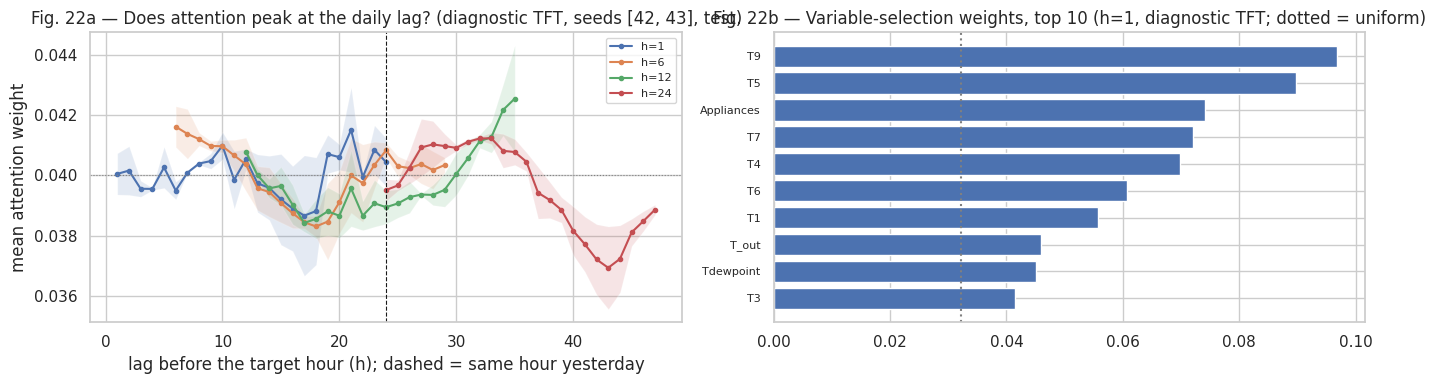

h= 1: weight at lag 24 = 0.040 (uniform 0.040); 1.01x the mean of the other lags; rank 12.0 of 24 (seeds [42, 43]); newest lag (1) weight 0.040
h= 6: weight at lag 24 = 0.041 (uniform 0.040); 1.02x the mean of the other lags; rank 7.0 of 24 (seeds [42, 43]); newest lag (6) weight 0.042
h=12: weight at lag 24 = 0.039 (uniform 0.040); 0.98x the mean of the other lags; rank 16.0 of 24 (seeds [42, 43]); newest lag (12) weight 0.041
h=24: weight at lag 24 = 0.040 (uniform 0.040); 1.00x the mean of the other lags; rank 14.0 of 24 (seeds [42, 43]); newest lag (24) weight 0.040
[timer] section 14.3 done: 40.3 min since the Stage-3 timer started


In [39]:
FEATURE_NAMES = list(feat_cols) + ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "weekend"]            # the 31 past channels seen by the variable-selection layer
TFT_CFG = next(c_ for l_, f_, c_ in entries if f_ == "TFT")
sub_ = agg_A[(agg_A.family == "TFT") & (agg_A.window == 24)].sort_values("val_MAE")
if len(sub_): DIAG_CFG, DIAG_NOTE = json.loads(sub_.iloc[0].cfg), "validation-best Stage-A TFT configuration with window 24"
else:         DIAG_CFG, DIAG_NOTE = {**BEST_A["TFT"], "window": 24}, "QUICK fallback: Stage-A TFT configuration with the window set to 24 (no window-24 config in the QUICK grid)"
DIAG_SEEDS = FINAL_SEEDS[:2]; print("Diagnostic TFT (window 24, never a candidate):", DIAG_NOTE, DIAG_CFG)

@torch.no_grad()
def attention_profile(model, L, h):
    X = tens(L, "test", h)[0]; model.eval(); model.keep_attn = True; at, vs = [], []
    for i in range(0, len(X), 256): model(X[i:i + 256]); at.append(model.last_attn[:, 0, :].cpu()); vs.append(model.last_vsn.cpu())
    model.keep_attn = False; return torch.cat(at).mean(0).numpy(), torch.cat(vs).mean((0, 1)).numpy()          # (L+1,), (31,)
rows_a, prof = [], {}
def add_profile(kind, h, seed, L, model):
    a, v = attention_profile(model, L, h); lags = h + L - 1 - np.arange(L); enc = a[:L]; has24 = 24 in lags
    w24 = enc[list(lags).index(24)] if has24 else np.nan; others = np.delete(enc, list(lags).index(24)) if has24 else enc
    rows_a.append(dict(kind=kind, horizon_h=h, seed=seed, window=L, lag24_in_window=bool(has24), weight_lag24=w24, mean_weight_other_lags=others.mean(),
                       ratio_lag24_to_others=(w24 / others.mean()) if has24 else np.nan, rank_of_lag24=(int((enc > w24).sum()) + 1) if has24 else np.nan,
                       weight_newest_lag=enc[-1], weight_decoder_token=a[L], uniform_reference=1 / (L + 1)))
    prof[(kind, h, seed)] = (lags, a, v)
for h in HORIZONS: add_profile(f"selected TFT (window {TFT_CFG['window']})", h, SEED, TFT_CFG["window"], MODELS[(h, TFT_LABEL)])
t_att = time.time(); diag_perf = []
for h in HORIZONS:
    for s in DIAG_SEEDS:
        r = run_config("TFT", DIAG_CFG, s, h); add_profile("diagnostic TFT (window 24)", h, s, 24, r["model"])
        diag_perf.append(dict(horizon_h=h, seed=s, val_MAE=r["val"]["MAE"], test_MAE=metrics(Y_test, inv(predict_scaled(r["model"], tens(24, "test", h)[0])))["MAE"]))
att = pd.DataFrame(rows_a); att.to_csv(f"{OUT3}/table22_attention_by_lag.csv", index=False)
print(f"Table 22 — Attention of the decoder token over encoder lags (mean over the {len(T_test)} test windows; ratio > 1 = lag 24 receives more attention than the average other lag; "
      f"uniform reference = 1/(L+1)). Diagnostic fits took {(time.time() - t_att) / 60:.1f} min"); display(att.round(3))
display(pd.DataFrame(diag_perf).round(2).rename_axis("diagnostic TFT accuracy (not used for selection)"))
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for h in HORIZONS:
    ps = [prof[("diagnostic TFT (window 24)", h, s)] for s in DIAG_SEEDS]; lags = ps[0][0]; A_ = np.stack([p[1][:24] for p in ps])
    axs[0].plot(lags, A_.mean(0), marker=".", label=f"h={h}"); axs[0].fill_between(lags, A_.min(0), A_.max(0), alpha=0.15)
axs[0].axvline(24, color="k", ls="--", lw=0.8); axs[0].axhline(1 / 25, color="gray", ls=":", lw=0.8); axs[0].set_xlabel("lag before the target hour (h); dashed = same hour yesterday")
axs[0].set_ylabel("mean attention weight"); axs[0].legend(fontsize=8); axs[0].set_title(f"Fig. 22a — Does attention peak at the daily lag? (diagnostic TFT, seeds {DIAG_SEEDS}, test)")
v1 = prof[("diagnostic TFT (window 24)", HORIZON, DIAG_SEEDS[0])][2]; top = np.argsort(-v1)[:10]
axs[1].barh(range(10), v1[top][::-1]); axs[1].set_yticks(range(10)); axs[1].set_yticklabels([FEATURE_NAMES[i] for i in top][::-1], fontsize=8)
axs[1].axvline(1 / len(FEATURE_NAMES), color="gray", ls=":"); axs[1].set_title("Fig. 22b — Variable-selection weights, top 10 (h=1, diagnostic TFT; dotted = uniform)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig22_attention.png", dpi=150); plt.show()
for h in HORIZONS:
    g = att[(att.kind.str.startswith("diag")) & (att.horizon_h == h)]
    print(f"h={h:2d}: weight at lag 24 = {g.weight_lag24.mean():.3f} (uniform {1/25:.3f}); {g.ratio_lag24_to_others.mean():.2f}x the mean of the other lags; rank {g.rank_of_lag24.mean():.1f} of 24 (seeds {DIAG_SEEDS}); newest lag ({h}) weight {g.weight_newest_lag.mean():.3f}")
tick("section 14.3 done")

## 15. Failure regimes and one cheap mitigation
**Questions.** (i) In which pre-declared operating regimes does the finalist lose accuracy, and does it still beat naive and Ridge there? (ii) What is the mechanism? (iii) Does one cheap mitigation help?

**Pre-declaration.** Regimes are fixed here, before any regime result is printed. All thresholds come from **training rows only**, and all but one regime use **information available at forecast time** (so a deployed system could know it is in the regime):
1. `evening ramp`: target hour ∈ {16, 17, 18, 19} (the **primary** regime).
2. `recent high load`: last observed load `y[T−h]` ≥ train 90th percentile.
3. `recent large change`: `|y[T−h] − y[T−h−1]|` ≥ train 90th percentile of the hourly absolute change.
4. `hot hours`: outdoor temperature at the forecast origin ≥ train 90th percentile.
5. `[ex-post diagnostic] top-decile target`: `y[T]` ≥ train 90th percentile. This one conditions on the outcome, so under-prediction is partly built in (regression to the mean); it is reported for the worst-case plot only and never used as evidence of a mechanism.

**Disclosure.** The idea that hours 16–19 are the weak spot came from inspecting *test* errors in Stage 2 (Fig. 10c), so a test result for this regime is confirmatory, not independent evidence. The independent checks are (a) the *training* hour-of-day profile and (b) the finalist's *validation* errors by hour, both printed before any test number.

**Metrics.** Inside/outside each regime: MAE, bias (mean `ŷ − y`; negative = under-prediction), % MAE improvement over naive and over Ridge, with 95 % intervals from the 24 h block bootstrap (the same resampling indices as Table 9; the regime mask is resampled together with the errors, so the regime size varies per resample).

**Mitigation (declared).** An asymmetric pinball loss at quantile level τ ∈ {0.6, 0.7, 0.8} instead of L1, same architecture and hyper-parameters as the finalist. τ is chosen on **validation** only: the level with the lowest validation MAE inside the evening regime among those whose overall validation MAE is at most 5 % worse than L1. If no level improves the evening validation MAE, the mitigation is declared not helpful and is not evaluated on test.

Table 23 — Pre-declared failure regimes (thresholds from TRAIN rows only; counts at h=1)


,regime,rule,forecast_time_information,n_train,pct_train,n_val,pct_val,n_test,pct_test
0,evening,"target hour in (16, 17, 18, 19)",True,327,16.8,108,16.4,110,16.7
1,high_load,y[T-h] >= 1260 Wh/h (train P90),True,200,10.3,62,9.4,52,7.9
2,big_change,|y[T-h]-y[T-h-1]| >= 759 Wh/h (train P90),True,193,9.9,58,8.8,48,7.3
3,hot,T_out[T-h] >= 9.9 C (train P90),True,197,10.1,249,37.8,505,76.7
4,top_decile_expost,y[T] >= 1260 Wh/h (train P90; uses the outcome),False,200,10.3,62,9.4,52,7.9


Regimes with fewer than 24 test hours cannot support a conclusion: none
(a) TRAIN: the 6 hours with the largest mean |hourly change| are [18, 19, 11, 10, 12, 13]; with the largest std of load [11, 18, 10, 17, 13, 12]; evening hours (16, 17, 18, 19) inside these sets: [18, 19] (change), [17, 18] (std)
(b) VALIDATION, finalist h=1 seed 42: evening MAE 397.1 vs other hours 149.4; evening bias -278.1 vs other -42.0 Wh/h


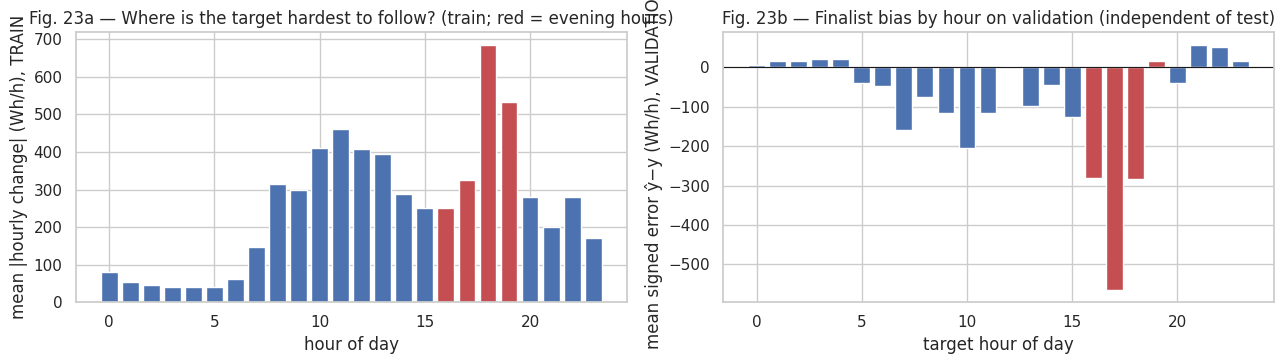

[timer] section 15.1 done: 40.3 min since the Stage-3 timer started


In [40]:
HOUR = dh["date"].dt.hour.values; T_out_all = dh["T_out"].values
q90_load = float(np.percentile(y_raw[:n_train], 90)); q90_jump = float(np.percentile(np.abs(np.diff(y_raw[:n_train])), 90)); q90_temp = float(np.percentile(T_out_all[:n_train], 90))
EVENING = (16, 17, 18, 19); REG = ["evening", "high_load", "big_change", "hot", "top_decile_expost"]
REG_DESC = {"evening": f"target hour in {EVENING}", "high_load": f"y[T-h] >= {q90_load:.0f} Wh/h (train P90)", "big_change": f"|y[T-h]-y[T-h-1]| >= {q90_jump:.0f} Wh/h (train P90)",
            "hot": f"T_out[T-h] >= {q90_temp:.1f} C (train P90)", "top_decile_expost": f"y[T] >= {q90_load:.0f} Wh/h (train P90; uses the outcome)"}
def regime_masks(h, T):
    e = T - h
    return {"evening": np.isin(HOUR[T], EVENING), "high_load": y_raw[e] >= q90_load, "big_change": np.abs(y_raw[e] - y_raw[e - 1]) >= q90_jump,
            "hot": T_out_all[e] >= q90_temp, "top_decile_expost": y_raw[T] >= q90_load}
T_tr1 = get_data(6, 1)["train"]["T"]; M_tr, M_va, M_te = regime_masks(1, T_tr1), regime_masks(1, T_val), regime_masks(1, T_test)
rd_tab = pd.DataFrame([dict(regime=r, rule=REG_DESC[r], forecast_time_information=(r != "top_decile_expost"), n_train=int(M_tr[r].sum()), pct_train=100 * M_tr[r].mean(),
                            n_val=int(M_va[r].sum()), pct_val=100 * M_va[r].mean(), n_test=int(M_te[r].sum()), pct_test=100 * M_te[r].mean()) for r in REG])
rd_tab.to_csv(f"{OUT3}/table23_regime_definitions.csv", index=False)
print("Table 23 — Pre-declared failure regimes (thresholds from TRAIN rows only; counts at h=1)"); display(rd_tab.round(1))
print("Regimes with fewer than 24 test hours cannot support a conclusion:", [r for r in REG if M_te[r].sum() < 24] or "none")

# independent evidence for the primary regime BEFORE looking at test: (a) training profile, (b) finalist validation errors by hour
y_tr_raw = y_raw[:n_train]; hr_tr = HOUR[:n_train]
prof_tr = pd.DataFrame({"mean_load": [y_tr_raw[hr_tr == k].mean() for k in range(24)], "std_load": [y_tr_raw[hr_tr == k].std() for k in range(24)],
                        "mean_abs_hourly_change": [np.abs(y_tr_raw[1:] - y_tr_raw[:-1])[hr_tr[1:] == k].mean() for k in range(24)]})
top_chg = prof_tr.mean_abs_hourly_change.sort_values(ascending=False).index[:6].tolist(); top_std = prof_tr.std_load.sort_values(ascending=False).index[:6].tolist()
pv_fin = next(p for p in PRED[(1, FINAL_LABEL)] if p["seed"] == SEED)["val"]
e_val = pv_fin - Y_val; ev_v = M_va["evening"]
print(f"(a) TRAIN: the 6 hours with the largest mean |hourly change| are {top_chg}; with the largest std of load {top_std}; evening hours {EVENING} inside these sets: "
      f"{[k for k in EVENING if k in top_chg]} (change), {[k for k in EVENING if k in top_std]} (std)")
print(f"(b) VALIDATION, finalist h=1 seed {SEED}: evening MAE {np.abs(e_val[ev_v]).mean():.1f} vs other hours {np.abs(e_val[~ev_v]).mean():.1f}; evening bias {e_val[ev_v].mean():+.1f} vs other {e_val[~ev_v].mean():+.1f} Wh/h")
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].bar(range(24), prof_tr.mean_abs_hourly_change, color=["C3" if k in EVENING else "C0" for k in range(24)]); axs[0].set_xlabel("hour of day"); axs[0].set_ylabel("mean |hourly change| (Wh/h), TRAIN")
axs[0].set_title("Fig. 23a — Where is the target hardest to follow? (train; red = evening hours)")
bias_h = pd.Series(e_val).groupby(HOUR[T_val]).mean(); axs[1].bar(bias_h.index, bias_h.values, color=["C3" if k in EVENING else "C0" for k in bias_h.index])
axs[1].axhline(0, color="k", lw=0.8); axs[1].set_xlabel("target hour of day"); axs[1].set_ylabel("mean signed error ŷ−y (Wh/h), VALIDATION"); axs[1].set_title("Fig. 23b — Finalist bias by hour on validation (independent of test)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig23_regime_evidence.png", dpi=150); plt.show()
tick("section 15.1 done")

Table 24 — Finalist (RNN ★ tuned) inside/outside each regime, h=1, test (bias = mean ŷ−y, negative = under-prediction; 95% block-bootstrap intervals; improvement > 0 = better than the reference)


,regime,side,n,MAE,MAE_lo,MAE_hi,bias,bias_lo,bias_hi,vs_naive_pct,vs_naive_lo,vs_naive_hi,vs_Ridge_pct,vs_Ridge_lo,vs_Ridge_hi
0,evening,inside,110,330.53,253.45,418.94,-231.91,-333.01,-145.73,20.75,11.41,29.94,0.46,-5.89,6.23
1,evening,outside,548,150.12,114.59,189.47,-39.56,-81.30,-2.24,3.16,-9.25,13.02,1.29,-2.97,5.29
2,high_load,inside,52,517.22,364.42,634.52,-294.94,-449.66,-81.67,28.30,6.98,54.24,-0.17,-9.97,12.28
3,high_load,outside,606,151.37,129.08,176.48,-52.56,-81.77,-27.62,1.71,-3.68,6.33,1.39,-1.76,4.20
4,big_change,inside,48,304.04,192.97,406.53,-107.79,-226.33,0.66,40.16,7.62,62.12,9.71,0.87,23.46
5,big_change,outside,610,170.54,138.93,205.38,-68.88,-108.05,-34.57,2.26,-4.05,8.03,-0.31,-3.77,2.91
6,hot,inside,505,194.04,152.23,240.21,-85.09,-132.96,-43.13,8.56,0.14,17.02,2.17,-1.39,5.88
7,hot,outside,153,134.86,89.07,204.67,-27.57,-93.91,16.70,12.83,-4.15,21.95,-4.70,-13.75,0.38
8,top_decile_expost,inside,52,966.16,884.40,1040.46,-966.16,-1040.46,-884.40,-31.28,-44.29,-16.62,-3.42,-8.86,1.91
9,top_decile_expost,outside,606,112.84,101.47,124.59,5.04,-7.58,17.69,26.12,18.78,32.78,4.07,-0.55,8.50


Same regimes, Ridge and naive, h=1:


,regime,side,model,n,MAE,bias
0,evening,inside,Ridge,110,332.05,-180.00
1,evening,inside,Naive,110,417.09,-31.27
2,evening,outside,Ridge,548,152.08,-38.69
3,evening,outside,Naive,548,155.02,4.98
4,high_load,inside,Ridge,52,516.34,-228.46
5,high_load,inside,Naive,52,721.35,526.73
6,high_load,outside,Ridge,606,153.50,-48.06
7,high_load,outside,Naive,606,153.99,-46.37
8,big_change,inside,Ridge,48,336.72,-43.12
9,big_change,inside,Naive,48,508.12,349.38


Finalist MAE improvement over Ridge INSIDE each regime, by horizon (%):


horizon_h,1,6,12,24
regime,,,,
evening,0.5,-13.2,5.4,-1.3
high_load,-0.2,-9.8,2.2,-1.9
big_change,9.7,-12.2,-5.2,-1.0
hot,2.2,-7.1,-4.1,-0.1
top_decile_expost,-3.4,-4.3,-2.7,-4.5


Mechanism evidence, finalist h=1 test, evening hours: mean actual 891.5 vs mean predicted 659.6 Wh/h (ratio 0.74); std actual 504.7 vs std predicted 199.2 (damping ratio 0.39); calibration slope of actual on predicted 0.74 inside vs 1.55 outside (slope > 1 = predictions too compressed); evening hours are 17% of test hours but 31% of the finalist's absolute error
[ex-post, descriptive only] hours with y >= train P90: mean predicted/actual = 0.45 (n=52)


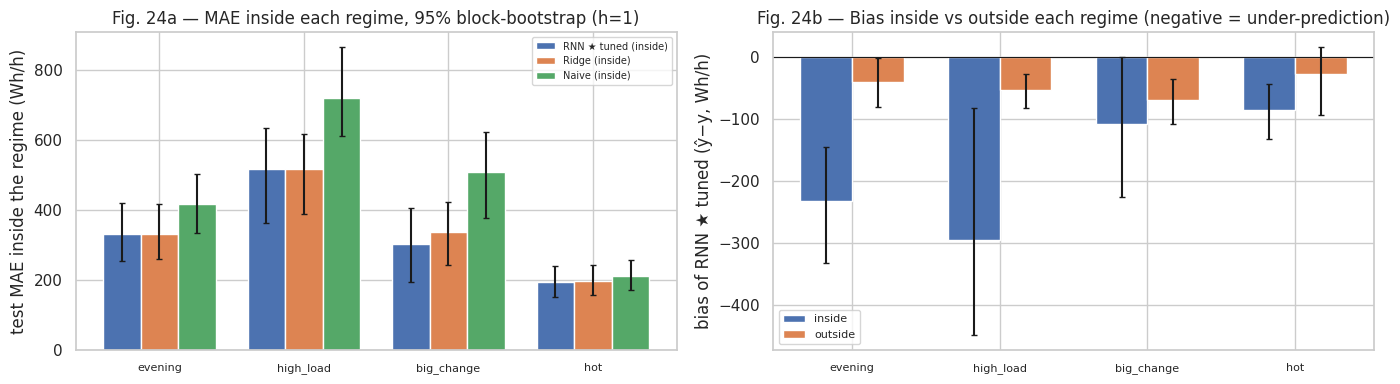

[timer] section 15.2 done: 40.4 min since the Stage-3 timer started


In [41]:
def regime_ci(err_ref, err_mod, sgn_mod, mask):
    '''Block-bootstrap (shared indices `bidx`) of MAE, bias and % MAE improvement over err_ref, restricted to `mask` (the mask is resampled with the errors).'''
    out = dict(n=int(mask.sum()))
    if mask.sum() == 0: return {**out, **{k: np.nan for k in ("MAE", "MAE_lo", "MAE_hi", "bias", "bias_lo", "bias_hi", "vs_ref_pct", "vs_ref_lo", "vs_ref_hi")}}
    m = mask[bidx].astype(float); cnt = m.sum(1); ok = cnt > 0; cnt = cnt[ok]
    mae_m = (err_mod[bidx] * m).sum(1)[ok] / cnt; mae_r = (err_ref[bidx] * m).sum(1)[ok] / cnt; bias = (sgn_mod[bidx] * m).sum(1)[ok] / cnt; rel = 100 * (mae_r - mae_m) / mae_r
    return {**out, "MAE": err_mod[mask].mean(), "MAE_lo": np.percentile(mae_m, 2.5), "MAE_hi": np.percentile(mae_m, 97.5), "bias": sgn_mod[mask].mean(), "bias_lo": np.percentile(bias, 2.5),
            "bias_hi": np.percentile(bias, 97.5), "vs_ref_pct": 100 * (err_ref[mask].mean() - err_mod[mask].mean()) / err_ref[mask].mean(), "vs_ref_lo": np.percentile(rel, 2.5), "vs_ref_hi": np.percentile(rel, 97.5)}
rows_g = []
for h in HORIZONS:
    P_ = {FINAL_LABEL: seed_pred(h, FINAL_LABEL), "Ridge": RIDGE_TEST_H[h], "Naive": BASE_TEST_H[h][NAIVE]}; E_ = {k: np.abs(p - Y_test) for k, p in P_.items()}; S_ = {k: p - Y_test for k, p in P_.items()}
    Mh = regime_masks(h, T_test)
    for r in REG:
        for where, mk in (("inside", Mh[r]), ("outside", ~Mh[r])):
            for k in P_:
                a = regime_ci(E_["Naive"], E_[k], S_[k], mk); b = regime_ci(E_["Ridge"], E_[k], S_[k], mk)
                rows_g.append(dict(horizon_h=h, regime=r, side=where, model=k, n=a["n"], MAE=a["MAE"], MAE_lo=a["MAE_lo"], MAE_hi=a["MAE_hi"], bias=a["bias"], bias_lo=a["bias_lo"], bias_hi=a["bias_hi"],
                                   vs_naive_pct=a["vs_ref_pct"], vs_naive_lo=a["vs_ref_lo"], vs_naive_hi=a["vs_ref_hi"], vs_Ridge_pct=b["vs_ref_pct"], vs_Ridge_lo=b["vs_ref_lo"], vs_Ridge_hi=b["vs_ref_hi"]))
rg = pd.DataFrame(rows_g); rg.to_csv(f"{OUT3}/table24_regime_metrics.csv", index=False)
print(f"Table 24 — Finalist ({FINAL_LABEL}) inside/outside each regime, h=1, test (bias = mean ŷ−y, negative = under-prediction; 95% block-bootstrap intervals; improvement > 0 = better than the reference)")
display(rg[(rg.horizon_h == 1) & (rg.model == FINAL_LABEL)].drop(columns=["horizon_h", "model"]).round(2).reset_index(drop=True))
print("Same regimes, Ridge and naive, h=1:"); display(rg[(rg.horizon_h == 1) & (rg.model != FINAL_LABEL)][["regime", "side", "model", "n", "MAE", "bias"]].round(2).reset_index(drop=True))
piv = rg[(rg.model == FINAL_LABEL) & (rg.side == "inside")].pivot(index="regime", columns="horizon_h", values="vs_Ridge_pct").loc[REG]; print("Finalist MAE improvement over Ridge INSIDE each regime, by horizon (%):"); display(piv.round(1))

# mechanism evidence for the primary regime (h=1): damping and under-prediction, computed not assumed
pf = seed_pred(1, FINAL_LABEL); ev = M_te["evening"]
slope_in = np.polyfit(pf[ev], Y_test[ev], 1)[0]; slope_out = np.polyfit(pf[~ev], Y_test[~ev], 1)[0]
hi_ex = M_te["top_decile_expost"]
print(f"Mechanism evidence, finalist h=1 test, evening hours: mean actual {Y_test[ev].mean():.1f} vs mean predicted {pf[ev].mean():.1f} Wh/h (ratio {pf[ev].mean() / Y_test[ev].mean():.2f}); "
      f"std actual {Y_test[ev].std():.1f} vs std predicted {pf[ev].std():.1f} (damping ratio {pf[ev].std() / Y_test[ev].std():.2f}); calibration slope of actual on predicted {slope_in:.2f} inside vs {slope_out:.2f} outside "
      f"(slope > 1 = predictions too compressed); evening hours are {100 * ev.mean():.0f}% of test hours but {100 * np.abs(pf - Y_test)[ev].sum() / np.abs(pf - Y_test).sum():.0f}% of the finalist's absolute error")
print(f"[ex-post, descriptive only] hours with y >= train P90: mean predicted/actual = {pf[hi_ex].mean() / Y_test[hi_ex].mean():.2f} (n={int(hi_ex.sum())})")
sel_r = rg[(rg.horizon_h == 1) & (rg.side == "inside") & (rg.regime != "top_decile_expost")]
fig, axs = plt.subplots(1, 2, figsize=(14, 4)); regs = [r for r in REG if r != "top_decile_expost"]; xb = np.arange(len(regs)); wd = 0.26
for i, k in enumerate([FINAL_LABEL, "Ridge", "Naive"]):
    for j, wh in enumerate(("inside", "outside")):
        g = rg[(rg.horizon_h == 1) & (rg.model == k) & (rg.side == wh)].set_index("regime").loc[regs]
        if j == 0: axs[0].bar(xb + i * wd, g.MAE, wd, yerr=[g.MAE - g.MAE_lo, g.MAE_hi - g.MAE], capsize=2, label=f"{k} (inside)")
g = rg[(rg.horizon_h == 1) & (rg.model == FINAL_LABEL)]
axs[0].set_xticks(xb + wd); axs[0].set_xticklabels(regs, fontsize=8); axs[0].set_ylabel("test MAE inside the regime (Wh/h)"); axs[0].legend(fontsize=7); axs[0].set_title("Fig. 24a — MAE inside each regime, 95% block-bootstrap (h=1)")
for j, wh in enumerate(("inside", "outside")):
    gg = g[g.side == wh].set_index("regime").loc[regs]; axs[1].bar(xb + j * 0.35, gg.bias, 0.35, yerr=[gg.bias - gg.bias_lo, gg.bias_hi - gg.bias], capsize=2, label=f"{wh}")
axs[1].axhline(0, color="k", lw=0.8); axs[1].set_xticks(xb + 0.175); axs[1].set_xticklabels(regs, fontsize=8); axs[1].set_ylabel(f"bias of {FINAL_LABEL} (ŷ−y, Wh/h)"); axs[1].legend(fontsize=8)
axs[1].set_title("Fig. 24b — Bias inside vs outside each regime (negative = under-prediction)")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig24_regime_metrics.png", dpi=150); plt.show()
tick("section 15.2 done")

Worst finalist forecasts on test (h=1)


,time,actual,finalist,ridge,naive,finalist_abs_err,in_evening,in_high_load,in_big_change,in_hot,in_top_decile_expost
0,2016-05-26T16:00:00.000000000,2970.0,429.5,435.3,370.0,2540.5,True,False,False,True,True
1,2016-04-30T10:00:00.000000000,2870.0,1220.6,1058.9,1510.0,1649.4,False,True,False,False,True
2,2016-05-23T17:00:00.000000000,2280.0,708.5,687.0,940.0,1571.5,True,False,False,True,True
3,2016-05-13T11:00:00.000000000,2130.0,562.9,531.7,440.0,1567.1,False,False,False,True,True
4,2016-05-21T11:00:00.000000000,2590.0,1153.5,1063.1,2300.0,1436.5,False,True,False,True,True
5,2016-05-22T11:00:00.000000000,2060.0,706.9,769.0,1210.0,1353.1,False,False,False,True,True


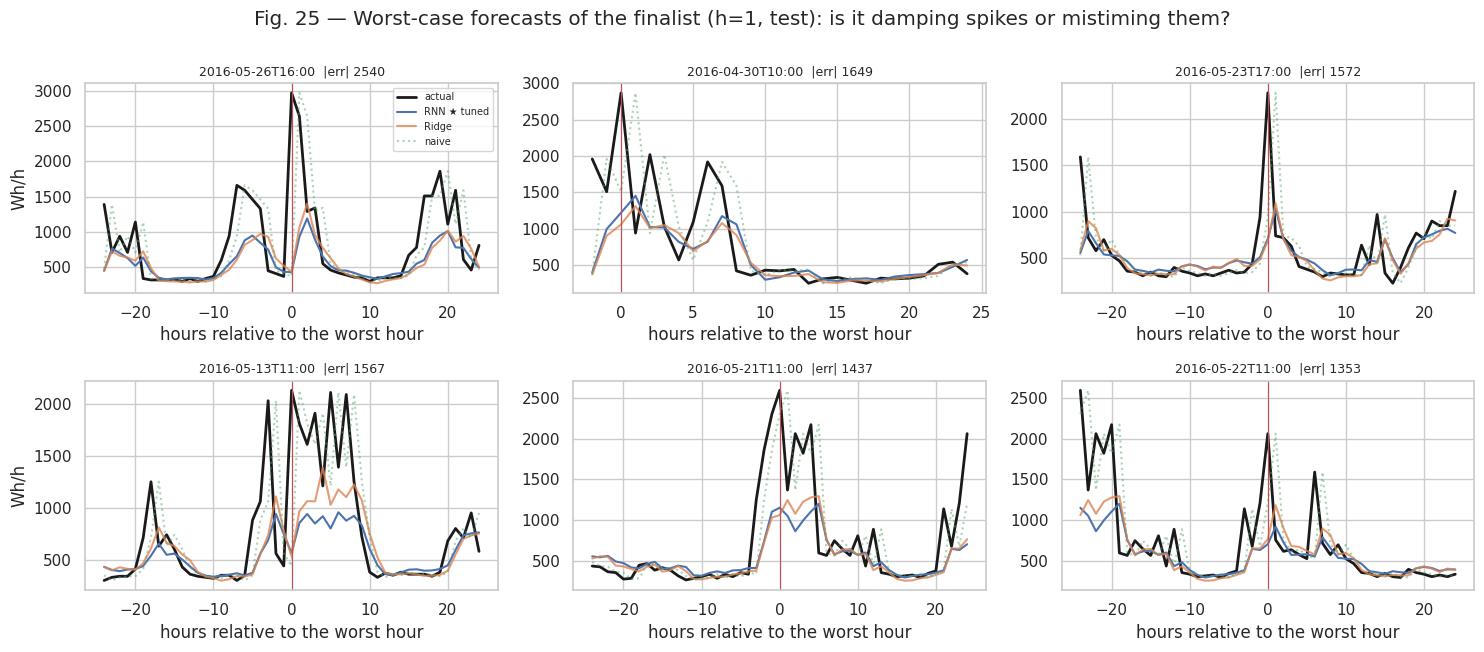

Of the 6 worst episodes, the finalist under-predicted in 6; 2 fall in the evening regime.
[timer] section 15.3 done: 40.5 min since the Stage-3 timer started


In [42]:
# Worst-case forecasts (descriptive, selected ex post on test, never used to tune anything)
e_f = np.abs(pf - Y_test); order_w = np.argsort(-e_f); chosen = []
for i in order_w:                                                    # 6 worst hours, at least 24 h apart so the panels show different episodes
    if all(abs(i - j) >= 24 for j in chosen): chosen.append(i)
    if len(chosen) == 6: break
ts_te = dh["date"].values[T_test]
wc = pd.DataFrame([dict(time=str(ts_te[i]), actual=Y_test[i], finalist=pf[i], ridge=RIDGE_TEST_H[1][i], naive=BASE_TEST_H[1][NAIVE][i], finalist_abs_err=e_f[i],
                        **{f"in_{r}": bool(M_te[r][i]) for r in REG}) for i in chosen]); wc.to_csv(f"{OUT3}/table24b_worst_cases.csv", index=False)
print("Worst finalist forecasts on test (h=1)"); display(wc.round(1))
fig, axs = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, i in zip(axs.ravel(), chosen):
    s0, s1 = max(0, i - 24), min(len(Y_test), i + 25); xs = np.arange(s0, s1) - i
    ax.plot(xs, Y_test[s0:s1], "k", lw=2, label="actual"); ax.plot(xs, pf[s0:s1], label=FINAL_LABEL); ax.plot(xs, RIDGE_TEST_H[1][s0:s1], label="Ridge", alpha=0.8); ax.plot(xs, BASE_TEST_H[1][NAIVE][s0:s1], label="naive", alpha=0.5, ls=":")
    ax.axvline(0, color="r", lw=0.8); ax.set_title(f"{str(ts_te[i])[:16]}  |err| {e_f[i]:.0f}", fontsize=9); ax.set_xlabel("hours relative to the worst hour")
axs[0, 0].legend(fontsize=7); axs[0, 0].set_ylabel("Wh/h"); axs[1, 0].set_ylabel("Wh/h")
fig.suptitle("Fig. 25 — Worst-case forecasts of the finalist (h=1, test): is it damping spikes or mistiming them?", y=1.0); plt.tight_layout(); plt.savefig(f"{OUT3}/fig25_worst_cases.png", dpi=150); plt.show()
print(f"Of the {len(chosen)} worst episodes, the finalist under-predicted in {int((pf[chosen] < Y_test[chosen]).sum())}; {int(sum(M_te['evening'][i] for i in chosen))} fall in the evening regime.")
tick("section 15.3 done")

Table 25 — Asymmetric-loss mitigation, VALIDATION only (screen seeds [42, 43]); rule: lowest evening val MAE among taus with overall val MAE <= 1.05 x L1 and evening val MAE below L1's


,tau,val_MAE,val_MAE_evening,val_bias_evening,overall_val_MAE_vs_L1_pct,eligible
0,"0.5 (L1, finalist)",190.60,400.54,-262.74,0.00,False
1,0.6,192.20,397.75,-215.03,0.84,True
2,0.7,204.95,405.26,-111.72,7.53,False
3,0.8,253.43,480.85,189.58,32.96,False


Selected tau* = 0.6 (validation). Evaluating on test with all final seeds [42, 43, 44, 45, 46].
Table 26 — Mitigation vs L1 finalist on TEST (seed-42 paired block bootstrap; improvement > 0 = tau* better; last two columns average 5 seeds)


,regime,n,L1_MAE,tau_MAE,MAE_improvement_pct,CI_lo,CI_hi,L1_bias,tau_bias,tau_bias_lo,tau_bias_hi,mean_over_seeds_L1_MAE,mean_over_seeds_tau_MAE
0,evening (primary),110,330.53,326.75,1.14,-3.01,4.37,-231.91,-176.96,-272.39,-97.00,341.57,329.62
1,outside evening,548,150.12,151.47,-0.90,-2.81,0.83,-39.56,-29.87,-70.97,6.69,147.33,150.67
2,all test hours,658,180.28,180.77,-0.27,-2.08,1.33,-71.71,-54.46,-94.37,-19.63,179.80,180.59
3,high_load,52,517.22,516.64,0.11,-8.75,3.68,-294.94,-220.23,-382.09,8.22,528.29,520.04
4,big_change,48,304.04,326.23,-7.30,-20.67,0.22,-107.79,-46.67,-167.66,67.46,303.12,323.42


Verdict (computed): evening MAE improvement +1.1% [-3.0, +4.4] ; overall -0.3% [-2.1, +1.3]; evening bias -231.9 -> -177.0 Wh/h. Helped in the regime beyond test noise: False; significantly hurt overall: False.


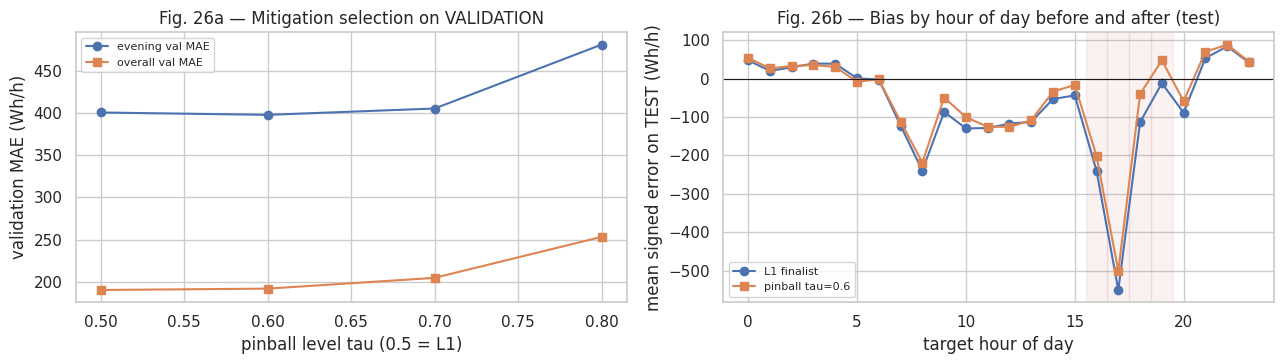

[timer] section 15.4 done: 41.5 min since the Stage-3 timer started


In [43]:
TAUS, TOL = [0.6, 0.7, 0.8], 1.05                                     # declared before running (section 15 text)
ev_val = M_va["evening"]
def val_stats(pv): e = pv - Y_val; return dict(val_MAE=np.abs(e).mean(), val_MAE_evening=np.abs(e[ev_val]).mean(), val_bias_evening=e[ev_val].mean())
MIT = {}                                                              # (tau, seed) -> dict of predictions
def fit_mit(tau, s):
    if (tau, s) not in MIT:
        r = run_config(FINAL_FAMILY, {**FINAL_CFG, "loss": f"Q{tau}"}, s); L = FINAL_CFG["window"]
        MIT[(tau, s)] = dict(val=r["val_pred"], test=inv(predict_scaled(r["model"], tens(L, "test")[0])), params=r["params"])
    return MIT[(tau, s)]
base_v = [val_stats(p["val"]) for p in PRED[(1, FINAL_LABEL)] if p["seed"] in SCREEN_SEEDS]
rows_m = [dict(tau="0.5 (L1, finalist)", **{k: np.mean([b[k] for b in base_v]) for k in base_v[0]})]
for tau in TAUS:
    vs_ = [val_stats(fit_mit(tau, s)["val"]) for s in SCREEN_SEEDS]; rows_m.append(dict(tau=str(tau), **{k: np.mean([v[k] for v in vs_]) for k in vs_[0]}))
mt_sel = pd.DataFrame(rows_m); mt_sel["overall_val_MAE_vs_L1_pct"] = 100 * (mt_sel.val_MAE - mt_sel.val_MAE.iloc[0]) / mt_sel.val_MAE.iloc[0]
mt_sel["eligible"] = [False] + [(mt_sel.val_MAE.iloc[i] <= TOL * mt_sel.val_MAE.iloc[0]) and (mt_sel.val_MAE_evening.iloc[i] < mt_sel.val_MAE_evening.iloc[0]) for i in range(1, len(mt_sel))]
mt_sel.to_csv(f"{OUT3}/table25_mitigation_validation.csv", index=False)
print(f"Table 25 — Asymmetric-loss mitigation, VALIDATION only (screen seeds {SCREEN_SEEDS}); rule: lowest evening val MAE among taus with overall val MAE <= {TOL:.2f} x L1 and evening val MAE below L1's"); display(mt_sel.round(2))
el = mt_sel[mt_sel.eligible]; TAU_STAR = float(el.sort_values("val_MAE_evening").tau.iloc[0]) if len(el) else None
MITIGATION = dict(tau=TAU_STAR)
if TAU_STAR is None:
    print("No tau met the declared criterion on validation -> mitigation declared NOT helpful; nothing is evaluated on test.")
else:
    print(f"Selected tau* = {TAU_STAR} (validation). Evaluating on test with all final seeds {FINAL_SEEDS}.")
    for s in FINAL_SEEDS: fit_mit(TAU_STAR, s)
    pm_all = {s: MIT[(TAU_STAR, s)]["test"] for s in FINAL_SEEDS}; pb_all = {p["seed"]: p["test"] for p in PRED[(1, FINAL_LABEL)]}
    allm = np.ones(len(Y_test), bool); regs_m = {"evening (primary)": M_te["evening"], "outside evening": ~M_te["evening"], "all test hours": allm, "high_load": M_te["high_load"], "big_change": M_te["big_change"]}
    rows_t = []
    for nm, mk in regs_m.items():
        eb, em = np.abs(pb_all[SEED] - Y_test), np.abs(pm_all[SEED] - Y_test); c = regime_ci(eb, em, pm_all[SEED] - Y_test, mk)
        rows_t.append(dict(regime=nm, n=c["n"], L1_MAE=eb[mk].mean(), tau_MAE=c["MAE"], MAE_improvement_pct=c["vs_ref_pct"], CI_lo=c["vs_ref_lo"], CI_hi=c["vs_ref_hi"],
                           L1_bias=(pb_all[SEED] - Y_test)[mk].mean(), tau_bias=c["bias"], tau_bias_lo=c["bias_lo"], tau_bias_hi=c["bias_hi"],
                           mean_over_seeds_L1_MAE=np.mean([np.abs(pb_all[s] - Y_test)[mk].mean() for s in FINAL_SEEDS]), mean_over_seeds_tau_MAE=np.mean([np.abs(pm_all[s] - Y_test)[mk].mean() for s in FINAL_SEEDS])))
    mt_test = pd.DataFrame(rows_t); mt_test.to_csv(f"{OUT3}/table26_mitigation_test.csv", index=False)
    print(f"Table 26 — Mitigation vs L1 finalist on TEST (seed-{SEED} paired block bootstrap; improvement > 0 = tau* better; last two columns average {len(FINAL_SEEDS)} seeds)"); display(mt_test.round(2))
    ev_row, all_row = mt_test.iloc[0], mt_test.iloc[2]
    MITIGATION.update(evening_change_pct=float(ev_row.MAE_improvement_pct), evening_ci=(float(ev_row.CI_lo), float(ev_row.CI_hi)), overall_change_pct=float(all_row.MAE_improvement_pct), overall_ci=(float(all_row.CI_lo), float(all_row.CI_hi)),
                      evening_bias_before=float(ev_row.L1_bias), evening_bias_after=float(ev_row.tau_bias), helped_evening=bool(ev_row.CI_lo > 0), hurt_overall=bool(all_row.CI_hi < 0))
    print(f"Verdict (computed): evening MAE improvement {MITIGATION['evening_change_pct']:+.1f}% [{MITIGATION['evening_ci'][0]:+.1f}, {MITIGATION['evening_ci'][1]:+.1f}] ; overall {MITIGATION['overall_change_pct']:+.1f}% "
          f"[{MITIGATION['overall_ci'][0]:+.1f}, {MITIGATION['overall_ci'][1]:+.1f}]; evening bias {MITIGATION['evening_bias_before']:+.1f} -> {MITIGATION['evening_bias_after']:+.1f} Wh/h. "
          f"Helped in the regime beyond test noise: {MITIGATION['helped_evening']}; significantly hurt overall: {MITIGATION['hurt_overall']}.")
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(mt_sel.tau.str.split().str[0].astype(float), mt_sel.val_MAE_evening, marker="o", label="evening val MAE"); axs[0].plot(mt_sel.tau.str.split().str[0].astype(float), mt_sel.val_MAE, marker="s", label="overall val MAE")
axs[0].set_xlabel("pinball level tau (0.5 = L1)"); axs[0].set_ylabel("validation MAE (Wh/h)"); axs[0].legend(fontsize=8); axs[0].set_title("Fig. 26a — Mitigation selection on VALIDATION")
if TAU_STAR is not None:
    bb = pd.Series(pb_all[SEED] - Y_test).groupby(HOUR[T_test]).mean(); bm = pd.Series(pm_all[SEED] - Y_test).groupby(HOUR[T_test]).mean()
    axs[1].plot(bb.index, bb.values, marker="o", label="L1 finalist"); axs[1].plot(bm.index, bm.values, marker="s", label=f"pinball tau={TAU_STAR}"); axs[1].axhline(0, color="k", lw=0.8)
    for k in EVENING: axs[1].axvspan(k - 0.5, k + 0.5, color="C3", alpha=0.08)
    axs[1].set_xlabel("target hour of day"); axs[1].set_ylabel("mean signed error on TEST (Wh/h)"); axs[1].legend(fontsize=8)
else: axs[1].text(0.5, 0.5, "no tau selected on validation:\nmitigation not evaluated on test", ha="center", va="center")
axs[1].set_title("Fig. 26b — Bias by hour of day before and after (test)"); plt.tight_layout(); plt.savefig(f"{OUT3}/fig26_mitigation.png", dpi=150); plt.show()
tick("section 15.4 done")

## 16. Prediction intervals: are the 80 % and 90 % bands calibrated, and what happens under shift?
**Questions.** (i) Do conformal and quantile-regression intervals reach their nominal coverage on the test set, per horizon and per failure regime? (ii) How wide are they and what is their interval score? (iii) Test is warmer than validation, so the exchangeability assumed by conformal prediction is doubtful: does a rolling recalibration that uses only residuals observed at deployment time restore coverage?

**Methods (all for the finalist; Ridge + conformal is shown as a reference).**
* **Split conformal, log space.** Residuals `r = log1p(y) − ŷ_log` on the **validation** set (ŷ_log = inverse-scaled model output). A two-sided interval uses the signed finite-sample quantiles `ŷ_log + [r_(⌊(n+1)α/2⌋), r_(⌈(n+1)(1−α/2)⌉)]`, then `expm1` and clipping at 0 give a **non-negative** interval in Wh/h. *Global*: one quantile pair. *Hour-bin*: four 6-hour bins of the target hour, each with its own quantiles (a bin with < 30 validation residuals falls back to the global pair).
* **Rolling recalibration (deployment-legal).** A forecast for target hour T made with horizon h can only use residuals of targets T′ ≤ T − h (the actual of hour T − h is known once its bin has ended). The pool is the last W = 168 such residuals taken from validation and the already-observed part of test, in time order; W was declared before running (W = 72 and 336 are reported as sensitivity only). No test residual that would not yet exist is ever used (asserted).
* **Quantile regression (pinball loss).** Four extra models with the finalist's architecture and hyper-parameters, one per level τ ∈ {0.05, 0.10, 0.90, 0.95}, per horizon (seed 42, early-stopped on validation pinball loss). The 80 % band is [q0.10, q0.90], the 90 % band [q0.05, q0.95]; crossings are repaired by sorting. Quantiles are invariant to the monotone log/scale transform, so they invert directly.

**Scores.** Coverage with a 24 h block-bootstrap 95 % interval, mean width (Wh/h), and the **interval score** of Gneiting & Raftery, `IS = (u − l) + (2/α)(l − y)₊ + (2/α)(y − u)₊`. The **Winkler score** is this same quantity for a central interval, so it is reported once (as “interval (Winkler) score”) together with its scale-free version IS / mean(y). A method is called *calibrated* here only if the bootstrap coverage interval contains the nominal level.

In [44]:
LEVELS = {80: 0.20, 90: 0.10}                                          # nominal coverage -> alpha
to_log = lambda ps: y_scaler.inverse_transform(np.asarray(ps).reshape(-1, 1)).ravel()                     # standardised model output -> log1p(Wh/h), NOT clipped
to_wh = lambda z: np.clip(np.expm1(z), 0, None)                                                        # back to Wh/h, non-negative
ylog_val = np.log1p(Y_val)
def ridge_scaled(h, split):
    r = RIDGE_H[h]; X_ = get_data(r["L"], h)[split]["X"]; return r["model"].predict(X_.reshape(len(X_), -1))
def fin_pred(h, split, label=None):
    p = next(q for q in PRED[(h, label or FINAL_LABEL)] if q["seed"] == SEED); return to_log(p["val_s"] if split == "val" else p["test_s"])
def conf_q(res, alpha):
    '''Signed finite-sample split-conformal quantile pair (lower, upper) of residuals.'''
    r = np.sort(np.asarray(res)); n = len(r); k_hi = int(np.ceil((n + 1) * (1 - alpha / 2))); k_lo = int(np.floor((n + 1) * alpha / 2))
    return r[max(k_lo, 1) - 1], r[min(k_hi, n) - 1]
BIN = lambda hours: hours // 6                                         # 4 bins of 6 hours (declared)
def conformal_static(pv, pt, h, by_bin):
    res = ylog_val - pv; out = {}
    for lev, a in LEVELS.items():
        gl = conf_q(res, a); lo, hi = np.empty(len(pt)), np.empty(len(pt))
        qs = {}
        for b in range(4):
            rb = res[BIN(HOUR[T_val]) == b]; qs[b] = conf_q(rb, a) if (by_bin and len(rb) >= 30) else gl
        for b in range(4):
            mk = BIN(HOUR[T_test]) == b; lo[mk], hi[mk] = pt[mk] + qs[b][0], pt[mk] + qs[b][1]
        out[lev] = (to_wh(lo), to_wh(hi))
    return out
INT = {}                                                               # INT[(h, method)][level] = (lo_Wh, hi_Wh) over the test hours
for h in HORIZONS:
    pv, pt = fin_pred(h, "val"), fin_pred(h, "test")
    INT[(h, "Conformal (global, val)")] = conformal_static(pv, pt, h, False)
    INT[(h, "Conformal (hour-bin, val)")] = conformal_static(pv, pt, h, True)
    INT[(h, "Ridge + conformal (global, val)")] = conformal_static(to_log(ridge_scaled(h, "val")), to_log(ridge_scaled(h, "test")), h, False)

# quantile-regression models: 4 pinball fits per horizon, finalist architecture (seed 42)
QTAUS = [0.05, 0.10, 0.90, 0.95]; QR_PRED = {}; t_qr = time.time(); Lq = FINAL_CFG["window"]
for h in HORIZONS:
    for tau in QTAUS:
        r = run_config(FINAL_FAMILY, {**FINAL_CFG, "loss": f"Q{tau}"}, SEED, h)
        QR_PRED[(h, tau)] = dict(val=to_log(predict_scaled(r["model"], tens(Lq, "val", h)[0])), test=to_log(predict_scaled(r["model"], tens(Lq, "test", h)[0])))
    q = {t: QR_PRED[(h, t)] for t in QTAUS}
    INT[(h, "Quantile regression (pinball)")] = {80: (to_wh(np.minimum(q[0.10]["test"], q[0.90]["test"])), to_wh(np.maximum(q[0.10]["test"], q[0.90]["test"]))),
                                                 90: (to_wh(np.minimum(q[0.05]["test"], q[0.95]["test"])), to_wh(np.maximum(q[0.05]["test"], q[0.95]["test"])))}
print(f"Quantile models trained: {len(HORIZONS) * len(QTAUS)} fits in {(time.time() - t_qr) / 60:.1f} min")
# sanity on the CALIBRATION set (validation): conformal must cover ~nominal there by construction; QR is not calibrated on it
cal_chk = []
for h in HORIZONS:
    pv = fin_pred(h, "val"); res = ylog_val - pv
    for lev, a in LEVELS.items():
        ql, qh = conf_q(res, a); cal_chk.append(dict(horizon_h=h, nominal=lev, conformal_val_coverage=np.mean((ylog_val >= pv + ql) & (ylog_val <= pv + qh)),
                                                      QR_val_coverage=np.mean((ylog_val >= np.minimum(*[QR_PRED[(h, t)]["val"] for t in ((0.10, 0.90) if lev == 80 else (0.05, 0.95))])) &
                                                                              (ylog_val <= np.maximum(*[QR_PRED[(h, t)]["val"] for t in ((0.10, 0.90) if lev == 80 else (0.05, 0.95))])))))
print("Calibration-set (validation) coverage, for orientation only:"); display(pd.DataFrame(cal_chk).round(3))
tick("section 16.1 done")

Quantile models trained: 16 fits in 1.3 min
Calibration-set (validation) coverage, for orientation only:


,horizon_h,nominal,conformal_val_coverage,QR_val_coverage
0,1,80,0.805,0.796
1,1,90,0.906,0.848
2,6,80,0.805,0.748
3,6,90,0.906,0.865
4,12,80,0.805,0.778
5,12,90,0.906,0.866
6,24,80,0.805,0.804
7,24,90,0.906,0.883


[timer] section 16.1 done: 42.8 min since the Stage-3 timer started


In [45]:
W_DECLARED, W_SENS = 168, [72, 336]
def conformal_rolling(pv, pt, h, W):
    '''Rolling split conformal using ONLY residuals observable at forecast time: targets T' <= T-h, from validation then the observed part of test.'''
    res_all = np.concatenate([ylog_val - pv, ylog_te - pt]); T_all = np.concatenate([T_val, T_test]); out = {}
    assert (np.diff(T_all) > 0).all()
    for lev, a in LEVELS.items():
        lo, hi = np.empty(len(pt)), np.empty(len(pt))
        for i, T in enumerate(T_test):
            c = int(np.searchsorted(T_all, T - h, side="right")); assert c > 0 and T_all[c - 1] <= T - h          # no residual from after the forecast origin
            ql, qh = conf_q(res_all[max(0, c - W):c], a); lo[i], hi[i] = pt[i] + ql, pt[i] + qh
        out[lev] = (to_wh(lo), to_wh(hi))
    return out
for h in HORIZONS:
    pv, pt = fin_pred(h, "val"), fin_pred(h, "test")
    INT[(h, f"Conformal (rolling W={W_DECLARED})")] = conformal_rolling(pv, pt, h, W_DECLARED)
    for W in W_SENS: INT[(h, f"[sensitivity] Conformal (rolling W={W})")] = conformal_rolling(pv, pt, h, W)
leak_ok = True                                                         # explicit demonstration for the first test hour at the longest horizon
h_ = max(HORIZONS); c0 = int(np.searchsorted(np.concatenate([T_val, T_test]), T_test[0] - h_, side="right"))
print(f"Leakage check: for the first test hour at h={h_} the rolling pool ends at target index {np.concatenate([T_val, T_test])[c0 - 1]} <= T-h = {T_test[0] - h_}; "
      f"the last {len(T_val) - c0} validation residuals are NOT yet observable and are excluded.")

# distribution shift between the calibration (validation) and evaluation (test) periods
rows_s = []
for h in HORIZONS:
    pv, pt = fin_pred(h, "val"), fin_pred(h, "test"); rv, rt = ylog_val - pv, ylog_te - pt
    rows_s.append(dict(horizon_h=h, val_median_abs_log_res=np.median(np.abs(rv)), test_median_abs_log_res=np.median(np.abs(rt)), scale_ratio_test_over_val=np.median(np.abs(rt)) / np.median(np.abs(rv)),
                       val_mean_log_res=rv.mean(), test_mean_log_res=rt.mean(), val_mean_Tout=T_out_all[T_val].mean(), test_mean_Tout=T_out_all[T_test].mean(),
                       train_mean_Tout=T_out_all[:n_train].mean(), val_mean_load=Y_val.mean(), test_mean_load=Y_test.mean()))
shift_tab = pd.DataFrame(rows_s); shift_tab.to_csv(f"{OUT3}/table29_calibration_vs_test_shift.csv", index=False)
print("Table 29 — Shift between the calibration period (validation) and the evaluation period (test), finalist"); display(shift_tab.round(3))
tick("section 16.2 done")

Leakage check: for the first test hour at h=24 the rolling pool ends at target index 2607 <= T-h = 2607; the last 23 validation residuals are NOT yet observable and are excluded.
Table 29 — Shift between the calibration period (validation) and the evaluation period (test), finalist


,horizon_h,val_median_abs_log_res,test_median_abs_log_res,scale_ratio_test_over_val,val_mean_log_res,test_mean_log_res,val_mean_Tout,test_mean_Tout,train_mean_Tout,val_mean_load,test_mean_load
0,1,0.165,0.187,1.134,0.026,0.019,8.548,13.631,4.957,598.982,578.024
1,6,0.194,0.222,1.143,0.087,0.104,8.548,13.631,4.957,598.982,578.024
2,12,0.189,0.188,0.995,0.116,0.104,8.548,13.631,4.957,598.982,578.024
3,24,0.178,0.181,1.014,0.111,0.111,8.548,13.631,4.957,598.982,578.024


[timer] section 16.2 done: 42.8 min since the Stage-3 timer started


Table 27 — Test-set interval metrics by horizon (coverage with 95% block-bootstrap interval; interval score = Winkler score; lower is better at similar coverage)

--- nominal 80% ---


,horizon_h,method,coverage_pct,cov_lo,cov_hi,gap_pp,width_Wh,interval_score_Wh,IS_over_mean_y,nominal_inside_CI,zero_width_share_pct
0,1,"Conformal (global, val)",80.24,76.59,83.74,0.24,512.73,997.71,1.73,True,0.0
1,1,"Conformal (hour-bin, val)",83.13,79.94,86.47,3.13,571.55,857.71,1.48,True,0.0
2,1,Conformal (rolling W=168),81.91,78.87,84.80,1.91,538.21,1020.05,1.76,True,0.0
3,1,Quantile regression (pinball),69.76,65.20,74.16,-10.24,481.72,1026.85,1.78,False,0.0
4,1,"Ridge + conformal (global, val)",79.79,75.98,83.28,-0.21,563.00,998.19,1.73,True,0.0
5,6,"Conformal (global, val)",80.09,75.38,84.19,0.09,643.71,1318.03,2.28,True,0.0
6,6,"Conformal (hour-bin, val)",77.81,73.40,81.76,-2.19,665.90,1161.90,2.01,True,0.0
7,6,Conformal (rolling W=168),81.31,76.44,85.56,1.31,692.15,1347.10,2.33,True,0.0
8,6,Quantile regression (pinball),52.89,44.07,61.40,-27.11,592.38,1335.69,2.31,False,0.0
9,6,"Ridge + conformal (global, val)",82.37,77.96,86.32,2.37,721.07,1198.65,2.07,True,0.0



--- nominal 90% ---


,horizon_h,method,coverage_pct,cov_lo,cov_hi,gap_pp,width_Wh,interval_score_Wh,IS_over_mean_y,nominal_inside_CI,zero_width_share_pct
0,1,"Conformal (global, val)",91.03,88.45,93.62,1.03,827.86,1217.12,2.11,True,0.0
1,1,"Conformal (hour-bin, val)",91.64,89.36,93.92,1.64,817.10,1071.23,1.85,True,0.0
2,1,Conformal (rolling W=168),91.34,88.60,94.07,1.34,858.04,1255.28,2.17,True,0.0
3,1,Quantile regression (pinball),52.13,43.01,60.19,-37.87,656.71,1752.27,3.03,False,0.0
4,1,"Ridge + conformal (global, val)",90.73,88.45,93.31,0.73,899.19,1261.48,2.18,True,0.0
5,6,"Conformal (global, val)",89.51,85.71,93.16,-0.49,1008.50,1677.40,2.90,True,0.0
6,6,"Conformal (hour-bin, val)",87.08,83.73,90.27,-2.92,980.01,1404.25,2.43,True,0.0
7,6,Conformal (rolling W=168),89.97,85.56,93.62,-0.03,1109.82,1784.12,3.09,True,0.0
8,6,Quantile regression (pinball),65.50,56.53,73.56,-24.50,698.64,1864.70,3.23,False,0.0
9,6,"Ridge + conformal (global, val)",93.16,90.27,95.74,3.16,1198.42,1496.45,2.59,False,0.0



Table 30 — Rolling recalibration vs static conformal (gap = coverage − nominal, percentage points)


,horizon_h,nominal_pct,gap_global_pp,gap_hourbin_pp,gap_rolling_pp,rolling_closer_than_hourbin,rolling_closer_than_global,width_rolling_over_hourbin,rolling_calibrated
0,1,80,0.24,3.13,1.91,True,False,0.94,True
1,1,90,1.03,1.64,1.34,True,False,1.05,True
2,6,80,0.09,-2.19,1.31,True,False,1.04,True
3,6,90,-0.49,-2.92,-0.03,True,True,1.13,True
4,12,80,1.00,0.70,-0.06,True,True,0.93,True
5,12,90,1.95,-1.40,0.12,True,True,0.99,True
6,24,80,2.67,4.65,1.61,True,True,0.82,True
7,24,90,3.92,2.55,0.58,True,True,0.85,True


Computed summary: rolling closer to nominal than the hour-bin static intervals in 8/8 (horizon, level) cases and than global in 5/8; rolling intervals calibrated (nominal inside the bootstrap CI) in 8/8; mean static hour-bin gap +0.8 pp, mean rolling gap +0.8 pp.


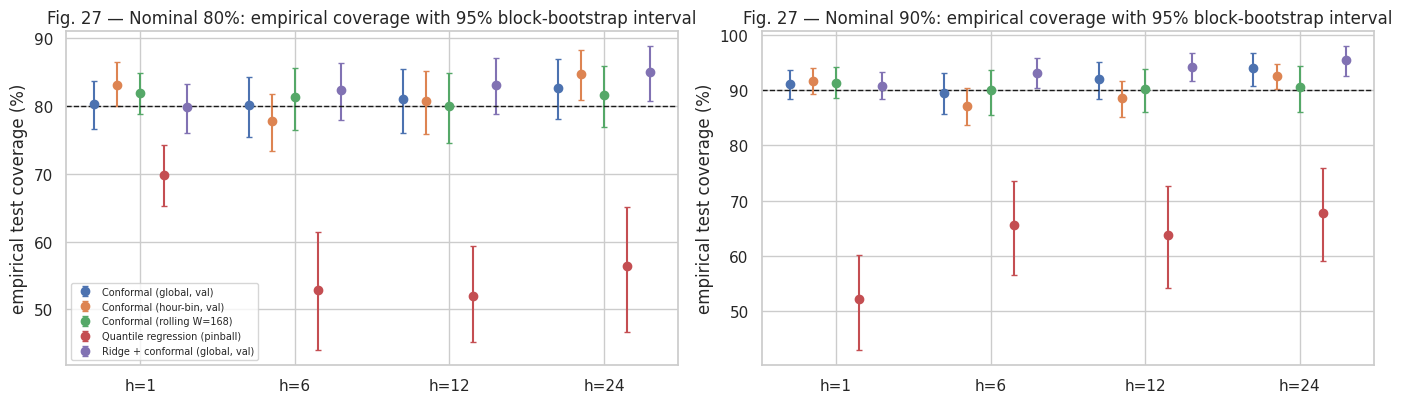

[timer] section 16.3 done: 42.8 min since the Stage-3 timer started


In [46]:
def cov_ci(ind, mask=None):
    '''Coverage and its 24 h block-bootstrap interval (the mask, if any, is resampled with the indicator).'''
    if mask is None: b = ind[bidx].mean(1); return ind.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)
    if mask.sum() == 0: return np.nan, np.nan, np.nan
    m = mask[bidx].astype(float); c = m.sum(1); ok = c > 0; b = (ind[bidx] * m).sum(1)[ok] / c[ok]; return ind[mask].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)
def interval_scores(y, lo, hi, a): return (hi - lo) + (2 / a) * (lo - y) * (y < lo) + (2 / a) * (y - hi) * (y > hi)          # Gneiting-Raftery interval score = Winkler score
METHODS = ["Conformal (global, val)", "Conformal (hour-bin, val)", f"Conformal (rolling W={W_DECLARED})", "Quantile regression (pinball)", "Ridge + conformal (global, val)"]
rows_i = []
for h in HORIZONS:
    for mth in METHODS + [f"[sensitivity] Conformal (rolling W={W})" for W in W_SENS]:
        for lev, a in LEVELS.items():
            lo, hi = INT[(h, mth)][lev]; ind = ((Y_test >= lo) & (Y_test <= hi)).astype(float); c, cl, ch = cov_ci(ind); isc = interval_scores(Y_test, lo, hi, a)
            rows_i.append(dict(horizon_h=h, method=mth, nominal_pct=lev, coverage_pct=100 * c, cov_lo=100 * cl, cov_hi=100 * ch, gap_pp=100 * c - lev, width_Wh=(hi - lo).mean(),
                               interval_score_Wh=isc.mean(), IS_over_mean_y=isc.mean() / Y_test.mean(), nominal_inside_CI=bool(100 * cl <= lev <= 100 * ch), zero_width_share_pct=100 * np.mean(hi - lo <= 1e-9)))
ti = pd.DataFrame(rows_i); ti.to_csv(f"{OUT3}/table27_interval_metrics.csv", index=False)
print("Table 27 — Test-set interval metrics by horizon (coverage with 95% block-bootstrap interval; interval score = Winkler score; lower is better at similar coverage)")
for lev in LEVELS: print(f"\n--- nominal {lev}% ---"); display(ti[(ti.nominal_pct == lev) & ~ti.method.str.startswith("[sens")].drop(columns=["nominal_pct"]).round(2).reset_index(drop=True))
# does rolling recalibration improve coverage? computed per horizon and level against both static conformal variants
rows_v = []
for h in HORIZONS:
    for lev in LEVELS:
        g = ti[(ti.horizon_h == h) & (ti.nominal_pct == lev)].set_index("method"); roll = g.loc[f"Conformal (rolling W={W_DECLARED})"]
        rows_v.append(dict(horizon_h=h, nominal_pct=lev, gap_global_pp=g.loc["Conformal (global, val)"].gap_pp, gap_hourbin_pp=g.loc["Conformal (hour-bin, val)"].gap_pp, gap_rolling_pp=roll.gap_pp,
                           rolling_closer_than_hourbin=bool(abs(roll.gap_pp) < abs(g.loc["Conformal (hour-bin, val)"].gap_pp)), rolling_closer_than_global=bool(abs(roll.gap_pp) < abs(g.loc["Conformal (global, val)"].gap_pp)),
                           width_rolling_over_hourbin=roll.width_Wh / g.loc["Conformal (hour-bin, val)"].width_Wh, rolling_calibrated=bool(roll.nominal_inside_CI)))
tv = pd.DataFrame(rows_v); tv.to_csv(f"{OUT3}/table30_rolling_vs_static.csv", index=False)
print("\nTable 30 — Rolling recalibration vs static conformal (gap = coverage − nominal, percentage points)"); display(tv.round(2))
print(f"Computed summary: rolling closer to nominal than the hour-bin static intervals in {int(tv.rolling_closer_than_hourbin.sum())}/{len(tv)} (horizon, level) cases and than global in {int(tv.rolling_closer_than_global.sum())}/{len(tv)}; "
      f"rolling intervals calibrated (nominal inside the bootstrap CI) in {int(tv.rolling_calibrated.sum())}/{len(tv)}; mean static hour-bin gap {tv.gap_hourbin_pp.mean():+.1f} pp, mean rolling gap {tv.gap_rolling_pp.mean():+.1f} pp.")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2)); cols_m = {m: f"C{i}" for i, m in enumerate(METHODS)}
for ax, lev in zip(axs, LEVELS):
    for i, mth in enumerate(METHODS):
        g = ti[(ti.nominal_pct == lev) & (ti.method == mth)].sort_values("horizon_h"); x = np.arange(len(HORIZONS)) + (i - 2) * 0.15
        ax.errorbar(x, g.coverage_pct, yerr=[g.coverage_pct - g.cov_lo, g.cov_hi - g.coverage_pct], fmt="o", capsize=2, color=cols_m[mth], label=mth)
    ax.axhline(lev, color="k", ls="--", lw=1); ax.set_xticks(range(len(HORIZONS))); ax.set_xticklabels([f"h={h}" for h in HORIZONS]); ax.set_ylabel("empirical test coverage (%)")
    ax.set_title(f"Fig. 27 — Nominal {lev}%: empirical coverage with 95% block-bootstrap interval")
axs[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{OUT3}/fig27_interval_coverage.png", dpi=150); plt.show()
tick("section 16.3 done")

Table 28 — Interval coverage inside/outside each failure regime (h=1, nominal 80% and 90%; full table for all horizons in the CSV)


nominal_pct                                    80                                                                                                        90                                                      \
method                    Conformal (global, val) Conformal (hour-bin, val) Conformal (rolling W=168) Quantile regression (pinball) Conformal (global, val) Conformal (hour-bin, val) Conformal (rolling W=168)   
regime            side                                                                                                                                                                                            
big_change        inside                     72.9                      79.2                      75.0                          70.8                    87.5                     100.0                      89.6   
                  outside                    80.8                      83.4                      82.5                          69.7                    91.3                      91.0                      91.5   
evening           inside                     70.0                      79.1                      71.8                          71.8                    83.6                      88.2                      83.6   
                  outside                    82.3                      83.9                      83.9                          69.3                    92.5                      92.3                      92.9   
high_load         inside                     53.8                      75.0                      61.5                          57.7                    80.8                      88.5                      78.8   
                  outside                    82.5                      83.8                      83.7                          70.8                    91.9                      91.9                      92.4   
hot               inside                     79.0                      85.0                      81.0                          68.7                    90.9                      92.3                      91.1   
                  outside                    84.3                      77.1                      85.0                          73.2                    91.5                      89.5                      92.2   
top_decile_expost inside                     21.2                      46.2                      28.8                          21.2                    51.9                      75.0                      55.8   
                  outside                    85.3                      86.3                      86.5                          73.9                    94.4                      93.1                      94.4   

nominal_pct                                              
method                    Quantile regression (pinball)  
regime            side                                   
big_change        inside                           62.5  
                  outside                          51.3  
evening           inside                           70.9  
                  outside                          48.4  
high_load         inside                           55.8  
                  outside                          51.8  
hot               inside                           48.1  
                  outside                          65.4  
top_decile_expost inside                           36.5  
                  outside                          53.5

Mean width (Wh/h) inside vs outside the evening regime, h=1, 80%:


,method,side,n,coverage_pct,width_Wh,interval_score_Wh
0,"Conformal (global, val)",inside,110,70.0,667.7,1910.2
1,"Conformal (global, val)",outside,548,82.3,481.6,814.5
20,"Conformal (hour-bin, val)",inside,110,79.1,764.5,1524.9
21,"Conformal (hour-bin, val)",outside,548,83.9,532.8,723.8
40,Conformal (rolling W=168),inside,110,71.8,709.0,1859.7
41,Conformal (rolling W=168),outside,548,83.9,503.9,851.5
60,Quantile regression (pinball),inside,110,71.8,843.5,1794.4
61,Quantile regression (pinball),outside,548,69.3,409.1,872.8


Largest coverage gaps inside a regime (>= 24 hours, excluding the ex-post regime):


,horizon_h,method,nominal_pct,regime,n,coverage_pct,gap_pp
76,1,Quantile regression (pinball),90,hot,505,48.1,-41.9
266,12,Quantile regression (pinball),80,hot,494,44.1,-35.9
264,12,Quantile regression (pinball),80,big_change,47,44.7,-35.3
72,1,Quantile regression (pinball),90,high_load,52,55.8,-34.2
276,12,Quantile regression (pinball),90,hot,494,56.7,-33.3


Conditional coverage by time-of-day bin (h=1, nominal 80%)


hour_bin,00-05 h,06-11 h,12-17 h,18-23 h
method,,,,
"Conformal (global, val)",95.1,69.3,72.0,85.2
"Conformal (hour-bin, val)",77.8,82.5,88.7,83.3
Conformal (rolling W=168),97.5,72.3,74.4,84.0
Quantile regression (pinball),80.2,65.1,64.9,69.1


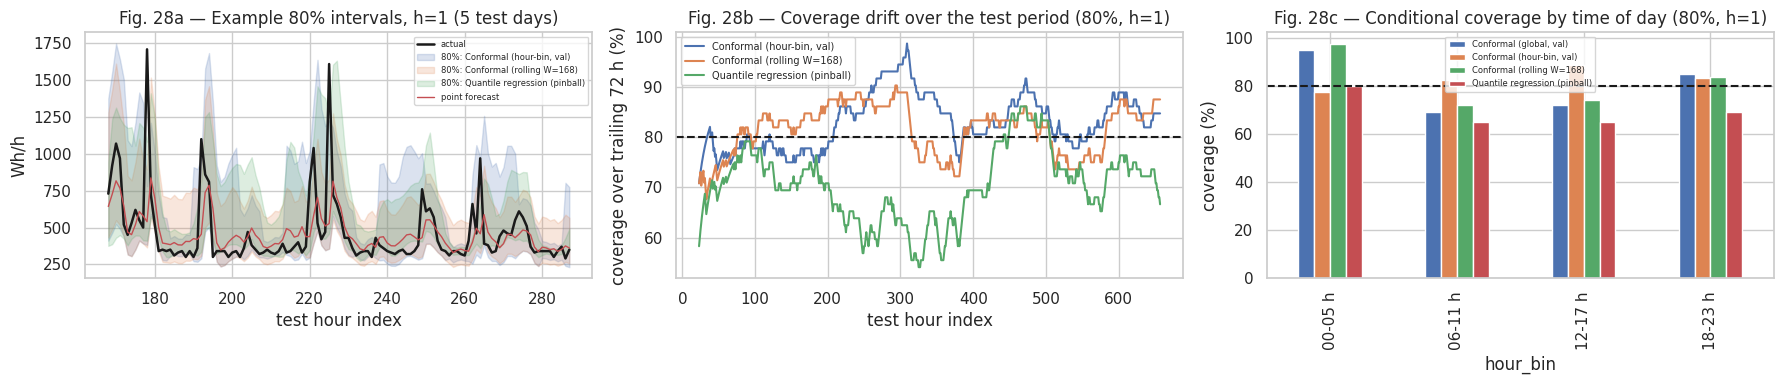

[timer] section 16.4 done: 42.9 min since the Stage-3 timer started


In [47]:
rows_ir = []
for h in HORIZONS:
    Mh = regime_masks(h, T_test)
    for mth in METHODS:
        for lev, a in LEVELS.items():
            lo, hi = INT[(h, mth)][lev]; ind = ((Y_test >= lo) & (Y_test <= hi)).astype(float); isc = interval_scores(Y_test, lo, hi, a)
            for r in REG:
                for side, mk in (("inside", Mh[r]), ("outside", ~Mh[r])):
                    c, cl, ch = cov_ci(ind, mk)
                    rows_ir.append(dict(horizon_h=h, method=mth, nominal_pct=lev, regime=r, side=side, n=int(mk.sum()), coverage_pct=100 * c, cov_lo=100 * cl, cov_hi=100 * ch, gap_pp=100 * c - lev,
                                        width_Wh=(hi - lo)[mk].mean() if mk.sum() else np.nan, interval_score_Wh=isc[mk].mean() if mk.sum() else np.nan))
tir = pd.DataFrame(rows_ir); tir.to_csv(f"{OUT3}/table28_interval_by_regime.csv", index=False)
print("Table 28 — Interval coverage inside/outside each failure regime (h=1, nominal 80% and 90%; full table for all horizons in the CSV)")
display(tir[(tir.horizon_h == 1) & (tir.method.isin(METHODS[:4]))].pivot_table(index=["regime", "side"], columns=["nominal_pct", "method"], values="coverage_pct").round(1))
print("Mean width (Wh/h) inside vs outside the evening regime, h=1, 80%:"); display(tir[(tir.horizon_h == 1) & (tir.nominal_pct == 80) & (tir.regime == "evening") & (tir.method.isin(METHODS[:4]))][["method", "side", "n", "coverage_pct", "width_Wh", "interval_score_Wh"]].round(1))
worst_cov = tir[(tir.side == "inside") & (tir.regime != "top_decile_expost") & (tir.n >= 24)].assign(abs_gap=lambda d: d.gap_pp.abs()).sort_values("abs_gap", ascending=False).head(5)
print("Largest coverage gaps inside a regime (>= 24 hours, excluding the ex-post regime):"); display(worst_cov[["horizon_h", "method", "nominal_pct", "regime", "n", "coverage_pct", "gap_pp"]].round(1))

# coverage by hour-of-day bin (conditional coverage) and rolling coverage over time, h=1
bins_t = BIN(HOUR[T_test]); rows_b = []
for mth in METHODS[:4]:
    lo, hi = INT[(1, mth)][80]; ind = ((Y_test >= lo) & (Y_test <= hi)).astype(float)
    for b in range(4): rows_b.append(dict(method=mth, hour_bin=f"{6 * b:02d}-{6 * b + 5:02d} h", coverage_pct_80=100 * ind[bins_t == b].mean(), width_Wh=(hi - lo)[bins_t == b].mean()))
print("Conditional coverage by time-of-day bin (h=1, nominal 80%)"); display(pd.DataFrame(rows_b).pivot(index="method", columns="hour_bin", values="coverage_pct_80").round(1))
fig, axs = plt.subplots(1, 3, figsize=(18, 4)); xs_ = np.arange(len(Y_test)); s0, s1 = 24 * 7, 24 * 12                        # 5 example days
axs[0].plot(xs_[s0:s1], Y_test[s0:s1], "k", lw=1.8, label="actual")
for mth, col in (("Conformal (hour-bin, val)", "C0"), (f"Conformal (rolling W={W_DECLARED})", "C1"), ("Quantile regression (pinball)", "C2")):
    lo, hi = INT[(1, mth)][80]; axs[0].fill_between(xs_[s0:s1], lo[s0:s1], hi[s0:s1], color=col, alpha=0.2, label=f"80%: {mth}")
axs[0].plot(xs_[s0:s1], to_wh(fin_pred(1, "test"))[s0:s1], color="C3", lw=1, label="point forecast"); axs[0].set_xlabel("test hour index"); axs[0].set_ylabel("Wh/h"); axs[0].legend(fontsize=6)
axs[0].set_title("Fig. 28a — Example 80% intervals, h=1 (5 test days)")
for mth, col in (("Conformal (hour-bin, val)", "C0"), (f"Conformal (rolling W={W_DECLARED})", "C1"), ("Quantile regression (pinball)", "C2")):
    lo, hi = INT[(1, mth)][80]; ind = ((Y_test >= lo) & (Y_test <= hi)).astype(float); axs[1].plot(pd.Series(ind).rolling(72, min_periods=24).mean() * 100, color=col, label=mth)
axs[1].axhline(80, color="k", ls="--"); axs[1].set_xlabel("test hour index"); axs[1].set_ylabel("coverage over trailing 72 h (%)"); axs[1].legend(fontsize=7); axs[1].set_title("Fig. 28b — Coverage drift over the test period (80%, h=1)")
bt_ = pd.DataFrame(rows_b).pivot(index="method", columns="hour_bin", values="coverage_pct_80"); bt_.T.plot(kind="bar", ax=axs[2]); axs[2].axhline(80, color="k", ls="--"); axs[2].set_ylabel("coverage (%)")
axs[2].set_title("Fig. 28c — Conditional coverage by time of day (80%, h=1)"); axs[2].legend(fontsize=6); plt.tight_layout(); plt.savefig(f"{OUT3}/fig28_interval_examples.png", dpi=150); plt.show()
tick("section 16.4 done")

## 17. Robustness and sensitivity
**Questions.** How does the finalist (h = 1) degrade, compared with Ridge and naive, when its *inputs* are corrupted or shifted, and how much of what we reported depends on one seed, one look-back or one HPO draw? At what perturbation does each model stop beating naive?

**Rules.** Perturbations act on **test inputs only**; nothing is refitted on test data and no threshold is tuned on it. The targets used for scoring stay clean. Models are the Stage-2/3 trained ones (finalist = seed-42 model, Ridge, naive). Naive is perturbed too (its forecast is the last *observed* load channel), so each model is compared with naive **under the same perturbation**; the clean-naive MAE is also shown because a deployed system would otherwise fall back to a clean naive forecast.
* **Gaussian noise** σ ∈ {0, 0.1, 0.25, 0.5, 1, 2} (in standardised units) added independently to every observed channel and hour (mean over repeated draws, fixed seeds).
* **Sensor-group masking**: indoor temperature (T1–T9), indoor humidity (RH_1–RH_9), weather (T_out, pressure, RH_out, wind, visibility, dew point), lights, and the Appliances history itself are replaced by their **train median** for the whole test period.
* **Missing block**: every week (168 h) a block of K ∈ {6, 12, 24, 48, 96} h has all observed channels missing, imputed either by the **train median** or by **forward fill** from the last hour before the block (several block offsets, averaged).
* **Calendar ablation**: the 10 calendar channels (input-time and target-time) are replaced by their train mean.
* **Look-back sensitivity**: the finalist family (and Ridge) is *retrained on the training set* with window ∈ {3, 6, 12, 24} and — clearly labelled — **48 h**. A 48 h window starts the first training target 24 h later, so it **removes exactly 24 training windows** (printed by the code); validation/test targets are unchanged.
* **Seed sensitivity**: spread of test MAE over the 5 final seeds. **HPO-trial sensitivity**: spread of the Stage-B *validation* objective across trials.
* **Temperature-shift test**: training uses only the *colder* half of the training hours (threshold = train median of outdoor temperature at the forecast origin); early stopping uses the last 20 % (in time) of those cold training windows, because the validation period may contain too few cold hours (the code prints the count); evaluation is on the *warmer* test hours, compared with the full-data model on the same hours.

Clean test MAE (Wh/h): {'Naive': 198.83, 'Ridge': 182.17, 'RNN ★ tuned': 180.28, 'TFT': 188.73}
Table 31 — Test MAE (Wh/h) under input perturbations (finalist, Ridge, naive; mean over repeated draws; naive is perturbed too)


model                                                                      Naive  Ridge  RNN ★ tuned    TFT
perturbation                         level                  imputation                                     
Gaussian noise (sigma, standardised) 0.0                    -              198.8  182.2        180.3  188.7
                                     0.1                    -              202.8  183.7        181.9  189.1
                                     0.25                   -              219.5  189.2        187.2  190.5
                                     0.5                    -              267.3  205.1        203.5  193.7
                                     1.0                    -              427.4  258.9        246.0  202.5
                                     2.0                    -             1158.2  453.2        324.8  217.2
Sensor group masked (train median)   indoor temperature     median         198.8  200.6        178.4  187.2
                                     indoor humidity        median         198.8  204.2        186.3  193.5
                                     weather                median         198.8  196.7        180.6  189.8
                                     lights                 median         198.8  177.2        177.5  188.9
                                     Appliances history     median         252.2  229.4        236.4  224.0
Missing block (K hours per week)     6                      median         198.0  185.7        181.5  189.7
                                                            forward fill   207.2  184.3        183.2  188.9
                                     12                     median         197.8  186.2        181.7  190.3
                                                            forward fill   213.8  185.8        184.9  188.9
                                     24                     median         205.7  191.2        189.4  195.8
                                                            forward fill   221.0  192.6        191.7  192.6
                                     48                     median         210.5  195.4        195.0  202.2
                                                            forward fill   245.2  202.9        203.6  196.6
                                     96                     median         224.8  207.9        208.6  219.2
                                                            forward fill   291.0  225.3        225.8  203.0
Calendar ablation                    calendar -> train mean -              198.8  203.2        201.8  316.4

Table 32 — Perturbation level at which each model stops beating naive (first tested level with MAE >= naive's)


,perturbation,imputation,model,beats_naive_when_clean,first_level_not_beating_perturbed_naive,first_level_not_beating_clean_naive
0,"Gaussian noise (sigma, standardised)",-,Ridge,True,never (tested range),0.5
1,"Gaussian noise (sigma, standardised)",-,RNN ★ tuned,True,never (tested range),0.5
2,"Gaussian noise (sigma, standardised)",-,TFT,True,never (tested range),1.0
3,Missing block (K hours per week),median,Ridge,True,never (tested range),96
4,Missing block (K hours per week),median,RNN ★ tuned,True,never (tested range),96
5,Missing block (K hours per week),median,TFT,True,never (tested range),48
6,Missing block (K hours per week),forward fill,Ridge,True,never (tested range),48
7,Missing block (K hours per week),forward fill,RNN ★ tuned,True,never (tested range),48
8,Missing block (K hours per week),forward fill,TFT,True,never (tested range),96
9,Sensor group masked (train median),indoor temperature,Ridge,True,loses,loses


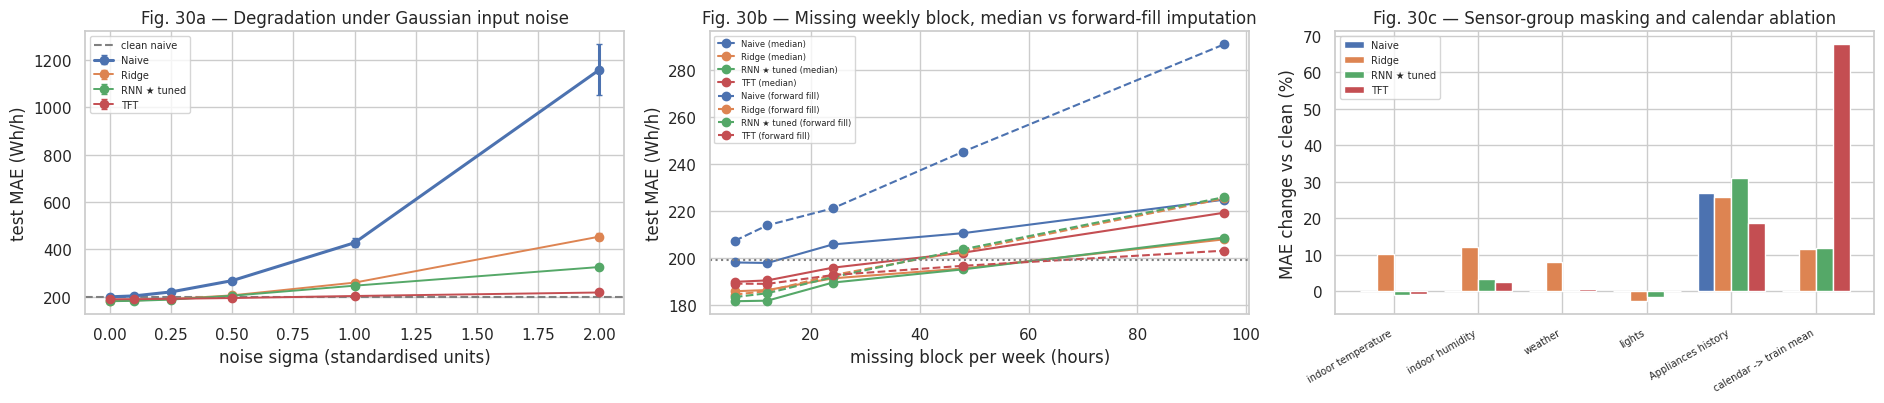

[timer] section 17.1 done: 43.0 min since the Stage-3 timer started


In [48]:
NOISE_SIG, MISS_K = [0.0, 0.1, 0.25, 0.5, 1.0, 2.0], [6, 12, 24, 48, 96]; N_REP = 2 if QUICK else 5
n_obs = len(feat_cols); R0 = n_val_end - MAXW                              # first row that can appear in a test window (L <= MAXW, h >= 1)
med_s = np.median(A[:n_train, :n_obs], axis=0); cal_mean = cal[:n_train].mean(0)                           # train statistics only
GROUPS = {"indoor temperature": [i for i, c in enumerate(feat_cols) if c[0] == "T" and c[1:].isdigit()], "indoor humidity": [i for i, c in enumerate(feat_cols) if c.startswith("RH_") and c[3:].isdigit()],
          "weather": [i for i, c in enumerate(feat_cols) if c in ("T_out", "Press_mm_hg", "RH_out", "Windspeed", "Visibility", "Tdewpoint")], "lights": [feat_cols.index("lights")], "Appliances history": [feat_cols.index("Appliances")]}
assert sum(len(v) for v in GROUPS.values()) == n_obs, "every observed channel must belong to exactly one group"
Lf, Lr = FINAL_CFG["window"], RIDGE_H[1]["L"]; ROB_MODELS = {FINAL_LABEL: (MODELS[(1, FINAL_LABEL)], Lf)}
if TFT_LABEL != FINAL_LABEL: ROB_MODELS[TFT_LABEL] = (MODELS[(1, TFT_LABEL)], TFT_CFG["window"])
def predict_all(Ap, neutral_cal=False):
    '''MAE (Wh/h) of every model when the test inputs are read from the perturbed feature array Ap (clean targets).'''
    out = {"Naive": np.mean(np.abs(inv(Ap[T_test - HORIZON, 0]) - Y_test))}
    def win(L):
        X = make_windows(L, n_val_end, n, HORIZON, A_=Ap)[0]
        if neutral_cal: X[:, :, ic0:] = np.concatenate([cal_mean, cal_mean])                           # input-time AND target-time calendar channels -> train mean
        return X
    Xr = win(Lr); out["Ridge"] = np.mean(np.abs(inv(RIDGE_H[1]["model"].predict(Xr.reshape(len(Xr), -1))) - Y_test))
    for nm, (m, L) in ROB_MODELS.items(): out[nm] = np.mean(np.abs(inv(predict_scaled(m, torch.from_numpy(win(L)).to(DEVICE))) - Y_test))
    return out
clean = predict_all(A.copy()); assert abs(clean["Naive"] - np.mean(np.abs(base[NAIVE]["test"] - Y_test))) < 1e-6 and abs(clean["Ridge"] - np.mean(np.abs(ridge_pred["test"] - Y_test))) < 1e-4
print("Clean test MAE (Wh/h):", {k: round(float(v), 2) for k, v in clean.items()})
rob = []
def add(kind, level, imp, res_list):
    for k in res_list[0]:
        v = np.array([r[k] for r in res_list]); rob.append(dict(perturbation=kind, level=level, imputation=imp, model=k, MAE=v.mean(), MAE_std=v.std(), change_vs_clean_pct=100 * (v.mean() - clean[k]) / clean[k],
                                                               naive_same_perturbation=np.mean([r["Naive"] for r in res_list]), naive_clean=clean["Naive"]))
for sg in NOISE_SIG:
    reps = []
    for rep in range(N_REP if sg > 0 else 1):
        Ap = A.copy(); Ap[R0:, :n_obs] += sg * np.random.default_rng(SEED + rep).standard_normal((n - R0, n_obs)); reps.append(predict_all(Ap))
    add("Gaussian noise (sigma, standardised)", sg, "-", reps)
for gname, cols_g in GROUPS.items():
    Ap = A.copy(); Ap[R0:, cols_g] = med_s[cols_g]; add("Sensor group masked (train median)", gname, "median", [predict_all(Ap)])
for K in MISS_K:
    for imp in ("median", "forward fill"):
        reps = []
        for off in [12, 36, 60, 84, 108][:N_REP]:
            Ap = A.copy()
            for st in range(R0 + off, n, WEEK):
                Ap[st:st + K, :n_obs] = med_s if imp == "median" else A[st - 1, :n_obs]
            reps.append(predict_all(Ap))
        add("Missing block (K hours per week)", K, imp, reps)
add("Calendar ablation", "calendar -> train mean", "-", [predict_all(A.copy(), neutral_cal=True)])
rb = pd.DataFrame(rob); rb.to_csv(f"{OUT3}/table31_robustness.csv", index=False)
print("Table 31 — Test MAE (Wh/h) under input perturbations (finalist, Ridge, naive; mean over repeated draws; naive is perturbed too)")
display(rb.pivot_table(index=["perturbation", "level", "imputation"], columns="model", values="MAE", sort=False).round(1))

# at what perturbation level does each model stop beating naive?
rows_be = []
for kind, imp in [("Gaussian noise (sigma, standardised)", "-"), ("Missing block (K hours per week)", "median"), ("Missing block (K hours per week)", "forward fill")]:
    g = rb[(rb.perturbation == kind) & (rb.imputation == imp)]
    for mdl in [m for m in g.model.unique() if m != "Naive"]:
        gm = g[g.model == mdl].sort_values("level"); lost_p = gm[gm.MAE >= gm.naive_same_perturbation]; lost_c = gm[gm.MAE >= gm.naive_clean]
        rows_be.append(dict(perturbation=kind, imputation=imp, model=mdl, beats_naive_when_clean=bool(gm.iloc[0].MAE < clean["Naive"]), first_level_not_beating_perturbed_naive=(lost_p.level.iloc[0] if len(lost_p) else "never (tested range)"),
                            first_level_not_beating_clean_naive=(lost_c.level.iloc[0] if len(lost_c) else "never (tested range)")))
for kind in ("Sensor group masked (train median)", "Calendar ablation"):
    g = rb[rb.perturbation == kind]
    for mdl in [m for m in g.model.unique() if m != "Naive"]:
        for r_ in g[g.model == mdl].itertuples():
            rows_be.append(dict(perturbation=kind, imputation=str(r_.level), model=mdl, beats_naive_when_clean=bool(clean[mdl] < clean["Naive"]), first_level_not_beating_perturbed_naive=("loses" if r_.MAE >= r_.naive_same_perturbation else "still beats"),
                                first_level_not_beating_clean_naive=("loses" if r_.MAE >= r_.naive_clean else "still beats")))
be = pd.DataFrame(rows_be); be.to_csv(f"{OUT3}/table32_break_even.csv", index=False)
print("Table 32 — Perturbation level at which each model stops beating naive (first tested level with MAE >= naive's)"); display(be)

fig, axs = plt.subplots(1, 3, figsize=(19, 4.2)); gn = rb[rb.perturbation.str.startswith("Gaussian")]
for mdl in [m for m in gn.model.unique()]:
    g = gn[gn.model == mdl].sort_values("level"); axs[0].errorbar(g.level, g.MAE, yerr=g.MAE_std, marker="o", capsize=2, label=mdl, lw=2.2 if mdl == "Naive" else 1.4)
axs[0].axhline(clean["Naive"], color="gray", ls="--", label="clean naive"); axs[0].set_xlabel("noise sigma (standardised units)"); axs[0].set_ylabel("test MAE (Wh/h)"); axs[0].legend(fontsize=7)
axs[0].set_title("Fig. 30a — Degradation under Gaussian input noise")
for imp, ls_ in (("median", "-"), ("forward fill", "--")):
    gm = rb[(rb.perturbation.str.startswith("Missing")) & (rb.imputation == imp)]
    for i, mdl in enumerate(gm.model.unique()): g = gm[gm.model == mdl].sort_values("level"); axs[1].plot(g.level, g.MAE, ls=ls_, marker="o", color=f"C{i}", label=f"{mdl} ({imp})")
axs[1].axhline(clean["Naive"], color="gray", ls=":"); axs[1].set_xlabel("missing block per week (hours)"); axs[1].set_ylabel("test MAE (Wh/h)"); axs[1].legend(fontsize=6); axs[1].set_title("Fig. 30b — Missing weekly block, median vs forward-fill imputation")
gs = rb[rb.perturbation.str.startswith(("Sensor", "Calendar"))]; labs = list(dict.fromkeys(gs.level.astype(str))); xb = np.arange(len(labs)); wd = 0.8 / len(gs.model.unique())
for i, mdl in enumerate(gs.model.unique()):
    g = gs[gs.model == mdl].set_index(gs[gs.model == mdl].level.astype(str)).loc[labs]; axs[2].bar(xb + i * wd, g.change_vs_clean_pct, wd, label=mdl)
axs[2].set_xticks(xb + 0.4 - wd / 2); axs[2].set_xticklabels(labs, rotation=30, ha="right", fontsize=7); axs[2].set_ylabel("MAE change vs clean (%)"); axs[2].legend(fontsize=7); axs[2].set_title("Fig. 30c — Sensor-group masking and calendar ablation")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig30_robustness.png", dpi=150); plt.show()
tick("section 17.1 done")

In [49]:
def sens_data(L):
    '''Train/val/test windows for window length L at h=1. L <= MAXW uses the shared cache; L > MAXW (sensitivity only) starts training later so inputs stay inside the data.'''
    if L <= MAXW: d = get_data(L, HORIZON); return d["train"], d["val"], d["test"]
    mk = lambda a, b: dict(zip(("X", "y", "T"), make_windows(L, a, b, HORIZON)))
    return mk(L + HORIZON - 1, n_train), mk(n_train, n_val_end), mk(n_val_end, n)
tt = lambda d: (torch.from_numpy(d["X"]).to(DEVICE), torch.from_numpy(d["y"]).to(DEVICE))
n_tr_ref = len(get_data(Lf, HORIZON)["train"]["y"]); LB = sorted(set(LOOKBACKS_B + [48])); rows_l, lb_pred = [], {}
for L in LB:
    tr, va, te = sens_data(L); removed = n_tr_ref - len(tr["y"]); assert np.array_equal(te["T"], T_test) and np.array_equal(va["T"], T_val)
    if L > MAXW: print(f"[sensitivity only] window {L} h: {len(tr['y'])} training windows, i.e. {removed} fewer than the {n_tr_ref} used by every other model ({100 * removed / n_tr_ref:.1f}%); val/test targets unchanged")
    Xtr, ytr = tt(tr); Xva, yva = tt(va); Xte, _ = tt(te); maes = []
    for s in FINAL_SEEDS:
        try:
            cfg = {**FINAL_CFG, "window": L}; set_seed(s); m = build(FINAL_FAMILY, cfg); fit(m, cfg, s, HORIZON, data=(Xtr, ytr, Xva, yva)); p = inv(predict_scaled(m, Xte)); lb_pred[(L, s)] = p
            maes.append(np.mean(np.abs(p - Y_test)))
        except Exception as ex: print(f"window {L} failed for {FINAL_FAMILY}: {type(ex).__name__}: {ex}"); break
    best_r = None
    Xtr_f, Xva_f, Xte_f = [d["X"].reshape(len(d["X"]), -1) for d in (tr, va, te)]
    for a_ in [1, 10, 100, 1000, 10000]:
        mv_ = metrics(Y_val, inv(Ridge(alpha=a_).fit(Xtr_f, tr["y"]).predict(Xva_f)))["MAE"]
        if best_r is None or mv_ < best_r[0]: best_r = (mv_, a_)
    pr = inv(Ridge(alpha=best_r[1]).fit(Xtr_f, tr["y"]).predict(Xte_f))
    rows_l.append(dict(window_h=L, role="model window" if L <= MAXW else "SENSITIVITY ONLY", n_train_windows=len(tr["y"]), train_windows_removed_vs_main=removed, finalist_family_MAE_mean=np.mean(maes) if maes else np.nan,
                       finalist_family_MAE_std=np.std(maes) if maes else np.nan, n_seeds=len(maes), Ridge_alpha=best_r[1], Ridge_MAE=np.mean(np.abs(pr - Y_test)), naive_MAE=np.mean(np.abs(base[NAIVE]["test"] - Y_test))))
lbt = pd.DataFrame(rows_l); lbt.to_csv(f"{OUT3}/table33_lookback_sensitivity.csv", index=False)
print(f"Table 33 — Look-back sensitivity of {FINAL_FAMILY} (retrained on train only; test MAE mean ± std over {len(FINAL_SEEDS)} seeds) and Ridge (alpha re-selected on validation)"); display(lbt.round(2))
if Lf in LB and (Lf, SEED) in lb_pred: print(f"Sanity: retrained window-{Lf} seed-{SEED} model vs the stored finalist predictions, max |diff| = {np.abs(lb_pred[(Lf, SEED)] - seed_pred(1, FINAL_LABEL)).max():.3g} Wh/h")

# seed sensitivity (final seeds, every horizon for the finalist, every family at h=1)
rows_sd = []
for (h, label), lst in PRED.items():
    m_ = np.array([np.mean(np.abs(p["test"] - Y_test)) for p in lst]); nv_ = np.mean(np.abs(BASE_TEST_H[h][NAIVE] - Y_test)); rd_ = np.mean(np.abs(RIDGE_TEST_H[h] - Y_test))
    rows_sd.append(dict(horizon_h=h, model=label, n_seeds=len(m_), MAE_mean=m_.mean(), MAE_std=m_.std(), MAE_min=m_.min(), MAE_max=m_.max(), seeds_beating_naive=int((m_ < nv_).sum()), seeds_beating_Ridge=int((m_ < rd_).sum())))
sdt = pd.DataFrame(rows_sd).sort_values(["horizon_h", "MAE_mean"]); sdt.to_csv(f"{OUT3}/table34_seed_sensitivity.csv", index=False)
print("Table 34 — Seed sensitivity of test MAE (counts: seeds whose MAE is below naive's / Ridge's)"); display(sdt[sdt.horizon_h == 1].round(2).reset_index(drop=True))
print("Finalist across horizons:"); display(sdt[sdt.model == FINAL_LABEL].round(2).reset_index(drop=True))

# HPO-trial sensitivity (validation objective only)
tv_ = trials.val_MAE.values; hp = dict(n_trials=len(trials), best=tv_.min(), median=np.median(tv_), worst=tv_.max(), IQR=np.subtract(*np.percentile(tv_, [75, 25])), anchor_trial0=float(trials[trials.trial == 0].val_MAE.iloc[0]),
                                       best_trial_seed_std=float(best_t.val_MAE_std), trials_within_1_std_of_best=int((tv_ <= best_t.val_MAE + best_t.val_MAE_std).sum()), spread_best_to_worst_over_seed_std=(tv_.max() - tv_.min()) / max(float(best_t.val_MAE_std), 1e-9),
                                       selected_trial=int(sel.trial), selected_params=int(sel.params), selected_val_MAE=float(sel.val_MAE))
hpt = pd.DataFrame([hp]); hpt.to_csv(f"{OUT3}/table35_hpo_trial_sensitivity.csv", index=False)
print(f"Table 35 — Variation of the Stage-B validation objective across {len(trials)} {FINAL_FAMILY} trials (validation only)"); display(hpt.round(2))
tick("section 17.2 done")

[sensitivity only] window 48 h: 1925 training windows, i.e. 24 fewer than the 1949 used by every other model (1.2%); val/test targets unchanged
Table 33 — Look-back sensitivity of RNN (retrained on train only; test MAE mean ± std over 5 seeds) and Ridge (alpha re-selected on validation)


,window_h,role,n_train_windows,train_windows_removed_vs_main,finalist_family_MAE_mean,finalist_family_MAE_std,n_seeds,Ridge_alpha,Ridge_MAE,naive_MAE
0,3,model window,1949,0,186.54,2.86,5,100,182.17,198.83
1,6,model window,1949,0,180.37,2.97,5,100,186.59,198.83
2,12,model window,1949,0,179.53,3.13,5,100,185.07,198.83
3,24,model window,1949,0,179.80,3.49,5,100,191.21,198.83
4,48,SENSITIVITY ONLY,1925,24,180.54,3.72,5,1000,204.72,198.83


Sanity: retrained window-24 seed-42 model vs the stored finalist predictions, max |diff| = 0 Wh/h
Table 34 — Seed sensitivity of test MAE (counts: seeds whose MAE is below naive's / Ridge's)


,horizon_h,model,n_seeds,MAE_mean,MAE_std,MAE_min,MAE_max,seeds_beating_naive,seeds_beating_Ridge
0,1,RNN ★ tuned,5,179.80,3.49,177.08,186.40,5,4
1,1,RNN,5,183.30,3.11,180.37,188.64,5,2
2,1,MLP,5,187.83,3.54,183.77,194.36,5,0
3,1,TFT,5,191.89,6.69,184.68,202.20,4,0
4,1,GRU,5,193.06,1.64,190.32,195.03,5,0
5,1,TCN,5,195.64,14.15,181.73,222.59,4,1
6,1,CNN1D,5,199.13,4.63,192.42,205.40,3,0
7,1,CNN2D,5,206.68,10.97,193.31,221.25,2,0
8,1,LSTM,5,216.70,9.75,203.68,231.14,0,0


Finalist across horizons:


,horizon_h,model,n_seeds,MAE_mean,MAE_std,MAE_min,MAE_max,seeds_beating_naive,seeds_beating_Ridge
0,1,RNN ★ tuned,5,179.80,3.49,177.08,186.40,5,4
1,6,RNN ★ tuned,5,232.38,12.17,218.90,254.56,5,0
2,12,RNN ★ tuned,5,223.65,8.41,213.10,236.46,5,1
3,24,RNN ★ tuned,5,208.93,1.55,207.32,211.17,5,0


Table 35 — Variation of the Stage-B validation objective across 30 RNN trials (validation only)


,n_trials,best,median,worst,IQR,anchor_trial0,best_trial_seed_std,trials_within_1_std_of_best,spread_best_to_worst_over_seed_std,selected_trial,selected_params,selected_val_MAE
0,30,190.6,194.52,201.07,3.14,191.26,0.57,2,18.22,8,21377,190.6


[timer] section 17.2 done: 45.8 min since the Stage-3 timer started


Temperature shift: threshold 5.1 C (train median); cold training windows 979/1949, cold validation windows 144/658; test hours warm 626 / cold 32
cold-model fit windows 784, held-out cold windows for early stopping 195 (validation hours are not used here: only 144 of 658 are cold)
Table 36 — Train on colder hours, evaluate on warmer hours (thresholds from train; cold-trained models early-stop on held-out cold TRAIN windows only)


,test_subset,n_hours,model,MAE,MAE_std,vs_naive_pct
0,warm test hours (shifted),626,Naive,198.21,0.00,0.00
1,warm test hours (shifted),626,Ridge (full train),182.87,0.00,7.74
2,warm test hours (shifted),626,Ridge (cold-trained),256.34,0.00,-29.33
3,warm test hours (shifted),626,RNN ★ tuned (full train),180.07,3.67,9.15
4,warm test hours (shifted),626,RNN ★ tuned (cold-trained),253.59,23.05,-27.94
5,cold test hours (in-distribution),32,Naive,210.94,0.00,0.00
6,cold test hours (in-distribution),32,Ridge (full train),168.48,0.00,20.13
7,cold test hours (in-distribution),32,Ridge (cold-trained),172.96,0.00,18.01
8,cold test hours (in-distribution),32,RNN ★ tuned (full train),174.62,2.25,17.22
9,cold test hours (in-distribution),32,RNN ★ tuned (cold-trained),177.66,2.25,15.77


Computed: on warm test hours the cold-trained RNN ★ tuned has MAE 253.6 vs 180.1 for the full-data model (+40.8%), naive 198.2, Ridge cold-trained 256.3.


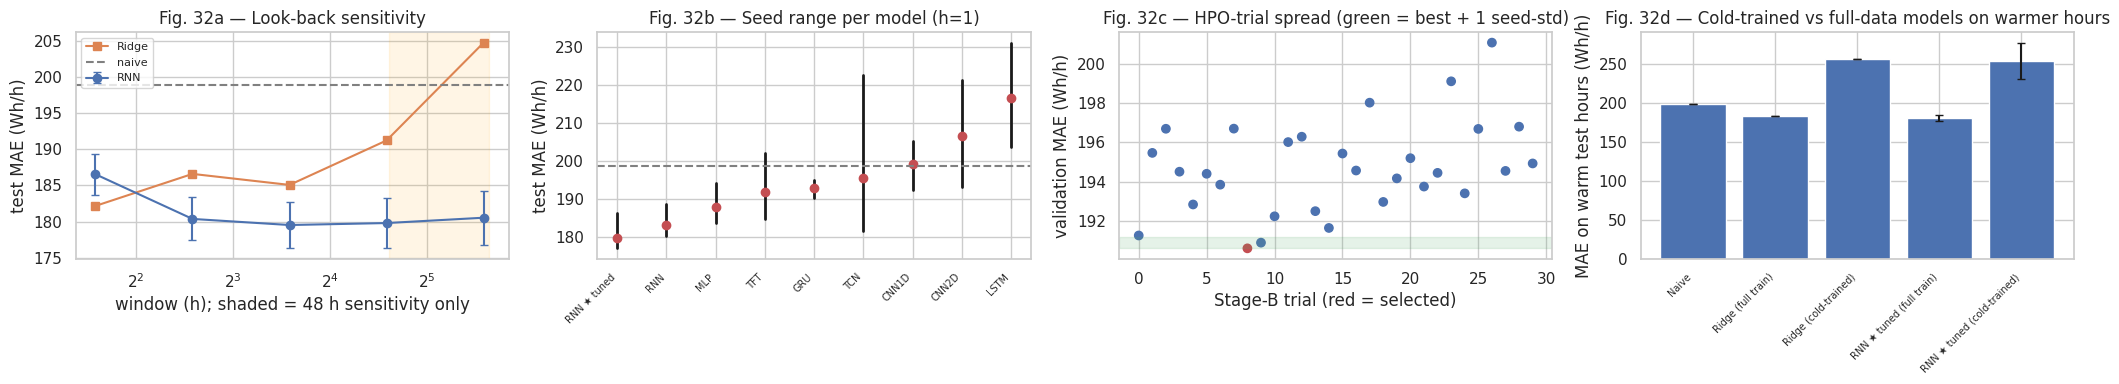

[timer] section 17.3 done: 45.9 min since the Stage-3 timer started


In [50]:
THETA = float(np.median(T_out_all[:n_train]))                              # cold/warm threshold from TRAIN rows only (median outdoor temperature)
dF = get_data(Lf, HORIZON); cold = lambda T: T_out_all[T - HORIZON] < THETA
trm, vam = cold(dF["train"]["T"]), cold(dF["val"]["T"]); warm_te = ~cold(T_test)
print(f"Temperature shift: threshold {THETA:.1f} C (train median); cold training windows {int(trm.sum())}/{len(trm)}, cold validation windows {int(vam.sum())}/{len(vam)}; test hours warm {int(warm_te.sum())} / cold {int((~warm_te).sum())}")
Xall, yall = tens(Lf, "train"); idx_c = np.where(trm)[0]; n_hold = max(30, int(0.2 * len(idx_c))); assert len(idx_c) > 2 * n_hold, "too few cold training windows"
fit_i, hold_i = torch.from_numpy(idx_c[:-n_hold]).to(DEVICE), torch.from_numpy(idx_c[-n_hold:]).to(DEVICE)          # early stopping on the LAST 20% (in time) of the cold training windows
Xtr_c, ytr_c, Xva_c, yva_c = Xall[fit_i], yall[fit_i], Xall[hold_i], yall[hold_i]
print(f"cold-model fit windows {len(fit_i)}, held-out cold windows for early stopping {len(hold_i)} (validation hours are not used here: only {int(vam.sum())} of {len(vam)} are cold)")
cold_pred = {}
for s in FINAL_SEEDS:
    set_seed(s); m = build(FINAL_FAMILY, FINAL_CFG); fit(m, FINAL_CFG, s, HORIZON, data=(Xtr_c, ytr_c, Xva_c, yva_c)); cold_pred[s] = inv(predict_scaled(m, tens(Lf, "test")[0]))
rl = RIDGE_H[1]; dR = get_data(rl["L"], HORIZON); flat = lambda X: X.reshape(len(X), -1)
rid_cold = inv(Ridge(alpha=rl["alpha"]).fit(flat(dR["train"]["X"][cold(dR["train"]["T"])]), dR["train"]["y"][cold(dR["train"]["T"])]).predict(flat(dR["test"]["X"])))
full_pred = {p["seed"]: p["test"] for p in PRED[(1, FINAL_LABEL)]}; nv_p = base[NAIVE]["test"]
rows_t2 = []
for subset, mk in (("warm test hours (shifted)", warm_te), ("cold test hours (in-distribution)", ~warm_te)):
    nm_ = np.mean(np.abs(nv_p - Y_test)[mk]); rid_f = np.mean(np.abs(ridge_pred["test"] - Y_test)[mk]); rid_c = np.mean(np.abs(rid_cold - Y_test)[mk])
    f_full = np.array([np.mean(np.abs(full_pred[s] - Y_test)[mk]) for s in FINAL_SEEDS]); f_cold = np.array([np.mean(np.abs(cold_pred[s] - Y_test)[mk]) for s in FINAL_SEEDS])
    for nm, v in (("Naive", np.array([nm_])), ("Ridge (full train)", np.array([rid_f])), ("Ridge (cold-trained)", np.array([rid_c])), (f"{FINAL_LABEL} (full train)", f_full), (f"{FINAL_LABEL} (cold-trained)", f_cold)):
        rows_t2.append(dict(test_subset=subset, n_hours=int(mk.sum()), model=nm, MAE=v.mean(), MAE_std=v.std(), vs_naive_pct=100 * (nm_ - v.mean()) / nm_))
tst = pd.DataFrame(rows_t2); tst.to_csv(f"{OUT3}/table36_temperature_shift.csv", index=False)
print("Table 36 — Train on colder hours, evaluate on warmer hours (thresholds from train; cold-trained models early-stop on held-out cold TRAIN windows only)"); display(tst.round(2))
w = tst[tst.test_subset.str.startswith("warm")].set_index("model")
print(f"Computed: on warm test hours the cold-trained {FINAL_LABEL} has MAE {w.loc[f'{FINAL_LABEL} (cold-trained)'].MAE:.1f} vs {w.loc[f'{FINAL_LABEL} (full train)'].MAE:.1f} for the full-data model "
      f"({100 * (w.loc[f'{FINAL_LABEL} (cold-trained)'].MAE / w.loc[f'{FINAL_LABEL} (full train)'].MAE - 1):+.1f}%), naive {w.loc['Naive'].MAE:.1f}, Ridge cold-trained {w.loc['Ridge (cold-trained)'].MAE:.1f}.")

fig, axs = plt.subplots(1, 4, figsize=(21, 4))
g = lbt.dropna(subset=["finalist_family_MAE_mean"]); axs[0].errorbar(g.window_h, g.finalist_family_MAE_mean, yerr=g.finalist_family_MAE_std, marker="o", capsize=3, label=FINAL_FAMILY); axs[0].plot(lbt.window_h, lbt.Ridge_MAE, marker="s", label="Ridge")
axs[0].axhline(lbt.naive_MAE.iloc[0], color="gray", ls="--", label="naive"); axs[0].axvspan(MAXW + 0.5, max(LB) + 2, color="orange", alpha=0.1); axs[0].set_xscale("log", base=2); axs[0].set_xlabel("window (h); shaded = 48 h sensitivity only")
axs[0].set_ylabel("test MAE (Wh/h)"); axs[0].legend(fontsize=8); axs[0].set_title("Fig. 32a — Look-back sensitivity")
s1 = sdt[sdt.horizon_h == 1];
for i, (_, r_) in enumerate(s1.iterrows()): axs[1].plot([i, i], [r_.MAE_min, r_.MAE_max], "k-", lw=2); axs[1].plot(i, r_.MAE_mean, "ro")
axs[1].set_xticks(range(len(s1))); axs[1].set_xticklabels(s1.model, rotation=45, ha="right", fontsize=7); axs[1].axhline(np.mean(np.abs(nv_p - Y_test)), color="gray", ls="--"); axs[1].set_ylabel("test MAE (Wh/h)"); axs[1].set_title("Fig. 32b — Seed range per model (h=1)")
axs[2].scatter(trials.trial, trials.val_MAE, c=["r" if t == int(sel.trial) else "C0" for t in trials.trial]); axs[2].axhspan(best_t.val_MAE, best_t.val_MAE + best_t.val_MAE_std, color="g", alpha=0.15)
axs[2].set_xlabel("Stage-B trial (red = selected)"); axs[2].set_ylabel("validation MAE (Wh/h)"); axs[2].set_title("Fig. 32c — HPO-trial spread (green = best + 1 seed-std)")
ww = tst[tst.test_subset.str.startswith("warm")]; axs[3].bar(range(len(ww)), ww.MAE, yerr=ww.MAE_std, capsize=3); axs[3].set_xticks(range(len(ww))); axs[3].set_xticklabels(ww.model, rotation=45, ha="right", fontsize=7)
axs[3].set_ylabel("MAE on warm test hours (Wh/h)"); axs[3].set_title("Fig. 32d — Cold-trained vs full-data models on warmer hours")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig32_sensitivity.png", dpi=150); plt.show()
tick("section 17.3 done")

## 18. Fairness as performance parity across operating conditions (optional analysis)
**What this is and is not.** The data come from **one household** and contain **no protected attributes**, so *demographic* fairness cannot be assessed and nothing below says anything about people. "Fairness" is defined here only as **performance parity across operating conditions**: does the forecast error depend strongly on the weekday/weekend, the time of day, the temperature level, or the load level?

**Groups (all thresholds from training rows only; conditions known at forecast time except the day type and hour, which are properties of the target hour).** day type (weekday / weekend); time of day (four 6-hour bins of the target hour); outdoor-temperature terciles at the forecast origin (train 33rd/67th percentiles); load level (last observed hour below / above the train median).

**Metrics per group (h = 1; finalist, Ridge, naive).** MAE, *relative MAE* = MAE / mean actual load of the group (so that quiet and busy conditions are comparable), bias (mean ŷ − y), group size, 95 % block-bootstrap intervals (groups are resampled with the data, so group sizes vary per resample). **Parity gap** = max − min of the metric across the groups of one dimension, with its bootstrap interval. A gap is not automatically unfair: groups differ in intrinsic predictability, so the finalist's gap is always read next to naive's gap on the same groups. Groups overlap across dimensions, the test period is a single season, and small groups give wide intervals.

Single household, no protected attributes: 'fairness' = parity of accuracy across operating conditions; it says nothing about people or demographic groups.
Table 37 — Accuracy by operating condition, h=1, test (thresholds from train: temperature terciles 3.3/6.6 C, median load 360 Wh/h; 95% block-bootstrap intervals)


,dimension,group,n,MAE,MAE_lo,MAE_hi,rel_MAE,rel_lo,rel_hi,bias,bias_lo,bias_hi,small_group_excluded_from_gap
0,day type,weekday,474,162.40,125.23,207.02,0.30,0.26,0.34,-58.12,-104.65,-18.74,False
1,day type,weekend,184,226.34,153.03,313.75,0.34,0.27,0.39,-106.74,-192.66,-30.93,False
2,time of day (target hour),00-05 h,162,45.92,39.82,52.60,0.14,0.12,0.16,29.29,20.10,37.95,False
3,time of day (target hour),06-11 h,166,250.44,171.80,339.59,0.39,0.32,0.44,-118.83,-213.32,-35.78,False
4,time of day (target hour),12-17 h,168,281.37,211.20,354.74,0.37,0.32,0.42,-186.14,-256.44,-117.45,False
5,time of day (target hour),18-23 h,162,137.90,106.86,172.47,0.24,0.20,0.29,-5.78,-34.33,22.13,False
6,temperature tercile (train thresholds),cold,13,145.03,48.98,224.82,0.32,0.14,0.42,-53.66,-106.80,10.51,True
7,temperature tercile (train thresholds),mild,35,198.78,60.45,445.43,0.36,0.17,0.49,-135.16,-396.95,9.93,False
8,temperature tercile (train thresholds),warm,610,179.97,143.62,217.93,0.31,0.27,0.34,-68.46,-108.87,-31.48,False
9,load level (last hour vs train median),low load,273,64.23,53.89,75.79,0.19,0.16,0.21,22.68,7.96,36.17,False


Groups with fewer than 24 test hours are shown but excluded from the gaps: [['temperature tercile (train thresholds)', 'cold', 13]]
Table 38 — Parity gaps (max − min across the groups of a dimension) with 95% intervals; read the finalist next to naive and Ridge


,dimension,model,horizon_h,MAE_gap,rel_MAE_gap,bias_gap,MAE_gap_lo,rel_MAE_gap_lo,bias_gap_lo,MAE_gap_hi,rel_MAE_gap_hi,bias_gap_hi
0,day type,RNN ★ tuned,1,63.946,0.035,48.625,3.844,0.002,2.561,161.160,0.108,142.116
1,day type,Ridge,1,73.265,0.049,56.273,5.389,0.003,2.685,167.835,0.118,149.246
2,day type,Naive,1,70.958,0.039,0.668,4.159,0.002,0.323,180.537,0.134,30.470
3,time of day (target hour),RNN ★ tuned,1,235.452,0.246,215.433,170.810,0.192,149.334,315.153,0.308,286.714
4,time of day (target hour),Ridge,1,250.411,0.284,184.829,189.967,0.237,122.685,326.484,0.347,280.975
5,time of day (target hour),Naive,1,241.274,0.276,209.753,181.380,0.235,168.723,317.137,0.349,285.707
6,temperature tercile (train thresholds),RNN ★ tuned,1,18.810,0.054,66.704,2.436,0.003,3.055,260.672,0.182,322.913
7,temperature tercile (train thresholds),Ridge,1,20.871,0.058,98.863,3.304,0.004,3.215,278.473,0.202,363.821
8,temperature tercile (train thresholds),Naive,1,13.311,0.003,128.965,2.820,0.002,27.623,199.337,0.169,303.616
9,load level (last hour vs train median),RNN ★ tuned,1,198.344,0.169,161.331,141.612,0.120,107.055,253.846,0.211,215.926


Relative-MAE parity gap, finalist relative to naive (< 1 = the finalist is more even than naive across these conditions):


model,Naive,RNN ★ tuned,Ridge,finalist_gap / naive_gap
dimension,,,,
day type,0.039,0.035,0.049,0.891
load level (last hour vs train median),0.255,0.169,0.191,0.662
temperature tercile (train thresholds),0.003,0.054,0.058,19.999
time of day (target hour),0.276,0.246,0.284,0.890


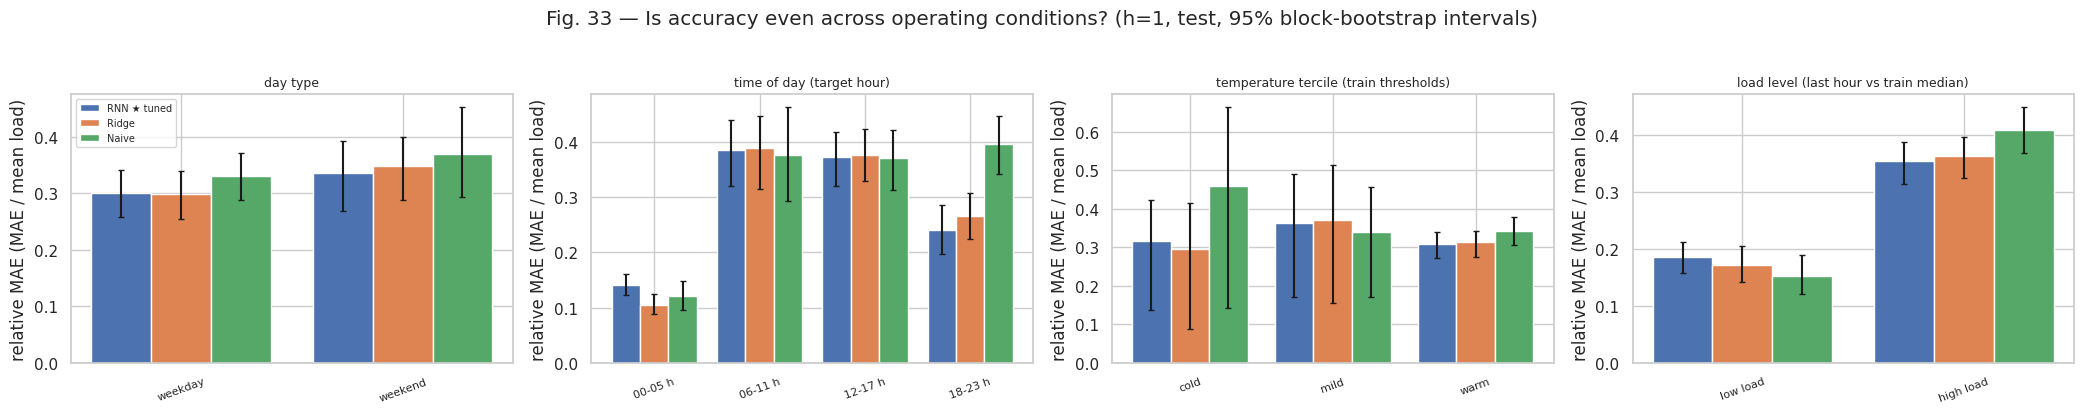

[timer] section 18 done: 46.0 min since the Stage-3 timer started


In [51]:
DOW = dh["date"].dt.dayofweek.values
q33_t, q67_t = np.percentile(T_out_all[:n_train], [100 / 3, 200 / 3]); med_load = float(np.median(y_raw[:n_train]))              # thresholds from TRAIN rows only
def fairness_groups(h, T):
    e = T - h
    return {"day type": {"weekday": DOW[T] < 5, "weekend": DOW[T] >= 5},
            "time of day (target hour)": {f"{6 * b:02d}-{6 * b + 5:02d} h": BIN(HOUR[T]) == b for b in range(4)},
            "temperature tercile (train thresholds)": {"cold": T_out_all[e] < q33_t, "mild": (T_out_all[e] >= q33_t) & (T_out_all[e] < q67_t), "warm": T_out_all[e] >= q67_t},
            "load level (last hour vs train median)": {"low load": y_raw[e] < med_load, "high load": y_raw[e] >= med_load}}
MIN_GROUP = 24                                                            # groups with fewer test hours are shown but excluded from the parity gaps
def group_metrics(pred, masks):
    '''Point estimates and block-bootstrap intervals of MAE, relative MAE and bias per group, and of the max-min parity gaps.'''
    names = list(masks); M = np.stack([masks[k] for k in names]); err, sgn = np.abs(pred - Y_test), pred - Y_test; rows = {}
    Mb = M[:, bidx].astype(float); cnt = Mb.sum(2)                                                                          # (G, B, n) resampled group masks
    with np.errstate(invalid="ignore", divide="ignore"):
        mae_b = (err[bidx][None] * Mb).sum(2) / cnt; bias_b = (sgn[bidx][None] * Mb).sum(2) / cnt; rel_b = mae_b / ((Y_test[bidx][None] * Mb).sum(2) / cnt)
    out = []
    for g, k in enumerate(names):
        mk = M[g]; mae = err[mk].mean() if mk.sum() else np.nan; rel = mae / Y_test[mk].mean() if mk.sum() else np.nan
        out.append(dict(group=k, n=int(mk.sum()), MAE=mae, MAE_lo=np.nanpercentile(mae_b[g], 2.5), MAE_hi=np.nanpercentile(mae_b[g], 97.5), rel_MAE=rel, rel_lo=np.nanpercentile(rel_b[g], 2.5),
                        rel_hi=np.nanpercentile(rel_b[g], 97.5), bias=sgn[mk].mean() if mk.sum() else np.nan, bias_lo=np.nanpercentile(bias_b[g], 2.5), bias_hi=np.nanpercentile(bias_b[g], 97.5)))
    gdf = pd.DataFrame(out); gdf["small_group_excluded_from_gap"] = gdf.n < MIN_GROUP; gap = {}; use = (gdf.n >= MIN_GROUP).values
    ok = (cnt[use] > 0).all(0) if use.sum() >= 2 else np.zeros(cnt.shape[1], bool)
    for nm, arr, pt in (("MAE", mae_b, gdf.MAE.values), ("rel_MAE", rel_b, gdf.rel_MAE.values), ("bias", bias_b, gdf.bias.values)):
        if use.sum() < 2 or not ok.any(): gap[nm] = (np.nan, np.nan, np.nan); continue
        d = arr[use][:, ok].max(0) - arr[use][:, ok].min(0); gap[nm] = (np.max(pt[use]) - np.min(pt[use]), np.percentile(d, 2.5), np.percentile(d, 97.5))
    return gdf, gap
FAIR_MODELS = {FINAL_LABEL: seed_pred(1, FINAL_LABEL), "Ridge": RIDGE_TEST_H[1], "Naive": BASE_TEST_H[1][NAIVE]}
G1 = fairness_groups(1, T_test); rows_f, rows_g2 = [], []
for dim, masks in G1.items():
    for mdl, p in FAIR_MODELS.items():
        gdf, gap = group_metrics(p, masks)
        for r_ in gdf.itertuples(): rows_f.append(dict(dimension=dim, model=mdl, **r_._asdict()))
        rows_g2.append(dict(dimension=dim, model=mdl, horizon_h=1, **{f"{k}_gap": v[0] for k, v in gap.items()}, **{f"{k}_gap_lo": v[1] for k, v in gap.items()}, **{f"{k}_gap_hi": v[2] for k, v in gap.items()}))
for h in HORIZONS[1:]:                                                    # finalist only, other horizons (gap summary)
    for dim, masks in fairness_groups(h, T_test).items():
        _, gap = group_metrics(seed_pred(h, FINAL_LABEL), masks)
        rows_g2.append(dict(dimension=dim, model=FINAL_LABEL, horizon_h=h, **{f"{k}_gap": v[0] for k, v in gap.items()}, **{f"{k}_gap_lo": v[1] for k, v in gap.items()}, **{f"{k}_gap_hi": v[2] for k, v in gap.items()}))
fg = pd.DataFrame(rows_f).drop(columns=["Index"], errors="ignore"); fgap = pd.DataFrame(rows_g2)
fg.to_csv(f"{OUT3}/table37_fairness_groups.csv", index=False); fgap.to_csv(f"{OUT3}/table38_fairness_gaps.csv", index=False)
print("Single household, no protected attributes: 'fairness' = parity of accuracy across operating conditions; it says nothing about people or demographic groups.")
print(f"Table 37 — Accuracy by operating condition, h=1, test (thresholds from train: temperature terciles {q33_t:.1f}/{q67_t:.1f} C, median load {med_load:.0f} Wh/h; 95% block-bootstrap intervals)")
display(fg[fg.model == FINAL_LABEL].drop(columns=["model"]).round(2).reset_index(drop=True))
small = fg[(fg.model == FINAL_LABEL) & fg.small_group_excluded_from_gap]
if len(small): print(f"Groups with fewer than {MIN_GROUP} test hours are shown but excluded from the gaps: {small[['dimension', 'group', 'n']].values.tolist()}")
print("Table 38 — Parity gaps (max − min across the groups of a dimension) with 95% intervals; read the finalist next to naive and Ridge"); display(fgap[fgap.horizon_h == 1].round(3).reset_index(drop=True))
ratio = fgap[(fgap.horizon_h == 1)].pivot(index="dimension", columns="model", values="rel_MAE_gap"); ratio["finalist_gap / naive_gap"] = ratio[FINAL_LABEL] / ratio["Naive"]
print("Relative-MAE parity gap, finalist relative to naive (< 1 = the finalist is more even than naive across these conditions):"); display(ratio.round(3))
fig, axs = plt.subplots(1, 4, figsize=(21, 4)); cols_f = {FINAL_LABEL: "C0", "Ridge": "C1", "Naive": "C2"}
for ax, dim in zip(axs, G1):
    for i, mdl in enumerate(FAIR_MODELS):
        g = fg[(fg.dimension == dim) & (fg.model == mdl)]; x = np.arange(len(g)) + (i - 1) * 0.27
        ax.bar(x, g.rel_MAE, 0.27, yerr=[g.rel_MAE - g.rel_lo, g.rel_hi - g.rel_MAE], capsize=2, color=cols_f[mdl], label=mdl)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.group, fontsize=8, rotation=20); ax.set_title(dim, fontsize=9); ax.set_ylabel("relative MAE (MAE / mean load)")
axs[0].legend(fontsize=7); fig.suptitle("Fig. 33 — Is accuracy even across operating conditions? (h=1, test, 95% block-bootstrap intervals)", y=1.03)
plt.tight_layout(); plt.savefig(f"{OUT3}/fig33_fairness.png", dpi=150, bbox_inches="tight"); plt.show()
tick("section 18 done")

## 19. Deployment profile and limitations (measured, not assumed)
**Questions.** What do the models cost to store, run and retrain; can the finalist be exported and quantised for an edge device; and which limitations follow from the data?

**Method.** For every neural model of §10 (seed 42, h = 1): parameter count and fp32 weight size; **single-sample** and **batched (658 test windows)** inference latency on CPU (default threads and one thread, a rough proxy for a small edge CPU) and on GPU if the session has one, with warm-up and median/95th percentile over repeated runs; retraining cost from the logged training times. Ridge and naive are timed for reference. For the finalist: a TorchScript trace (output must match) and **dynamic int8 quantisation** (size and the change in test MAE — measured on test inputs for reporting only, nothing is tuned). **Jetson-class hardware is not available here**, so edge statements are limited to these proxies and to what has to be measured next. Data requirements and the single-season / single-building limitation are computed from the data itself; drift sensitivity is read from §10.3, §16 and §17 in the summary cells.

Table 39 — Size, latency and training cost (h=1, seed 42; CPU threads 1; GPU available; latencies in ms)


,model,family,window_h,params,weights_fp32_KB,state_dict_KB,cpu_single_ms,cpu_single_p95_ms,cpu_batch658_ms,cpu1thread_single_ms,cpu1thread_batch658_ms,gpu_single_ms,gpu_single_p95_ms,gpu_batch658_ms,train_s_per_fit_mean,train_s_per_fit_std,epochs_mean
0,MLP,MLP,6,16001,62.504,65.271,0.087,0.115,0.458,0.084,0.437,0.242,0.483,0.433,2.566,0.729,33.6
1,CNN1D,CNN1D,6,26209,102.379,105.700,0.244,0.394,11.833,0.244,11.626,0.543,0.629,0.776,2.535,0.117,25.2
2,CNN2D,CNN2D,6,37697,147.254,151.071,0.361,0.458,43.257,0.339,41.887,0.525,0.644,1.420,4.682,1.100,48.0
3,RNN,RNN,24,14913,58.254,60.907,0.765,0.882,17.669,1.124,14.494,0.484,0.534,1.204,4.218,0.425,44.0
4,LSTM,LSTM,6,8993,35.129,37.470,0.466,0.534,3.066,0.511,2.967,0.489,0.581,0.633,3.605,0.237,37.0
5,GRU,GRU,24,44609,174.254,176.907,2.423,2.782,42.586,2.537,45.540,0.364,0.418,2.932,3.552,0.885,32.8
6,TCN,TCN,6,4705,18.379,22.999,0.497,0.683,5.639,0.506,3.611,0.984,1.361,0.867,5.714,1.008,41.4
7,TFT,TFT,6,47593,185.910,207.969,1.998,2.214,21.807,2.001,21.985,2.808,3.175,3.718,14.368,0.927,31.4
8,RNN ★ tuned,RNN,24,21377,83.504,85.845,0.496,0.570,12.207,0.520,11.859,0.338,0.425,1.693,6.320,1.103,36.8
9,Ridge (log target),Ridge,3,109,0.426,NaN,0.094,0.136,0.143,NaN,NaN,NaN,NaN,NaN,0.024,NaN,NaN


Data requirements and single-season / single-building facts: {'span_days': 138, 'months_covered': [1, 2, 3, 4, 5], 'train_hours': 1973, 'train_days': 82.2, 'train_windows': 1949, 'channels_per_step': 36, 'observed_channels': 26, 'min_history_hours': 24, 'stage_A_total_min': np.float64(19.2), 'stage_B_total_min': np.float64(5.0), 'finalist_fit_s': 6.3}
Retraining cost: one finalist fit 6.3 s (35 epochs); Stage A total 19.2 min (summed fit times), Stage B 5.0 min.
Table 40 — Export and quantisation of the finalist


,0
model,RNN ★ tuned
fp32_test_MAE,180.279338
fp32_KB,86.145508
torchscript_trace,ok
torchscript_max_abs_diff_scaled,0.0
int8_test_MAE,180.242946
int8_KB,86.512695
int8_MAE_change_pct,-0.020186
int8_max_abs_forecast_diff_Wh,6.700155
int8_single_ms_cpu,0.600771


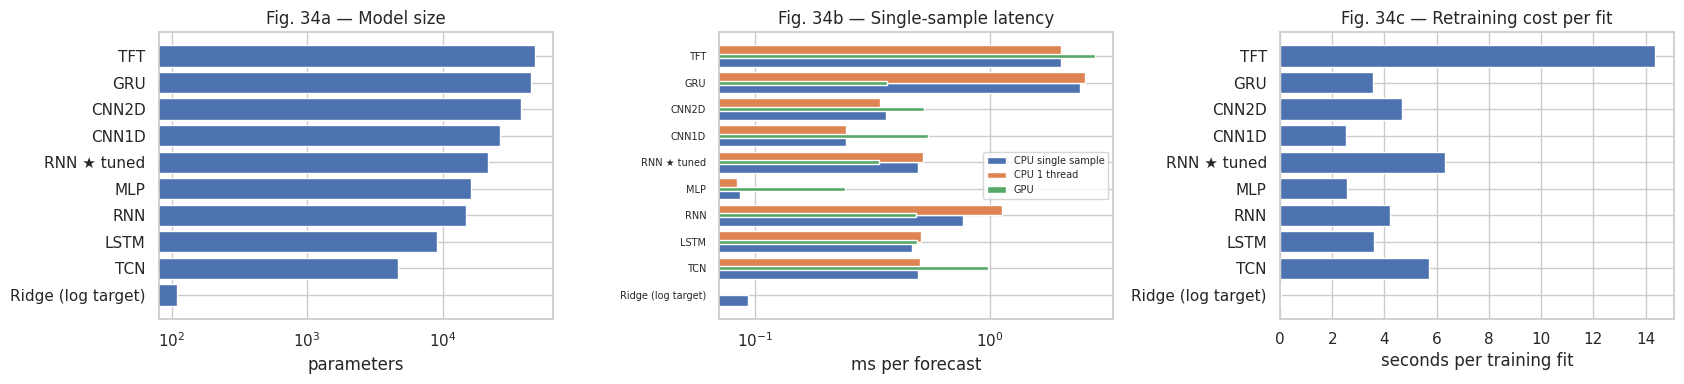

[timer] section 19 done: 46.2 min since the Stage-3 timer started


In [52]:
import copy, io
lab2cfg = {l: (f, c) for l, f, c in entries}
def sync_dev(dev):
    if dev.type == "cuda": torch.cuda.synchronize()
def bench(m, X, dev, n_single=200, n_batch=15):
    m = copy.deepcopy(m).to(dev).eval(); X = X.to(dev); x1 = X[:1]; ts = []
    with torch.no_grad():
        for _ in range(10): m(x1)
        for _ in range(n_single): sync_dev(dev); t0 = time.perf_counter(); m(x1); sync_dev(dev); ts.append((time.perf_counter() - t0) * 1e3)
        for _ in range(3): m(X)
        tb = []
        for _ in range(n_batch): sync_dev(dev); t0 = time.perf_counter(); m(X); sync_dev(dev); tb.append((time.perf_counter() - t0) * 1e3)
    return np.median(ts), np.percentile(ts, 95), np.median(tb)
def wbytes(m): b = io.BytesIO(); torch.save(m.state_dict(), b); return b.tell()
cpu, has_gpu = torch.device("cpu"), torch.cuda.is_available(); n_thr = torch.get_num_threads(); rows_d = []
for label, (fam, cfg) in lab2cfg.items():
    m = MODELS[(1, label)]; L = cfg["window"]; X = tens(L, "test")[0].cpu(); r = dict(model=label, family=fam, window_h=L, params=n_params(m), weights_fp32_KB=4 * n_params(m) / 1024, state_dict_KB=wbytes(m) / 1024)
    r["cpu_single_ms"], r["cpu_single_p95_ms"], r["cpu_batch658_ms"] = bench(m, X, cpu)
    torch.set_num_threads(1); r["cpu1thread_single_ms"], _, r["cpu1thread_batch658_ms"] = bench(m, X, cpu); torch.set_num_threads(n_thr)
    if has_gpu: r["gpu_single_ms"], r["gpu_single_p95_ms"], r["gpu_batch658_ms"] = bench(m, X, torch.device("cuda"))
    pp_ = [p for p in PRED[(1, label)]]; r["train_s_per_fit_mean"], r["train_s_per_fit_std"], r["epochs_mean"] = np.mean([p["train_s"] for p in pp_]), np.std([p["train_s"] for p in pp_]), np.mean([p["epochs"] for p in pp_])
    rows_d.append(r)
Xr_ = get_data(RIDGE_H[1]["L"])["test"]["X"]; Xr_f = Xr_.reshape(len(Xr_), -1); tr_ = []
for _ in range(200): t0 = time.perf_counter(); RIDGE_H[1]["model"].predict(Xr_f[:1]); tr_.append((time.perf_counter() - t0) * 1e3)
tb_ = []
for _ in range(15): t0 = time.perf_counter(); RIDGE_H[1]["model"].predict(Xr_f); tb_.append((time.perf_counter() - t0) * 1e3)
rows_d.append(dict(model="Ridge (log target)", family="Ridge", window_h=RIDGE_H[1]["L"], params=RIDGE_H[1]["params"], weights_fp32_KB=4 * RIDGE_H[1]["params"] / 1024, cpu_single_ms=np.median(tr_), cpu_single_p95_ms=np.percentile(tr_, 95),
                   cpu_batch658_ms=np.median(tb_), train_s_per_fit_mean=RIDGE_H[1]["fit_s"]))
dep = pd.DataFrame(rows_d); dep.to_csv(f"{OUT3}/table39_deployment_profile.csv", index=False)
print(f"Table 39 — Size, latency and training cost (h=1, seed 42; CPU threads {n_thr}; GPU {'available' if has_gpu else 'NOT available in this session -> no GPU columns'}; latencies in ms)"); display(dep.round(3))
span_days = (dh["date"].iloc[-1] - dh["date"].iloc[0]).days + 1; months_cov = sorted(set(dh["date"].dt.month))
DATA_REQ = dict(span_days=span_days, months_covered=months_cov, train_hours=n_train, train_days=n_train / 24, train_windows=len(get_data(Lf)["train"]["y"]), channels_per_step=C, observed_channels=len(feat_cols),
                min_history_hours=max(c["window"] for _, c in lab2cfg.values()), stage_A_total_min=screen.train_s.sum() / 60, stage_B_total_min=trials.train_s.sum() * len(SCREEN_SEEDS) / 60,
                finalist_fit_s=float(dep[dep.model == FINAL_LABEL].train_s_per_fit_mean.iloc[0]))
print("Data requirements and single-season / single-building facts:", {k: (round(v, 1) if isinstance(v, float) else v) for k, v in DATA_REQ.items()})
print(f"Retraining cost: one finalist fit {DATA_REQ['finalist_fit_s']:.1f} s ({PRED[(1, FINAL_LABEL)][0]['epochs']} epochs); Stage A total {DATA_REQ['stage_A_total_min']:.1f} min (summed fit times), Stage B {DATA_REQ['stage_B_total_min']:.1f} min.")

# portability of the finalist: TorchScript trace and dynamic int8 quantisation (test inputs used for REPORTING only)
mf = copy.deepcopy(MODELS[(1, FINAL_LABEL)]).cpu().eval(); Xf = tens(Lf, "test")[0].cpu(); port = dict(model=FINAL_LABEL)
fp32_pred = inv(predict_scaled(mf, Xf)); port["fp32_test_MAE"] = float(np.mean(np.abs(fp32_pred - Y_test))); port["fp32_KB"] = wbytes(mf) / 1024
try:
    with torch.no_grad(): ts_m = torch.jit.trace(mf, Xf[:8]); d_ = float((ts_m(Xf[:64]) - mf(Xf[:64])).abs().max())
    port["torchscript_trace"] = "ok"; port["torchscript_max_abs_diff_scaled"] = d_
except Exception as ex: port["torchscript_trace"] = f"failed: {type(ex).__name__}"
try:
    qm = torch.ao.quantization.quantize_dynamic(copy.deepcopy(mf), {nn.Linear, nn.LSTM, nn.GRU, nn.RNN}, dtype=torch.qint8)
    q_pred = inv(predict_scaled(qm, Xf)); port["int8_test_MAE"] = float(np.mean(np.abs(q_pred - Y_test))); port["int8_KB"] = wbytes(qm) / 1024
    port["int8_MAE_change_pct"] = 100 * (port["int8_test_MAE"] - port["fp32_test_MAE"]) / port["fp32_test_MAE"]; port["int8_max_abs_forecast_diff_Wh"] = float(np.abs(q_pred - fp32_pred).max())
    port["int8_single_ms_cpu"] = bench(qm, Xf, cpu, n_single=100, n_batch=5)[0]
except Exception as ex: port["int8"] = f"failed: {type(ex).__name__}: {ex}"
pt_ = pd.DataFrame([port]); pt_.to_csv(f"{OUT3}/table40_portability.csv", index=False); print("Table 40 — Export and quantisation of the finalist"); display(pt_.T)

fig, axs = plt.subplots(1, 3, figsize=(17, 4)); dn = dep.sort_values("params")
axs[0].barh(dn.model, dn.params); axs[0].set_xscale("log"); axs[0].set_xlabel("parameters"); axs[0].set_title("Fig. 34a — Model size")
axs[1].barh(np.arange(len(dn)) - 0.2, dn.cpu_single_ms, 0.4, label="CPU single sample"); axs[1].barh(np.arange(len(dn)) + 0.2, dn.get("cpu1thread_single_ms", pd.Series(np.nan, index=dn.index)).values, 0.4, label="CPU 1 thread")
if has_gpu: axs[1].barh(np.arange(len(dn)) + 0.0, dn.gpu_single_ms.values, 0.15, label="GPU")
axs[1].set_yticks(range(len(dn))); axs[1].set_yticklabels(dn.model, fontsize=7); axs[1].set_xscale("log"); axs[1].set_xlabel("ms per forecast"); axs[1].legend(fontsize=7); axs[1].set_title("Fig. 34b — Single-sample latency")
axs[2].barh(dn.model, dn.train_s_per_fit_mean); axs[2].set_xlabel("seconds per training fit"); axs[2].set_title("Fig. 34c — Retraining cost per fit")
plt.tight_layout(); plt.savefig(f"{OUT3}/fig34_deployment.png", dpi=150); plt.show()
tick("section 19 done")

## 20. Auto-generated results summary
Everything in this section is produced by code from the tables above. The next cell collects the key quantities in one table (`results_stage3/summary_facts.csv`) and prints them grouped by topic, together with the timing log of this run. Nothing here is typed in by hand.

In [53]:
SUMF = {}                                                                   # SUMF[key] = value (all computed)
H1 = 1; fin_row = lambda h, lab=None: hz[(hz.horizon_h == h) & (hz.model == (lab or FINAL_LABEL))].iloc[0]
def bsig(h, lab, ref):
    r = bh[(bh.horizon_h == h) & (bh.model == lab) & (bh.reference == ref)].iloc[0]; return r.rel_pct, r.rel_lo, r.rel_hi, ("better" if r.CI_lo > 0 else "worse" if r.CI_hi < 0 else "no reliable difference")      # point estimate and interval in %; verdict from the sign of the interval
SUMF["mode"] = "QUICK" if QUICK else "full"; SUMF["finalist"] = FINAL_LABEL; SUMF["finalist_family"] = FINAL_FAMILY; SUMF["finalist_cfg"] = FINAL_CFG; SUMF["finalist_params"] = int(n_params(MODELS[(1, FINAL_LABEL)]))
ba = best_A.sort_values("val_MAE").reset_index(drop=True); SUMF["stageA_rank_of_TFT"] = int(ba.index[ba.family == "TFT"][0]) + 1; SUMF["stageA_best_family"] = ba.family.iloc[0]
SUMF["TFT_stageA_val_MAE"] = float(ba[ba.family == "TFT"].val_MAE.iloc[0]); SUMF["best_stageA_val_MAE"] = float(ba.val_MAE.iloc[0]); SUMF["TFT_is_finalist"] = (FINAL_FAMILY == "TFT"); SUMF["TFT_label"] = TFT_LABEL
SUMF["TFT_params_stageA"] = int(ba[ba.family == "TFT"].params.iloc[0])
for h in HORIZONS:
    r = fin_row(h); SUMF[f"h{h}_finalist_MAE"] = float(r.test_MAE); SUMF[f"h{h}_vs_naive_pct"] = float(r.MAE_vs_naive_pct); SUMF[f"h{h}_vs_Ridge_pct"] = float(r.MAE_vs_Ridge_pct)
    SUMF[f"h{h}_boot_vs_naive"] = bsig(h, FINAL_LABEL, "naive"); SUMF[f"h{h}_boot_vs_Ridge"] = bsig(h, FINAL_LABEL, "Ridge (log target)")
    SUMF[f"h{h}_n_models_beat_Ridge_sig"] = int(((bh.horizon_h == h) & (bh.reference == "Ridge (log target)") & (bh.CI_lo > 0)).sum()); SUMF[f"h{h}_n_models_beat_naive_sig"] = int(((bh.horizon_h == h) & (bh.reference == "naive") & (bh.model != "Ridge (log target)") & (bh.CI_lo > 0)).sum())
    SUMF[f"h{h}_Ridge_vs_naive"] = bsig(h, "Ridge (log target)", "naive")
if TFT_LABEL != FINAL_LABEL: SUMF["TFT_h1_vs_naive_pct"] = float(fin_row(1, TFT_LABEL).MAE_vs_naive_pct); SUMF["TFT_h1_vs_Ridge_pct"] = float(fin_row(1, TFT_LABEL).MAE_vs_Ridge_pct); SUMF["TFT_h1_boot_vs_Ridge"] = bsig(1, TFT_LABEL, "Ridge (log target)")
SUMF["dominant_period_h"] = float(DOM_PERIOD_H); SUMF["significant_periods_h"] = [int(r.period_h) for r in spec_tab.itertuples() if r.significant]; SUMF["daily_strength"] = STRENGTH_DAILY; SUMF["weekly_strength"] = STRENGTH_WEEKLY
SUMF["band_labels"] = BAND_LABELS; SUMF["resid_acf_lag24"] = float(res_tab[res_tab.model == FINAL_LABEL].acf_lag24.iloc[0]); SUMF["resid_LB_p24"] = float(res_tab[res_tab.model == FINAL_LABEL].ljung_box_p_lag24.iloc[0])
sk = bh3[(bh3.horizon_h == 1)].set_index("band"); SUMF["band_skill_vs_Ridge_h1"] = {b: float(sk.loc[b].skill_vs_Ridge) for b in BAND_LABELS}; SUMF["band_skill_vs_naive_h1"] = {b: float(sk.loc[b].skill_vs_naive) for b in BAND_LABELS}
ad = att[att.kind.str.startswith("diag")]; SUMF["attn_lag24_ratio_by_h"] = {int(h): float(ad[ad.horizon_h == h].ratio_lag24_to_others.mean()) for h in HORIZONS}; SUMF["attn_lag24_rank_by_h"] = {int(h): float(ad[ad.horizon_h == h].rank_of_lag24.mean()) for h in HORIZONS}
SUMF["selected_TFT_window"] = int(TFT_CFG["window"])
ev_in = rg[(rg.horizon_h == 1) & (rg.model == FINAL_LABEL) & (rg.regime == "evening") & (rg.side == "inside")].iloc[0]; ev_out = rg[(rg.horizon_h == 1) & (rg.model == FINAL_LABEL) & (rg.regime == "evening") & (rg.side == "outside")].iloc[0]
SUMF["evening_MAE_in"], SUMF["evening_MAE_out"], SUMF["evening_bias_in"] = float(ev_in.MAE), float(ev_out.MAE), float(ev_in.bias); SUMF["evening_vs_naive_in"] = (float(ev_in.vs_naive_pct), float(ev_in.vs_naive_lo), float(ev_in.vs_naive_hi))
SUMF["evening_vs_Ridge_in"] = (float(ev_in.vs_Ridge_pct), float(ev_in.vs_Ridge_lo), float(ev_in.vs_Ridge_hi)); SUMF["evening_n"] = int(ev_in.n)
reg_in = rg[(rg.horizon_h == 1) & (rg.model == FINAL_LABEL) & (rg.side == "inside") & (rg.regime != "top_decile_expost") & (rg.n >= 24)]
SUMF["regimes_finalist_sig_worse_than_Ridge"] = reg_in[reg_in.vs_Ridge_hi < 0].regime.tolist(); SUMF["regimes_finalist_sig_better_than_Ridge"] = reg_in[reg_in.vs_Ridge_lo > 0].regime.tolist(); SUMF["regimes_finalist_sig_worse_than_naive"] = reg_in[reg_in.vs_naive_hi < 0].regime.tolist()
SUMF["mitigation"] = MITIGATION
t1 = ti[(ti.horizon_h == 1) & ~ti.method.str.startswith("[sens")]; SUMF["interval_h1"] = {(r.method, r.nominal_pct): (float(r.coverage_pct), float(r.cov_lo), float(r.cov_hi), float(r.width_Wh), float(r.interval_score_Wh), bool(r.nominal_inside_CI)) for r in t1.itertuples()}
SUMF["rolling_closer_hourbin"] = int(tv.rolling_closer_than_hourbin.sum()); SUMF["rolling_cases"] = len(tv); SUMF["rolling_calibrated"] = int(tv.rolling_calibrated.sum()); SUMF["static_gap_mean_pp"] = float(tv.gap_hourbin_pp.mean()); SUMF["rolling_gap_mean_pp"] = float(tv.gap_rolling_pp.mean())
SUMF["static_abs_gap_mean_pp"] = float(tv.gap_hourbin_pp.abs().mean()); SUMF["rolling_abs_gap_mean_pp"] = float(tv.gap_rolling_pp.abs().mean())
SUMF["interval_methods_calibrated_all_cases"] = {m: int(ti[(ti.method == m)].nominal_inside_CI.sum()) for m in METHODS}; SUMF["interval_n_cases_per_method"] = int(len(ti[ti.method == METHODS[0]]))
SUMF["clean_MAE"] = {k: float(v) for k, v in clean.items()}
def first_lost(kind, imp, mdl, key="first_level_not_beating_perturbed_naive"):
    g = be[(be.perturbation == kind) & (be.imputation == imp) & (be.model == mdl)]; return g[key].iloc[0] if len(g) else "n/a"
SUMF["noise_break_even_finalist"] = first_lost("Gaussian noise (sigma, standardised)", "-", FINAL_LABEL); SUMF["noise_break_even_Ridge"] = first_lost("Gaussian noise (sigma, standardised)", "-", "Ridge")
SUMF["noise_break_even_finalist_clean_naive"] = first_lost("Gaussian noise (sigma, standardised)", "-", FINAL_LABEL, "first_level_not_beating_clean_naive"); SUMF["noise_break_even_Ridge_clean_naive"] = first_lost("Gaussian noise (sigma, standardised)", "-", "Ridge", "first_level_not_beating_clean_naive")
sg_ = rb[(rb.perturbation.str.startswith("Sensor")) & (rb.model == FINAL_LABEL)].sort_values("change_vs_clean_pct", ascending=False); SUMF["worst_sensor_group"] = (sg_.level.iloc[0], float(sg_.change_vs_clean_pct.iloc[0])); SUMF["sensor_group_changes"] = {r.level: float(r.change_vs_clean_pct) for r in sg_.itertuples()}
SUMF["calendar_ablation_change_pct"] = {m: float(rb[(rb.perturbation == "Calendar ablation") & (rb.model == m)].change_vs_clean_pct.iloc[0]) for m in rb.model.unique()}
mb_ = rb[(rb.perturbation.str.startswith("Missing")) & (rb.model == FINAL_LABEL)]; SUMF["missing_block_max_change_pct"] = float(mb_.change_vs_clean_pct.max()); SUMF["noise_max_change_pct"] = float(rb[(rb.perturbation.str.startswith("Gauss")) & (rb.model == FINAL_LABEL)].change_vs_clean_pct.max())
SUMF["worst_perturbation_change_pct_finalist"] = float(rb[rb.model == FINAL_LABEL].change_vs_clean_pct.max())
SUMF["lookback_best_window"] = int(lbt.loc[lbt.finalist_family_MAE_mean.idxmin()].window_h) if lbt.finalist_family_MAE_mean.notna().any() else None; SUMF["lookback_table"] = lbt[["window_h", "finalist_family_MAE_mean", "finalist_family_MAE_std", "Ridge_MAE"]].round(2).to_dict("records")
s1_ = sdt[(sdt.horizon_h == 1) & (sdt.model == FINAL_LABEL)].iloc[0]; SUMF["seed_MAE_mean_std_min_max"] = (float(s1_.MAE_mean), float(s1_.MAE_std), float(s1_.MAE_min), float(s1_.MAE_max)); SUMF["seeds_beating_Ridge"] = (int(s1_.seeds_beating_Ridge), int(s1_.n_seeds)); SUMF["seeds_beating_naive"] = (int(s1_.seeds_beating_naive), int(s1_.n_seeds))
SUMF["hpo_spread"] = hp
wm = tst[tst.test_subset.str.startswith("warm")].set_index("model"); SUMF["tempshift_cold_trained_MAE"] = float(wm.loc[f"{FINAL_LABEL} (cold-trained)"].MAE); SUMF["tempshift_full_MAE"] = float(wm.loc[f"{FINAL_LABEL} (full train)"].MAE); SUMF["tempshift_naive_MAE"] = float(wm.loc["Naive"].MAE)
SUMF["tempshift_degradation_pct"] = 100 * (SUMF["tempshift_cold_trained_MAE"] / SUMF["tempshift_full_MAE"] - 1); SUMF["tempshift_ridge_cold"] = float(wm.loc["Ridge (cold-trained)"].MAE); SUMF["test_minus_train_Tout"] = float(shift_tab.test_mean_Tout.iloc[0] - shift_tab.train_mean_Tout.iloc[0]); SUMF["test_minus_val_Tout"] = float(shift_tab.test_mean_Tout.iloc[0] - shift_tab.val_mean_Tout.iloc[0])
fgm = fgap[(fgap.horizon_h == 1)].set_index(["dimension", "model"]); SUMF["fair_rel_gap"] = {d_: (float(fgm.loc[(d_, FINAL_LABEL)].rel_MAE_gap), float(fgm.loc[(d_, FINAL_LABEL)].rel_MAE_gap_lo), float(fgm.loc[(d_, FINAL_LABEL)].rel_MAE_gap_hi), float(fgm.loc[(d_, "Naive")].rel_MAE_gap)) for d_ in G1}
SUMF["fair_max_group"] = {d_: fg[(fg.dimension == d_) & (fg.model == FINAL_LABEL) & (fg.n >= MIN_GROUP)].sort_values("rel_MAE").iloc[-1].group for d_ in G1}
dfin = dep[dep.model == FINAL_LABEL].iloc[0]; SUMF["deploy"] = {k: (float(dfin[k]) if k in dfin.index and pd.notna(dfin[k]) else None) for k in ("params", "weights_fp32_KB", "state_dict_KB", "cpu_single_ms", "cpu_single_p95_ms", "cpu_batch658_ms", "cpu1thread_single_ms", "gpu_single_ms", "gpu_batch658_ms", "train_s_per_fit_mean")}
SUMF["has_gpu"] = has_gpu; SUMF["portability"] = {k: v for k, v in port.items()}; SUMF["data_req"] = DATA_REQ; SUMF["timing_min"] = TIMING[-1]["minutes_since_start"]
summary_df = pd.DataFrame([dict(key=k, value=str(v)) for k, v in SUMF.items()]); summary_df.to_csv(f"{OUT3}/summary_facts.csv", index=False)
pd.DataFrame(TIMING).to_csv(f"{OUT3}/timing_log.csv", index=False)
print(f"Summary facts collected: {len(SUMF)} keys -> {OUT3}/summary_facts.csv. Wall-clock since the Stage-3 timer started: {SUMF['timing_min']:.1f} min ({SUMF['mode']} mode).")
display(pd.DataFrame(TIMING))
for k in ("finalist", "finalist_cfg", "stageA_rank_of_TFT", "TFT_is_finalist", "h1_boot_vs_naive", "h1_boot_vs_Ridge", "mitigation", "tempshift_degradation_pct", "deploy"): print(f"{k}: {SUMF[k]}")

Summary facts collected: 110 keys -> results_stage3/summary_facts.csv. Wall-clock since the Stage-3 timer started: 46.2 min (full mode).


,section,minutes_since_start
0,section 0 done,0.00
1,section 4.1 done,1.21
2,section 5.1 done,1.22
3,section 6.1 done,1.32
4,section 7.1 done,1.69
5,section 10.1 (vs Ridge) done,30.06
6,section 10.3 retraining done,38.72
7,section 10.3 table done,38.74
8,section 10.3 bootstrap done,38.77
9,smoke test v2 done,38.77


finalist: RNN ★ tuned
finalist_cfg: {'window': 24, 'dropout': 0.1, 'lr': 0.00035, 'batch': 32, 'wd': 0.0, 'loss': 'L1', 'hidden': 128, 'layers': 1}
stageA_rank_of_TFT: 6
TFT_is_finalist: False
h1_boot_vs_naive: (np.float64(9.329797009305585), np.float64(1.6702003796661227), np.float64(16.298150575381108), 'better')
h1_boot_vs_Ridge: (np.float64(1.0377545275257778), np.float64(-2.2152061846933426), np.float64(4.262661460887826), 'no reliable difference')
mitigation: {'tau': 0.6, 'evening_change_pct': 1.1434701081730123, 'evening_ci': (-3.0085164031901366, 4.367896623019129), 'overall_change_pct': -0.27217972491845993, 'overall_ci': (-2.075538829458681, 1.3315870753554047), 'evening_bias_before': -231.91069118103226, 'evening_bias_after': -176.9615056834518, 'helped_evening': False, 'hurt_overall': False}
tempshift_degradation_pct: 40.8279184772792
deploy: {'params': 21377.0, 'weights_fp32_KB': 83.50390625, 'state_dict_KB': 85.8447265625, 'cpu_single_ms': 0.4959375003181776, 'cpu_single_

## 21. Stage 3 conclusions, deployment limitations and prioritised next steps
The next cell writes the conclusions **from the computed values in §20**: every sentence is a template whose numbers and wording (“beats”, “does not reliably beat”, “calibrated”, …) are chosen by the code from the bootstrap intervals and tables. If a result is mixed the text says so; no result is asserted that the numbers do not support. The conclusions are saved to `results_stage3/stage3_conclusions.md`.

**How the next steps are prioritised (rule fixed in advance).** Tier 1 = *validity*: findings that limit whether any deployment claim can be trusted (distribution shift, calibration under shift); tier 2 = *accuracy*: gaps in where the model is wrong; tier 3 = *engineering*: cost and robustness. Inside a tier, items are ordered by the size of the computed shortfall they address (the figure quoted in the item). Every item names the evidence that motivates it.

In [54]:
from IPython.display import Markdown
def verdict(t):                                   # t = (rel_pct, lo, hi, text)
    return f"{t[0]:+.1f}% [{t[1]:+.1f}, {t[2]:+.1f}] ({t[3]})"
def cal_txt(m, lev): c = SUMF["interval_h1"][(m, lev)]; return f"{c[0]:.1f}% [{c[1]:.1f}, {c[2]:.1f}] ({'nominal inside the interval' if c[5] else 'nominal outside the interval'}), width {c[3]:.0f} Wh/h"
L_ = []; add_ = L_.append
add_(f"### Stage 3 conclusions (generated from this run, mode: {SUMF['mode']}; wall-clock {SUMF['timing_min']:.1f} min)\n")
add_("**1. Model selection and the Transformer.** " + (f"The Transformer (TFT-lite, {SUMF['TFT_params_stageA']:,} parameters at its Stage-A configuration) was selected as the finalist under the unchanged protocol (lowest Stage-A validation MAE, then Stage B and the parsimony rule)."
     if SUMF["TFT_is_finalist"] else f"The Transformer ranked {SUMF['stageA_rank_of_TFT']} of 8 families on Stage-A validation MAE ({SUMF['TFT_stageA_val_MAE']:.2f} vs {SUMF['best_stageA_val_MAE']:.2f} for {SUMF['stageA_best_family']}) and was therefore **not** selected and not tuned further; the finalist is {SUMF['finalist']} ({SUMF['finalist_params']:,} parameters)."))
add_(f" Selected configuration: {SUMF['finalist_cfg']}.\n")
add_(f"**2. Accuracy at h = 1 (test, Wh/h).** The finalist's MAE is {SUMF['h1_finalist_MAE']:.1f}: {SUMF['h1_vs_naive_pct']:+.1f}% vs naive and {SUMF['h1_vs_Ridge_pct']:+.1f}% vs Ridge. Paired 24 h block bootstrap vs naive: {verdict(SUMF['h1_boot_vs_naive'])}; vs Ridge: {verdict(SUMF['h1_boot_vs_Ridge'])}. "
     f"Ridge vs naive: {verdict(SUMF['h1_Ridge_vs_naive'])}. Across the 5 final seeds the finalist's MAE has mean {SUMF['seed_MAE_mean_std_min_max'][0]:.1f}, std {SUMF['seed_MAE_mean_std_min_max'][1]:.1f} (range {SUMF['seed_MAE_mean_std_min_max'][2]:.1f}-{SUMF['seed_MAE_mean_std_min_max'][3]:.1f}); "
     f"{SUMF['seeds_beating_Ridge'][0]}/{SUMF['seeds_beating_Ridge'][1]} seeds beat Ridge and {SUMF['seeds_beating_naive'][0]}/{SUMF['seeds_beating_naive'][1]} beat naive.")
if "TFT_h1_boot_vs_Ridge" in SUMF: add_(f" The Transformer row (not the finalist) is {SUMF['TFT_h1_vs_naive_pct']:+.1f}% vs naive and {SUMF['TFT_h1_vs_Ridge_pct']:+.1f}% vs Ridge; vs Ridge {verdict(SUMF['TFT_h1_boot_vs_Ridge'])}.")
add_("\n")
add_("**3. Longer horizons (hyper-parameters from h = 1, not re-tuned).** " + "; ".join(f"h={h}: {SUMF[f'h{h}_finalist_MAE']:.1f} Wh/h, {SUMF[f'h{h}_vs_naive_pct']:+.1f}% vs naive ({SUMF[f'h{h}_boot_vs_naive'][3]}), {SUMF[f'h{h}_vs_Ridge_pct']:+.1f}% vs Ridge ({SUMF[f'h{h}_boot_vs_Ridge'][3]})" for h in HORIZONS)
     + f". Number of neural rows whose interval excludes zero in their favour vs Ridge: " + ", ".join(f"h={h}: {SUMF[f'h{h}_n_models_beat_Ridge_sig']}" for h in HORIZONS) + "; vs naive: " + ", ".join(f"h={h}: {SUMF[f'h{h}_n_models_beat_naive_sig']}" for h in HORIZONS) + ". (At h = 24 naive and seasonal naive are identical.)\n")
add_(f"**4. Time and frequency structure (training data).** The strongest spectral peak is at {SUMF['dominant_period_h']:.0f} h; candidate periods above the red-noise level: {SUMF['significant_periods_h'] or 'none'}. MSTL strength: daily {SUMF['daily_strength']:.2f}, weekly {SUMF['weekly_strength']:.2f}. "
     f"The finalist's residual ACF at lag 24 is {SUMF['resid_acf_lag24']:+.2f} (Ljung-Box p at lag 24 = {SUMF['resid_LB_p24']:.3g}). Skill by frequency band at h = 1 (vs Ridge / vs naive): " + "; ".join(f"{b}: {SUMF['band_skill_vs_Ridge_h1'][b]:+.2f} / {SUMF['band_skill_vs_naive_h1'][b]:+.2f}" for b in SUMF["band_labels"])
     + f". Attention of the window-24 diagnostic Transformer on lag 24 relative to the mean of the other lags: " + ", ".join(f"h={h}: {SUMF['attn_lag24_ratio_by_h'][h]:.2f}x (rank {SUMF['attn_lag24_rank_by_h'][h]:.1f}/24)" for h in HORIZONS)
     + f"; the selected Transformer's window is {SUMF['selected_TFT_window']} h" + (" (lag 24 only appears in windows of 24 h at h=1)" if SUMF['selected_TFT_window'] < 24 else "") + ". Attention shows where the model reads, not why it is accurate.\n")
add_(f"**5. Failure regime.** Evening ramp (hours 16-19, {SUMF['evening_n']} test hours): finalist MAE {SUMF['evening_MAE_in']:.1f} inside vs {SUMF['evening_MAE_out']:.1f} outside, bias {SUMF['evening_bias_in']:+.1f} Wh/h; vs naive inside {verdict((*SUMF['evening_vs_naive_in'], 'x'))[:-4]}; vs Ridge inside {verdict((*SUMF['evening_vs_Ridge_in'], 'x'))[:-4]}. "
     f"Regimes where the finalist is reliably worse than Ridge: {SUMF['regimes_finalist_sig_worse_than_Ridge'] or 'none'}; reliably better: {SUMF['regimes_finalist_sig_better_than_Ridge'] or 'none'}; reliably worse than naive: {SUMF['regimes_finalist_sig_worse_than_naive'] or 'none'}. "
     + ("Mitigation (asymmetric pinball loss): no level met the validation rule, so it was not evaluated on test and did not help." if SUMF["mitigation"]["tau"] is None else
        f"Mitigation (pinball tau={SUMF['mitigation']['tau']}): evening MAE improvement {SUMF['mitigation']['evening_change_pct']:+.1f}% [{SUMF['mitigation']['evening_ci'][0]:+.1f}, {SUMF['mitigation']['evening_ci'][1]:+.1f}], overall {SUMF['mitigation']['overall_change_pct']:+.1f}% [{SUMF['mitigation']['overall_ci'][0]:+.1f}, {SUMF['mitigation']['overall_ci'][1]:+.1f}]; "
        f"it {'helped in the regime beyond test noise' if SUMF['mitigation']['helped_evening'] else 'did not help in the regime beyond test noise'}" + (" and significantly hurt overall accuracy." if SUMF['mitigation']['hurt_overall'] else ".")) + "\n")
add_("**6. Uncertainty (h = 1).** 80%: " + "; ".join(f"{m}: {cal_txt(m, 80)}" for m in METHODS[:4]) + ". 90%: " + "; ".join(f"{m}: {cal_txt(m, 90)}" for m in METHODS[:4]) + f". Across all horizons and both levels, the number of (horizon, level) cases in which the nominal level lies inside the coverage interval, per method: "
     + ", ".join(f"{m}: {SUMF['interval_methods_calibrated_all_cases'][m]}/{SUMF['interval_n_cases_per_method']}" for m in METHODS) + f". Rolling recalibration was closer to nominal than static hour-bin conformal in {SUMF['rolling_closer_hourbin']}/{SUMF['rolling_cases']} cases (mean |gap| {SUMF['rolling_abs_gap_mean_pp']:.1f} vs {SUMF['static_abs_gap_mean_pp']:.1f} pp). "
     f"Test is {SUMF['test_minus_val_Tout']:+.1f} C warmer than validation on average, so exchangeability is not guaranteed.\n")
add_(f"**7. Robustness (test inputs perturbed, nothing refitted).** Noise: finalist stops beating same-perturbation naive at {SUMF['noise_break_even_finalist']}, Ridge at {SUMF['noise_break_even_Ridge']} (vs clean naive: finalist {SUMF['noise_break_even_finalist_clean_naive']}, Ridge {SUMF['noise_break_even_Ridge_clean_naive']}). Largest finalist MAE change from masking a sensor group: {SUMF['worst_sensor_group'][0]} ({SUMF['worst_sensor_group'][1]:+.1f}%); "
     f"calendar ablation: " + ", ".join(f"{k} {v:+.1f}%" for k, v in SUMF["calendar_ablation_change_pct"].items() if k != "Naive") + f". Worst finalist degradation over all perturbations: {SUMF['worst_perturbation_change_pct_finalist']:+.1f}%. "
     f"Look-back: best window {SUMF['lookback_best_window']} h (48 h is sensitivity-only). Stage-B validation MAE spread across {SUMF['hpo_spread']['n_trials']} trials: {SUMF['hpo_spread']['best']:.1f}-{SUMF['hpo_spread']['worst']:.1f}, with {SUMF['hpo_spread']['trials_within_1_std_of_best']} within one seed-std of the best. "
     f"Temperature shift: trained on cold hours only, the finalist scores {SUMF['tempshift_cold_trained_MAE']:.1f} on warm test hours vs {SUMF['tempshift_full_MAE']:.1f} for the full-data model ({SUMF['tempshift_degradation_pct']:+.1f}%); naive {SUMF['tempshift_naive_MAE']:.1f}, Ridge cold-trained {SUMF['tempshift_ridge_cold']:.1f}.\n")
add_("**8. Fairness as parity (single household; no protected attributes; says nothing about people).** Relative-MAE parity gap of the finalist [95% interval] (naive's gap), and the group with the highest relative MAE: " + "; ".join((f"{d_}: {v[0]:.3f} [{v[1]:.3f}, {v[2]:.3f}] ({v[3]:.3f}), highest in '{SUMF['fair_max_group'][d_]}'" if not np.isnan(v[0]) else f"{d_}: not computable (fewer than two groups with >= {MIN_GROUP} test hours)") for d_, v in SUMF["fair_rel_gap"].items()) + ".\n")
dp = SUMF["deploy"]; pt = SUMF["portability"]
add_(f"**9. Deployment limitations (measured).** The finalist has {int(dp['params']):,} parameters ({dp['weights_fp32_KB']:.0f} KB fp32; state dict {dp['state_dict_KB']:.0f} KB). Single-sample CPU latency {dp['cpu_single_ms']:.2f} ms (p95 {dp['cpu_single_p95_ms']:.2f}; one thread {dp['cpu1thread_single_ms']:.2f} ms), batch of 658 windows {dp['cpu_batch658_ms']:.1f} ms"
     + (f"; GPU single {dp['gpu_single_ms']:.2f} ms, batch {dp['gpu_batch658_ms']:.1f} ms" if SUMF["has_gpu"] and dp.get("gpu_single_ms") else "; no GPU in this session, so no GPU latency was measured")
     + f". One fit takes {dp['train_s_per_fit_mean']:.1f} s; Stage A summed fit time {SUMF['data_req']['stage_A_total_min']:.1f} min, Stage B {SUMF['data_req']['stage_B_total_min']:.1f} min. TorchScript trace: {pt.get('torchscript_trace')}; "
     + (f"dynamic int8 quantisation: {pt['int8_KB']:.0f} KB, test MAE change {pt['int8_MAE_change_pct']:+.2f}% (max forecast difference {pt['int8_max_abs_forecast_diff_Wh']:.1f} Wh/h)" if "int8_MAE_change_pct" in pt else f"dynamic int8 quantisation: {pt.get('int8')}")
     + f". Data: {SUMF['data_req']['span_days']} days covering months {SUMF['data_req']['months_covered']} of one household (a single season and a single building), {SUMF['data_req']['train_days']:.0f} training days, {SUMF['data_req']['train_windows']} training windows, {SUMF['data_req']['observed_channels']} observed channels at hourly resolution (complete 10-minute bins required), "
     f"at least {SUMF['data_req']['min_history_hours']} h of history at inference. Drift: test is {SUMF['test_minus_train_Tout']:+.1f} C warmer than train on average. Jetson-class hardware was not measured; the figures above are CPU proxies.\n")
# prioritised next steps: (tier, magnitude, unit, text, evidence)
steps = []
steps.append((1, abs(SUMF["tempshift_degradation_pct"]), "% MAE change under cold-to-warm shift", "Collect further seasons (at least a full year) and several buildings, then repeat the shift test and recalibrate before any deployment claim.",
              f"single household over {SUMF['data_req']['span_days']} days (months {SUMF['data_req']['months_covered']}); test {SUMF['test_minus_train_Tout']:+.1f} C vs train; cold-trained model {SUMF['tempshift_degradation_pct']:+.1f}% on warm hours (Table 36)"))
steps.append((1, abs(SUMF["static_abs_gap_mean_pp"] - SUMF["rolling_abs_gap_mean_pp"]), "pp mean |coverage gap| reduction", "Ship intervals with rolling recalibration (residuals observable at forecast time) and monitor coverage online.",
              f"mean |gap| static hour-bin {SUMF['static_abs_gap_mean_pp']:.1f} pp vs rolling {SUMF['rolling_abs_gap_mean_pp']:.1f} pp; rolling closer in {SUMF['rolling_closer_hourbin']}/{SUMF['rolling_cases']} cases; test {SUMF['test_minus_val_Tout']:+.1f} C vs validation (Tables 27, 29, 30)"))
steps.append((2, 100 * (SUMF["evening_MAE_in"] - SUMF["evening_MAE_out"]) / max(SUMF["evening_MAE_out"], 1e-9), "% evening MAE excess", "Target the evening-ramp regime (occupancy/behaviour features, per-hour-of-week effects, richer loss design) rather than adding depth." +
              ("" if SUMF["mitigation"]["tau"] is None else " The asymmetric loss tested here is only a first step."),
              f"MAE {SUMF['evening_MAE_in']:.1f} inside vs {SUMF['evening_MAE_out']:.1f} outside, bias {SUMF['evening_bias_in']:+.1f} Wh/h; mitigation: {'not selected on validation' if SUMF['mitigation']['tau'] is None else ('helped' if SUMF['mitigation']['helped_evening'] else 'did not help beyond noise')} (Tables 24-26)"))
steps.append((2, abs(SUMF["h1_vs_Ridge_pct"]), "% MAE vs Ridge at h=1", ("Keep Ridge as the production fallback and as an ensemble member: the finalist is not reliably better than Ridge." if SUMF["h1_boot_vs_Ridge"][3] != "better" else "Document the finalist's gain over Ridge and keep Ridge as a monitored fallback."),
              f"h=1 vs Ridge {verdict(SUMF['h1_boot_vs_Ridge'])}; seeds beating Ridge {SUMF['seeds_beating_Ridge'][0]}/{SUMF['seeds_beating_Ridge'][1]} (Tables 9, 19, 34)"))
steps.append((2, max([abs(SUMF[f"h{h}_vs_Ridge_pct"]) for h in HORIZONS[1:]]), "% MAE vs Ridge at h=6-24", "Re-tune (Stage A/B) separately for the longer horizons before using them; the present h>1 models reuse h=1 hyper-parameters.",
              "; ".join(f"h={h}: {SUMF[f'h{h}_vs_Ridge_pct']:+.1f}% vs Ridge ({SUMF[f'h{h}_boot_vs_Ridge'][3]})" for h in HORIZONS[1:]) + " (Tables 18-19)"))
steps.append((3, abs(SUMF["worst_perturbation_change_pct_finalist"]), "% worst MAE change under input faults", f"Add a sensor-fault guard: monitor and fall back (to median imputation or a simpler model) when the '{SUMF['worst_sensor_group'][0]}' group or the load history is missing or noisy.",
              f"masking '{SUMF['worst_sensor_group'][0]}' changes MAE {SUMF['worst_sensor_group'][1]:+.1f}%; noise break-even finalist {SUMF['noise_break_even_finalist']} vs Ridge {SUMF['noise_break_even_Ridge']} (Tables 31-32)"))
if "int8_MAE_change_pct" in pt:
    steps.append((3, abs(pt["int8_MAE_change_pct"]), "% MAE change from int8 quantisation", "Benchmark the quantised/TorchScript finalist on the actual edge target (e.g. Jetson) including power and memory; the CPU proxy numbers here are not edge measurements.",
                  f"{int(dp['params']):,} parameters, CPU single-sample {dp['cpu_single_ms']:.2f} ms (1 thread {dp['cpu1thread_single_ms']:.2f}), int8 test MAE change {pt['int8_MAE_change_pct']:+.2f}%; no edge hardware measured (Tables 39-40)"))
steps.sort(key=lambda s: (s[0], -s[1]))
add_("\n**10. Prioritised next steps** (tier 1 = validity, 2 = accuracy, 3 = engineering; quantity in brackets is the computed size of the problem each item addresses):\n")
for i, (tier, mag, unit, text, ev) in enumerate(steps, 1): add_(f"{i}. *(tier {tier}; {mag:.1f} {unit})* {text}  \n   *Evidence:* {ev}.\n")
add_("\n**Limitations of this study.** One household, one winter-spring period; a single chronological split with a test period warmer and calmer than training; hyper-parameters selected once at h = 1; seed-42 models drive the bootstrap intervals; attention weights are descriptive; the fairness analysis is about operating conditions only. Numbers from `QUICK=1` runs are smoke-test values and must not be quoted.\n")
CONCL = "\n".join(L_); open(f"{OUT3}/stage3_conclusions.md", "w").write(CONCL); display(Markdown(CONCL)); tick("section 21 done")

### Stage 3 conclusions (generated from this run, mode: full; wall-clock 46.2 min)

**1. Model selection and the Transformer.** The Transformer ranked 6 of 8 families on Stage-A validation MAE (199.97 vs 191.26 for RNN) and was therefore **not** selected and not tuned further; the finalist is RNN ★ tuned (21,377 parameters).
 Selected configuration: {'window': 24, 'dropout': 0.1, 'lr': 0.00035, 'batch': 32, 'wd': 0.0, 'loss': 'L1', 'hidden': 128, 'layers': 1}.

**2. Accuracy at h = 1 (test, Wh/h).** The finalist's MAE is 179.8: +9.6% vs naive and +1.3% vs Ridge. Paired 24 h block bootstrap vs naive: +9.3% [+1.7, +16.3] (better); vs Ridge: +1.0% [-2.2, +4.3] (no reliable difference). Ridge vs naive: +8.4% [+1.2, +14.8] (better). Across the 5 final seeds the finalist's MAE has mean 179.8, std 3.5 (range 177.1-186.4); 4/5 seeds beat Ridge and 5/5 beat naive.
 The Transformer row (not the finalist) is +3.5% vs naive and -5.3% vs Ridge; vs Ridge -3.6% [-9.6, +1.6] (no reliable difference).


**3. Longer horizons (hyper-parameters from h = 1, not re-tuned).** h=1: 179.8 Wh/h, +9.6% vs naive (better), +1.3% vs Ridge (no reliable difference); h=6: 232.4 Wh/h, +36.8% vs naive (better), -8.8% vs Ridge (worse); h=12: 223.6 Wh/h, +45.7% vs naive (better), -4.8% vs Ridge (no reliable difference); h=24: 208.9 Wh/h, +21.3% vs naive (better), -1.4% vs Ridge (no reliable difference). Number of neural rows whose interval excludes zero in their favour vs Ridge: h=1: 0, h=6: 0, h=12: 0, h=24: 0; vs naive: h=1: 2, h=6: 9, h=12: 9, h=24: 8. (At h = 24 naive and seasonal naive are identical.)

**4. Time and frequency structure (training data).** The strongest spectral peak is at 24 h; candidate periods above the red-noise level: [24, 12, 8]. MSTL strength: daily 0.38, weekly 0.07. The finalist's residual ACF at lag 24 is +0.22 (Ljung-Box p at lag 24 = 1.34e-09). Skill by frequency band at h = 1 (vs Ridge / vs naive): period > 17 h: -0.22 / -3.16; 10-17 h: +0.04 / -0.29; period < 10 h: +0.08 / +0.39. Attention of the window-24 diagnostic Transformer on lag 24 relative to the mean of the other lags: h=1: 1.01x (rank 12.0/24), h=6: 1.02x (rank 7.0/24), h=12: 0.98x (rank 16.0/24), h=24: 1.00x (rank 14.0/24); the selected Transformer's window is 6 h (lag 24 only appears in windows of 24 h at h=1). Attention shows where the model reads, not why it is accurate.

**5. Failure regime.** Evening ramp (hours 16-19, 110 test hours): finalist MAE 330.5 inside vs 150.1 outside, bias -231.9 Wh/h; vs naive inside +20.8% [+11.4, +29.9]; vs Ridge inside +0.5% [-5.9, +6.2]. Regimes where the finalist is reliably worse than Ridge: none; reliably better: ['big_change']; reliably worse than naive: none. Mitigation (pinball tau=0.6): evening MAE improvement +1.1% [-3.0, +4.4], overall -0.3% [-2.1, +1.3]; it did not help in the regime beyond test noise.

**6. Uncertainty (h = 1).** 80%: Conformal (global, val): 80.2% [76.6, 83.7] (nominal inside the interval), width 513 Wh/h; Conformal (hour-bin, val): 83.1% [79.9, 86.5] (nominal inside the interval), width 572 Wh/h; Conformal (rolling W=168): 81.9% [78.9, 84.8] (nominal inside the interval), width 538 Wh/h; Quantile regression (pinball): 69.8% [65.2, 74.2] (nominal outside the interval), width 482 Wh/h. 90%: Conformal (global, val): 91.0% [88.4, 93.6] (nominal inside the interval), width 828 Wh/h; Conformal (hour-bin, val): 91.6% [89.4, 93.9] (nominal inside the interval), width 817 Wh/h; Conformal (rolling W=168): 91.3% [88.6, 94.1] (nominal inside the interval), width 858 Wh/h; Quantile regression (pinball): 52.1% [43.0, 60.2] (nominal outside the interval), width 657 Wh/h. Across all horizons and both levels, the number of (horizon, level) cases in which the nominal level lies inside the coverage interval, per method: Conformal (global, val): 7/8, Conformal (hour-bin, val): 6/8, Conformal (rolling W=168): 8/8, Quantile regression (pinball): 0/8, Ridge + conformal (global, val): 4/8. Rolling recalibration was closer to nominal than static hour-bin conformal in 8/8 cases (mean |gap| 0.9 vs 2.4 pp). Test is +5.1 C warmer than validation on average, so exchangeability is not guaranteed.

**7. Robustness (test inputs perturbed, nothing refitted).** Noise: finalist stops beating same-perturbation naive at never (tested range), Ridge at never (tested range) (vs clean naive: finalist 0.5, Ridge 0.5). Largest finalist MAE change from masking a sensor group: Appliances history (+31.1%); calendar ablation: Ridge +11.6%, RNN ★ tuned +11.9%, TFT +67.7%. Worst finalist degradation over all perturbations: +80.2%. Look-back: best window 12 h (48 h is sensitivity-only). Stage-B validation MAE spread across 30 trials: 190.6-201.1, with 2 within one seed-std of the best. Temperature shift: trained on cold hours only, the finalist scores 253.6 on warm test hours vs 180.1 for the full-data model (+40.8%); naive 198.2, Ridge cold-trained 256.3.

**8. Fairness as parity (single household; no protected attributes; says nothing about people).** Relative-MAE parity gap of the finalist [95% interval] (naive's gap), and the group with the highest relative MAE: day type: 0.035 [0.002, 0.108] (0.039), highest in 'weekend'; time of day (target hour): 0.246 [0.192, 0.308] (0.276), highest in '06-11 h'; temperature tercile (train thresholds): 0.054 [0.003, 0.182] (0.003), highest in 'mild'; load level (last hour vs train median): 0.169 [0.120, 0.211] (0.255), highest in 'high load'.

**9. Deployment limitations (measured).** The finalist has 21,377 parameters (84 KB fp32; state dict 86 KB). Single-sample CPU latency 0.50 ms (p95 0.57; one thread 0.52 ms), batch of 658 windows 12.2 ms; GPU single 0.34 ms, batch 1.7 ms. One fit takes 6.3 s; Stage A summed fit time 19.2 min, Stage B 5.0 min. TorchScript trace: ok; dynamic int8 quantisation: 87 KB, test MAE change -0.02% (max forecast difference 6.7 Wh/h). Data: 138 days covering months [1, 2, 3, 4, 5] of one household (a single season and a single building), 82 training days, 1949 training windows, 26 observed channels at hourly resolution (complete 10-minute bins required), at least 24 h of history at inference. Drift: test is +8.7 C warmer than train on average. Jetson-class hardware was not measured; the figures above are CPU proxies.


**10. Prioritised next steps** (tier 1 = validity, 2 = accuracy, 3 = engineering; quantity in brackets is the computed size of the problem each item addresses):

1. *(tier 1; 40.8 % MAE change under cold-to-warm shift)* Collect further seasons (at least a full year) and several buildings, then repeat the shift test and recalibrate before any deployment claim.  
   *Evidence:* single household over 138 days (months [1, 2, 3, 4, 5]); test +8.7 C vs train; cold-trained model +40.8% on warm hours (Table 36).

2. *(tier 1; 1.5 pp mean |coverage gap| reduction)* Ship intervals with rolling recalibration (residuals observable at forecast time) and monitor coverage online.  
   *Evidence:* mean |gap| static hour-bin 2.4 pp vs rolling 0.9 pp; rolling closer in 8/8 cases; test +5.1 C vs validation (Tables 27, 29, 30).

3. *(tier 2; 120.2 % evening MAE excess)* Target the evening-ramp regime (occupancy/behaviour features, per-hour-of-week effects, richer loss design) rather than adding depth. The asymmetric loss tested here is only a first step.  
   *Evidence:* MAE 330.5 inside vs 150.1 outside, bias -231.9 Wh/h; mitigation: did not help beyond noise (Tables 24-26).

4. *(tier 2; 8.8 % MAE vs Ridge at h=6-24)* Re-tune (Stage A/B) separately for the longer horizons before using them; the present h>1 models reuse h=1 hyper-parameters.  
   *Evidence:* h=6: -8.8% vs Ridge (worse); h=12: -4.8% vs Ridge (no reliable difference); h=24: -1.4% vs Ridge (no reliable difference) (Tables 18-19).

5. *(tier 2; 1.3 % MAE vs Ridge at h=1)* Keep Ridge as the production fallback and as an ensemble member: the finalist is not reliably better than Ridge.  
   *Evidence:* h=1 vs Ridge +1.0% [-2.2, +4.3] (no reliable difference); seeds beating Ridge 4/5 (Tables 9, 19, 34).

6. *(tier 3; 80.2 % worst MAE change under input faults)* Add a sensor-fault guard: monitor and fall back (to median imputation or a simpler model) when the 'Appliances history' group or the load history is missing or noisy.  
   *Evidence:* masking 'Appliances history' changes MAE +31.1%; noise break-even finalist never (tested range) vs Ridge never (tested range) (Tables 31-32).

7. *(tier 3; 0.0 % MAE change from int8 quantisation)* Benchmark the quantised/TorchScript finalist on the actual edge target (e.g. Jetson) including power and memory; the CPU proxy numbers here are not edge measurements.  
   *Evidence:* 21,377 parameters, CPU single-sample 0.50 ms (1 thread 0.52), int8 test MAE change -0.02%; no edge hardware measured (Tables 39-40).


**Limitations of this study.** One household, one winter-spring period; a single chronological split with a test period warmer and calmer than training; hyper-parameters selected once at h = 1; seed-42 models drive the bootstrap intervals; attention weights are descriptive; the fairness analysis is about operating conditions only. Numbers from `QUICK=1` runs are smoke-test values and must not be quoted.


[timer] section 21 done: 46.2 min since the Stage-3 timer started


## 22. Jetson deployment bundle (export, parity self-test)
**Question.** Can the selected finalist be packaged so that a Jetson (or any Linux device with PyTorch) reproduces the notebook's forecasts and intervals from raw 10-minute readings, without scikit-learn or the notebook's Python model classes?

**What the cell below produces in `results_stage3/jetson_bundle/`.**
* one **TorchScript** model per horizon (traced, checked for batch sizes 1 and 64 against the eager model), and an **ONNX** export (needs the `onnx` package, installed here if missing; checked with onnxruntime at batch sizes 1, 8, 64; reported as `exported` or `failed` with the real error);
* `config.json`: preprocessing as plain numbers (training medians, means and scales, log columns, feature order), per-horizon window, **conformal residual pools** (last 168 validation residuals per horizon, log space), the hour-of-week median fallback table, and the data-quality guard thresholds (≤ 3 forward-filled hours, ≤ 25 % missing window; these are declared engineering defaults, not tuned);
* the runtime (`jetson_forecaster.py`), `check_parity.py`, `bench_jetson.py`, a systemd unit, a README and a manifest with sha256 hashes;
* parity data: the first 50 test windows per horizon, and a raw 10-minute CSV sample with the notebook's expected forecasts.

**Self-test (runs here, before you copy anything).** `check_parity.py` must pass on the notebook machine, and a small unit test checks the rolling-calibration rule: a forecast makes a *pending* entry, and only when the actual of its target hour has arrived does it become a residual. **Nothing here has been measured on Jetson hardware**; the same parity check and `bench_jetson.py` must be run on the device. A `QUICK=1` bundle is a smoke test and must not be deployed.

In [55]:
import hashlib, shutil, subprocess, sys, copy, math
from pathlib import Path
DEPLOY_FILES = {
    'jetson_forecaster.py': r'''#!/usr/bin/env python3
"""Stage-3 energy forecaster for Jetson (or any Linux box with PyTorch).

raw 10-minute readings -> hourly features (same rules as the training notebook) -> TorchScript model per horizon
-> point forecast + split-conformal intervals recalibrated on a rolling window of residuals that are already observable.

Dependencies: numpy, pandas, torch.  No scikit-learn: the preprocessing state is stored as plain numbers in config.json.

Usage
  python jetson_forecaster.py forecast --bundle jetson_bundle --raw latest_10min.csv
  python jetson_forecaster.py loop     --bundle jetson_bundle --raw /data/energy_10min.csv --out forecasts.jsonl --state state.json
"""
import argparse, json, math, os, sys, time
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import torch

HOUR = pd.Timedelta(hours=1)


def conf_q(res, alpha):
    """Signed finite-sample split-conformal quantile pair (lower, upper) of residuals (log space)."""
    r = np.sort(np.asarray(res, dtype=float)); n = len(r)
    k_hi = int(math.ceil((n + 1) * (1 - alpha / 2))); k_lo = int(math.floor((n + 1) * alpha / 2))
    return float(r[max(k_lo, 1) - 1]), float(r[min(k_hi, n) - 1])


def calendar(ts):
    """5 deterministic calendar features of the hourly bin label (hour of day, day of week, weekend flag)."""
    ts = pd.DatetimeIndex(ts); hr, dw = ts.hour.values, ts.dayofweek.values
    return np.column_stack([np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24), np.sin(2 * np.pi * dw / 7),
                            np.cos(2 * np.pi * dw / 7), (dw >= 5).astype(float)]).astype(np.float32)


class Forecaster:
    def __init__(self, bundle, device="auto", state_path=None):
        self.path = Path(bundle); self.cfg = json.loads((self.path / "config.json").read_text())
        c = self.cfg
        if device == "auto": device = "cuda" if torch.cuda.is_available() else "cpu"
        self.device = torch.device(device)
        self.horizons = [int(h) for h in c["horizons"]]
        self.models = {h: torch.jit.load(str(self.path / c["per_horizon"][str(h)]["model_file"]), map_location=self.device).eval() for h in self.horizons}
        self.window = {h: int(c["per_horizon"][str(h)]["window"]) for h in self.horizons}
        self.feat = list(c["feat_cols"]); self.log_idx = [self.feat.index(x) for x in c["log_cols"]]
        self.med, self.mu, self.sd = (np.asarray(c[k], dtype=np.float64) for k in ("imputer_median", "x_mean", "x_scale"))
        self.y_mu, self.y_sd = float(c["y_mean"]), float(c["y_scale"])
        cf = c["conformal"]; self.levels = {int(k): float(v) for k, v in cf["levels"].items()}; self.W = int(cf["W"])
        self.pool = {h: deque([float(v) for v in cf["init_pool"][str(h)]], maxlen=self.W) for h in self.horizons}
        self.pending = {h: {} for h in self.horizons}                      # target hour (ISO) -> forecast in log space, awaiting its actual
        self.how_med = np.asarray(c["fallback"]["how_median"], dtype=float)
        self.state_path = Path(state_path) if state_path else None
        if self.state_path and self.state_path.exists(): self.load_state()

    # ---------------------------------------------------------------- state (survives restarts)
    def save_state(self):
        if not self.state_path: return
        tmp = self.state_path.with_suffix(".tmp")
        tmp.write_text(json.dumps(dict(pool={str(h): list(p) for h, p in self.pool.items()}, pending={str(h): p for h, p in self.pending.items()})))
        os.replace(tmp, self.state_path)

    def load_state(self):
        s = json.loads(self.state_path.read_text())
        for h in self.horizons:
            if str(h) in s["pool"]: self.pool[h] = deque(s["pool"][str(h)], maxlen=self.W)
            self.pending[h] = dict(s["pending"].get(str(h), {}))

    # ---------------------------------------------------------------- preprocessing (mirrors the notebook)
    def hourly(self, raw):
        """10-min frame (column 'date' + sensors) -> hourly frame with COMPLETE bins only: left-closed/left-labelled, energy summed, states averaged."""
        c = self.cfg; df = raw.copy(); df["date"] = pd.to_datetime(df["date"])
        df = df.sort_values("date").drop_duplicates("date").set_index("date")
        missing = [x for x in self.feat if x not in df.columns]
        if missing: raise ValueError(f"raw data lacks columns {missing}")
        energy = list(c["energy_cols"]); state = [x for x in df.columns if x not in energy]
        g = df.resample("1h", label="left", closed="left"); cnt = g[energy[0]].count()
        hourly = pd.concat([g[energy].sum(), g[state].mean()], axis=1)
        return hourly[cnt == int(c["full_bin"])]

    def scaled_window(self, hourly, e, L):
        """(L, 31) scaled observed+calendar block for hours e-L+1 .. e, and the share of hours that were entirely missing."""
        hours = pd.date_range(end=e, periods=L, freq="h")
        X = hourly.reindex(hours)[self.feat]; miss = float(X.isna().all(axis=1).mean())
        X = X.ffill(limit=int(self.cfg["max_ffill_hours"]))                      # short gaps: forward fill (tested in the robustness section)
        v = X.to_numpy(dtype=np.float64)
        for j in self.log_idx: v[:, j] = np.log1p(v[:, j])
        v = np.where(np.isnan(v), self.med[None, :], v)                         # remaining gaps: train median (log space, like the training imputer)
        v = (v - self.mu) / self.sd
        return np.hstack([v, calendar(hours)]).astype(np.float32), miss

    def window_tensor(self, hourly, e, h):
        L = self.window[h]; A, miss = self.scaled_window(hourly, e, L)
        tcal = calendar(pd.DatetimeIndex([e + h * HOUR]))                          # calendar of the TARGET hour, repeated along the window
        return np.concatenate([A, np.repeat(tcal, L, axis=0)], axis=1), miss

    # ---------------------------------------------------------------- forecasting
    def forecast_one(self, hourly, e, h, record_pending=True):
        e = pd.Timestamp(e); target = e + h * HOUR; t0 = time.perf_counter()
        if e not in hourly.index: return self._fallback(hourly, e, h, "issue hour has no complete bin")
        x, miss = self.window_tensor(hourly, e, h)
        if miss > float(self.cfg["max_missing_fraction"]): return self._fallback(hourly, e, h, f"{100 * miss:.0f}% of the window is missing")
        with torch.no_grad(): s = float(self.models[h](torch.from_numpy(x[None]).to(self.device)).reshape(-1)[0])
        logv = s * self.y_sd + self.y_mu; wh = max(math.expm1(logv), 0.0); rec = dict(issue_hour=str(e), available_at=str(e + HOUR), horizon_h=h, target_hour=str(target), method="tft_torchscript",
                                                                                      forecast_wh=wh, window_missing_fraction=miss, pool_size=len(self.pool[h]))
        for lev, a in self.levels.items():
            if len(self.pool[h]) >= 30:
                ql, qh = conf_q(self.pool[h], a); rec[f"interval_{lev}"] = [max(math.expm1(logv + ql), 0.0), max(math.expm1(logv + qh), 0.0)]
            else: rec[f"interval_{lev}"] = None                                    # not enough observed residuals to calibrate
        if record_pending: self.pending[h][str(target)] = logv
        rec["latency_ms"] = 1e3 * (time.perf_counter() - t0); return rec

    def _fallback(self, hourly, e, h, why):
        target = e + h * HOUR; how = int(target.dayofweek * 24 + target.hour)
        if e in hourly.index and "Appliances" in hourly.columns and not np.isnan(hourly.loc[e, "Appliances"]): v, m = float(hourly.loc[e, "Appliances"]), "fallback_naive_last_hour"
        else: v, m = float(self.how_med[how]), "fallback_hour_of_week_median"
        return dict(issue_hour=str(e), available_at=str(e + HOUR), horizon_h=h, target_hour=str(target), method=m, reason=why, forecast_wh=v, interval_80=None, interval_90=None)

    def forecast(self, hourly, e=None, horizons=None):
        e = pd.Timestamp(e) if e is not None else hourly.index.max()           # default: the last complete hour
        return [self.forecast_one(hourly, e, h) for h in (horizons or self.horizons)]

    # ---------------------------------------------------------------- rolling recalibration
    def observe(self, hourly):
        """Turn actuals that have arrived into residuals. Only targets whose bin is complete are used, so a residual is never used before it exists."""
        n_new = 0
        for h in self.horizons:
            ready = sorted(t for t in self.pending[h] if pd.Timestamp(t) in hourly.index)
            for t in ready:
                self.pool[h].append(math.log1p(float(hourly.loc[pd.Timestamp(t), "Appliances"])) - self.pending[h].pop(t)); n_new += 1
        return n_new


def run_forecast(args):
    fc = Forecaster(args.bundle, args.device, args.state); hourly = fc.hourly(pd.read_csv(args.raw, parse_dates=["date"]))
    fc.observe(hourly); recs = fc.forecast(hourly, args.issue_hour, args.horizons); fc.save_state()
    print(json.dumps(recs, indent=1)); return recs


def run_loop(args):
    fc = Forecaster(args.bundle, args.device, args.state); last = None; out = Path(args.out)
    print(f"[forecaster] device {fc.device}, horizons {fc.horizons}, polling {args.raw} every {args.interval_s}s", flush=True)
    while True:
        try:
            hourly = fc.hourly(pd.read_csv(args.raw, parse_dates=["date"]))
            if len(hourly) and hourly.index.max() != last:
                n_new = fc.observe(hourly); recs = fc.forecast(hourly); last = hourly.index.max()
                with out.open("a") as f:
                    for r in recs: f.write(json.dumps(r) + "\n")
                fc.save_state(); print(f"[forecaster] issue hour {last}: {len(recs)} forecasts, {n_new} new residuals", flush=True)
        except Exception as ex:                                                    # keep the service alive; the error is visible in the journal
            print(f"[forecaster] ERROR {type(ex).__name__}: {ex}", file=sys.stderr, flush=True)
        time.sleep(args.interval_s)


def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter); sub = p.add_subparsers(dest="cmd", required=True)
    for name in ("forecast", "loop"):
        s = sub.add_parser(name); s.add_argument("--bundle", required=True); s.add_argument("--raw", required=True, help="CSV of raw 10-minute readings (column 'date' + sensors)")
        s.add_argument("--device", default="auto", help="auto | cpu | cuda"); s.add_argument("--state", default=None, help="JSON file that keeps the residual pool across restarts")
        if name == "forecast": s.add_argument("--issue-hour", default=None, help="label of the last complete hour to forecast from (default: latest)"); s.add_argument("--horizons", type=int, nargs="*")
        else: s.add_argument("--out", default="forecasts.jsonl"); s.add_argument("--interval-s", type=int, default=300)
    a = p.parse_args(argv); return run_forecast(a) if a.cmd == "forecast" else run_loop(a)


if __name__ == "__main__":
    main()
''',
    'check_parity.py': r'''#!/usr/bin/env python3
"""Parity check: the deployed model must reproduce the notebook's forecasts.

(1) window parity   - stored test windows through the TorchScript models vs the notebook's predictions
(2) end-to-end      - raw 10-minute CSV sample through the full preprocessing + model vs the notebook's forecasts
Tolerance (--tol-wh) must be fixed BEFORE running on a new device.  Exit code 0 = pass, 1 = fail.

  python check_parity.py --bundle jetson_bundle [--device cpu|cuda] [--tol-wh 0.5]
"""
import argparse, json, sys
from pathlib import Path
import numpy as np, pandas as pd, torch
from jetson_forecaster import Forecaster


def main(argv=None):
    ap = argparse.ArgumentParser(); ap.add_argument("--bundle", required=True); ap.add_argument("--device", default="auto"); ap.add_argument("--tol-wh", type=float, default=0.5)
    a = ap.parse_args(argv); b = Path(a.bundle); fc = Forecaster(b, a.device); ok = True; rows = []
    z = np.load(b / "parity_windows.npz")
    for h in fc.horizons:
        X, ref = z[f"X_h{h}"], z[f"wh_h{h}"]
        with torch.no_grad(): s = fc.models[h](torch.from_numpy(X).to(fc.device)).reshape(-1).cpu().numpy().astype(np.float64)
        wh = np.clip(np.expm1(s * fc.y_sd + fc.y_mu), 0, None); d = float(np.abs(wh - ref).max()); ok &= d <= a.tol_wh
        rows.append(dict(check="window", horizon_h=h, n=len(ref), max_abs_diff_wh=d, passed=d <= a.tol_wh))
    exp = json.loads((b / "parity_expected.json").read_text()); hourly = fc.hourly(pd.read_csv(b / "parity_raw_10min.csv", parse_dates=["date"]))
    for h in fc.horizons:
        ds = []
        for r in [r for r in exp if r["horizon_h"] == h]:
            rec = fc.forecast_one(hourly, pd.Timestamp(r["issue_hour"]), h, record_pending=False)
            ok &= rec["method"] == "tft_torchscript"; ds.append(abs(rec["forecast_wh"] - r["expected_wh"]) if rec["method"] == "tft_torchscript" else np.inf)
        d = float(max(ds)); ok &= d <= a.tol_wh; rows.append(dict(check="end-to-end from raw", horizon_h=h, n=len(ds), max_abs_diff_wh=d, passed=d <= a.tol_wh))
    print(pd.DataFrame(rows).to_string(index=False)); print(f"device {fc.device}, tolerance {a.tol_wh} Wh/h ->", "PASS" if ok else "FAIL"); return 0 if ok else 1


if __name__ == "__main__":
    sys.exit(main())
''',
    'bench_jetson.py': r'''#!/usr/bin/env python3
"""Latency / memory benchmark of the deployed TorchScript models on the actual device.

Before measuring on a Jetson:  sudo nvpmodel -m 0 ; sudo jetson_clocks   (state the power mode in your report)
  python bench_jetson.py --bundle jetson_bundle --device cpu  --threads 1
  python bench_jetson.py --bundle jetson_bundle --device cuda
  python bench_jetson.py --bundle jetson_bundle --device cuda --tegrastats   # also logs board power lines (format differs between modules: check the log)
"""
import argparse, json, platform, resource, subprocess, time
from pathlib import Path
import numpy as np, torch


def main(argv=None):
    ap = argparse.ArgumentParser(); ap.add_argument("--bundle", required=True); ap.add_argument("--device", default="cpu"); ap.add_argument("--threads", type=int, default=0)
    ap.add_argument("--n", type=int, default=500); ap.add_argument("--batch", type=int, default=64); ap.add_argument("--tegrastats", action="store_true"); ap.add_argument("--out", default="bench_result.json")
    a = ap.parse_args(argv); b = Path(a.bundle); cfg = json.loads((b / "config.json").read_text()); dev = torch.device(a.device)
    if a.threads: torch.set_num_threads(a.threads)
    proc = subprocess.Popen(["tegrastats", "--interval", "200"], stdout=open("tegrastats.log", "w")) if a.tegrastats else None
    z = np.load(b / "parity_windows.npz"); res = dict(device=a.device, threads=torch.get_num_threads(), torch=torch.__version__, platform=platform.platform(), per_horizon={})
    if dev.type == "cuda": res["gpu"] = torch.cuda.get_device_name(0); torch.cuda.reset_peak_memory_stats()
    for h in cfg["horizons"]:
        m = torch.jit.load(str(b / cfg["per_horizon"][str(h)]["model_file"]), map_location=dev).eval(); X = torch.from_numpy(z[f"X_h{h}"]).to(dev); x1 = X[:1]; Xb = X[:1].repeat(a.batch, 1, 1)
        def sync():
            if dev.type == "cuda": torch.cuda.synchronize()
        with torch.no_grad():
            for _ in range(30): m(x1)
            ts = []
            for _ in range(a.n): sync(); t0 = time.perf_counter(); m(x1); sync(); ts.append((time.perf_counter() - t0) * 1e3)
            for _ in range(5): m(Xb)
            tb = []
            for _ in range(50): sync(); t0 = time.perf_counter(); m(Xb); sync(); tb.append((time.perf_counter() - t0) * 1e3)
        res["per_horizon"][h] = dict(single_ms_median=float(np.median(ts)), single_ms_p95=float(np.percentile(ts, 95)), single_ms_p99=float(np.percentile(ts, 99)), batch_ms_median=float(np.median(tb)), batch=a.batch)
    res["peak_rss_MB"] = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0                      # Linux: kilobytes -> MB
    if dev.type == "cuda": res["cuda_peak_alloc_MB"] = torch.cuda.max_memory_allocated() / 2**20
    if proc: proc.terminate()
    Path(a.out).write_text(json.dumps(res, indent=1)); print(json.dumps(res, indent=1))


if __name__ == "__main__":
    main()
''',
    'tft-forecaster.service': r'''[Unit]
Description=Stage-3 energy forecaster (TorchScript, rolling conformal intervals)
After=network.target

[Service]
Type=simple
User=jetson
WorkingDirectory=/opt/energy-forecaster
ExecStart=/usr/bin/python3 /opt/energy-forecaster/jetson_forecaster.py loop --bundle /opt/energy-forecaster/jetson_bundle --raw /data/energy_10min.csv --out /data/forecasts.jsonl --state /data/forecaster_state.json --device auto --interval-s 300
Restart=always
RestartSec=10

[Install]
WantedBy=multi-user.target
''',
    'README_DEPLOY.md': r'''# Deploying the Stage-3 finalist to a Jetson

The notebook (section 22) writes this folder. **If the notebook ran with `QUICK=1` the bundle is a smoke-test artefact: do not deploy it.**

## What is in the bundle
| file | purpose |
|---|---|
| `model_h{1,6,12,24}.pt` | TorchScript model per horizon (no Python model code needed) |
| `model_h*.onnx` | optional ONNX export (only if the export cell reported `exported`) |
| `config.json` | preprocessing numbers (medians, means, scales), horizons, windows, conformal residual pools, fallback table, guard thresholds |
| `jetson_forecaster.py` | runtime: raw 10-min CSV -> hourly features -> forecast + rolling conformal intervals; `forecast` and `loop` commands |
| `check_parity.py` | proves the device reproduces the notebook's forecasts (window level and end-to-end from raw data) |
| `bench_jetson.py` | latency / memory benchmark (optionally logs `tegrastats`) |
| `parity_windows.npz`, `parity_raw_10min.csv`, `parity_expected.json` | reference data for the parity check |
| `tft-forecaster.service` | systemd unit |
| `MANIFEST.json` | sha256 of every file, torch version used for export, finalist label, validation MAE |

## Steps on the Jetson
1. **Flash a JetPack release** with SDK Manager and confirm it (`apt show nvidia-jetpack`, `nvcc --version`).
2. **Install PyTorch from NVIDIA's Jetson wheels for that exact JetPack release** (see NVIDIA's "Installing PyTorch for Jetson Platform" documentation). Do not use PC wheels (x86 / generic aarch64 CUDA-less wheels will not use the GPU). Then `pip3 install numpy pandas`. Check: `python3 -c "import torch; print(torch.__version__, torch.cuda.is_available())"`.
3. **Copy the folder** (e.g. to `/opt/energy-forecaster`): `scp -r jetson_bundle/* jetson@<ip>:/opt/energy-forecaster/` (keep `jetson_bundle/` as the model folder, scripts next to it or inside it).
4. **Parity first.** `python3 check_parity.py --bundle jetson_bundle --device cpu`, then `--device cuda`. Fix the tolerance (`--tol-wh`) before you run it, and do not deploy on FAIL. If `torch.jit.load` fails with a version error, re-export on a machine with the same torch version as the Jetson, or use the ONNX files with onnxruntime. Note that TorchScript (`torch.jit`) is deprecated upstream in recent PyTorch releases (it still loads, with a FutureWarning), so ONNX is the better long-term format.
5. **Benchmark on the device**: `sudo nvpmodel -m 0; sudo jetson_clocks`, then `python3 bench_jetson.py --bundle jetson_bundle --device cpu --threads 1` and `--device cuda`. Report the power mode with the numbers. For a model this small the CPU path is often fast enough, and avoiding CUDA start-up is simpler.
6. **Dry run**: `python3 jetson_forecaster.py forecast --bundle jetson_bundle --raw latest_10min.csv --state state.json`.
7. **Run as a service**: edit paths in `tft-forecaster.service`, then `sudo cp tft-forecaster.service /etc/systemd/system/ && sudo systemctl daemon-reload && sudo systemctl enable --now tft-forecaster && journalctl -u tft-forecaster -f`.
8. **Monitor**: compare logged forecasts with actuals; track rolling 80 % / 90 % coverage and residual scale. Retrain off-device when drift appears and ship a new bundle (repeat step 4).

## Input contract (the raw CSV)
Columns: `date` plus every sensor column the training data had (`Appliances, lights, T1..T9, RH_1..RH_9, T_out, Press_mm_hg, RH_out, Windspeed, Visibility, Tdewpoint`; `rv1`/`rv2` are ignored). One row per 10 minutes. An hourly bin is used only if all six readings are present. Forecasts are issued from the last complete hour `e` (label = bin start; the bin is complete at `e + 1 h`) for targets `e + h`.

## Behaviour under bad data (declared engineering defaults, validate them on your site)
* up to `max_ffill_hours` (3) consecutive missing hours are forward-filled, remaining gaps get the training median;
* if more than `max_missing_fraction` (25 %) of the window is missing, or the issue hour has no complete bin, the forecaster returns a **fallback** (last-hour naive, else the hour-of-week median) with `interval_80 = interval_90 = null` and `method` stating why.

## Intervals
Split-conformal in log space, recalibrated on the last `W` residuals (default 168, initialised from validation). A residual enters the pool only after the actual of its target hour has arrived. State is stored in `--state`, so restarts keep the pool and the pending forecasts.

## Optional: TensorRT
`trtexec --onnx=model_h1.onnx --saveEngine=model_h1.plan --fp16` (build on the Jetson). **Not tested in this project**: LSTM / attention layers may need export fixes, and int8 needs calibration data. Re-run the parity check against any engine before trusting it.
''',
}

BUNDLE = f"{OUT3}/jetson_bundle"; shutil.rmtree(BUNDLE, ignore_errors=True); os.makedirs(BUNDLE)
pp = pickle.load(open(f"{CK}_preprocessing.pkl", "rb")); W_DEPLOY = W_DECLARED; N_PARITY = 50
how_tab = how_med.reindex(range(168)).fillna(float(np.median(y_raw[:n_train]))).values
cfg_d = dict(bundle_version=1, created=time.strftime("%Y-%m-%d %H:%M:%S"), quick_mode=bool(QUICK), torch_version=torch.__version__, family=FINAL_FAMILY, label=FINAL_LABEL, horizons=[int(h) for h in HORIZONS],
             per_horizon={str(h): dict(window=int(FINAL_CFG["window"]), model_file=f"model_h{h}.pt") for h in HORIZONS}, feat_cols=list(pp["feat_cols"]), log_cols=list(pp["log_cols"]), energy_cols=list(ENERGY),
             full_bin=int(STEPS_PER_BIN), imputer_median=[float(v) for v in pp["imputer"].statistics_], x_mean=[float(v) for v in pp["x_scaler"].mean_], x_scale=[float(v) for v in pp["x_scaler"].scale_],
             y_mean=float(pp["y_scaler"].mean_[0]), y_scale=float(pp["y_scaler"].scale_[0]), n_calendar=int(cal.shape[1]), channels=int(C), max_ffill_hours=3, max_missing_fraction=0.25,
             min_history_hours=int(FINAL_CFG["window"]), conformal=dict(levels={str(k): v for k, v in LEVELS.items()}, W=int(W_DEPLOY),
                                                                         init_pool={str(h): [float(v) for v in (ylog_val - fin_pred(h, "val"))[-W_DEPLOY:]] for h in HORIZONS}),
             fallback=dict(how_median=[float(v) for v in how_tab]), validation_MAE_h1=float(metrics(Y_val, next(p for p in PRED[(1, FINAL_LABEL)] if p["seed"] == SEED)["val"])["MAE"]))
assert len(cfg_d["x_mean"]) == len(cfg_d["feat_cols"]) == len(cfg_d["imputer_median"]), "preprocessing state must cover every feature"

# 1) TorchScript per horizon (+ checks), parity windows
parity = {}; rows_ex = []
for h in HORIZONS:
    m = copy.deepcopy(MODELS[(h, FINAL_LABEL)]).cpu().eval(); L = int(FINAL_CFG["window"]); Xh = get_data(L, h)["test"]["X"]
    with torch.no_grad():
        tsm = torch.jit.trace(m, torch.from_numpy(Xh[:8])); ref = m(torch.from_numpy(Xh[:64])); d64 = float((tsm(torch.from_numpy(Xh[:64])) - ref).abs().max()); d1 = float((tsm(torch.from_numpy(Xh[:1])) - ref[:1]).abs().max())
    assert d64 < 1e-4 and d1 < 1e-4, (h, d64, d1)
    tsm.save(f"{BUNDLE}/model_h{h}.pt"); parity[f"X_h{h}"] = Xh[:N_PARITY].astype(np.float32); parity[f"wh_h{h}"] = seed_pred(h, FINAL_LABEL)[:N_PARITY].astype(np.float64)
    rows_ex.append(dict(horizon_h=h, window=L, torchscript_max_abs_diff_batch64=d64, torchscript_max_abs_diff_batch1=d1))
np.savez(f"{BUNDLE}/parity_windows.npz", **parity)

# 2) optional ONNX (reported as exported / failed with the real error; exported with batch 1 because LSTM export with another batch size can break other batch sizes)
for pkg in ("onnx", "onnxruntime"):
    try: __import__(pkg)
    except ImportError:
        try: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        except Exception as ex: print(f"could not install {pkg}: {type(ex).__name__}")
onnx_status = {}
for h in HORIZONS:
    m = copy.deepcopy(MODELS[(h, FINAL_LABEL)]).cpu().eval(); Xo = torch.from_numpy(get_data(int(FINAL_CFG["window"]), h)["test"]["X"][:64]); path = f"{BUNDLE}/model_h{h}.onnx"
    try:
        kw = dict(input_names=["window"], output_names=["scaled_log_forecast"], dynamic_axes={"window": {0: "batch"}, "scaled_log_forecast": {0: "batch"}}, opset_version=17)
        try: torch.onnx.export(m, Xo[:1], path, dynamo=False, **kw)
        except TypeError: torch.onnx.export(m, Xo[:1], path, **kw)
        onnx_status[h] = "exported"
        try:
            import onnxruntime as ort
            sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"]); d_ = max(float(np.abs(sess.run(None, {"window": Xo[:b_].numpy()})[0] - m(Xo[:b_]).detach().numpy()).max()) for b_ in (1, 8, 64))
            onnx_status[h] = f"exported, onnxruntime max |diff| {d_:.2g} (batch 1, 8, 64)"
        except ImportError: onnx_status[h] += " (onnxruntime not installed: not verified)"
    except Exception as ex: onnx_status[h] = f"failed: {type(ex).__name__}: {str(ex)[:150]}"; Path(path).unlink(missing_ok=True)
cfg_d["onnx_status"] = {str(k): v for k, v in onnx_status.items()}

# 3) raw 10-minute sample + expected end-to-end forecasts (first 5 test targets for every horizon)
raw_start = dh["date"].iloc[n_val_end - 60]; raw_end = dh["date"].iloc[n_val_end + 6] + pd.Timedelta(hours=1)
df[(df.date >= raw_start) & (df.date < raw_end)].to_csv(f"{BUNDLE}/parity_raw_10min.csv", index=False)
exp = [dict(horizon_h=int(h), issue_hour=str(dh["date"].iloc[T_test[i] - h]), target_hour=str(dh["date"].iloc[T_test[i]]), expected_wh=float(seed_pred(h, FINAL_LABEL)[i])) for h in HORIZONS for i in range(5)]
json.dump(exp, open(f"{BUNDLE}/parity_expected.json", "w"), indent=1); json.dump(cfg_d, open(f"{BUNDLE}/config.json", "w"), indent=1)
for name, text in DEPLOY_FILES.items(): open(f"{BUNDLE}/{name}", "w").write(text)
man = dict(finalist=FINAL_LABEL, family=FINAL_FAMILY, quick_mode=bool(QUICK), torch=torch.__version__, validation_MAE_h1=cfg_d["validation_MAE_h1"], created=cfg_d["created"], onnx=cfg_d["onnx_status"],
           sha256={f: hashlib.sha256(open(f"{BUNDLE}/{f}", "rb").read()).hexdigest() for f in sorted(os.listdir(BUNDLE))})
json.dump(man, open(f"{BUNDLE}/MANIFEST.json", "w"), indent=1)
print("Bundle written to", BUNDLE, "->", sorted(os.listdir(BUNDLE))); display(pd.DataFrame(rows_ex).round(8)); print("ONNX:", cfg_d["onnx_status"])
if QUICK: print("QUICK mode: this bundle is a smoke test and must NOT be deployed.")

# 4) self-test on this machine: parity check script + rolling-calibration rule
r = subprocess.run([sys.executable, "check_parity.py", "--bundle", ".", "--device", "cpu"], cwd=BUNDLE, capture_output=True, text=True); print(r.stdout[-1500:], r.stderr[-500:])
assert r.returncode == 0, "parity self-test failed: do not deploy this bundle"
sys.path.insert(0, BUNDLE)
import importlib, jetson_forecaster as jf; importlib.reload(jf)
fc = jf.Forecaster(BUNDLE, "cpu"); hourly_ = fc.hourly(pd.read_csv(f"{BUNDLE}/parity_raw_10min.csv", parse_dates=["date"]))
e_ = pd.Timestamp(exp[0]["issue_hour"]); h_ = 1; tgt_ = str(e_ + pd.Timedelta(hours=1)); before = len(fc.pool[h_]); rec = fc.forecast_one(hourly_, e_, h_)
assert tgt_ in fc.pending[h_] and len(fc.pool[h_]) == before, "a forecast must create a pending entry, not a residual"
logv_ = fc.pending[h_][tgt_]; early = hourly_[hourly_.index <= e_]; assert fc.observe(early) == 0 and tgt_ in fc.pending[h_], "the target hour has not happened yet: no residual may be created"
assert fc.observe(hourly_) >= 1 and tgt_ not in fc.pending[h_], "the actual has arrived: the pending forecast must become a residual"
assert abs(fc.pool[h_][-1] - (math.log1p(float(hourly_.loc[pd.Timestamp(tgt_), "Appliances"])) - logv_)) < 1e-9, "residual must equal log1p(actual) - forecast (log space)"
gappy = hourly_.drop(hourly_.index[-9:-1]); rf = jf.Forecaster(BUNDLE, "cpu").forecast_one(gappy, hourly_.index[-1], 1); assert rf["method"].startswith("fallback") and rf["interval_80"] is None
print("Rolling-calibration unit test passed ✔ (pending -> residual only after the actual arrives); data-quality guard returns:", rf["method"], "-", rf.get("reason"))
print(f"Next: copy {BUNDLE}/ to the Jetson and follow README_DEPLOY.md (parity check and bench_jetson.py on the device first).")
tick("section 22 done")

Bundle written to results_stage3/jetson_bundle -> ['MANIFEST.json', 'README_DEPLOY.md', 'bench_jetson.py', 'check_parity.py', 'config.json', 'jetson_forecaster.py', 'model_h1.onnx', 'model_h1.pt', 'model_h12.onnx', 'model_h12.pt', 'model_h24.onnx', 'model_h24.pt', 'model_h6.onnx', 'model_h6.pt', 'parity_expected.json', 'parity_raw_10min.csv', 'parity_windows.npz', 'tft-forecaster.service']


,horizon_h,window,torchscript_max_abs_diff_batch64,torchscript_max_abs_diff_batch1
0,1,24,0.0,9.000000e-08
1,6,24,0.0,0.000000e+00
2,12,24,0.0,6.000000e-08
3,24,24,0.0,1.000000e-08


ONNX: {'1': 'exported, onnxruntime max |diff| 7.2e-07 (batch 1, 8, 64)', '6': 'exported, onnxruntime max |diff| 4e-07 (batch 1, 8, 64)', '12': 'exported, onnxruntime max |diff| 3.6e-07 (batch 1, 8, 64)', '24': 'exported, onnxruntime max |diff| 3e-07 (batch 1, 8, 64)'}
              check  horizon_h  n  max_abs_diff_wh  passed
             window          1 50         0.001526    True
             window          6 50         0.006174    True
             window         12 50         0.000909    True
             window         24 50         0.000942    True
end-to-end from raw          1  5         0.001602    True
end-to-end from raw          6  5         0.002017    True
end-to-end from raw         12  5         0.000755    True
end-to-end from raw         24  5         0.000358    True
device cpu, tolerance 0.5 Wh/h -> PASS
 /usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warni

### Jetson Deployment

The trained forecasting model was deployed on the NVIDIA Jetson Orin Nano to evaluate its suitability for edge inference. The deployment files, including the saved model and inference scripts, were transferred to the Jetson and configured within a dedicated Python virtual environment. The model was successfully loaded and executed using the CPU, allowing predictions to be generated directly on the device without requiring the original training environment. CUDA deployment was also investigated; however, the existing TorchScript-based loading approach relies on a deprecated PyTorch feature, making further GPU implementation dependent on updating the model export and loading workflow. Consequently, the CPU implementation was retained as the final deployment, demonstrating that the trained model could run locally on the Jetson without relying on an external computer. See below screenshots for proof of work.

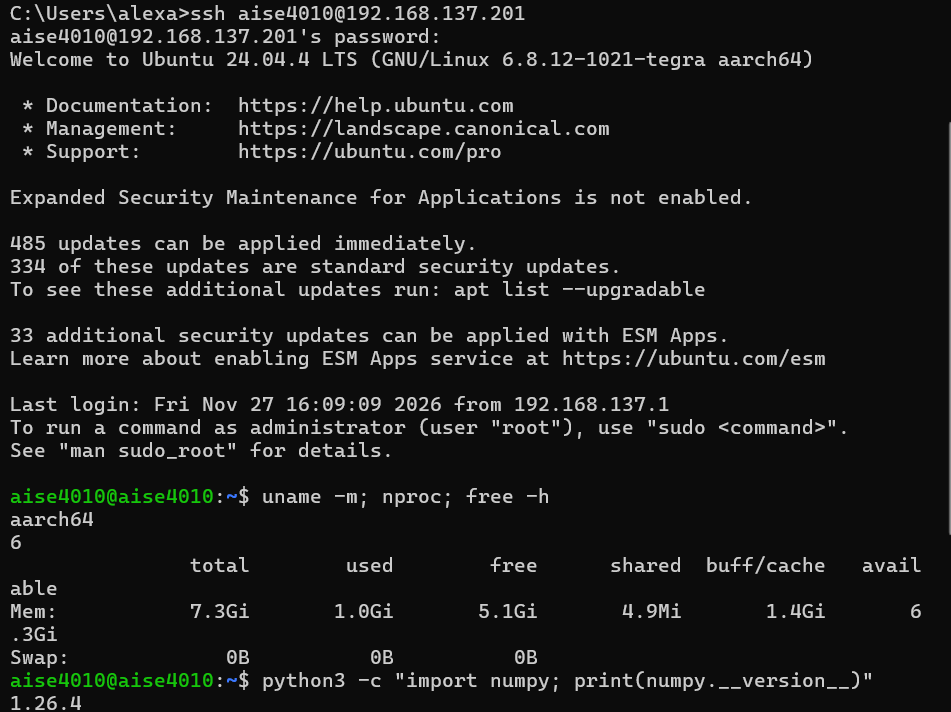

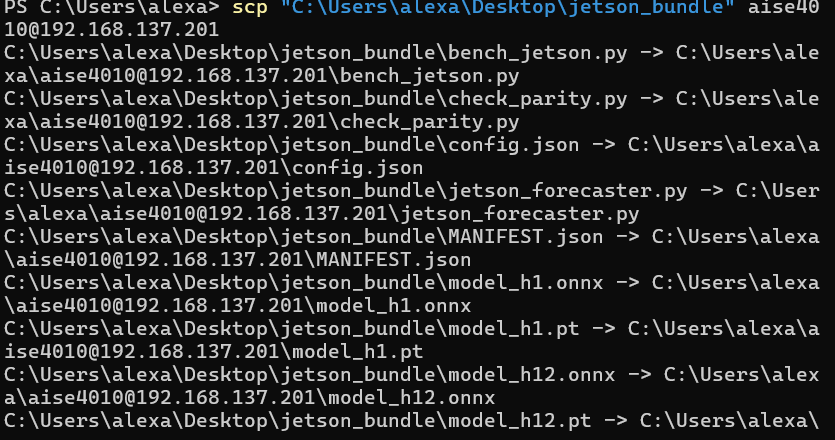

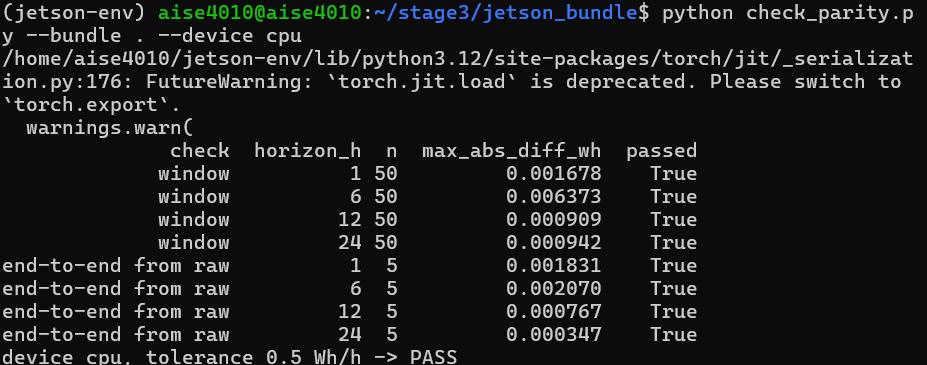

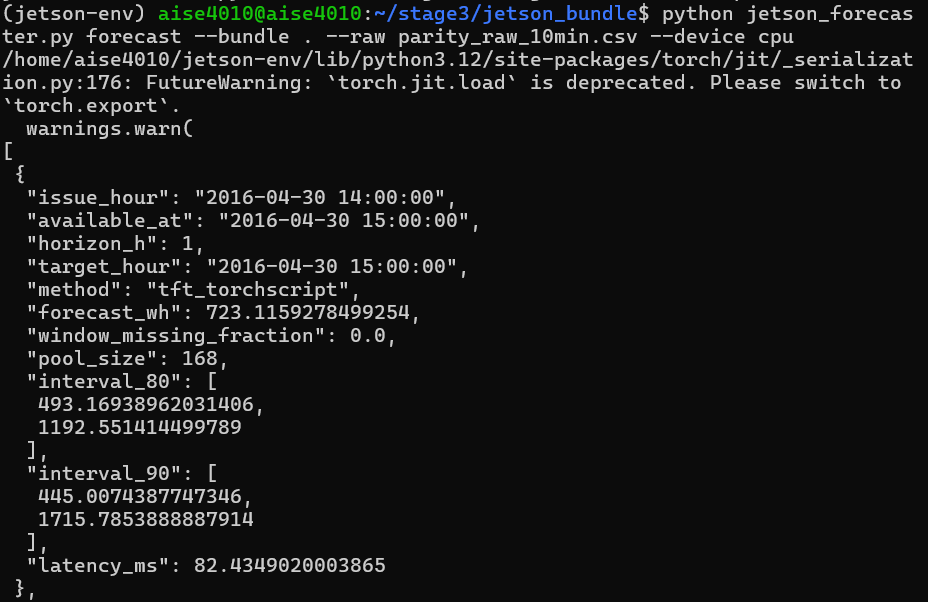

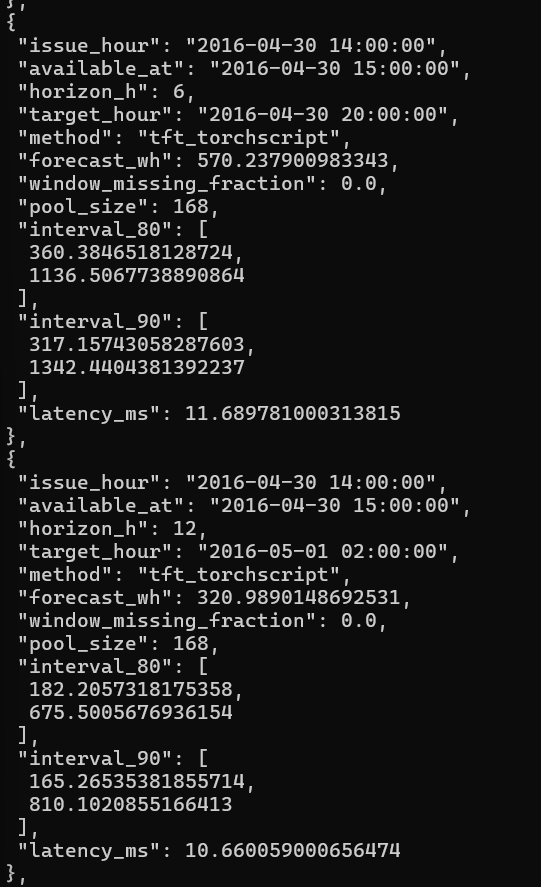

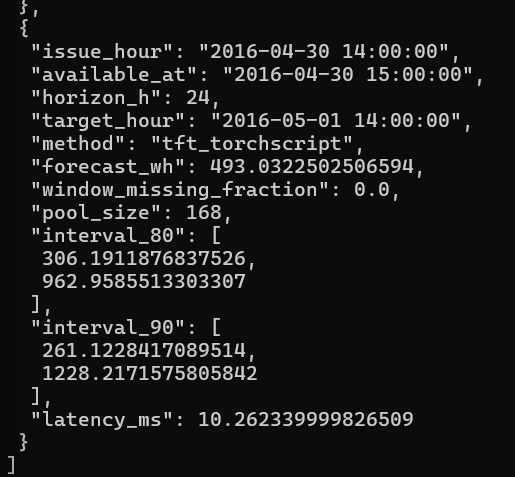